In [1]:
import pycaret
print(pycaret.__version__)

3.3.2


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

demand = pd.read_csv("historical_demand.csv")
bom = pd.read_csv("bom.csv")
production = pd.read_csv("production_master.csv")
warehouse = pd.read_csv("warehouse_master.csv")
raw_master = pd.read_csv("raw_material_master.csv")

for name, data in {
    "demand": demand,
    "bom": bom,
    "production": production,
    "warehouse": warehouse,
    "raw_master": raw_master
}.items():

    print("\n", "="*70)
    print(name)
    print("shape:", data.shape)
    print(data.columns.tolist())
    display(data.head())


demand
shape: (312, 5)
['week', 'week_label', 'product_id', 'product_name', 'weekly_demand_units']


,week,week_label,product_id,product_name,weekly_demand_units
0,1,W01,FG01,냉장고 Standard,158
1,2,W02,FG01,냉장고 Standard,158
2,3,W03,FG01,냉장고 Standard,161
3,4,W04,FG01,냉장고 Standard,173
4,5,W05,FG01,냉장고 Standard,163



bom
shape: (33, 5)
['product_id', 'product_name', 'material_id', 'material_name', 'qty_per_finished_product']


,product_id,product_name,material_id,material_name,qty_per_finished_product
0,FG01,냉장고 Standard,RM01,도장 강판 세트,1
1,FG01,냉장고 Standard,RM02,Main PCB,1
2,FG01,냉장고 Standard,RM04,Compressor,1
3,FG01,냉장고 Standard,RM08,Wiring Harness,1
4,FG02,냉장고 Premium,RM01,도장 강판 세트,1



production
shape: (6, 5)
['product_id', 'product_name', 'fixed_setup_cost_krw_per_run', 'unit_production_cost_krw', 'production_multiple_units']


,product_id,product_name,fixed_setup_cost_krw_per_run,unit_production_cost_krw,production_multiple_units
0,FG01,냉장고 Standard,800000,135000,10
1,FG02,냉장고 Premium,1000000,175000,10
2,FG03,세탁기 Standard,750000,115000,10
3,FG04,세탁기 Premium,950000,150000,10
4,FG05,에어컨 Standard,850000,125000,10



warehouse
shape: (6, 6)
['product_id', 'product_name', 'current_finished_goods_inventory_units', 'weekly_holding_cost_krw_per_unit', 'shortage_penalty_cost_krw_per_unit', 'current_safety_stock_units']


,product_id,product_name,current_finished_goods_inventory_units,weekly_holding_cost_krw_per_unit,shortage_penalty_cost_krw_per_unit,current_safety_stock_units
0,FG01,냉장고 Standard,190,3000,700000,55
1,FG02,냉장고 Premium,95,4000,850000,35
2,FG03,세탁기 Standard,175,3000,650000,50
3,FG04,세탁기 Premium,90,4000,800000,30
4,FG05,에어컨 Standard,115,3500,1000000,45



raw_master
shape: (9, 9)
['material_id', 'material_name', 'category', 'current_inventory_units', 'fixed_order_cost_krw_per_order', 'unit_purchase_cost_krw', 'weekly_holding_cost_krw_per_unit', 'order_multiple_units', 'replenishment_cycle_weeks']


,material_id,material_name,category,current_inventory_units,fixed_order_cost_krw_per_order,unit_purchase_cost_krw,weekly_holding_cost_krw_per_unit,order_multiple_units,replenishment_cycle_weeks
0,RM01,도장 강판 세트,외장/프레임,2050,180000,48000,350,50,1
1,RM02,Main PCB,전자제어,2020,220000,75000,550,20,1
2,RM03,BLDC Motor,구동,700,250000,110000,800,20,1
3,RM04,Compressor,냉동/공조,1310,300000,210000,1500,10,1
4,RM05,Heat Exchanger,냉동/공조,480,260000,135000,950,10,1


In [4]:
# ============================================================
# demand EDA
# ============================================================

print("상품 수:", demand["product_id"].nunique())

print("\n상품별 데이터 수")
display(
    demand.groupby(
        ["product_id", "product_name"]
    ).size()
)


print("\n결측치")
display(
    demand.isnull().sum()
)


print("\n중복행")
print(
    demand.duplicated().sum()
)


print("\n상품-주차 중복")
display(
    demand[
        demand.duplicated(
            subset=[
                "product_id",
                "week"
            ],
            keep=False
        )
    ]
)


print("\n수요 통계")
display(
    demand[
        "weekly_demand_units"
    ].describe()
)


print("\n음수 수요")
display(
    demand[
        demand[
            "weekly_demand_units"
        ] < 0
    ]
)


# 상품별 주차 확인
week_check = (
    demand
    .groupby("product_id")["week"]
    .agg(
        최소="min",
        최대="max",
        개수="count",
        고유주차="nunique"
    )
)

display(week_check)

상품 수: 6

상품별 데이터 수


product_id  product_name
FG01        냉장고 Standard    52
FG02        냉장고 Premium     52
FG03        세탁기 Standard    52
FG04        세탁기 Premium     52
FG05        에어컨 Standard    52
FG06        에어컨 Premium     52
dtype: int64


결측치


week                   0
week_label             0
product_id             0
product_name           0
weekly_demand_units    0
dtype: int64


중복행
0

상품-주차 중복


...


수요 통계


count    312.000000
mean     111.147436
std       40.916165
min       32.000000
25%       83.000000
50%      103.500000
75%      149.000000
max      198.000000
Name: weekly_demand_units, dtype: float64


음수 수요


,week,week_label,product_id,product_name,weekly_demand_units


,최소,최대,개수,고유주차
product_id,,,,
FG01,1,52,52,52
FG02,1,52,52,52
FG03,1,52,52,52
FG04,1,52,52,52
FG05,1,52,52,52
FG06,1,52,52,52


In [5]:
# ============================================================
# STEP 1. 상품별 기본 통계
# ============================================================

product_stats = (
    demand
    .groupby(
        [
            "product_id",
            "product_name"
        ]
    )["weekly_demand_units"]
    .agg(
        평균="mean",
        표준편차="std",
        최소="min",
        최대="max"
    )
    .reset_index()
)

product_stats["CV"] = (
    product_stats["표준편차"]
    / product_stats["평균"]
)

display(
    product_stats.round(2)
)

,product_id,product_name,평균,표준편차,최소,최대,CV
0,FG01,냉장고 Standard,170.52,12.59,136,198,0.07
1,FG02,냉장고 Premium,106.15,10.41,84,133,0.10
2,FG03,세탁기 Standard,143.90,13.80,115,175,0.10
3,FG04,세탁기 Premium,88.65,7.32,70,104,0.08
4,FG05,에어컨 Standard,98.12,32.86,56,168,0.33
5,FG06,에어컨 Premium,59.54,22.35,32,107,0.38


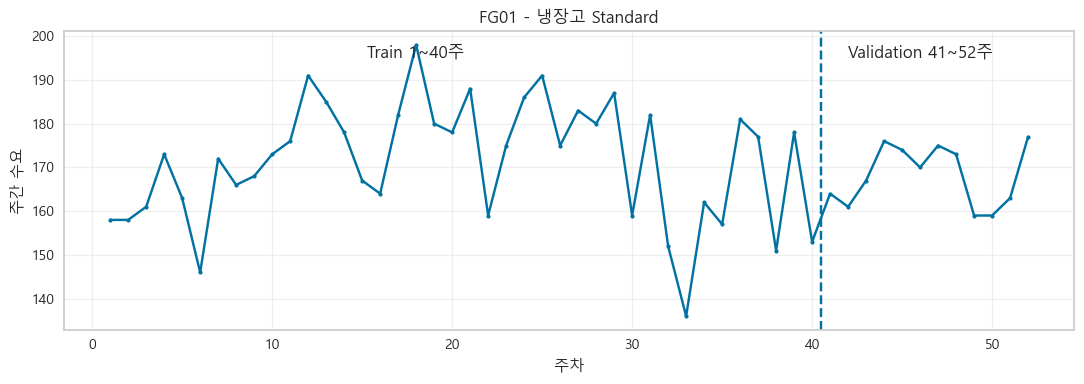

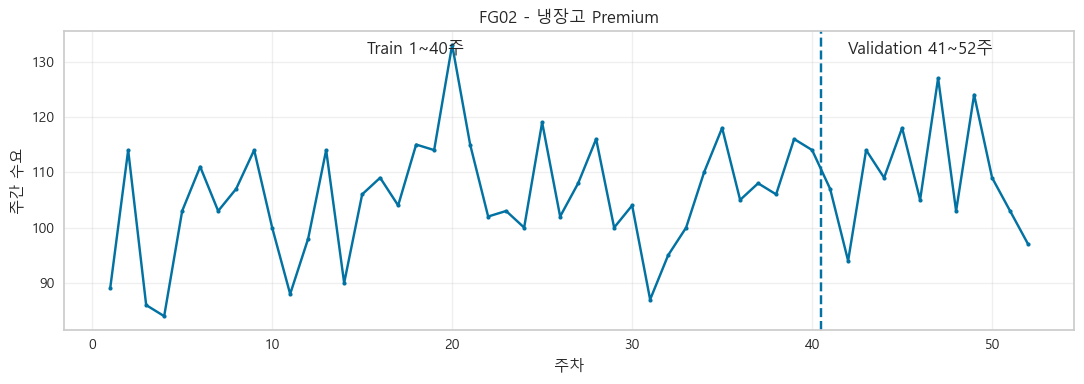

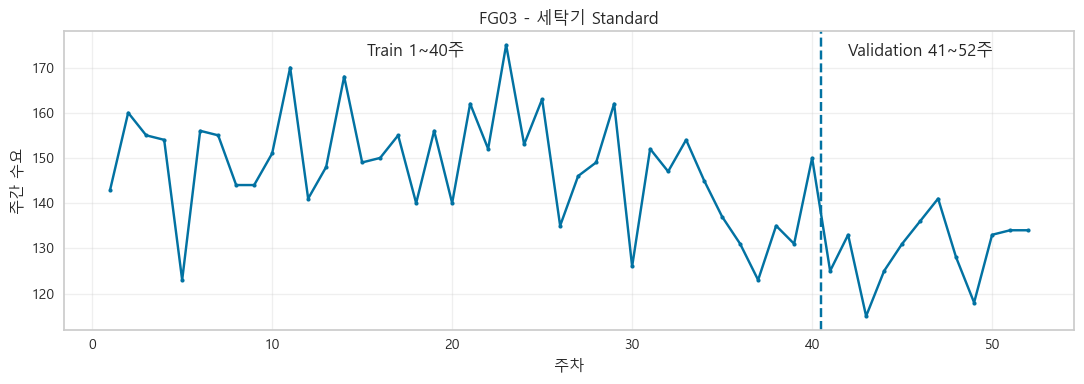

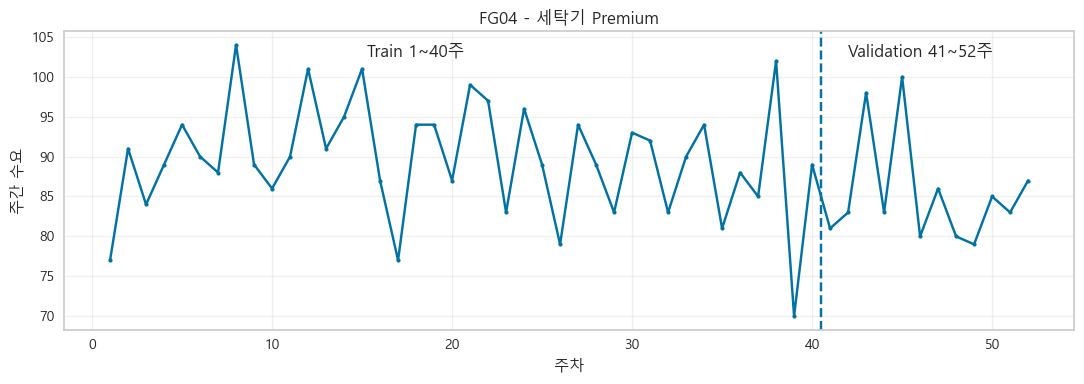

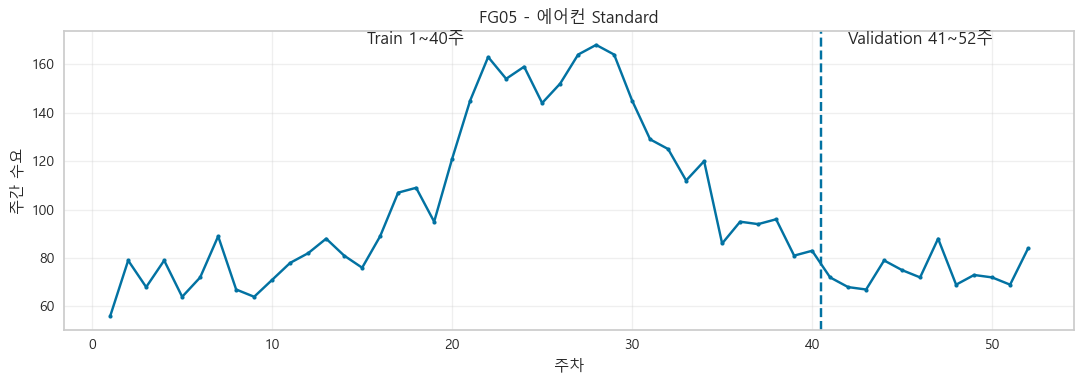

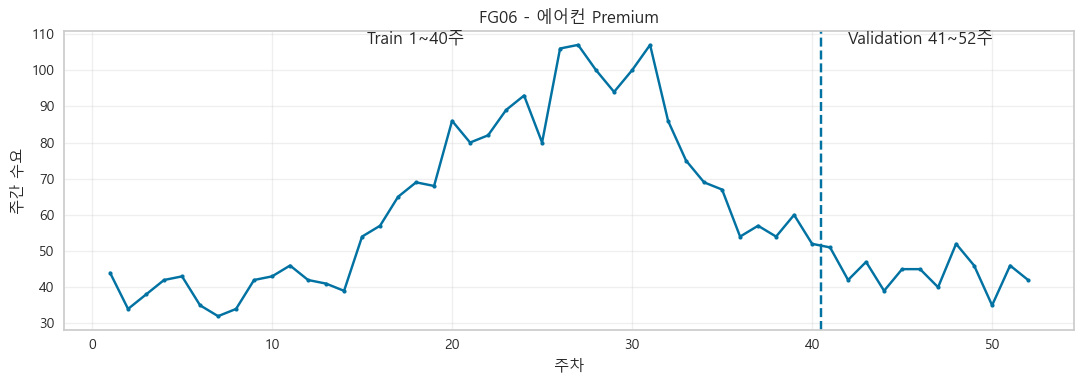

In [6]:
# ============================================================
# STEP 2. 상품별 수요 시계열
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


for product_id in demand["product_id"].unique():

    temp = (
        demand[
            demand["product_id"]
            == product_id
        ]
        .sort_values("week")
    )

    product_name = (
        temp["product_name"]
        .iloc[0]
    )

    plt.figure(
        figsize=(11, 4)
    )

    plt.plot(
        temp["week"],
        temp["weekly_demand_units"],
        marker="o",
        markersize=3
    )

    # 학습 / 검증 구분
    plt.axvline(
        x=40.5,
        linestyle="--"
    )

    plt.text(
        18,
        plt.ylim()[1] * 0.97,
        "Train 1~40주",
        ha="center"
    )

    plt.text(
        46,
        plt.ylim()[1] * 0.97,
        "Validation 41~52주",
        ha="center"
    )

    plt.title(
        f"{product_id} - {product_name}"
    )

    plt.xlabel("주차")
    plt.ylabel("주간 수요")

    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.show()



FG01 - 냉장고 Standard


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
et,Extra Trees Regressor,9.1967,127.0063,11.0925,-0.7851,0.0619,0.0505,0.0933
knn,K Neighbors Regressor,9.5778,151.6311,11.7104,-0.8410,0.0656,0.0524,0.0833
lr,Linear Regression,10.1076,151.4352,12.0366,-1.0364,0.0671,0.0565,1.5767
lasso,Lasso Regression,10.1700,146.1162,11.8634,-1.0070,0.0662,0.0565,2.0967
ridge,Ridge Regression,10.1161,150.3009,11.9960,-1.0244,0.0669,0.0565,2.0900
en,Elastic Net,10.1672,146.4075,11.8658,-0.9989,0.0662,0.0565,1.7800
lar,Least Angle Regression,10.1076,151.4352,12.0366,-1.0364,0.0671,0.0565,1.2000
llar,Lasso Least Angle Regression,10.1700,146.1168,11.8634,-1.0070,0.0662,0.0565,0.0167
huber,Huber Regressor,10.4781,181.6044,12.8337,-1.2470,0.0710,0.0591,0.0467
br,Bayesian Ridge,11.1726,179.8823,13.2748,-1.7013,0.0739,0.0606,0.0300


PyCaret 최적모델: PyCaret - ExtraTreesRegressor


FG02 - 냉장고 Premium


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
br,Bayesian Ridge,7.9674,110.4794,9.9930,-0.3487,0.0905,0.0711,0.0200
dummy,Dummy Regressor,7.9634,107.9893,9.9084,-0.3252,0.0897,0.0712,0.0167
knn,K Neighbors Regressor,8.3889,124.8733,10.7344,-0.5586,0.0978,0.0758,0.0667
omp,Orthogonal Matching Pursuit,9.5321,144.1141,11.1733,-0.7046,0.1025,0.0858,0.0200
lasso,Lasso Regression,9.9295,158.9391,12.0544,-0.9616,0.1111,0.0899,0.0167
llar,Lasso Least Angle Regression,9.9295,158.9381,12.0543,-0.9616,0.1111,0.0899,0.0233
en,Elastic Net,9.9884,160.7097,12.1234,-0.9841,0.1118,0.0904,0.0200
lr,Linear Regression,10.1121,163.8703,12.2500,-1.0257,0.1131,0.0916,0.0200
ridge,Ridge Regression,10.1066,163.7598,12.2447,-1.0240,0.1130,0.0916,0.0167
lar,Least Angle Regression,10.1121,163.8704,12.2500,-1.0257,0.1131,0.0916,0.0167


PyCaret 최적모델: PyCaret - BayesianRidge


FG03 - 세탁기 Standard


...

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
omp,Orthogonal Matching Pursuit,7.7617,104.2777,9.9567,-0.2878,0.1360,0.1017,0.0100
br,Bayesian Ridge,8.6831,128.0934,11.0260,-0.5351,0.1600,0.1200,0.0100
lasso,Lasso Regression,9.9697,147.7005,12.0500,-0.8187,0.1728,0.1370,0.0100
llar,Lasso Least Angle Regression,9.9714,147.7135,12.0506,-0.8188,0.1728,0.1370,0.0100
huber,Huber Regressor,10.0796,156.7501,12.2911,-0.8939,0.1848,0.1405,0.0067
en,Elastic Net,10.3016,155.5877,12.3841,-0.9212,0.1785,0.1425,0.0100
par,Passive Aggressive Regressor,10.9807,167.2152,12.9052,-1.1024,0.1921,0.1540,0.0133
ridge,Ridge Regression,11.8038,195.7458,13.9341,-1.4608,0.2039,0.1664,0.0133
gbr,Gradient Boosting Regressor,12.7744,232.1363,15.2103,-2.0123,0.2263,0.1675,0.0167
lr,Linear Regression,12.1166,205.3710,14.2514,-1.5775,0.2108,0.1720,0.0167


PyCaret 최적모델: PyCaret - OrthogonalMatchingPursuit


모든 모델 성능


,product_id,product_name,model,MAE,RMSE,MAPE
3,FG01,냉장고 Standard,지수평활 α=0.1,6.00,6.54,3.57
0,FG01,냉장고 Standard,장기 평균,6.20,7.21,3.77
4,FG01,냉장고 Standard,지수평활 α=0.3,6.66,8.02,3.88
2,FG01,냉장고 Standard,4주 이동평균,6.91,8.74,4.00
1,FG01,냉장고 Standard,13주 이동평균,7.09,8.20,4.15
5,FG01,냉장고 Standard,PyCaret - ExtraTreesRegressor,8.00,9.96,4.82
9,FG02,냉장고 Premium,지수평활 α=0.1,7.67,9.81,6.89
11,FG02,냉장고 Premium,PyCaret - BayesianRidge,7.73,9.98,6.90
6,FG02,냉장고 Premium,장기 평균,7.96,10.41,7.03
7,FG02,냉장고 Premium,13주 이동평균,7.92,9.61,7.14




상품별 최적 모델


,product_id,product_name,model,MAE,RMSE,MAPE
0,FG01,냉장고 Standard,지수평활 α=0.1,6.00,6.54,3.57
1,FG02,냉장고 Premium,지수평활 α=0.1,7.67,9.81,6.89
2,FG03,세탁기 Standard,4주 이동평균,9.22,11.40,7.44
3,FG04,세탁기 Premium,지수평활 α=0.3,5.17,6.57,5.90
4,FG05,에어컨 Standard,4주 이동평균,12.65,13.86,17.81
5,FG06,에어컨 Premium,4주 이동평균,11.19,12.08,26.77


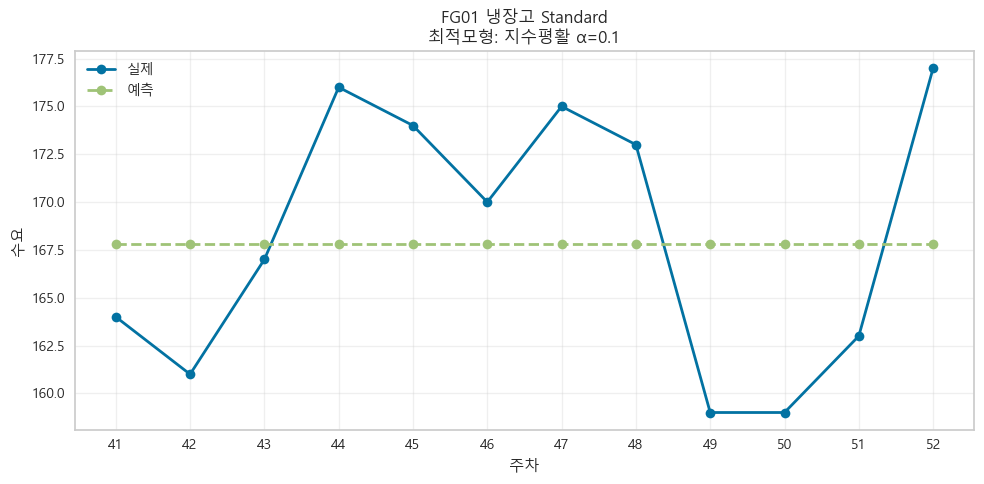

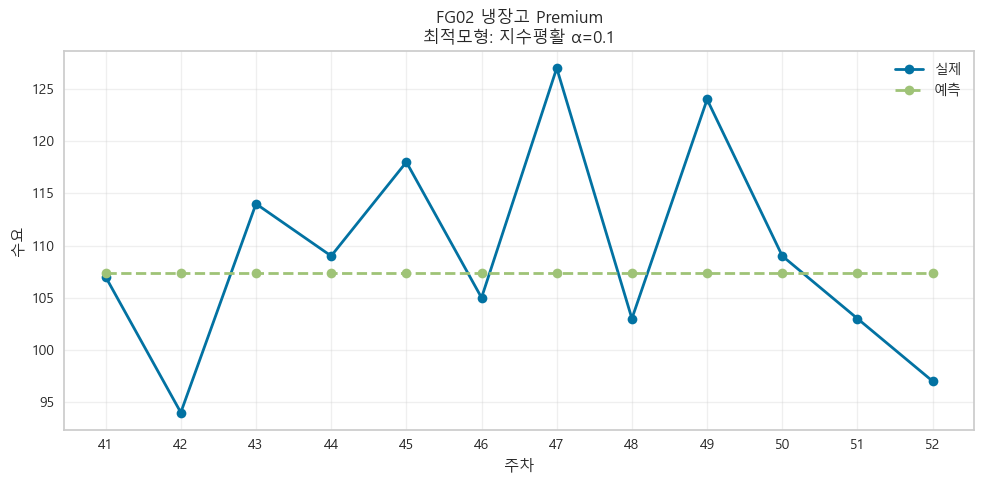

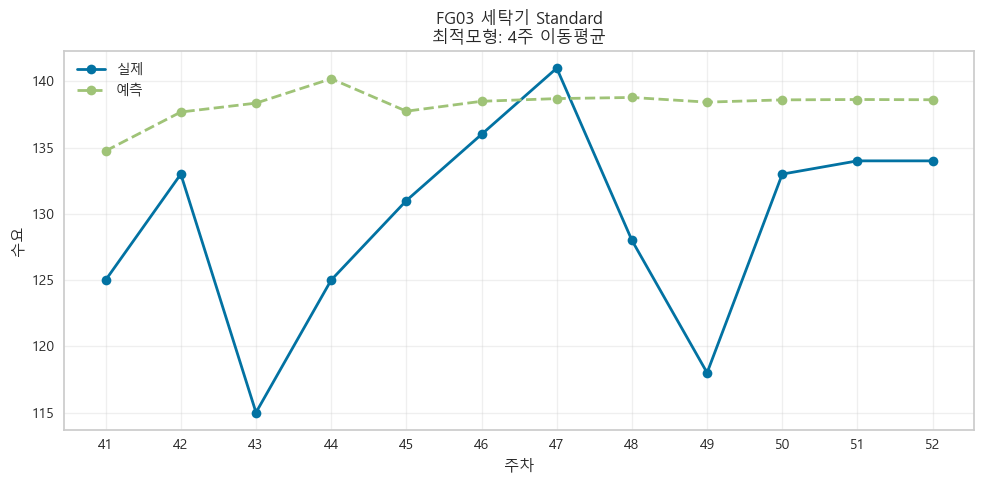

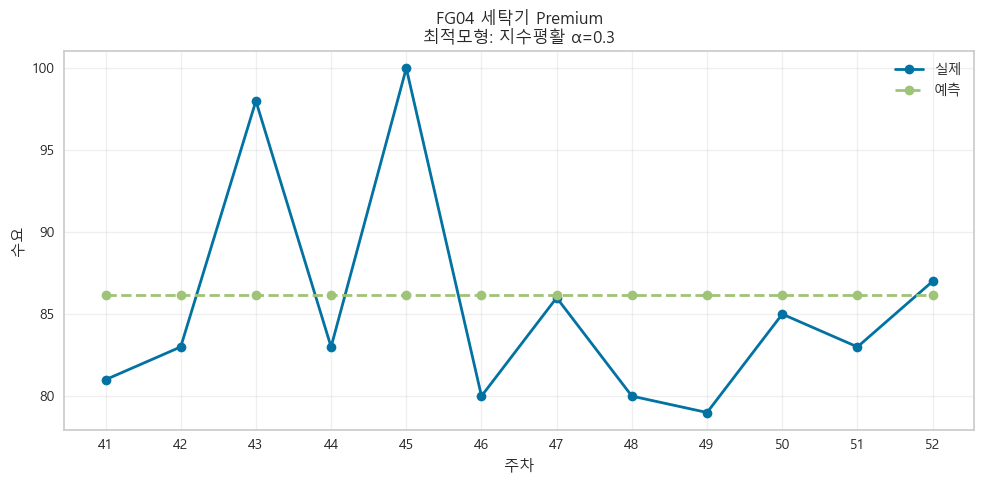

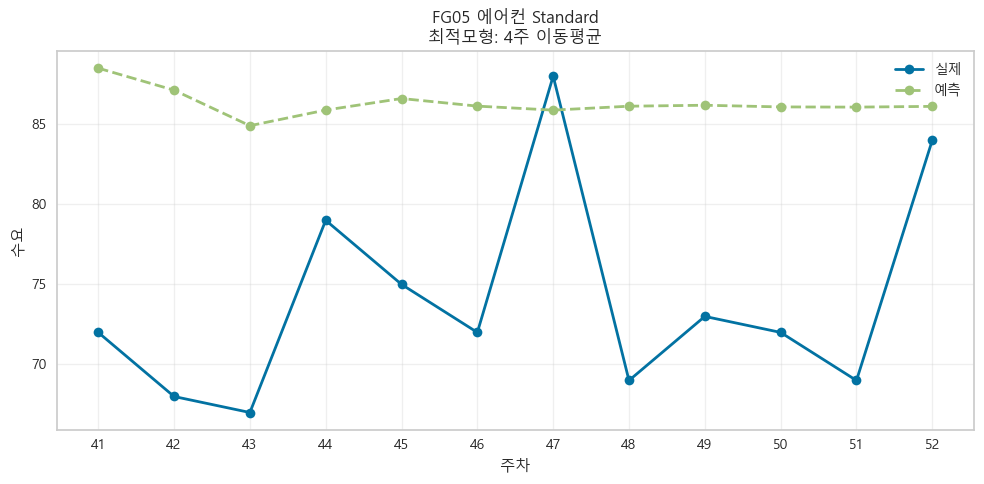

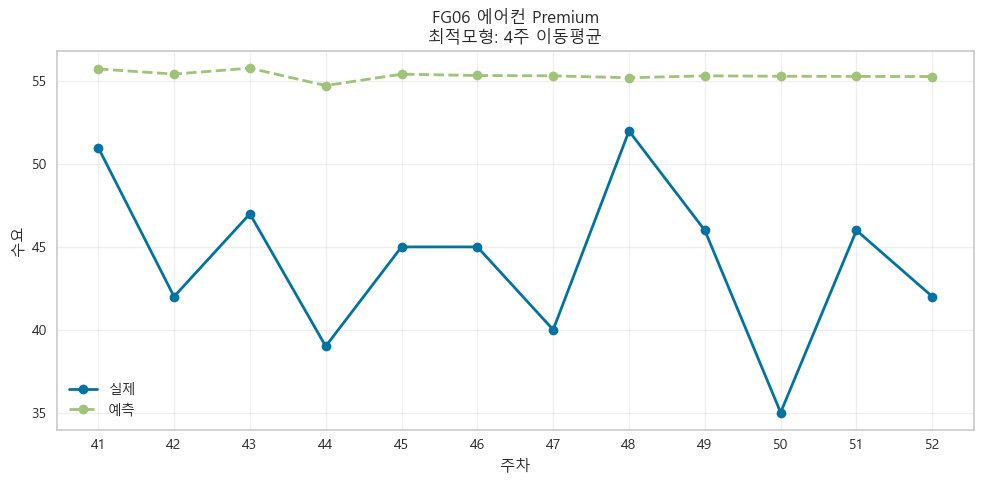



상품별 MAPE 비교


model,product_id,product_name,13주 이동평균,4주 이동평균,PyCaret - BayesianRidge,PyCaret - DummyRegressor,PyCaret - ExtraTreesRegressor,PyCaret - OrthogonalMatchingPursuit,장기 평균,지수평활 α=0.1,지수평활 α=0.3
0,FG01,냉장고 Standard,4.15,4.00,NaN,NaN,4.82,NaN,3.77,3.57,3.88
1,FG02,냉장고 Premium,7.14,8.05,6.90,NaN,NaN,NaN,7.03,6.89,7.67
2,FG03,세탁기 Standard,8.32,7.44,NaN,14.51,NaN,NaN,14.92,10.74,7.83
3,FG04,세탁기 Premium,6.68,6.12,9.48,NaN,NaN,NaN,8.64,7.13,5.90
4,FG05,에어컨 Standard,40.33,17.81,NaN,NaN,NaN,27.96,43.31,49.00,25.11
5,FG06,에어컨 Premium,53.60,26.77,NaN,NaN,NaN,36.07,46.94,59.96,35.33


In [8]:
# ============================================================
# 0. 라이브러리
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from pycaret.regression import RegressionExperiment


# ============================================================
# 1. 한글 폰트
# ============================================================

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 2. 데이터
# ============================================================

demand = pd.read_csv(
    "historical_demand.csv"
)

demand = (
    demand
    .sort_values(
        [
            "product_id",
            "week"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# 3. MAPE
# ============================================================

def calc_mape(
    actual,
    pred
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    pred = np.asarray(
        pred,
        dtype=float
    )

    mask = actual != 0

    return (
        np.mean(
            np.abs(
                (
                    actual[mask]
                    - pred[mask]
                )
                / actual[mask]
            )
        )
        * 100
    )


# ============================================================
# 4. 성능 평가
# ============================================================

def evaluate_model(
    actual,
    pred
):

    mae = mean_absolute_error(
        actual,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            pred
        )
    )

    mape = calc_mape(
        actual,
        pred
    )

    return (
        mae,
        rmse,
        mape
    )


# ============================================================
# 5. 기본모형
# ============================================================

# ------------------------------------------------------------
# 5-1. 장기 평균
# ------------------------------------------------------------

def forecast_long_mean(
    train,
    horizon
):

    mean_value = np.mean(
        train
    )

    return np.repeat(
        mean_value,
        horizon
    )


# ------------------------------------------------------------
# 5-2. 이동평균
# 재귀 예측
# ------------------------------------------------------------

def forecast_moving_average(
    train,
    window,
    horizon
):

    history = list(
        train
    )

    predictions = []

    for _ in range(
        horizon
    ):

        pred = np.mean(
            history[
                -window:
            ]
        )

        predictions.append(
            pred
        )

        # 미래 실제값 대신 예측값 추가
        history.append(
            pred
        )

    return np.array(
        predictions
    )


# ------------------------------------------------------------
# 5-3. 단순 지수평활
# ------------------------------------------------------------

def forecast_exp_smoothing(
    train,
    alpha,
    horizon
):

    level = float(
        train[0]
    )

    for value in train[1:]:

        level = (
            alpha
            * value
            +
            (1 - alpha)
            * level
        )

    return np.repeat(
        level,
        horizon
    )


# ============================================================
# 6. PyCaret용 Feature 생성
# ============================================================

def make_features(data):

    data = (
        data
        .sort_values("week")
        .reset_index(drop=True)
        .copy()
    )

    # 1주 전 수요
    data["lag1"] = (
        data[
            "weekly_demand_units"
        ]
        .shift
    )

    # 2주 전 수요
    data["lag2"] = (
        data[
            "weekly_demand_units"
        ]
        .shift(2)
    )

    # 직전 4주 평균
    data["rolling4"] = (
        data[
            "weekly_demand_units"
        ]
        .shift
        .rolling(4)
        .mean()
    )

    return data


FEATURE_COLS = [
    "lag1",
    "lag2",
    "rolling4"
]


# ============================================================
# 7. PyCaret 41~52주 재귀예측
# ============================================================

def pycaret_recursive_predict(
    exp,
    model,
    train_raw,
    test_weeks
):

    history = (
        train_raw[
            [
                "week",
                "weekly_demand_units"
            ]
        ]
        .copy()
        .reset_index(drop=True)
    )

    predictions = []


    for week in test_weeks:

        y = history[
            "weekly_demand_units"
        ]


        X_next = pd.DataFrame({

            "lag1": [
                y.iloc[-1]
            ],

            "lag2": [
                y.iloc[-2]
            ],

            "rolling4": [
                y.iloc[-4:].mean()
            ]
        })


        pred_df = exp.predict_model(
            model,
            data=X_next,
            verbose=False
        )


        pred = float(
            pred_df[
                "prediction_label"
            ]
            .iloc[0]
        )


        pred = max(
            pred,
            0
        )


        predictions.append(
            pred
        )


        # 예측값을 다음 주 입력에 사용
        history = pd.concat(

            [
                history,

                pd.DataFrame({

                    "week": [
                        week
                    ],

                    "weekly_demand_units": [
                        pred
                    ]
                })
            ],

            ignore_index=True
        )


    return np.array(
        predictions
    )


# ============================================================
# 8. 전체 상품 반복
# ============================================================

all_results = []

prediction_store = {}

pycaret_best_models = {}


for product_id in demand[
    "product_id"
].unique():

    print("\n")
    print("=" * 100)

    product_df = (
        demand[
            demand[
                "product_id"
            ]
            == product_id
        ]
        .sort_values(
            "week"
        )
        .reset_index(
            drop=True
        )
        .copy()
    )


    product_name = (
        product_df[
            "product_name"
        ]
        .iloc[0]
    )


    print(
        product_id,
        "-",
        product_name
    )


    # ========================================================
    # Train / Validation
    # ========================================================

    train_raw = (
        product_df[
            product_df[
                "week"
            ] <= 40
        ]
        .copy()
    )


    valid_raw = (
        product_df[
            (
                product_df[
                    "week"
                ] >= 41
            )
            &
            (
                product_df[
                    "week"
                ] <= 52
            )
        ]
        .copy()
    )


    train_values = (
        train_raw[
            "weekly_demand_units"
        ]
        .to_numpy(
            dtype=float
        )
    )


    actual = (
        valid_raw[
            "weekly_demand_units"
        ]
        .to_numpy(
            dtype=float
        )
    )


    test_weeks = (
        valid_raw[
            "week"
        ]
        .to_numpy()
    )


    horizon = len(
        valid_raw
    )


    # ========================================================
    # 기본모형 예측
    # ========================================================

    predictions = {}


    predictions[
        "장기 평균"
    ] = forecast_long_mean(
        train_values,
        horizon
    )


    predictions[
        "13주 이동평균"
    ] = forecast_moving_average(
        train_values,
        13,
        horizon
    )


    predictions[
        "4주 이동평균"
    ] = forecast_moving_average(
        train_values,
        4,
        horizon
    )


    predictions[
        "지수평활 α=0.1"
    ] = forecast_exp_smoothing(
        train_values,
        0.1,
        horizon
    )


    predictions[
        "지수평활 α=0.3"
    ] = forecast_exp_smoothing(
        train_values,
        0.3,
        horizon
    )


    # ========================================================
    # PyCaret 학습 데이터
    # ========================================================

    train_feature = (
        make_features(
            train_raw
        )
        .dropna()
        .copy()
    )


    pycaret_train = (
        train_feature[
            FEATURE_COLS
            +
            [
                "weekly_demand_units"
            ]
        ]
        .copy()
    )


    # ========================================================
    # PyCaret
    # ========================================================

    exp = RegressionExperiment()


    exp.setup(

        data=
            pycaret_train,

        target=
            "weekly_demand_units",

        fold_strategy=
            "timeseries",

        fold=
            3,

        data_split_shuffle=
            False,

        fold_shuffle=
            False,

        session_id=
            42,

        verbose=
            False,

        n_jobs=
            -1
    )


    # 여러 모델 비교
    best_model = exp.compare_models(

        sort=
            "MAPE",

        turbo=
            True,

        n_select=
            1
    )


    # 전체 train feature로 재학습
    final_model = exp.finalize_model(
        best_model
    )


    pycaret_model_name = (
        "PyCaret - "
        +
        type(
            best_model
        ).__name__
    )


    print(
        "PyCaret 최적모델:",
        pycaret_model_name
    )


    pycaret_best_models[
        product_id
    ] = {

        "exp":
            exp,

        "model":
            final_model,

        "name":
            pycaret_model_name
    }


    # 41~52주 재귀예측
    pycaret_pred = (
        pycaret_recursive_predict(

            exp=
                exp,

            model=
                final_model,

            train_raw=
                train_raw,

            test_weeks=
                test_weeks
        )
    )


    predictions[
        pycaret_model_name
    ] = pycaret_pred


    # ========================================================
    # 모델별 성능 평가
    # ========================================================

    prediction_store[
        product_id
    ] = {

        "weeks":
            test_weeks,

        "actual":
            actual,

        "predictions":
            predictions
    }


    for model_name, pred in predictions.items():

        mae, rmse, mape = (
            evaluate_model(
                actual,
                pred
            )
        )


        all_results.append({

            "product_id":
                product_id,

            "product_name":
                product_name,

            "model":
                model_name,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "MAPE":
                mape
        })


# ============================================================
# 9. 전체 결과
# ============================================================

result_df = pd.DataFrame(
    all_results
)


print("\n")
print("=" * 100)
print("모든 모델 성능")
print("=" * 100)

display(

    result_df
    .sort_values(
        [
            "product_id",
            "MAPE"
        ]
    )
    .round(2)
)


# ============================================================
# 10. 상품별 최적모델
# ============================================================

best_model_table = (

    result_df

    .sort_values(
        [
            "product_id",
            "MAPE"
        ]
    )

    .groupby(
        [
            "product_id",
            "product_name"
        ],
        as_index=False
    )

    .first()
)


print("\n")
print("=" * 100)
print("상품별 최적 모델")
print("=" * 100)

display(

    best_model_table[
        [
            "product_id",
            "product_name",
            "model",
            "MAE",
            "RMSE",
            "MAPE"
        ]
    ]

    .round(2)
)


# ============================================================
# 11. 각 상품 실제 vs 최적모델 예측 시각화
# ============================================================

for _, best_row in best_model_table.iterrows():

    product_id = (
        best_row[
            "product_id"
        ]
    )

    product_name = (
        best_row[
            "product_name"
        ]
    )

    best_model_name = (
        best_row[
            "model"
        ]
    )


    info = (
        prediction_store[
            product_id
        ]
    )


    weeks = info[
        "weeks"
    ]

    actual = info[
        "actual"
    ]

    pred = info[
        "predictions"
    ][
        best_model_name
    ]


    plt.figure(
        figsize=(10, 5)
    )


    plt.plot(

        weeks,

        actual,

        marker="o",

        linewidth=2,

        label="실제"
    )


    plt.plot(

        weeks,

        pred,

        marker="o",

        linestyle="--",

        linewidth=2,

        label="예측"
    )


    plt.title(
        f"{product_id} {product_name}\n"
        f"최적모형: {best_model_name}"
    )


    plt.xlabel(
        "주차"
    )

    plt.ylabel(
        "수요"
    )


    plt.xticks(
        range(
            41,
            53
        )
    )


    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 12. 상품별 모델 MAPE 비교표
# ============================================================

mape_pivot = (

    result_df

    .pivot_table(

        index=[
            "product_id",
            "product_name"
        ],

        columns=
            "model",

        values=
            "MAPE"
    )

    .reset_index()
)


print("\n")
print("=" * 100)
print("상품별 MAPE 비교")
print("=" * 100)

display(
    mape_pivot.round(2)
)

In [7]:
# ============================================================
# 완제품 독립 변동성 합산 + 변동성 2배 반영
# 네 현재 변수명 기준 수정본
# ============================================================

import numpy as np
import pandas as pd


# 변동성 2배 반영
VARIABILITY_FACTOR = 2.0


# ============================================================
# 1. BOM + 완제품 평균/표준편차 결합
#
# fg_demand_stats 컬럼:
# product_id
# forecast_mu
# sigma_error
# ============================================================

bom_var = pd.merge(

    bom,

    fg_demand_stats[
        [
            "product_id",
            "forecast_mu",
            "sigma_error"
        ]
    ],

    on="product_id",

    how="left"
)


# ============================================================
# 2. 원자재 평균소요 기여분
#
# μ_RM
# = Σ(BOM × 제품 평균수요)
# ============================================================

bom_var["mu_component"] = (

    bom_var[
        "qty_per_finished_product"
    ]

    *

    bom_var[
        "forecast_mu"
    ]
)


# ============================================================
# 3. 제품별 변동성 기여분
#
# 독립 가정
#
# variance contribution
# = (BOM × sigma)^2
# ============================================================

bom_var["variance_component"] = (

    bom_var[
        "qty_per_finished_product"
    ]

    *

    bom_var[
        "sigma_error"
    ]

) ** 2


# ============================================================
# 4. 원자재별 합산
# ============================================================

rm_stats = (

    bom_var

    .groupby(
        [
            "material_id",
            "material_name"
        ],
        as_index=False
    )

    .agg(

        forecast_mu=(
            "mu_component",
            "sum"
        ),

        variance_sum=(
            "variance_component",
            "sum"
        )
    )
)


# ============================================================
# 5. 독립 완제품 변동성 합산
#
# sigma
# = sqrt(sum(variance))
# ============================================================

rm_stats["sigma_original"] = np.sqrt(

    rm_stats[
        "variance_sum"
    ]
)


# ============================================================
# 6. 변동성 2배 반영
# ============================================================

rm_stats["sigma_adjusted"] = (

    VARIABILITY_FACTOR

    *

    rm_stats[
        "sigma_original"
    ]
)


# ============================================================
# 7. 결과 출력
# ============================================================

result = rm_stats[
    [
        "material_id",
        "material_name",
        "forecast_mu",
        "sigma_original",
        "sigma_adjusted"
    ]
].copy()


print("=" * 100)
print("원자재 평균소요 및 변동성 2배 반영")
print("=" * 100)

display(
    result.round(2)
)

원자재 평균소요 및 변동성 2배 반영


,material_id,material_name,forecast_mu,sigma_original,sigma_adjusted
0,RM01,도장 강판 세트,600.05,21.01,42.02
1,RM02,Main PCB,600.05,21.01,42.02
2,RM03,BLDC Motor,219.65,10.55,21.10
3,RM04,Compressor,380.40,18.17,36.34
4,RM05,Heat Exchanger,104.48,13.58,27.15
5,RM06,Drum Assembly,219.65,10.55,21.10
6,RM07,Display Module,223.05,14.67,29.33
7,RM08,Wiring Harness,600.05,21.01,42.02
8,RM09,Fan Motor,136.91,19.08,38.15


EDA
수요 데이터 shape: (312, 5)
완제품 수: 6

상품별 데이터 수


product_id  product_name
FG01        냉장고 Standard    52
FG02        냉장고 Premium     52
FG03        세탁기 Standard    52
FG04        세탁기 Premium     52
FG05        에어컨 Standard    52
FG06        에어컨 Premium     52
dtype: int64


결측치


week                   0
week_label             0
product_id             0
product_name           0
weekly_demand_units    0
dtype: int64


중복행: 0

제품별 주차


,최소,최대,개수,고유주차
product_id,,,,
FG01,1,52,52,52
FG02,1,52,52,52
FG03,1,52,52,52
FG04,1,52,52,52
FG05,1,52,52,52
FG06,1,52,52,52




제품별 수요 특성


,product_id,product_name,평균,표준편차,최소,최대,CV
0,FG01,냉장고 Standard,170.519,12.594,136,198,0.074
1,FG02,냉장고 Premium,106.154,10.412,84,133,0.098
2,FG03,세탁기 Standard,143.904,13.801,115,175,0.096
3,FG04,세탁기 Premium,88.654,7.319,70,104,0.083
4,FG05,에어컨 Standard,98.115,32.863,56,168,0.335
5,FG06,에어컨 Premium,59.538,22.351,32,107,0.375


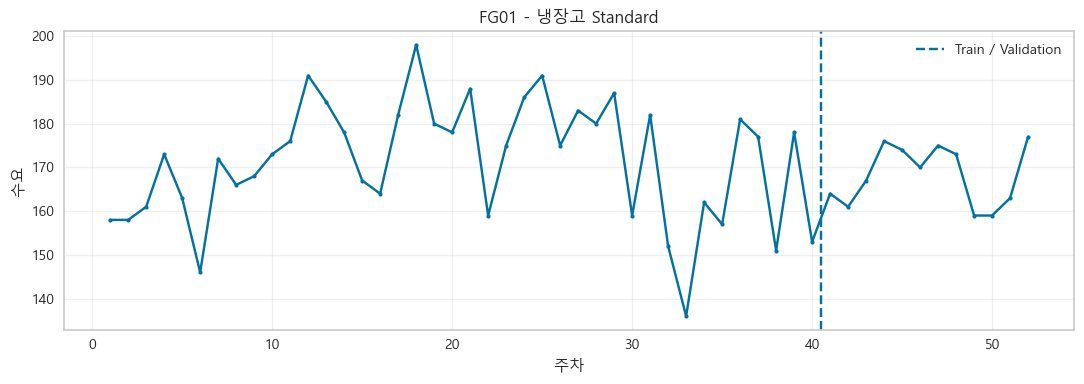

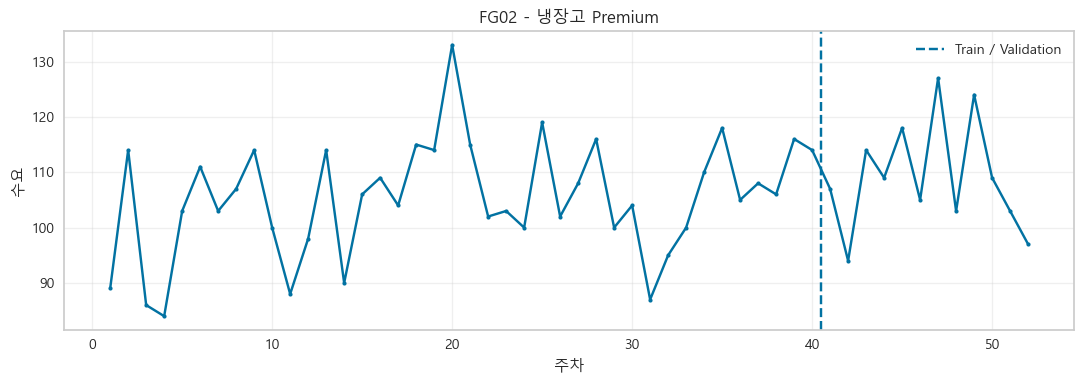

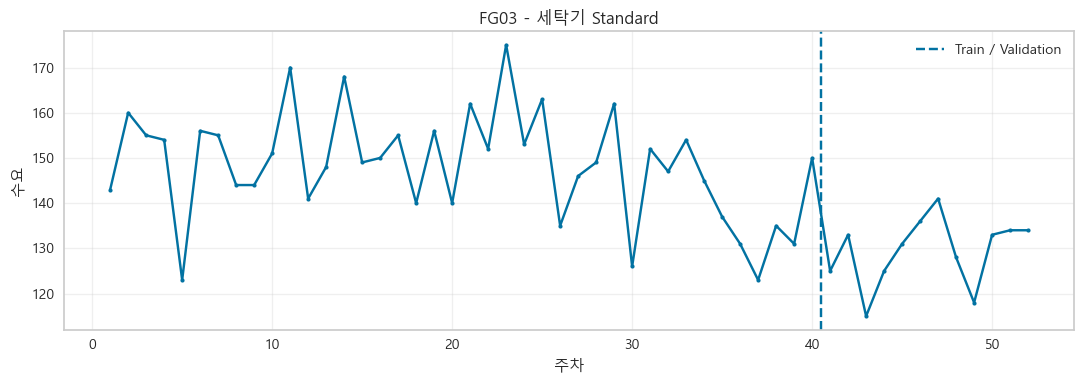

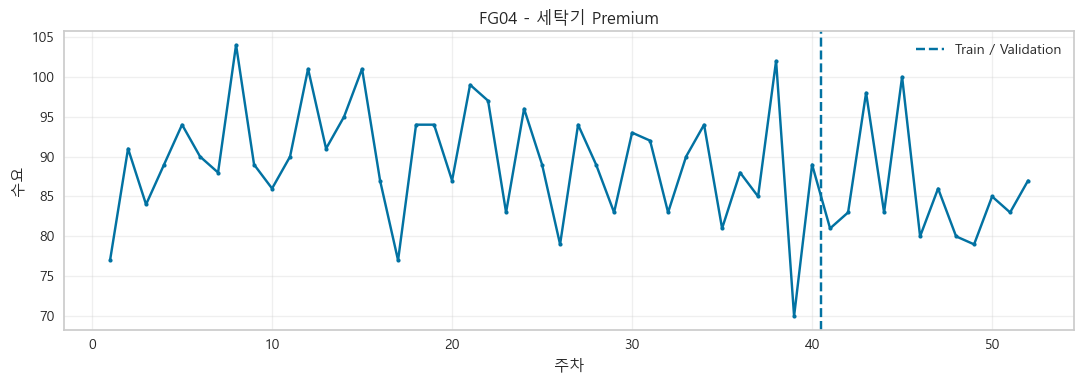

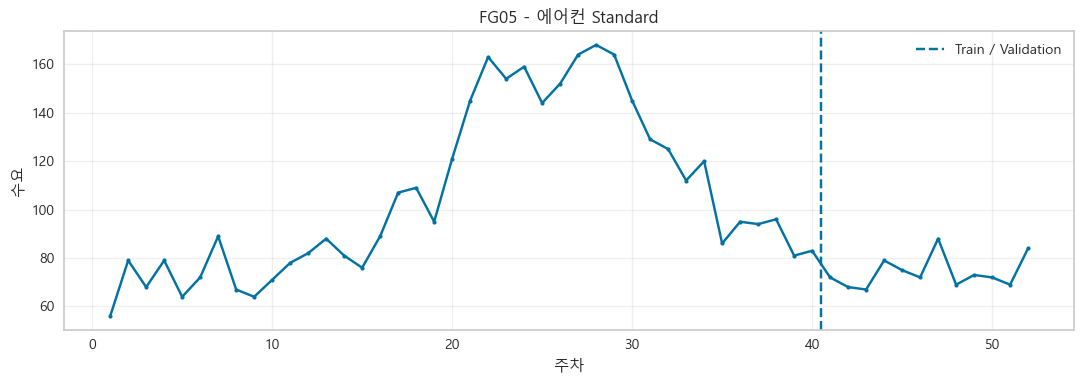

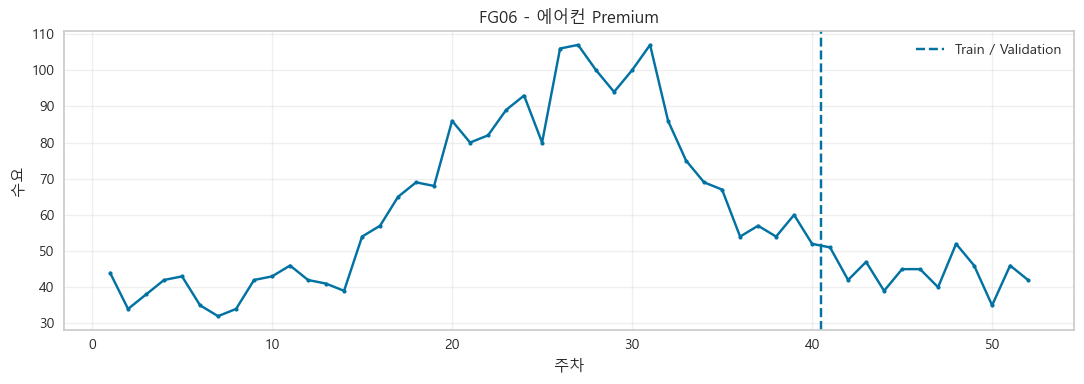



모델 Input Feature 확인


,product_id,week,weekly_demand_units,lag1,lag2,avg4,week_num,week_sin,week_cos
0,FG01,1,158,NaN,NaN,NaN,1.0,0.120537,9.927089e-01
1,FG01,2,158,158.0,NaN,NaN,2.0,0.239316,9.709418e-01
2,FG01,3,161,158.0,158.0,NaN,3.0,0.354605,9.350162e-01
3,FG01,4,173,161.0,158.0,NaN,4.0,0.464723,8.854560e-01
4,FG01,5,163,173.0,161.0,162.50,5.0,0.568065,8.229839e-01
5,FG01,6,146,163.0,173.0,163.75,6.0,0.663123,7.485107e-01
6,FG01,7,172,146.0,163.0,160.75,7.0,0.748511,6.631227e-01
7,FG01,8,166,172.0,146.0,163.50,8.0,0.822984,5.680647e-01
8,FG01,9,168,166.0,172.0,161.75,9.0,0.885456,4.647232e-01
9,FG01,10,173,168.0,166.0,163.00,10.0,0.935016,3.546049e-01




전체 모델 Validation 성능


,product_id,product_name,model,MAE,RMSE,MAPE
0,FG01,냉장고 Standard,BayesianRidge,5.966,6.851,3.612
1,FG01,냉장고 Standard,HistGradientBoosting,6.366,7.672,3.881
2,FG01,냉장고 Standard,RandomForest,6.746,7.481,3.974
3,FG01,냉장고 Standard,ExtraTrees,7.188,7.700,4.239
4,FG01,냉장고 Standard,Lasso,7.423,9.142,4.304
5,FG01,냉장고 Standard,LinearRegression,7.310,8.929,4.412
6,FG01,냉장고 Standard,Ridge,7.737,8.369,4.564
7,FG02,냉장고 Premium,BayesianRidge,7.730,9.975,6.902
8,FG02,냉장고 Premium,HistGradientBoosting,7.736,9.982,6.905
9,FG02,냉장고 Premium,Lasso,7.837,9.703,7.119




제품별 최적 모델


,product_id,product_name,model,MAE,RMSE,MAPE
0,FG01,냉장고 Standard,BayesianRidge,5.966,6.851,3.612
1,FG02,냉장고 Premium,BayesianRidge,7.730,9.975,6.902
2,FG03,세탁기 Standard,Ridge,5.824,7.261,4.587
3,FG04,세탁기 Premium,BayesianRidge,5.532,7.084,6.340
4,FG05,에어컨 Standard,ExtraTrees,6.938,7.627,9.498
5,FG06,에어컨 Premium,BayesianRidge,6.063,8.157,13.555




제품별 Validation 예측오차


,product_id,product_name,selected_model,mean_error,sigma_error,MAPE
0,FG01,냉장고 Standard,BayesianRidge,-2.487,6.668,3.612
1,FG02,냉장고 Premium,BayesianRidge,2.549,10.072,6.902
2,FG03,세탁기 Standard,Ridge,0.099,7.583,4.587
3,FG04,세탁기 Premium,BayesianRidge,-0.923,7.335,6.340
4,FG05,에어컨 Standard,ExtraTrees,-3.644,6.998,9.498
5,FG06,에어컨 Premium,BayesianRidge,3.413,7.738,13.555


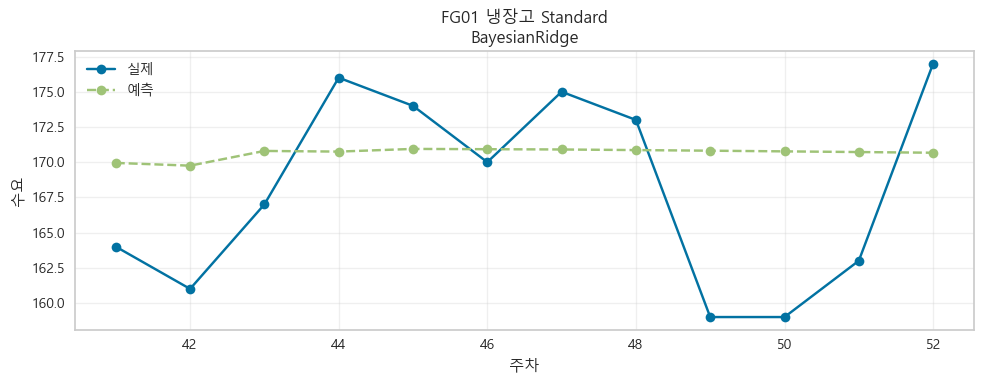

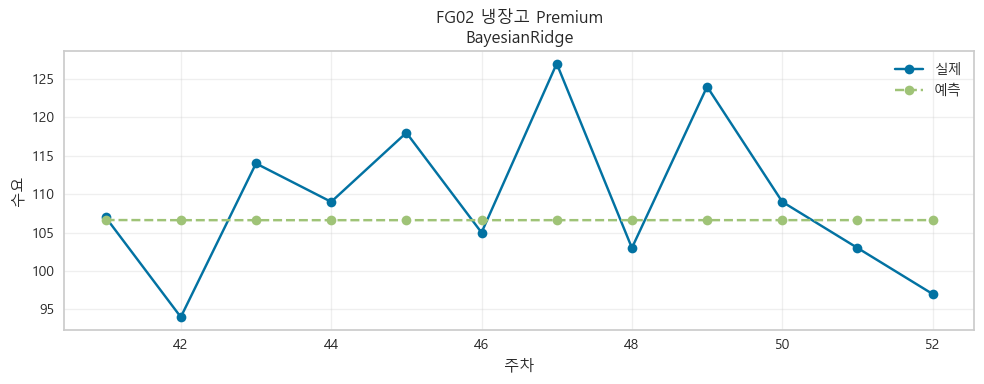

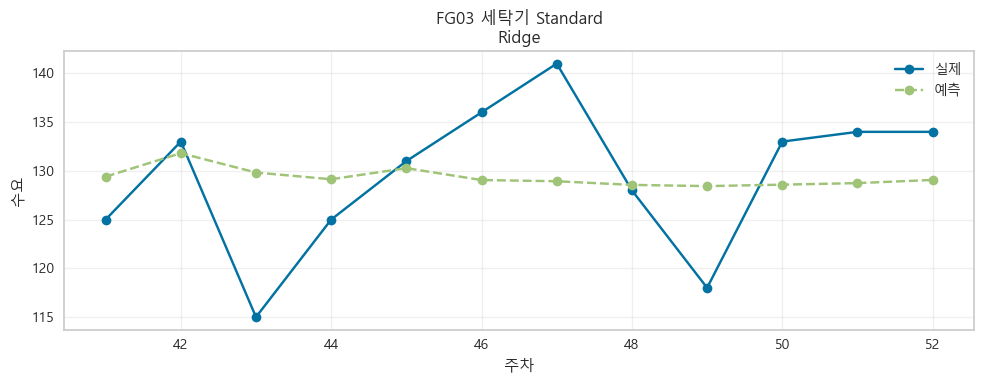

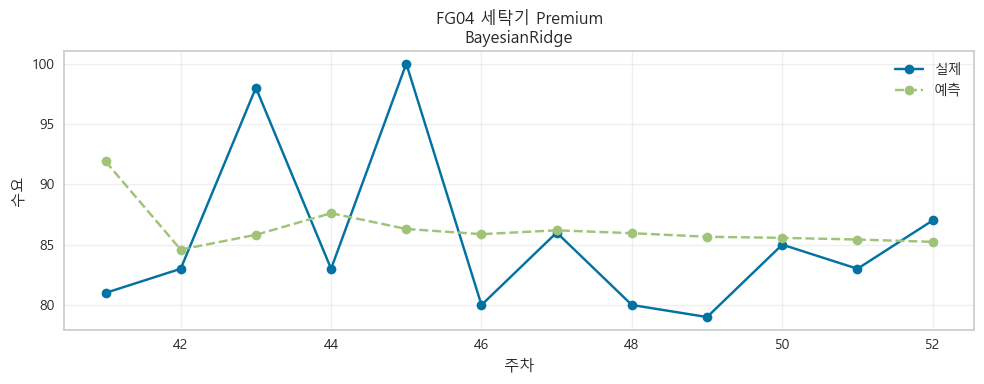

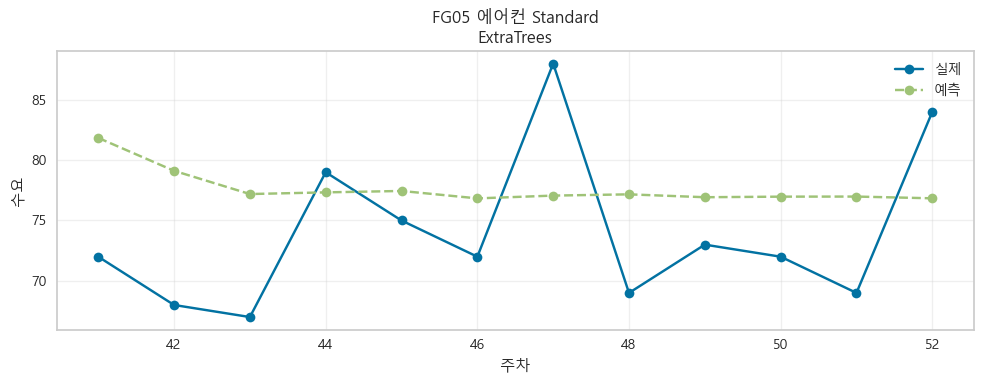

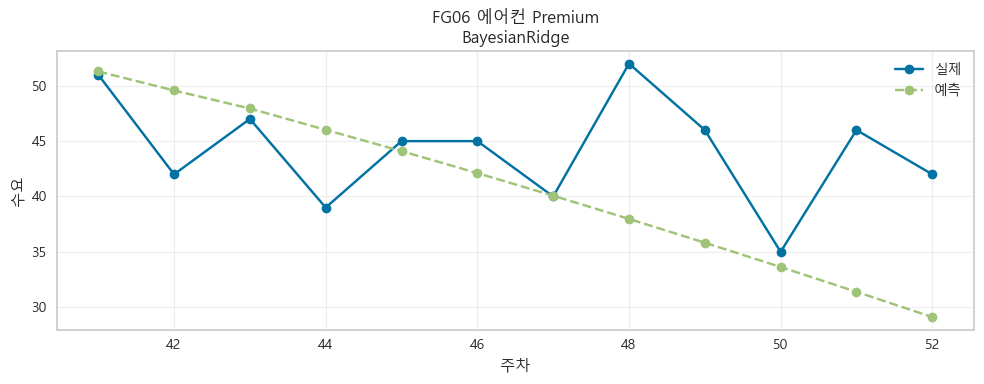



W53~W65 최종 Forecast


,product_id,product_name,selected_model,week,predicted_demand
0,FG01,냉장고 Standard,BayesianRidge,53,169.31
1,FG01,냉장고 Standard,BayesianRidge,54,169.35
2,FG01,냉장고 Standard,BayesianRidge,55,168.96
3,FG01,냉장고 Standard,BayesianRidge,56,168.91
4,FG01,냉장고 Standard,BayesianRidge,57,168.72
...,...,...,...,...,...
73,FG06,에어컨 Premium,BayesianRidge,61,29.66
74,FG06,에어컨 Premium,BayesianRidge,62,28.24
75,FG06,에어컨 Premium,BayesianRidge,63,26.81
76,FG06,에어컨 Premium,BayesianRidge,64,25.36




W53~W65 제품별 예측


,week,FG01,FG02,FG03,FG04,FG05,FG06
0,53,169.31,107.28,131.35,84.07,73.80,40.87
1,54,169.35,107.29,130.67,84.09,73.91,39.25
2,55,168.96,107.31,132.12,84.12,73.77,38.04
3,56,168.91,107.32,133.50,83.83,73.61,36.64
4,57,168.72,107.32,134.92,83.71,74.65,35.27
5,58,168.63,107.32,135.78,83.52,74.44,33.88
6,59,168.53,107.33,136.54,83.33,74.53,32.48
7,60,168.44,107.33,137.40,83.16,74.20,31.08
8,61,168.35,107.33,138.31,82.97,73.88,29.66
9,62,168.26,107.34,139.27,82.80,74.46,28.24


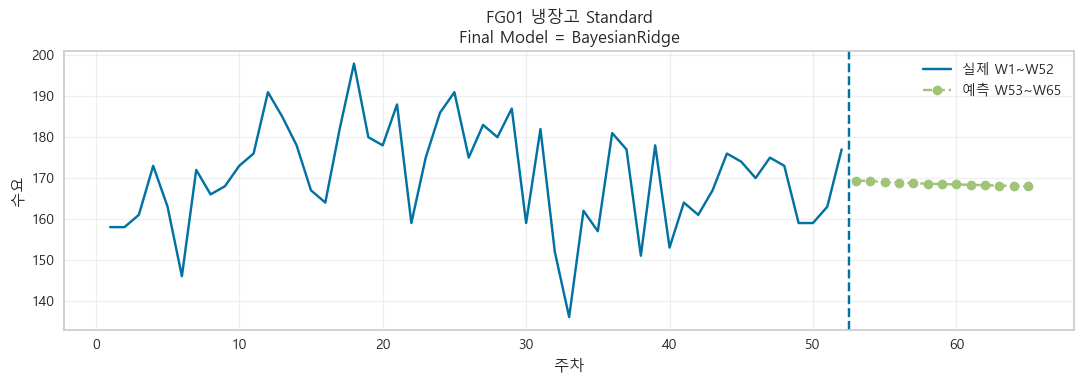

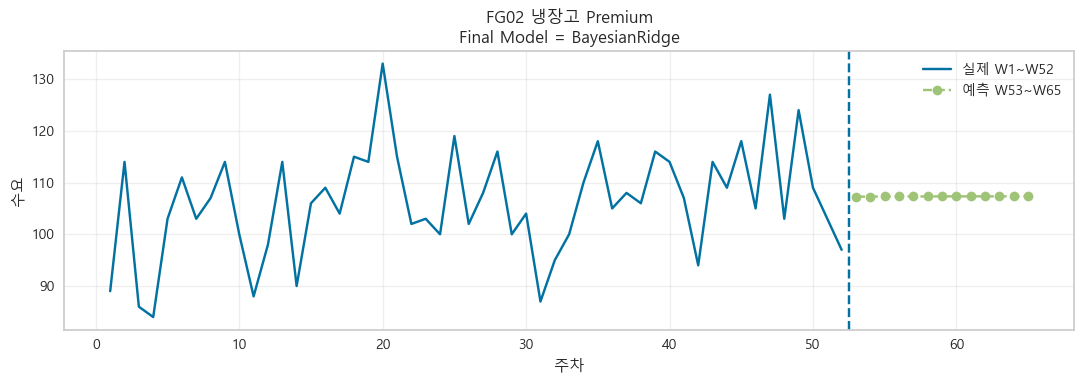

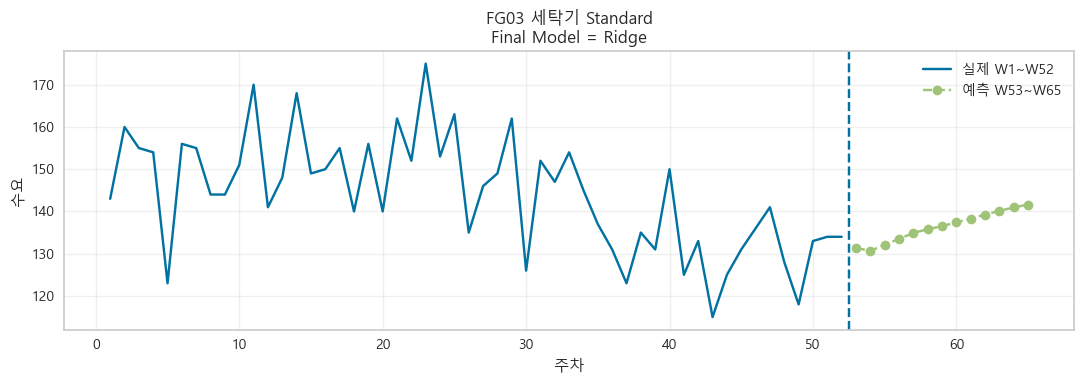

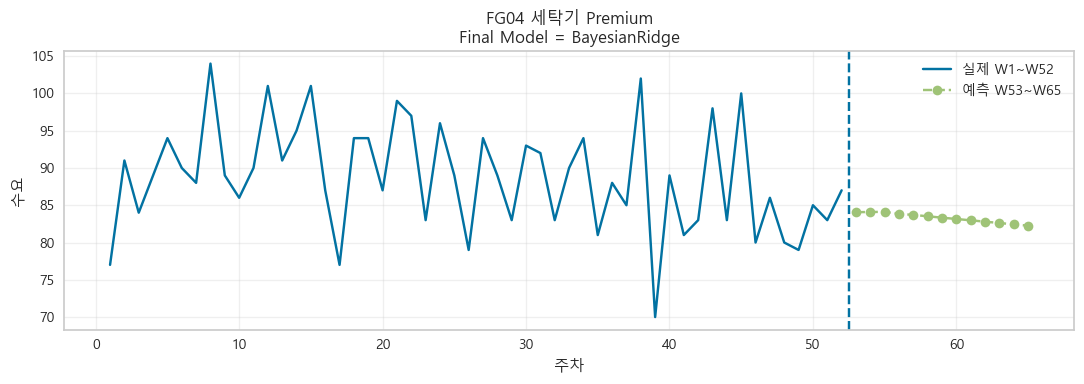

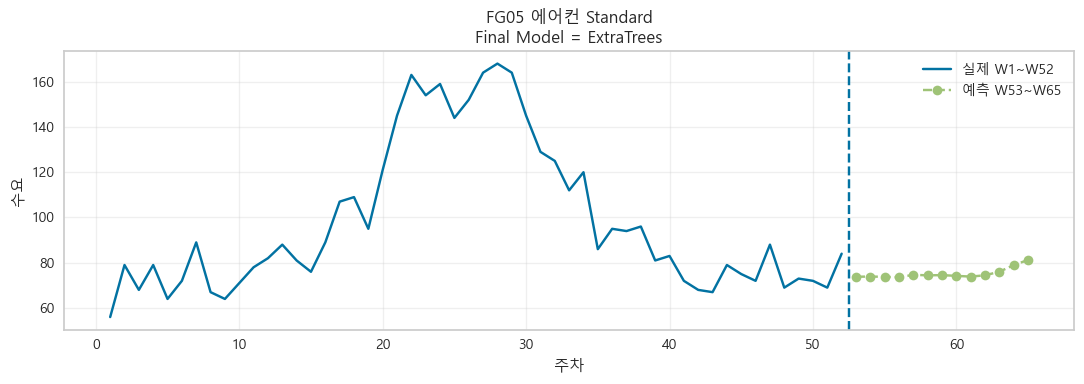

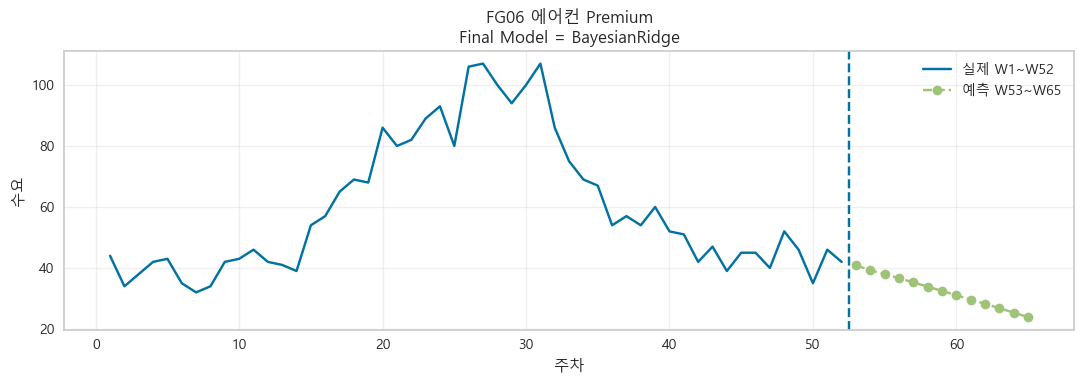



완제품 정책 계산용 μ / σ


,product_id,product_name,selected_model,forecast_mu,future_forecast_std,sigma_error,mean_error,MAPE
0,FG01,냉장고 Standard,BayesianRidge,168.591,0.443,6.668,-2.487,3.612
1,FG02,냉장고 Premium,BayesianRidge,107.323,0.020,10.072,2.549,6.902
2,FG03,세탁기 Standard,Ridge,136.353,3.680,7.583,0.099,4.587
3,FG04,세탁기 Premium,BayesianRidge,83.300,0.650,7.335,-0.923,6.340
4,FG05,에어컨 Standard,ExtraTrees,75.191,2.313,6.998,-3.644,9.498
5,FG06,에어컨 Premium,BayesianRidge,32.423,5.464,7.738,3.413,13.555




완제품 6종 정책 A


,product_id,product_name,selected_model,forecast_mu,sigma_error,safety_stock,s,Q_raw,Q,S
0,FG01,냉장고 Standard,BayesianRidge,168.59,6.67,12,180,299.86,300,480
1,FG02,냉장고 Premium,BayesianRidge,107.32,10.07,17,124,231.65,240,364
2,FG03,세탁기 Standard,Ridge,136.35,7.58,13,149,261.11,270,419
3,FG04,세탁기 Premium,BayesianRidge,83.30,7.34,13,96,198.92,200,296
4,FG05,에어컨 Standard,ExtraTrees,75.19,7.00,12,87,191.11,200,287
5,FG06,에어컨 Premium,BayesianRidge,32.42,7.74,13,46,125.90,130,176




완제품 정책 계산식

[FG01 냉장고 Standard]
μ = 168.591
σ_error = 6.668
s = ceil(168.591 + 1.65 × 6.668) = 180
Q* = sqrt(2 × 800000 × 168.591 / 3000) = 299.86
생산단위 올림 Q = 300
S = 180 + 300 = 480

[FG02 냉장고 Premium]
μ = 107.323
σ_error = 10.072
s = ceil(107.323 + 1.65 × 10.072) = 124
Q* = sqrt(2 × 1000000 × 107.323 / 4000) = 231.65
생산단위 올림 Q = 240
S = 124 + 240 = 364

[FG03 세탁기 Standard]
μ = 136.353
σ_error = 7.583
s = ceil(136.353 + 1.65 × 7.583) = 149
Q* = sqrt(2 × 750000 × 136.353 / 3000) = 261.11
생산단위 올림 Q = 270
S = 149 + 270 = 419

[FG04 세탁기 Premium]
μ = 83.300
σ_error = 7.335
s = ceil(83.300 + 1.65 × 7.335) = 96
Q* = sqrt(2 × 950000 × 83.300 / 4000) = 198.92
생산단위 올림 Q = 200
S = 96 + 200 = 296

[FG05 에어컨 Standard]
μ = 75.191
σ_error = 6.998
s = ceil(75.191 + 1.65 × 6.998) = 87
Q* = sqrt(2 × 850000 × 75.191 / 3500) = 191.11
생산단위 올림 Q = 200
S = 87 + 200 = 287

[FG06 에어컨 Premium]
μ = 32.423
σ_error = 7.738
s = ceil(32.423 + 1.65 × 7.738) = 46
Q* = sqrt(2 × 1100000 × 32.423 / 4500) = 125.90
생산단위

...

총 행 수: 15
ID 중복: 0
s < S: True


민감도 분석 : 원자재 변동성 2배


,material_id,material_name,forecast_mu,sigma,sigma_2x,safety_stock,safety_stock_2x,s,s_2x,S,S_2x
0,RM01,도장 강판 세트,603.18,19.13,38.27,32,64,635,667,1435,1467
1,RM02,Main PCB,603.18,19.13,38.27,32,64,635,667,1335,1367
2,RM03,BLDC Motor,219.65,10.55,21.10,18,35,238,255,618,635
3,RM04,Compressor,383.53,15.96,31.92,27,53,410,437,810,837
4,RM05,Heat Exchanger,107.61,10.43,20.87,18,35,125,143,375,393
5,RM06,Drum Assembly,219.65,10.55,21.10,18,35,238,255,638,655
6,RM07,Display Module,223.05,14.67,29.33,25,49,248,272,768,792
7,RM08,Wiring Harness,603.18,19.13,38.27,32,64,635,667,1735,1767
8,RM09,Fan Motor,140.04,16.98,33.97,29,57,169,197,509,537




정책 A vs 변동성 2배 차이


,material_id,material_name,s,s_2x,s_change,S,S_2x,S_change
0,RM01,도장 강판 세트,635,667,32,1435,1467,32
1,RM02,Main PCB,635,667,32,1335,1367,32
2,RM03,BLDC Motor,238,255,17,618,635,17
3,RM04,Compressor,410,437,27,810,837,27
4,RM05,Heat Exchanger,125,143,18,375,393,18
5,RM06,Drum Assembly,238,255,17,638,655,17
6,RM07,Display Module,248,272,24,768,792,24
7,RM08,Wiring Harness,635,667,32,1735,1767,32
8,RM09,Fan Motor,169,197,28,509,537,28



모든 결과 저장 완료


In [11]:
# ============================================================
# Operation Mini Case - 최종 통합 코드
#
# [모델 검증]
# W1~W40  : Train
# W41~W52 : Validation
#
# [최종 Forecast]
# Validation에서 제품별 최적 모델 선정
# -> W1~W52 전체로 재학습
# -> W53~W65 예측
#
# [완제품 정책 A]
# mu    = W53~W65 예측 평균
# sigma = W41~W52 Validation 예측오차 표준편차
#
# s  = ceil(mu + z*sigma)
# Q* = sqrt(2*K*mu/h)
# Q  = 생산단위 올림
# S  = s + Q
#
# [원자재 정책 A]
# mu_RM = sum(BOM * mu_FG)
#
# 제품들이 독립이라고 가정:
# sigma_RM = sqrt(sum((BOM*sigma_FG)^2))
#
# 기본 제출에서는 sigma 2배 하지 않음
#
# [민감도]
# 별도로 sigma_RM * 2 정책 계산
# ============================================================


# ============================================================
# 0. Windows joblib 병렬처리 오류 방지
# ============================================================

import os

os.environ["LOKY_MAX_CPU_COUNT"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"


# ============================================================
# 1. 라이브러리
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    BayesianRidge
)

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


# ============================================================
# 2. 기본 설정
# ============================================================

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

TRAIN_END = 40

VALID_START = 41
VALID_END = 52

FORECAST_START = 53
FORECAST_END = 65

# 강의 기준 95% 서비스수준
Z = 1.65


# ============================================================
# 3. 데이터 불러오기
# ============================================================

demand = pd.read_csv(
    "historical_demand.csv"
)

bom = pd.read_csv(
    "bom.csv"
)

production = pd.read_csv(
    "production_master.csv"
)

warehouse = pd.read_csv(
    "warehouse_master.csv"
)

raw_master = pd.read_csv(
    "raw_material_master.csv"
)


for df in [
    demand,
    bom,
    production,
    warehouse,
    raw_master
]:

    df.columns = (
        df.columns
        .str.strip()
    )


# ============================================================
# 4. 데이터 정리
# ============================================================

demand["week"] = pd.to_numeric(
    demand["week"],
    errors="coerce"
)

demand["weekly_demand_units"] = pd.to_numeric(
    demand["weekly_demand_units"],
    errors="coerce"
)


demand = (
    demand

    .dropna(
        subset=[
            "product_id",
            "week",
            "weekly_demand_units"
        ]
    )

    .drop_duplicates()

    .sort_values(
        [
            "product_id",
            "week"
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 5. EDA
# ============================================================

print("=" * 100)
print("EDA")
print("=" * 100)

print(
    "수요 데이터 shape:",
    demand.shape
)

print(
    "완제품 수:",
    demand[
        "product_id"
    ].nunique()
)


print("\n상품별 데이터 수")

display(
    demand
    .groupby(
        [
            "product_id",
            "product_name"
        ]
    )
    .size()
)


print("\n결측치")

display(
    demand
    .isnull()
    .sum()
)


print(
    "\n중복행:",
    demand
    .duplicated()
    .sum()
)


print("\n제품별 주차")

display(
    demand
    .groupby(
        "product_id"
    )["week"]
    .agg(
        최소="min",
        최대="max",
        개수="count",
        고유주차="nunique"
    )
)


# ============================================================
# 6. 제품별 평균 / 표준편차 / CV
# ============================================================

product_stats = (
    demand

    .groupby(
        [
            "product_id",
            "product_name"
        ]
    )[
        "weekly_demand_units"
    ]

    .agg(
        평균="mean",
        표준편차="std",
        최소="min",
        최대="max"
    )

    .reset_index()
)


product_stats[
    "CV"
] = (
    product_stats[
        "표준편차"
    ]
    /
    product_stats[
        "평균"
    ]
)


print("\n")
print("=" * 100)
print("제품별 수요 특성")
print("=" * 100)

display(
    product_stats
    .round(3)
)


# ============================================================
# 7. 제품별 수요 시각화
# ============================================================

for product_id in sorted(
    demand[
        "product_id"
    ].unique()
):

    temp = (
        demand[
            demand[
                "product_id"
            ]
            == product_id
        ]

        .sort_values(
            "week"
        )
    )


    product_name = (
        temp[
            "product_name"
        ]
        .iloc[0]
    )


    plt.figure(
        figsize=(11, 4)
    )


    plt.plot(
        temp["week"],
        temp[
            "weekly_demand_units"
        ],
        marker="o",
        markersize=3
    )


    plt.axvline(
        40.5,
        linestyle="--",
        label="Train / Validation"
    )


    plt.title(
        f"{product_id} - {product_name}"
    )

    plt.xlabel(
        "주차"
    )

    plt.ylabel(
        "수요"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# 8. 머신러닝 Feature 생성
#
# lag1  = 1주 전
# lag2  = 2주 전
# avg4  = 직전 4주 평균
#
# + 주차 / sin / cos
# ============================================================

feature_parts = []


for product_id, g in demand.groupby(
    "product_id"
):

    g = (
        g
        .sort_values(
            "week"
        )
        .reset_index(
            drop=True
        )
        .copy()
    )


    y = (
        g[
            "weekly_demand_units"
        ]
        .to_numpy(
            dtype=float
        )
    )


    n = len(g)


    lag1 = np.full(
        n,
        np.nan
    )

    lag2 = np.full(
        n,
        np.nan
    )

    avg4 = np.full(
        n,
        np.nan
    )


    for i in range(
        1,
        n
    ):

        lag1[i] = (
            y[i - 1]
        )


    for i in range(
        2,
        n
    ):

        lag2[i] = (
            y[i - 2]
        )


    for i in range(
        4,
        n
    ):

        avg4[i] = (
            np.mean(
                y[
                    i - 4:i
                ]
            )
        )


    g["lag1"] = lag1

    g["lag2"] = lag2

    g["avg4"] = avg4


    g["week_num"] = (
        g[
            "week"
        ].astype(float)
    )


    g["week_sin"] = np.sin(
        2
        *
        np.pi
        *
        g["week_num"]
        /
        52
    )


    g["week_cos"] = np.cos(
        2
        *
        np.pi
        *
        g["week_num"]
        /
        52
    )


    feature_parts.append(
        g
    )


demand_feature = pd.concat(
    feature_parts,
    ignore_index=True
)


FEATURE_COLS = [
    "lag1",
    "lag2",
    "avg4",
    "week_num",
    "week_sin",
    "week_cos"
]


print("\n")
print("=" * 100)
print("모델 Input Feature 확인")
print("=" * 100)

display(
    demand_feature[
        [
            "product_id",
            "week",
            "weekly_demand_units"
        ]
        +
        FEATURE_COLS
    ]
    .head(15)
)


# ============================================================
# 9. 평가 함수
# ============================================================

def calc_mape(
    actual,
    pred
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    pred = np.asarray(
        pred,
        dtype=float
    )


    mask = (
        actual != 0
    )


    return (
        np.mean(
            np.abs(
                (
                    actual[mask]
                    -
                    pred[mask]
                )
                /
                actual[mask]
            )
        )
        *
        100
    )


def evaluate_model(
    actual,
    pred
):

    mae = mean_absolute_error(
        actual,
        pred
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            pred
        )
    )


    mape = calc_mape(
        actual,
        pred
    )


    return (
        mae,
        rmse,
        mape
    )


# ============================================================
# 10. 후보 모델
# ============================================================

MODEL_CANDIDATES = {

    "LinearRegression":
        LinearRegression(),

    "Ridge":
        Ridge(
            alpha=1.0
        ),

    "Lasso":
        Lasso(
            alpha=1.0,
            max_iter=10000
        ),

    "BayesianRidge":
        BayesianRidge(),

    "RandomForest":
        RandomForestRegressor(
            n_estimators=300,
            max_depth=4,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=1
        ),

    "ExtraTrees":
        ExtraTreesRegressor(
            n_estimators=300,
            max_depth=4,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=1
        ),

    "HistGradientBoosting":
        HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=7,
            l2_regularization=1.0,
            random_state=42
        )
}


# ============================================================
# 11. 재귀 미래예측 함수
# ============================================================

def recursive_forecast(
    model,
    history_df,
    target_weeks
):

    history_values = (
        history_df[
            "weekly_demand_units"
        ]
        .astype(float)
        .tolist()
    )


    predictions = []


    for week in target_weeks:

        week = float(
            week
        )


        lag1 = float(
            history_values[-1]
        )


        lag2 = float(
            history_values[-2]
        )


        avg4 = float(
            np.mean(
                history_values[
                    -4:
                ]
            )
        )


        X_next = pd.DataFrame(
            {
                "lag1": [
                    lag1
                ],

                "lag2": [
                    lag2
                ],

                "avg4": [
                    avg4
                ],

                "week_num": [
                    week
                ],

                "week_sin": [
                    np.sin(
                        2
                        *
                        np.pi
                        *
                        week
                        /
                        52
                    )
                ],

                "week_cos": [
                    np.cos(
                        2
                        *
                        np.pi
                        *
                        week
                        /
                        52
                    )
                ]
            }
        )


        X_next = (
            X_next[
                FEATURE_COLS
            ]
            .astype(float)
        )


        pred = float(
            model.predict(
                X_next
            )[0]
        )


        pred = max(
            pred,
            0
        )


        predictions.append(
            pred
        )


        history_values.append(
            pred
        )


    return np.array(
        predictions
    )


# ============================================================
# 12. STEP 1
#
# W1~W40 학습
# W41~W52 Validation
# ============================================================

validation_results = []

prediction_store = {}


for product_id in sorted(
    demand[
        "product_id"
    ].unique()
):

    product_raw = (
        demand[
            demand[
                "product_id"
            ]
            == product_id
        ]

        .sort_values(
            "week"
        )

        .copy()
    )


    product_feature = (
        demand_feature[
            demand_feature[
                "product_id"
            ]
            == product_id
        ]

        .sort_values(
            "week"
        )

        .copy()
    )


    product_name = (
        product_raw[
            "product_name"
        ]
        .iloc[0]
    )


    train_raw = (
        product_raw[
            product_raw[
                "week"
            ]
            <= TRAIN_END
        ]
        .copy()
    )


    valid_raw = (
        product_raw[
            (
                product_raw[
                    "week"
                ]
                >= VALID_START
            )
            &
            (
                product_raw[
                    "week"
                ]
                <= VALID_END
            )
        ]
        .copy()
    )


    train_feature = (
        product_feature[
            product_feature[
                "week"
            ]
            <= TRAIN_END
        ]

        .dropna(
            subset=
                FEATURE_COLS
                +
                [
                    "weekly_demand_units"
                ]
        )

        .copy()
    )


    X_train = (
        train_feature[
            FEATURE_COLS
        ]
        .astype(float)
    )


    y_train = (
        train_feature[
            "weekly_demand_units"
        ]
        .astype(float)
    )


    actual = (
        valid_raw[
            "weekly_demand_units"
        ]
        .to_numpy(
            dtype=float
        )
    )


    valid_weeks = (
        valid_raw[
            "week"
        ]
        .to_numpy(
            dtype=float
        )
    )


    model_predictions = {}


    for model_name, prototype in MODEL_CANDIDATES.items():

        model = clone(
            prototype
        )


        model.fit(
            X_train,
            y_train
        )


        pred = recursive_forecast(
            model=
                model,

            history_df=
                train_raw,

            target_weeks=
                valid_weeks
        )


        mae, rmse, mape = (
            evaluate_model(
                actual,
                pred
            )
        )


        validation_results.append(
            {
                "product_id":
                    product_id,

                "product_name":
                    product_name,

                "model":
                    model_name,

                "MAE":
                    mae,

                "RMSE":
                    rmse,

                "MAPE":
                    mape
            }
        )


        model_predictions[
            model_name
        ] = pred


    prediction_store[
        product_id
    ] = {

        "weeks":
            valid_weeks,

        "actual":
            actual,

        "predictions":
            model_predictions
    }


# ============================================================
# 13. 전체 Validation 성능
# ============================================================

validation_df = pd.DataFrame(
    validation_results
)


validation_df = (
    validation_df

    .sort_values(
        [
            "product_id",
            "MAPE",
            "RMSE"
        ]
    )

    .reset_index(
        drop=True
    )
)


print("\n")
print("=" * 100)
print("전체 모델 Validation 성능")
print("=" * 100)

display(
    validation_df.round(3)
)


# ============================================================
# 14. 제품별 최적 모델
# ============================================================

best_models = (
    validation_df

    .sort_values(
        [
            "product_id",
            "MAPE",
            "RMSE"
        ]
    )

    .groupby(
        [
            "product_id",
            "product_name"
        ],
        as_index=False
    )

    .first()
)


print("\n")
print("=" * 100)
print("제품별 최적 모델")
print("=" * 100)

display(
    best_models[
        [
            "product_id",
            "product_name",
            "model",
            "MAE",
            "RMSE",
            "MAPE"
        ]
    ]
    .round(3)
)


# ============================================================
# 15. W41~W52 Validation Error
#
# sigma_error를 완제품 재고정책에 사용
# ============================================================

error_rows = []


for _, row in best_models.iterrows():

    pid = row[
        "product_id"
    ]


    model_name = row[
        "model"
    ]


    actual = (
        prediction_store[
            pid
        ][
            "actual"
        ]
    )


    pred = (
        prediction_store[
            pid
        ][
            "predictions"
        ][
            model_name
        ]
    )


    error = (
        actual
        -
        pred
    )


    error_rows.append(
        {
            "product_id":
                pid,

            "product_name":
                row[
                    "product_name"
                ],

            "selected_model":
                model_name,

            "mean_error":
                np.mean(
                    error
                ),

            "sigma_error":
                np.std(
                    error,
                    ddof=1
                ),

            "MAPE":
                row[
                    "MAPE"
                ]
        }
    )


error_stats = pd.DataFrame(
    error_rows
)


print("\n")
print("=" * 100)
print("제품별 Validation 예측오차")
print("=" * 100)

display(
    error_stats.round(3)
)


# ============================================================
# 16. Validation 실제 vs 예측
# ============================================================

for _, row in best_models.iterrows():

    pid = row[
        "product_id"
    ]

    model_name = row[
        "model"
    ]


    plt.figure(
        figsize=(10, 4)
    )


    plt.plot(
        prediction_store[
            pid
        ]["weeks"],

        prediction_store[
            pid
        ]["actual"],

        marker="o",

        label="실제"
    )


    plt.plot(
        prediction_store[
            pid
        ]["weeks"],

        prediction_store[
            pid
        ]["predictions"][
            model_name
        ],

        marker="o",

        linestyle="--",

        label="예측"
    )


    plt.title(
        f"{pid} {row['product_name']}\n"
        f"{model_name}"
    )


    plt.xlabel(
        "주차"
    )

    plt.ylabel(
        "수요"
    )


    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 17. STEP 2
#
# 제품별 최적모델 선택 완료
#
# W1~W52 전체 데이터로 다시 학습
# -> W53~W65 Forecast
# ============================================================

future_weeks = np.arange(
    53,
    66
)


future_rows = []


for _, row in best_models.iterrows():

    pid = row[
        "product_id"
    ]


    product_name = row[
        "product_name"
    ]


    selected_model = row[
        "model"
    ]


    product_raw = (
        demand[
            demand[
                "product_id"
            ]
            == pid
        ]

        .sort_values(
            "week"
        )

        .copy()
    )


    product_feature = (
        demand_feature[
            demand_feature[
                "product_id"
            ]
            == pid
        ]

        .dropna(
            subset=
                FEATURE_COLS
                +
                [
                    "weekly_demand_units"
                ]
        )

        .copy()
    )


    X_final = (
        product_feature[
            FEATURE_COLS
        ]
        .astype(float)
    )


    y_final = (
        product_feature[
            "weekly_demand_units"
        ]
        .astype(float)
    )


    final_model = clone(
        MODEL_CANDIDATES[
            selected_model
        ]
    )


    # ★ W1~W52 전체 재학습
    final_model.fit(
        X_final,
        y_final
    )


    # ★ W53~W65 예측
    future_pred = recursive_forecast(
        model=
            final_model,

        history_df=
            product_raw,

        target_weeks=
            future_weeks
    )


    for week, pred in zip(
        future_weeks,
        future_pred
    ):

        future_rows.append(
            {
                "product_id":
                    pid,

                "product_name":
                    product_name,

                "selected_model":
                    selected_model,

                "week":
                    int(
                        week
                    ),

                "predicted_demand":
                    float(
                        pred
                    )
            }
        )


future_forecast = pd.DataFrame(
    future_rows
)


print("\n")
print("=" * 100)
print("W53~W65 최종 Forecast")
print("=" * 100)

display(
    future_forecast.round(2)
)


# ============================================================
# 18. W53~W65 예측 Pivot
# ============================================================

future_pivot = (
    future_forecast

    .pivot(
        index="week",
        columns="product_id",
        values="predicted_demand"
    )

    .reset_index()
)


future_pivot.columns.name = None


print("\n")
print("=" * 100)
print("W53~W65 제품별 예측")
print("=" * 100)

display(
    future_pivot.round(2)
)


# ============================================================
# 19. W53~W65 시각화
# ============================================================

for _, row in best_models.iterrows():

    pid = row[
        "product_id"
    ]


    hist = (
        demand[
            demand[
                "product_id"
            ]
            == pid
        ]
    )


    fut = (
        future_forecast[
            future_forecast[
                "product_id"
            ]
            == pid
        ]
    )


    plt.figure(
        figsize=(11, 4)
    )


    plt.plot(
        hist[
            "week"
        ],

        hist[
            "weekly_demand_units"
        ],

        label="실제 W1~W52"
    )


    plt.plot(
        fut[
            "week"
        ],

        fut[
            "predicted_demand"
        ],

        marker="o",

        linestyle="--",

        label="예측 W53~W65"
    )


    plt.axvline(
        52.5,
        linestyle="--"
    )


    plt.title(
        f"{pid} {row['product_name']}\n"
        f"Final Model = {row['model']}"
    )


    plt.xlabel(
        "주차"
    )

    plt.ylabel(
        "수요"
    )


    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 20. 완제품 정책용 μ / σ
#
# μ     = W53~W65 예측 평균
# σ     = W41~W52 Validation Error Std
#
# future_forecast_std는 참고용으로만 출력
# ============================================================

forecast_stats = (
    future_forecast

    .groupby(
        [
            "product_id",
            "product_name",
            "selected_model"
        ],
        as_index=False
    )

    .agg(

        forecast_mu=(
            "predicted_demand",
            "mean"
        ),

        future_forecast_std=(
            "predicted_demand",
            "std"
        )
    )
)


fg_stats = pd.merge(

    forecast_stats,

    error_stats[
        [
            "product_id",
            "sigma_error",
            "mean_error",
            "MAPE"
        ]
    ],

    on="product_id",

    how="left"
)


print("\n")
print("=" * 100)
print("완제품 정책 계산용 μ / σ")
print("=" * 100)

display(
    fg_stats.round(3)
)


# ============================================================
# 21. 완제품 비용정보 결합
# ============================================================

fg_calc = pd.merge(

    fg_stats,

    production,

    on=[
        "product_id",
        "product_name"
    ],

    how="left"
)


fg_calc = pd.merge(

    fg_calc,

    warehouse,

    on=[
        "product_id",
        "product_name"
    ],

    how="left"
)


# ============================================================
# 22. 생산/발주 단위 올림 함수
# ============================================================

def ceil_multiple(
    value,
    multiple
):

    return int(
        np.ceil(
            float(value)
            /
            float(multiple)
        )
        *
        float(multiple)
    )


# ============================================================
# 23. 완제품 안전재고
#
# SS = ceil(z × sigma)
# ============================================================

fg_calc[
    "safety_stock"
] = np.ceil(

    Z

    *

    fg_calc[
        "sigma_error"
    ]

).astype(int)


# ============================================================
# 24. 완제품 s
#
# s = ceil(mu + z × sigma)
# ============================================================

fg_calc[
    "s"
] = np.ceil(

    fg_calc[
        "forecast_mu"
    ]

    +

    Z

    *

    fg_calc[
        "sigma_error"
    ]

).astype(int)


# ============================================================
# 25. 완제품 Q*
#
# Q* = sqrt(2*K*mu / h)
# ============================================================

fg_calc[
    "Q_raw"
] = np.sqrt(

    (
        2

        *

        fg_calc[
            "fixed_setup_cost_krw_per_run"
        ]

        *

        fg_calc[
            "forecast_mu"
        ]
    )

    /

    fg_calc[
        "weekly_holding_cost_krw_per_unit"
    ]
)


# 생산단위 올림
fg_calc[
    "Q"
] = fg_calc.apply(

    lambda r:
        ceil_multiple(
            r[
                "Q_raw"
            ],
            r[
                "production_multiple_units"
            ]
        ),

    axis=1
)


# ============================================================
# 26. 완제품 S
# ============================================================

fg_calc[
    "S"
] = (
    fg_calc[
        "s"
    ]
    +
    fg_calc[
        "Q"
    ]
)


fg_result = fg_calc[
    [
        "product_id",
        "product_name",
        "selected_model",
        "forecast_mu",
        "sigma_error",
        "safety_stock",
        "s",
        "Q_raw",
        "Q",
        "S"
    ]
].copy()


print("\n")
print("=" * 100)
print("완제품 6종 정책 A")
print("=" * 100)

display(
    fg_result.round(2)
)


# ============================================================
# 27. 완제품 계산식 숫자까지 출력
# ============================================================

print("\n")
print("=" * 100)
print("완제품 정책 계산식")
print("=" * 100)


for _, r in fg_calc.iterrows():

    print(
        f"\n[{r['product_id']} {r['product_name']}]"
    )

    print(
        f"μ = {r['forecast_mu']:.3f}"
    )

    print(
        f"σ_error = {r['sigma_error']:.3f}"
    )

    print(
        f"s = ceil("
        f"{r['forecast_mu']:.3f} "
        f"+ {Z} × {r['sigma_error']:.3f}"
        f")"
        f" = {r['s']}"
    )

    print(
        f"Q* = sqrt("
        f"2 × {r['fixed_setup_cost_krw_per_run']:.0f} "
        f"× {r['forecast_mu']:.3f} "
        f"/ {r['weekly_holding_cost_krw_per_unit']:.0f}"
        f")"
        f" = {r['Q_raw']:.2f}"
    )

    print(
        f"생산단위 올림 Q = {r['Q']}"
    )

    print(
        f"S = {r['s']} + {r['Q']} = {r['S']}"
    )


# ============================================================
# 28. BOM으로 W53~W65 원자재 예상소요 계산
# ============================================================

bom_weekly = pd.merge(

    future_forecast[
        [
            "product_id",
            "week",
            "predicted_demand"
        ]
    ],

    bom[
        [
            "product_id",
            "material_id",
            "material_name",
            "qty_per_finished_product"
        ]
    ],

    on="product_id",

    how="left"
)


bom_weekly[
    "material_demand"
] = (

    bom_weekly[
        "predicted_demand"
    ]

    *

    bom_weekly[
        "qty_per_finished_product"
    ]
)


rm_weekly = (
    bom_weekly

    .groupby(
        [
            "week",
            "material_id",
            "material_name"
        ],
        as_index=False
    )

    .agg(
        predicted_material_demand=(
            "material_demand",
            "sum"
        )
    )
)


print("\n")
print("=" * 100)
print("원자재 W53~W65 예상소요")
print("=" * 100)

display(
    rm_weekly.round(2)
)


# ============================================================
# 29. 원자재 평균소요
#
# μ_RM
# = Σ(BOM × 제품 μ)
# ============================================================

rm_mu = (

    rm_weekly

    .groupby(
        [
            "material_id",
            "material_name"
        ],
        as_index=False
    )

    .agg(
        forecast_mu=(
            "predicted_material_demand",
            "mean"
        )
    )
)


# ============================================================
# 30. 원자재 표준편차
#
# 완제품 수요오차 독립 가정
#
# sigma_RM
# = sqrt(
#     Σ(BOM × sigma_FG)^2
#   )
#
# ★ 기본 정책 A에서는 ×2 하지 않음
# ============================================================

bom_sigma = pd.merge(

    bom,

    error_stats[
        [
            "product_id",
            "sigma_error"
        ]
    ],

    on="product_id",

    how="left"
)


bom_sigma[
    "sigma_component"
] = (

    bom_sigma[
        "qty_per_finished_product"
    ]

    *

    bom_sigma[
        "sigma_error"
    ]
)


bom_sigma[
    "variance_component"
] = (

    bom_sigma[
        "sigma_component"
    ]

    ** 2
)


rm_sigma = (

    bom_sigma

    .groupby(
        [
            "material_id",
            "material_name"
        ],
        as_index=False
    )

    .agg(
        variance_sum=(
            "variance_component",
            "sum"
        )
    )
)


rm_sigma[
    "sigma"
] = np.sqrt(
    rm_sigma[
        "variance_sum"
    ]
)


# ============================================================
# 31. 원자재 μ + σ
# ============================================================

rm_stats = pd.merge(

    rm_mu,

    rm_sigma[
        [
            "material_id",
            "material_name",
            "sigma"
        ]
    ],

    on=[
        "material_id",
        "material_name"
    ],

    how="left"
)


rm_stats[
    "CV"
] = (

    rm_stats[
        "sigma"
    ]

    /

    rm_stats[
        "forecast_mu"
    ]
)


print("\n")
print("=" * 100)
print("원자재 평균소요 / 표준편차")
print("=" * 100)

display(
    rm_stats.round(3)
)


# ============================================================
# 32. 원자재 계산에 사용한 BOM 상세 출력
# ============================================================

print("\n")
print("=" * 100)
print("원자재 σ 계산 상세")
print("=" * 100)


display(
    bom_sigma[
        [
            "product_id",
            "material_id",
            "material_name",
            "qty_per_finished_product",
            "sigma_error",
            "sigma_component",
            "variance_component"
        ]
    ]
    .round(3)
)


# ============================================================
# 33. 원자재 Master 결합
# ============================================================

rm_calc = pd.merge(

    rm_stats,

    raw_master,

    on=[
        "material_id",
        "material_name"
    ],

    how="left"
)


# ============================================================
# 34. 원자재 안전재고
#
# SS = ceil(z × sigma)
# ============================================================

rm_calc[
    "safety_stock"
] = np.ceil(

    Z

    *

    rm_calc[
        "sigma"
    ]

).astype(int)


# ============================================================
# 35. 원자재 s
#
# s = ceil(mu + z × sigma)
# ============================================================

rm_calc[
    "s"
] = np.ceil(

    rm_calc[
        "forecast_mu"
    ]

    +

    Z

    *

    rm_calc[
        "sigma"
    ]

).astype(int)


# ============================================================
# 36. 원자재 Q*
#
# Q* = sqrt(2*K*mu/h)
# ============================================================

rm_calc[
    "Q_raw"
] = np.sqrt(

    (
        2

        *

        rm_calc[
            "fixed_order_cost_krw_per_order"
        ]

        *

        rm_calc[
            "forecast_mu"
        ]
    )

    /

    rm_calc[
        "weekly_holding_cost_krw_per_unit"
    ]
)


# 주문단위 올림
rm_calc[
    "Q"
] = rm_calc.apply(

    lambda r:
        ceil_multiple(
            r[
                "Q_raw"
            ],
            r[
                "order_multiple_units"
            ]
        ),

    axis=1
)


# ============================================================
# 37. 원자재 S
# ============================================================

rm_calc[
    "S"
] = (

    rm_calc[
        "s"
    ]

    +

    rm_calc[
        "Q"
    ]
)


rm_result = rm_calc[
    [
        "material_id",
        "material_name",
        "forecast_mu",
        "sigma",
        "CV",
        "safety_stock",
        "s",
        "Q_raw",
        "Q",
        "S"
    ]
].copy()


print("\n")
print("=" * 100)
print("원자재 9종 정책 A")
print("=" * 100)

display(
    rm_result.round(2)
)


# ============================================================
# 38. 원자재 숫자 / 계산식 출력
# ============================================================

print("\n")
print("=" * 100)
print("원자재 정책 계산식")
print("=" * 100)


for _, r in rm_calc.iterrows():

    print(
        f"\n[{r['material_id']} {r['material_name']}]"
    )

    print(
        f"μ = {r['forecast_mu']:.3f}"
    )

    print(
        f"σ = {r['sigma']:.3f}"
    )

    print(
        f"안전재고 = ceil("
        f"{Z} × {r['sigma']:.3f}"
        f")"
        f" = {r['safety_stock']}"
    )

    print(
        f"s = ceil("
        f"{r['forecast_mu']:.3f} "
        f"+ {Z} × {r['sigma']:.3f}"
        f")"
        f" = {r['s']}"
    )

    print(
        f"Q* = sqrt("
        f"2 × {r['fixed_order_cost_krw_per_order']:.0f} "
        f"× {r['forecast_mu']:.3f} "
        f"/ {r['weekly_holding_cost_krw_per_unit']:.0f}"
        f")"
        f" = {r['Q_raw']:.2f}"
    )

    print(
        f"주문단위 올림 Q = {r['Q']}"
    )

    print(
        f"S = {r['s']} + {r['Q']} = {r['S']}"
    )


# ============================================================
# 39. 정책 A 최종 제출표
#
# 완제품 6 + 원자재 9 = 총 15개
# ============================================================

fg_submission = (

    fg_calc[
        [
            "product_id",
            "s",
            "S"
        ]
    ]

    .rename(
        columns={
            "product_id":
                "ID"
        }
    )
)


rm_submission = (

    rm_calc[
        [
            "material_id",
            "s",
            "S"
        ]
    ]

    .rename(
        columns={
            "material_id":
                "ID"
        }
    )
)


submission = pd.concat(
    [
        fg_submission,
        rm_submission
    ],
    ignore_index=True
)


expected_ids = (
    [
        f"FG{i:02d}"
        for i in range(
            1,
            7
        )
    ]

    +

    [
        f"RM{i:02d}"
        for i in range(
            1,
            10
        )
    ]
)


submission[
    "order"
] = submission[
    "ID"
].map(
    {
        x: i
        for i, x
        in enumerate(
            expected_ids
        )
    }
)


submission = (

    submission

    .sort_values(
        "order"
    )

    .drop(
        columns=[
            "order"
        ]
    )

    .reset_index(
        drop=True
    )
)


submission[
    "s"
] = submission[
    "s"
].astype(int)


submission[
    "S"
] = submission[
    "S"
].astype(int)


print("\n")
print("=" * 100)
print("정책 A 최종 제출표")
print("=" * 100)

display(
    submission
)


print(
    "총 행 수:",
    len(
        submission
    )
)

print(
    "ID 중복:",
    submission[
        "ID"
    ].duplicated().sum()
)

print(
    "s < S:",
    (
        submission[
            "s"
        ]
        <
        submission[
            "S"
        ]
    ).all()
)


# ============================================================
# 40. 민감도 분석
#
# 원자재 변동성 σ × 2
#
# ★ 기본 제출과 분리
# ============================================================

rm_sensitivity = (
    rm_calc.copy()
)


rm_sensitivity[
    "sigma_2x"
] = (

    2

    *

    rm_sensitivity[
        "sigma"
    ]
)


rm_sensitivity[
    "safety_stock_2x"
] = np.ceil(

    Z

    *

    rm_sensitivity[
        "sigma_2x"
    ]

).astype(int)


rm_sensitivity[
    "s_2x"
] = np.ceil(

    rm_sensitivity[
        "forecast_mu"
    ]

    +

    Z

    *

    rm_sensitivity[
        "sigma_2x"
    ]

).astype(int)


# Q는 수요 평균과 비용 기반이므로 그대로
rm_sensitivity[
    "Q_2x"
] = (
    rm_sensitivity[
        "Q"
    ]
)


rm_sensitivity[
    "S_2x"
] = (

    rm_sensitivity[
        "s_2x"
    ]

    +

    rm_sensitivity[
        "Q_2x"
    ]
)


sensitivity_result = (
    rm_sensitivity[
        [
            "material_id",
            "material_name",
            "forecast_mu",
            "sigma",
            "sigma_2x",
            "safety_stock",
            "safety_stock_2x",
            "s",
            "s_2x",
            "S",
            "S_2x"
        ]
    ]
)


print("\n")
print("=" * 100)
print("민감도 분석 : 원자재 변동성 2배")
print("=" * 100)

display(
    sensitivity_result.round(2)
)


# ============================================================
# 41. 정책 A vs σ×2 변화
# ============================================================

sensitivity_result[
    "s_change"
] = (
    sensitivity_result[
        "s_2x"
    ]
    -
    sensitivity_result[
        "s"
    ]
)


sensitivity_result[
    "S_change"
] = (
    sensitivity_result[
        "S_2x"
    ]
    -
    sensitivity_result[
        "S"
    ]
)


print("\n")
print("=" * 100)
print("정책 A vs 변동성 2배 차이")
print("=" * 100)

display(
    sensitivity_result[
        [
            "material_id",
            "material_name",
            "s",
            "s_2x",
            "s_change",
            "S",
            "S_2x",
            "S_change"
        ]
    ]
)


# ============================================================
# 42. CSV 저장
# ============================================================

product_stats.to_csv(
    "01_product_demand_stats.csv",
    index=False,
    encoding="utf-8-sig"
)


validation_df.to_csv(
    "02_model_validation.csv",
    index=False,
    encoding="utf-8-sig"
)


best_models.to_csv(
    "03_selected_models.csv",
    index=False,
    encoding="utf-8-sig"
)


error_stats.to_csv(
    "04_validation_error.csv",
    index=False,
    encoding="utf-8-sig"
)


future_forecast.to_csv(
    "05_forecast_W53_W65.csv",
    index=False,
    encoding="utf-8-sig"
)


fg_result.to_csv(
    "06_finished_goods_policy_A.csv",
    index=False,
    encoding="utf-8-sig"
)


rm_weekly.to_csv(
    "07_raw_material_forecast.csv",
    index=False,
    encoding="utf-8-sig"
)


rm_result.to_csv(
    "08_raw_material_policy_A.csv",
    index=False,
    encoding="utf-8-sig"
)


submission.to_csv(
    "09_policy_A_submission.csv",
    index=False,
    encoding="utf-8-sig"
)


sensitivity_result.to_csv(
    "10_sigma_2x_sensitivity.csv",
    index=False,
    encoding="utf-8-sig"
)


print("\n모든 결과 저장 완료")

===== 사용 파일 =====
historical_demand.csv
production_master.csv
raw_material_master.csv
warehouse_master.csv
bom.csv

===== 데이터 크기 =====
historical_demand : (312, 5)
production_master : (6, 5)
warehouse_master  : (6, 6)
bom               : (33, 5)
raw_material      : (9, 9)

===== 제품별 주차 개수 =====
product_id
FG01    52
FG02    52
FG03    52
FG04    52
FG05    52
FG06    52
Name: week, dtype: int64

완제품 수요 특성


,product_id,product_name,평균수요,표준편차,최소수요,최대수요,CV
0,FG01,냉장고 Standard,170.52,12.59,136,198,0.074
1,FG02,냉장고 Premium,106.15,10.41,84,133,0.098
2,FG03,세탁기 Standard,143.90,13.80,115,175,0.096
3,FG04,세탁기 Premium,88.65,7.32,70,104,0.083
4,FG05,에어컨 Standard,98.12,32.86,56,168,0.335
5,FG06,에어컨 Premium,59.54,22.35,32,107,0.375



===== 현재 안전재고 진단 =====


,product_id,product_name,평균수요,표준편차,CV,current_safety_stock_units,필요안전재고_95,현재-필요
0,FG01,냉장고 Standard,170.52,12.59,0.07,55,21,34
1,FG02,냉장고 Premium,106.15,10.41,0.10,35,18,17
2,FG03,세탁기 Standard,143.90,13.80,0.10,50,23,27
3,FG04,세탁기 Premium,88.65,7.32,0.08,30,13,17
4,FG05,에어컨 Standard,98.12,32.86,0.33,45,55,-10
5,FG06,에어컨 Premium,59.54,22.35,0.38,25,37,-12


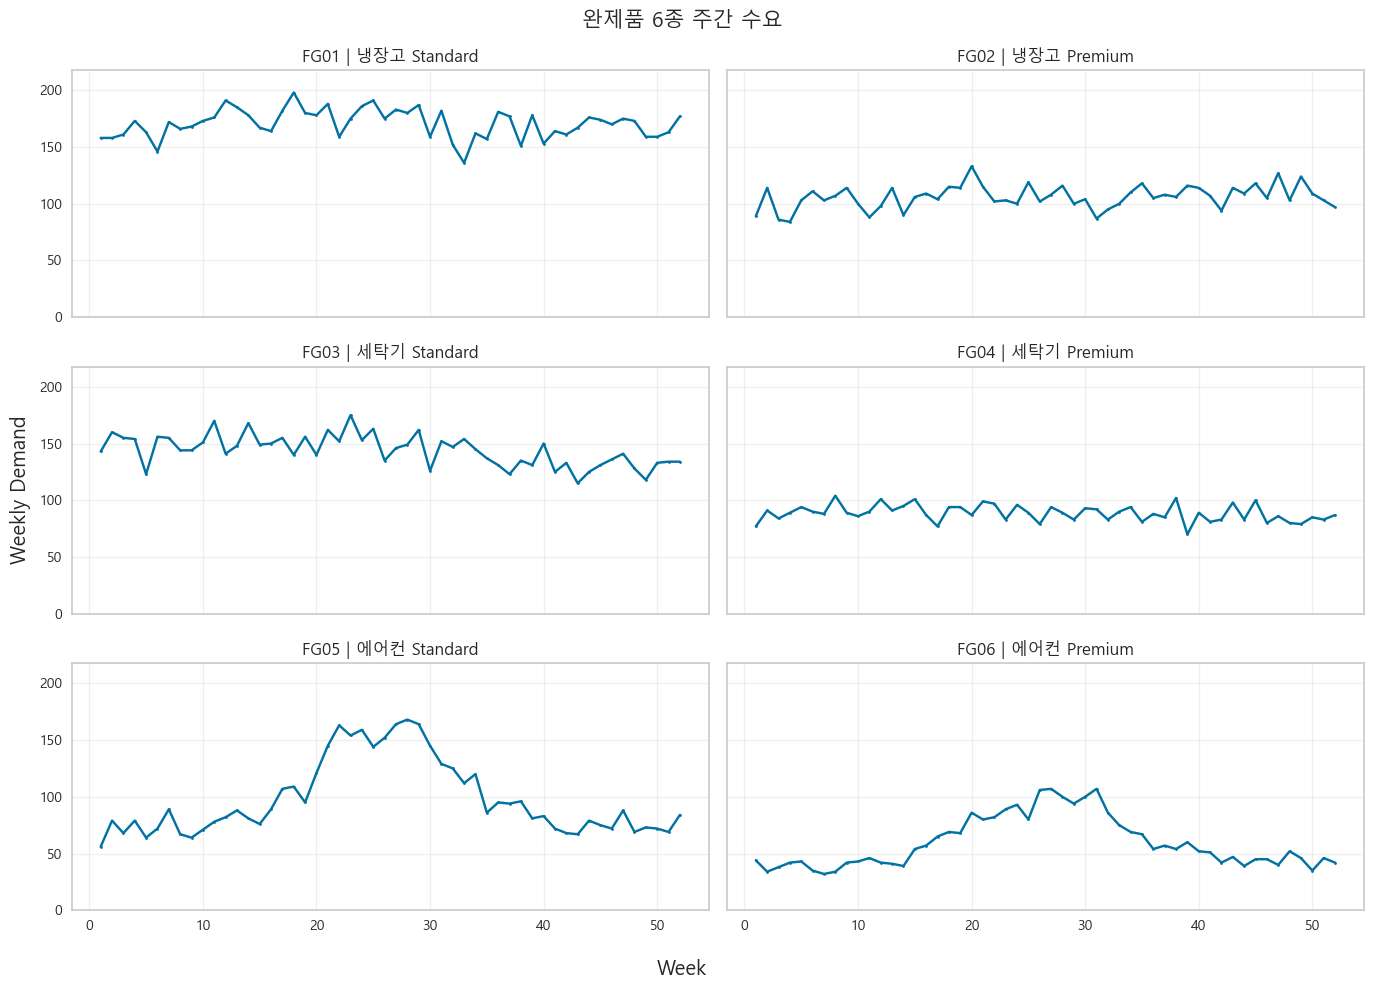


W41~W52 모델별 MAPE


model,product_id,product_name,LinearRegression,RandomForest,선택모델
0,FG01,냉장고 Standard,8.47,4.03,RandomForest
1,FG02,냉장고 Premium,6.98,7.09,LinearRegression
2,FG03,세탁기 Standard,5.17,10.60,LinearRegression
3,FG04,세탁기 Premium,8.94,9.42,LinearRegression
4,FG05,에어컨 Standard,44.48,8.06,RandomForest
5,FG06,에어컨 Premium,48.76,25.77,RandomForest



===== W53 ~ W65 13주 예측 =====


product_id,week,FG01,FG02,FG03,FG04,FG05,FG06
0,53,169.0,105.2,137.8,89.5,71.7,42.4
1,54,162.9,106.4,136.8,88.4,75.5,40.9
2,55,164.0,107.9,138.9,88.9,70.5,41.3
3,56,165.4,107.9,140.3,89.3,72.0,41.8
4,57,165.6,107.4,141.8,89.7,75.5,40.8
5,58,165.6,107.1,143.6,90.1,72.5,39.4
6,59,168.6,106.8,145.1,90.5,76.4,41.4
7,60,170.1,106.7,146.6,90.8,72.1,40.2
8,61,170.3,106.5,148.1,91.1,74.0,43.2
9,62,170.2,106.4,149.5,91.4,73.2,43.1


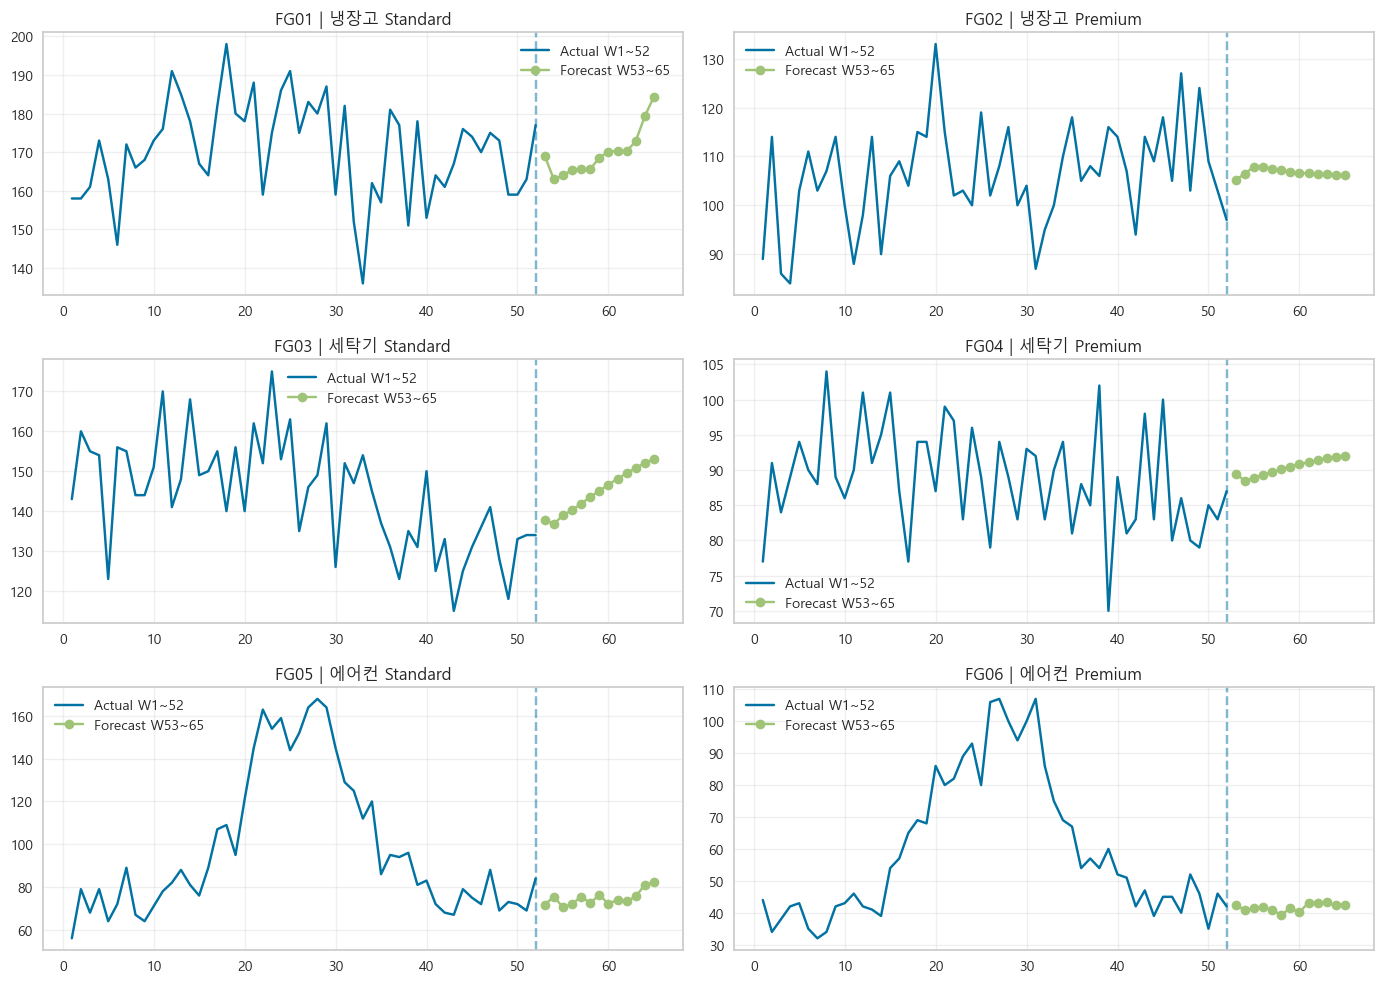


완제품 6종 (s,S)


,ID,name,model,MAPE_pct,mu_13w,sigma_error,s,Q,S
0,FG01,냉장고 Standard,RandomForest,4.03,169.87,7.28,182,310,492
1,FG02,냉장고 Premium,LinearRegression,6.98,106.70,10.13,124,240,364
2,FG03,세탁기 Standard,LinearRegression,5.17,144.96,7.02,157,270,427
3,FG04,세탁기 Premium,LinearRegression,8.94,90.42,8.25,105,210,315
4,FG05,에어컨 Standard,RandomForest,8.06,74.79,7.66,88,200,288
5,FG06,에어컨 Premium,RandomForest,25.77,41.73,4.86,50,150,200



원자재 9종 (s,S)


,ID,name,mu_13w,sigma_error,s,Q,S,생산Lot_필요량,Lot체크
0,RM01,도장 강판 세트,628.47,18.84,660,850,1510,1380,CHECK
1,RM02,Main PCB,628.47,18.84,660,720,1380,1380,CHECK
2,RM03,BLDC Motor,235.38,10.83,254,400,654,480,CHECK
3,RM04,Compressor,393.09,15.42,419,400,819,900,CHECK
4,RM05,Heat Exchanger,116.52,9.07,132,260,392,350,CHECK
5,RM06,Drum Assembly,235.38,10.83,254,420,674,480,CHECK
6,RM07,Display Module,238.85,13.94,262,540,802,600,CHECK
7,RM08,Wiring Harness,628.47,18.84,660,1100,1760,1380,CHECK
8,RM09,Fan Motor,158.25,12.37,179,360,539,500,CHECK



1차 제출용 15개 (s,S)


,ID,s,S
0,FG01,182,492
1,FG02,124,364
2,FG03,157,427
3,FG04,105,315
4,FG05,88,288
5,FG06,50,200
6,RM01,660,1510
7,RM02,660,1380
8,RM03,254,654
9,RM04,419,819



저장 완료:
 - 1차_제출용.xlsx
 - 전체_분석결과.xlsx


In [13]:
# ============================================================
# LG전자 Operation 미니케이스 - 전체 실습
#
# 1. 데이터 로드 / 검증
# 2. 완제품 6종 수요특성 분석
# 3. W1~40 학습 / W41~52 검증
# 4. Linear Regression vs Random Forest MAPE 비교
# 5. 제품별 최적 모델 선택
# 6. W53~W65 미래 13주 예측
# 7. 완제품 6종 (s,S) 계산
# 8. BOM 전개
# 9. 원자재 9종 (s,S) 계산
# 10. 1차 제출용 Excel 저장
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error

# ------------------------------------------------------------
# 0. 기본 설정
# ------------------------------------------------------------

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Windows Jupyter 한글 폰트
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

Z = 1.65   # 서비스 수준 95%


# ------------------------------------------------------------
# 1. 파일 자동 찾기
# historical_demand.csv / historical_demand.csv 둘 다 대응
# ------------------------------------------------------------

def find_csv(stem):
    exact = Path(f"{stem}.csv")

    if exact.exists():
        return exact

    files = sorted(Path(".").glob(f"{stem}*.csv"))

    if len(files) == 0:
        raise FileNotFoundError(f"{stem}.csv 파일을 찾을 수 없습니다.")

    return files[-1]


hist_file = find_csv("historical_demand")
production_file = find_csv("production_master")
raw_file = find_csv("raw_material_master")
warehouse_file = find_csv("warehouse_master")
bom_file = find_csv("bom")

print("===== 사용 파일 =====")
print(hist_file)
print(production_file)
print(raw_file)
print(warehouse_file)
print(bom_file)


# ------------------------------------------------------------
# 2. 데이터 로드
# ------------------------------------------------------------

hist = pd.read_csv(hist_file)
production = pd.read_csv(production_file)
raw = pd.read_csv(raw_file)
warehouse = pd.read_csv(warehouse_file)
bom = pd.read_csv(bom_file)

print("\n===== 데이터 크기 =====")
print("historical_demand :", hist.shape)
print("production_master :", production.shape)
print("warehouse_master  :", warehouse.shape)
print("bom               :", bom.shape)
print("raw_material      :", raw.shape)


# ------------------------------------------------------------
# 3. 기본 데이터 검증
# ------------------------------------------------------------

print("\n===== 제품별 주차 개수 =====")
print(hist.groupby("product_id")["week"].nunique())

assert hist.groupby("product_id")["week"].nunique().eq(52).all(), \
    "모든 제품에 52주 데이터가 존재하지 않습니다."

assert set(hist["product_id"]) == set(production["product_id"]), \
    "historical / production product_id 불일치"

assert set(hist["product_id"]) == set(warehouse["product_id"]), \
    "historical / warehouse product_id 불일치"

assert set(bom["product_id"]).issubset(set(hist["product_id"])), \
    "BOM product_id 불일치"

assert set(bom["material_id"]).issubset(set(raw["material_id"])), \
    "BOM material_id 불일치"


# ============================================================
# PART 1. 완제품 수요 특성 분석
# ============================================================

demand_summary = (
    hist
    .groupby(["product_id", "product_name"], as_index=False)
    .agg(
        평균수요=("weekly_demand_units", "mean"),
        표준편차=("weekly_demand_units", "std"),
        최소수요=("weekly_demand_units", "min"),
        최대수요=("weekly_demand_units", "max")
    )
)

demand_summary["CV"] = (
    demand_summary["표준편차"] /
    demand_summary["평균수요"]
)

print("\n" + "="*80)
print("완제품 수요 특성")
print("="*80)

display(
    demand_summary.round({
        "평균수요": 2,
        "표준편차": 2,
        "CV": 3
    })
)


# ------------------------------------------------------------
# 현재 안전재고 진단
# 초기 진단 기준 = z × 수요 표준편차
# ------------------------------------------------------------

safety_diag = demand_summary.merge(
    warehouse[
        [
            "product_id",
            "current_safety_stock_units"
        ]
    ],
    on="product_id",
    how="left"
)

safety_diag["필요안전재고_95"] = np.ceil(
    Z * safety_diag["표준편차"]
).astype(int)

safety_diag["현재-필요"] = (
    safety_diag["current_safety_stock_units"]
    - safety_diag["필요안전재고_95"]
)

print("\n===== 현재 안전재고 진단 =====")

display(
    safety_diag[
        [
            "product_id",
            "product_name",
            "평균수요",
            "표준편차",
            "CV",
            "current_safety_stock_units",
            "필요안전재고_95",
            "현재-필요"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# 6개 제품 수요 그래프
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 10),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

ymax = hist["weekly_demand_units"].max() * 1.1

for ax, (pid, g) in zip(
    axes,
    hist.groupby("product_id")
):
    g = g.sort_values("week")

    ax.plot(
        g["week"],
        g["weekly_demand_units"],
        marker="o",
        markersize=2
    )

    ax.set_title(
        f"{pid} | {g['product_name'].iloc[0]}"
    )

    ax.set_ylim(0, ymax)
    ax.grid(alpha=0.3)

fig.supxlabel("Week")
fig.supylabel("Weekly Demand")
fig.suptitle("완제품 6종 주간 수요", fontsize=15)

plt.tight_layout()
plt.show()


# ============================================================
# PART 2. 수요예측 모델
# ============================================================

# 사용 특징
#
# lag1  = 1주 전 수요
# lag2  = 2주 전 수요
# ma4   = 직전 4주 평균
# sin52 / cos52 = 52주 계절성 정보

FEATURES = [
    "lag1",
    "lag2",
    "ma4",
    "sin52",
    "cos52"
]


def make_feature(week, history):

    # 53주는 다시 1주차 계절 위치
    week_of_year = ((week - 1) % 52) + 1

    return {
        "lag1": history[-1],
        "lag2": history[-2],
        "ma4": np.mean(history[-4:]),

        "sin52": np.sin(
            2 * np.pi * week_of_year / 52
        ),

        "cos52": np.cos(
            2 * np.pi * week_of_year / 52
        )
    }


# ------------------------------------------------------------
# 실제 시계열 → 지도학습 데이터 변환
# ------------------------------------------------------------

def make_supervised(g, end_week):

    g = g.sort_values("week")

    y_dict = dict(
        zip(
            g["week"],
            g["weekly_demand_units"]
        )
    )

    rows = []

    # 4주 평균 때문에 W5부터 시작
    for week in range(5, end_week + 1):

        history = [
            y_dict[w]
            for w in range(1, week)
        ]

        row = make_feature(
            week,
            history
        )

        row["week"] = week
        row["target"] = y_dict[week]

        rows.append(row)

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# Recursive forecast
#
# 미래값을 예측한 후
# 다음 주 lag에 실제값 대신 예측값을 넣음
# ------------------------------------------------------------

def recursive_forecast(
    model,
    history,
    start_week,
    end_week
):

    history = [
        float(x)
        for x in history
    ]

    predictions = []

    for week in range(
        start_week,
        end_week + 1
    ):

        f = make_feature(
            week,
            history
        )

        X = pd.DataFrame(
            [[f[c] for c in FEATURES]],
            columns=FEATURES
        )

        pred = float(
            model.predict(X)[0]
        )

        # 음수 수요 방지
        pred = max(0, pred)

        predictions.append(pred)

        # 다음 주 lag에 사용
        history.append(pred)

    return np.array(predictions)


# ============================================================
# PART 3. W1~40 학습 / W41~52 검증
# ============================================================

model_results = []

best_model_info = {}

validation_result = []

future_result = []


for product_id, g in hist.groupby("product_id"):

    g = (
        g
        .sort_values("week")
        .reset_index(drop=True)
    )

    product_name = g["product_name"].iloc[0]


    # --------------------------------------------------------
    # Train : W1 ~ W40
    # --------------------------------------------------------

    train = make_supervised(
        g,
        end_week=40
    )

    X_train = train[FEATURES]
    y_train = train["target"]


    # --------------------------------------------------------
    # Test : W41 ~ W52
    # --------------------------------------------------------

    actual_test = (
        g.loc[
            g["week"].between(41, 52),
            "weekly_demand_units"
        ]
        .to_numpy(dtype=float)
    )

    history40 = (
        g.loc[
            g["week"] <= 40,
            "weekly_demand_units"
        ]
        .tolist()
    )


    # --------------------------------------------------------
    # 비교 모델
    # --------------------------------------------------------

    models = {

        "LinearRegression":
            LinearRegression(),

        "RandomForest":
            RandomForestRegressor(
                n_estimators=500,
                min_samples_leaf=2,
                max_features=0.8,
                random_state=42,
                n_jobs=-1
            )
    }


    test_predictions = {}
    mapes = {}


    # --------------------------------------------------------
    # 모델별 검증
    # --------------------------------------------------------

    for model_name, model in models.items():

        model.fit(
            X_train,
            y_train
        )

        pred_test = recursive_forecast(
            model,
            history40,
            41,
            52
        )

        mape = (
            mean_absolute_percentage_error(
                actual_test,
                pred_test
            )
            * 100
        )

        mapes[model_name] = mape

        test_predictions[model_name] = pred_test

        model_results.append({
            "product_id": product_id,
            "product_name": product_name,
            "model": model_name,
            "MAPE_pct": mape
        })


    # --------------------------------------------------------
    # MAPE 최소 모델 선택
    # --------------------------------------------------------

    best_name = min(
        mapes,
        key=mapes.get
    )

    best_test_pred = (
        test_predictions[best_name]
    )

    residual = (
        actual_test
        - best_test_pred
    )

    # 최종 s 계산에 들어갈 예측오차 σ
    sigma_error = float(
        np.std(
            residual,
            ddof=1
        )
    )


    for week, actual, pred in zip(
        range(41, 53),
        actual_test,
        best_test_pred
    ):

        validation_result.append({
            "week": week,
            "product_id": product_id,
            "product_name": product_name,
            "actual": actual,
            "prediction": pred,
            "error": actual - pred
        })


    # ========================================================
    # W1~52 전체로 재학습
    # ========================================================

    train52 = make_supervised(
        g,
        end_week=52
    )


    if best_name == "LinearRegression":

        final_model = LinearRegression()

    else:

        final_model = RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=2,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        )


    final_model.fit(
        train52[FEATURES],
        train52["target"]
    )


    # ========================================================
    # W53~W65 미래 13주 예측
    # ========================================================

    future_pred = recursive_forecast(

        final_model,

        g["weekly_demand_units"].tolist(),

        53,
        65
    )


    best_model_info[product_id] = {

        "product_name":
            product_name,

        "best_model":
            best_name,

        "MAPE_pct":
            mapes[best_name],

        "sigma_error":
            sigma_error,

        "future":
            future_pred
    }


    for week, pred in zip(
        range(53, 66),
        future_pred
    ):

        future_result.append({

            "week":
                week,

            "product_id":
                product_id,

            "product_name":
                product_name,

            "forecast":
                pred
        })


# 데이터프레임 변환
model_compare = pd.DataFrame(
    model_results
)

validation_df = pd.DataFrame(
    validation_result
)

future_long = pd.DataFrame(
    future_result
)


# ============================================================
# PART 4. MAPE 결과
# ============================================================

mape_table = (
    model_compare
    .pivot(
        index=[
            "product_id",
            "product_name"
        ],
        columns="model",
        values="MAPE_pct"
    )
    .reset_index()
)

mape_table["선택모델"] = (
    mape_table[
        [
            "LinearRegression",
            "RandomForest"
        ]
    ]
    .idxmin(axis=1)
)

print("\n" + "="*80)
print("W41~W52 모델별 MAPE")
print("="*80)

display(
    mape_table.round(2)
)


# ============================================================
# PART 5. W53~W65 미래 13주 예측
# ============================================================

future_wide = (
    future_long
    .pivot(
        index="week",
        columns="product_id",
        values="forecast"
    )
    .reset_index()
)

print("\n===== W53 ~ W65 13주 예측 =====")

display(
    future_wide.round(1)
)


# ------------------------------------------------------------
# 예측 그래프
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 10)
)

axes = axes.flatten()


for ax, product_id in zip(
    axes,
    sorted(hist["product_id"].unique())
):

    actual = (
        hist[
            hist["product_id"]
            == product_id
        ]
        .sort_values("week")
    )

    future = (
        future_long[
            future_long["product_id"]
            == product_id
        ]
        .sort_values("week")
    )

    name = actual["product_name"].iloc[0]

    ax.plot(
        actual["week"],
        actual["weekly_demand_units"],
        label="Actual W1~52"
    )

    ax.plot(
        future["week"],
        future["forecast"],
        marker="o",
        label="Forecast W53~65"
    )

    ax.axvline(
        52,
        linestyle="--",
        alpha=0.5
    )

    ax.set_title(
        f"{product_id} | {name}"
    )

    ax.grid(alpha=0.3)
    ax.legend()


plt.tight_layout()
plt.show()


# ============================================================
# PART 6. 완제품 6종 (s,S)
# ============================================================

finished_rows = []


for product_id in sorted(
    best_model_info.keys()
):

    info = (
        best_model_info[
            product_id
        ]
    )

    # 13주 평균 예측
    mu = float(
        np.mean(
            info["future"]
        )
    )

    sigma_error = (
        info["sigma_error"]
    )


    # 생산비 정보
    prod_row = (
        production[
            production["product_id"]
            == product_id
        ]
        .iloc[0]
    )


    # 보관비 정보
    wh_row = (
        warehouse[
            warehouse["product_id"]
            == product_id
        ]
        .iloc[0]
    )


    # --------------------------------------------------------
    # s = μ + z × σ_error
    # --------------------------------------------------------

    s = int(
        math.ceil(
            mu
            + Z * sigma_error
        )
    )


    # --------------------------------------------------------
    # EOQ
    # Q = sqrt(2 K μ / h)
    # --------------------------------------------------------

    K = float(
        prod_row[
            "fixed_setup_cost_krw_per_run"
        ]
    )

    h = float(
        wh_row[
            "weekly_holding_cost_krw_per_unit"
        ]
    )

    Q_raw = math.sqrt(
        2 * K * mu / h
    )


    # 생산단위 10대 배수
    multiple = int(
        prod_row[
            "production_multiple_units"
        ]
    )

    Q = int(
        math.ceil(
            Q_raw / multiple
        )
        * multiple
    )


    # 목표재고
    S = s + Q


    finished_rows.append({

        "ID":
            product_id,

        "name":
            info["product_name"],

        "model":
            info["best_model"],

        "MAPE_pct":
            info["MAPE_pct"],

        "mu_13w":
            mu,

        "sigma_error":
            sigma_error,

        "s":
            s,

        "Q":
            Q,

        "S":
            S
    })


finished_policy = (
    pd.DataFrame(
        finished_rows
    )
    .sort_values("ID")
    .reset_index(drop=True)
)


print("\n" + "="*80)
print("완제품 6종 (s,S)")
print("="*80)

display(
    finished_policy.round(2)
)


# ============================================================
# PART 7. BOM 전개 → 원자재 13주 예상소요
# ============================================================

raw_forecast = pd.DataFrame({
    "week":
        range(53, 66)
})


# 제품별 예측오차 sigma
sigma_map = {

    pid:
        best_model_info[pid][
            "sigma_error"
        ]

    for pid
    in best_model_info
}


# 제품별 생산 Q
finished_Q_map = dict(
    zip(
        finished_policy["ID"],
        finished_policy["Q"]
    )
)


raw_rows = []


for _, raw_row in (
    raw
    .sort_values("material_id")
    .iterrows()
):

    material_id = (
        raw_row[
            "material_id"
        ]
    )

    material_name = (
        raw_row[
            "material_name"
        ]
    )


    # 해당 자재를 사용하는 제품 BOM
    material_bom = (
        bom[
            bom["material_id"]
            == material_id
        ]
    )


    # --------------------------------------------------------
    # W53~65 원자재 소요량
    # --------------------------------------------------------

    material_weekly = np.zeros(13)


    for _, b in material_bom.iterrows():

        product_forecast = (
            future_long[
                future_long["product_id"]
                == b["product_id"]
            ]
            .sort_values("week")
            ["forecast"]
            .to_numpy()
        )

        material_weekly += (

            product_forecast

            * float(
                b[
                    "qty_per_finished_product"
                ]
            )
        )


    raw_forecast[
        material_id
    ] = material_weekly


    # 13주 평균 원자재 소요
    mu_rm = float(
        material_weekly.mean()
    )


    # --------------------------------------------------------
    # 원자재 σ
    #
    # sqrt(
    #   Σ(BOM수량 × 제품예측오차σ)^2
    # )
    # --------------------------------------------------------

    sigma_rm = math.sqrt(

        sum(

            (
                float(
                    b[
                        "qty_per_finished_product"
                    ]
                )
                *
                sigma_map[
                    b["product_id"]
                ]
            ) ** 2

            for _, b
            in material_bom.iterrows()
        )
    )


    # --------------------------------------------------------
    # 원자재 s
    # --------------------------------------------------------

    s_rm = int(
        math.ceil(
            mu_rm
            + Z * sigma_rm
        )
    )


    # --------------------------------------------------------
    # 원자재 EOQ
    # --------------------------------------------------------

    K_rm = float(
        raw_row[
            "fixed_order_cost_krw_per_order"
        ]
    )

    h_rm = float(
        raw_row[
            "weekly_holding_cost_krw_per_unit"
        ]
    )

    Q_rm_raw = math.sqrt(
        2
        * K_rm
        * mu_rm
        / h_rm
    )


    # 주문단위 배수
    order_multiple = int(
        raw_row[
            "order_multiple_units"
        ]
    )

    Q_rm = int(
        math.ceil(
            Q_rm_raw
            / order_multiple
        )
        * order_multiple
    )


    S_rm = (
        s_rm
        + Q_rm
    )


    # --------------------------------------------------------
    # 생산 Lot 기준 자재 소요량 체크
    #
    # 여러 제품이 동시에 생산될 경우를 확인하는 진단값
    # 자동으로 s를 이 값까지 올리지는 않음
    # --------------------------------------------------------

    lot_need = int(

        sum(

            finished_Q_map[
                b["product_id"]
            ]

            *
            int(
                b[
                    "qty_per_finished_product"
                ]
            )

            for _, b
            in material_bom.iterrows()
        )
    )


    raw_rows.append({

        "ID":
            material_id,

        "name":
            material_name,

        "mu_13w":
            mu_rm,

        "sigma_error":
            sigma_rm,

        "s":
            s_rm,

        "Q":
            Q_rm,

        "S":
            S_rm,

        "생산Lot_필요량":
            lot_need,

        "Lot체크":
            "CHECK"
            if s_rm < lot_need
            else "OK"
    })


raw_policy = (
    pd.DataFrame(
        raw_rows
    )
    .sort_values("ID")
    .reset_index(drop=True)
)


print("\n" + "="*80)
print("원자재 9종 (s,S)")
print("="*80)

display(
    raw_policy.round(2)
)


# ============================================================
# PART 8. 1차 제출용 15행 생성
# ============================================================

submission = pd.concat(

    [

        finished_policy[
            [
                "ID",
                "s",
                "S"
            ]
        ],

        raw_policy[
            [
                "ID",
                "s",
                "S"
            ]
        ]

    ],

    ignore_index=True
)


print("\n" + "="*80)
print("1차 제출용 15개 (s,S)")
print("="*80)

display(submission)


# ============================================================
# PART 9. Excel 저장
# ============================================================

submission.to_excel(
    "1차_제출용.xlsx",
    index=False
)


with pd.ExcelWriter(
    "전체_분석결과.xlsx",
    engine="openpyxl"
) as writer:

    demand_summary.to_excel(
        writer,
        sheet_name="01_수요특성",
        index=False
    )

    safety_diag.to_excel(
        writer,
        sheet_name="02_안전재고진단",
        index=False
    )

    model_compare.to_excel(
        writer,
        sheet_name="03_MAPE",
        index=False
    )

    validation_df.to_excel(
        writer,
        sheet_name="04_검증결과",
        index=False
    )

    future_long.to_excel(
        writer,
        sheet_name="05_13주예측",
        index=False
    )

    finished_policy.to_excel(
        writer,
        sheet_name="06_완제품정책",
        index=False
    )

    raw_forecast.to_excel(
        writer,
        sheet_name="07_원자재예측",
        index=False
    )

    raw_policy.to_excel(
        writer,
        sheet_name="08_원자재정책",
        index=False
    )

    submission.to_excel(
        writer,
        sheet_name="09_제출값",
        index=False
    )


print("\n저장 완료:")
print(" - 1차_제출용.xlsx")
print(" - 전체_분석결과.xlsx")

사용 파일
수요       : historical_demand.csv
생산       : production_master.csv
창고       : warehouse_master.csv
원자재     : raw_material_master.csv
BOM        : bom.csv

데이터 크기
historical_demand : (312, 5)
production_master : (6, 5)
warehouse_master  : (6, 6)
raw_material      : (9, 9)
bom               : (33, 5)

===== 제품별 주차 수 =====


,product_id,product_name,주차수
0,FG01,냉장고 Standard,52
1,FG02,냉장고 Premium,52
2,FG03,세탁기 Standard,52
3,FG04,세탁기 Premium,52
4,FG05,에어컨 Standard,52
5,FG06,에어컨 Premium,52



완제품 수요 특성


,product_id,product_name,평균수요,표준편차,최소수요,최대수요,CV
0,FG01,냉장고 Standard,170.519,12.594,136,198,0.074
1,FG02,냉장고 Premium,106.154,10.412,84,133,0.098
2,FG03,세탁기 Standard,143.904,13.801,115,175,0.096
3,FG04,세탁기 Premium,88.654,7.319,70,104,0.083
4,FG05,에어컨 Standard,98.115,32.863,56,168,0.335
5,FG06,에어컨 Premium,59.538,22.351,32,107,0.375



현재 안전재고 진단


,product_id,product_name,평균수요,표준편차,최소수요,최대수요,CV,current_finished_goods_inventory_units,current_safety_stock_units,weekly_holding_cost_krw_per_unit,shortage_penalty_cost_krw_per_unit,필요안전재고_95,안전재고차이
0,FG01,냉장고 Standard,170.52,12.59,136,198,0.07,190,55,3000,700000,21,34
1,FG02,냉장고 Premium,106.15,10.41,84,133,0.10,95,35,4000,850000,18,17
2,FG03,세탁기 Standard,143.90,13.80,115,175,0.10,175,50,3000,650000,23,27
3,FG04,세탁기 Premium,88.65,7.32,70,104,0.08,90,30,4000,800000,13,17
4,FG05,에어컨 Standard,98.12,32.86,56,168,0.33,115,45,3500,1000000,55,-10
5,FG06,에어컨 Premium,59.54,22.35,32,107,0.38,65,25,4500,1250000,37,-12


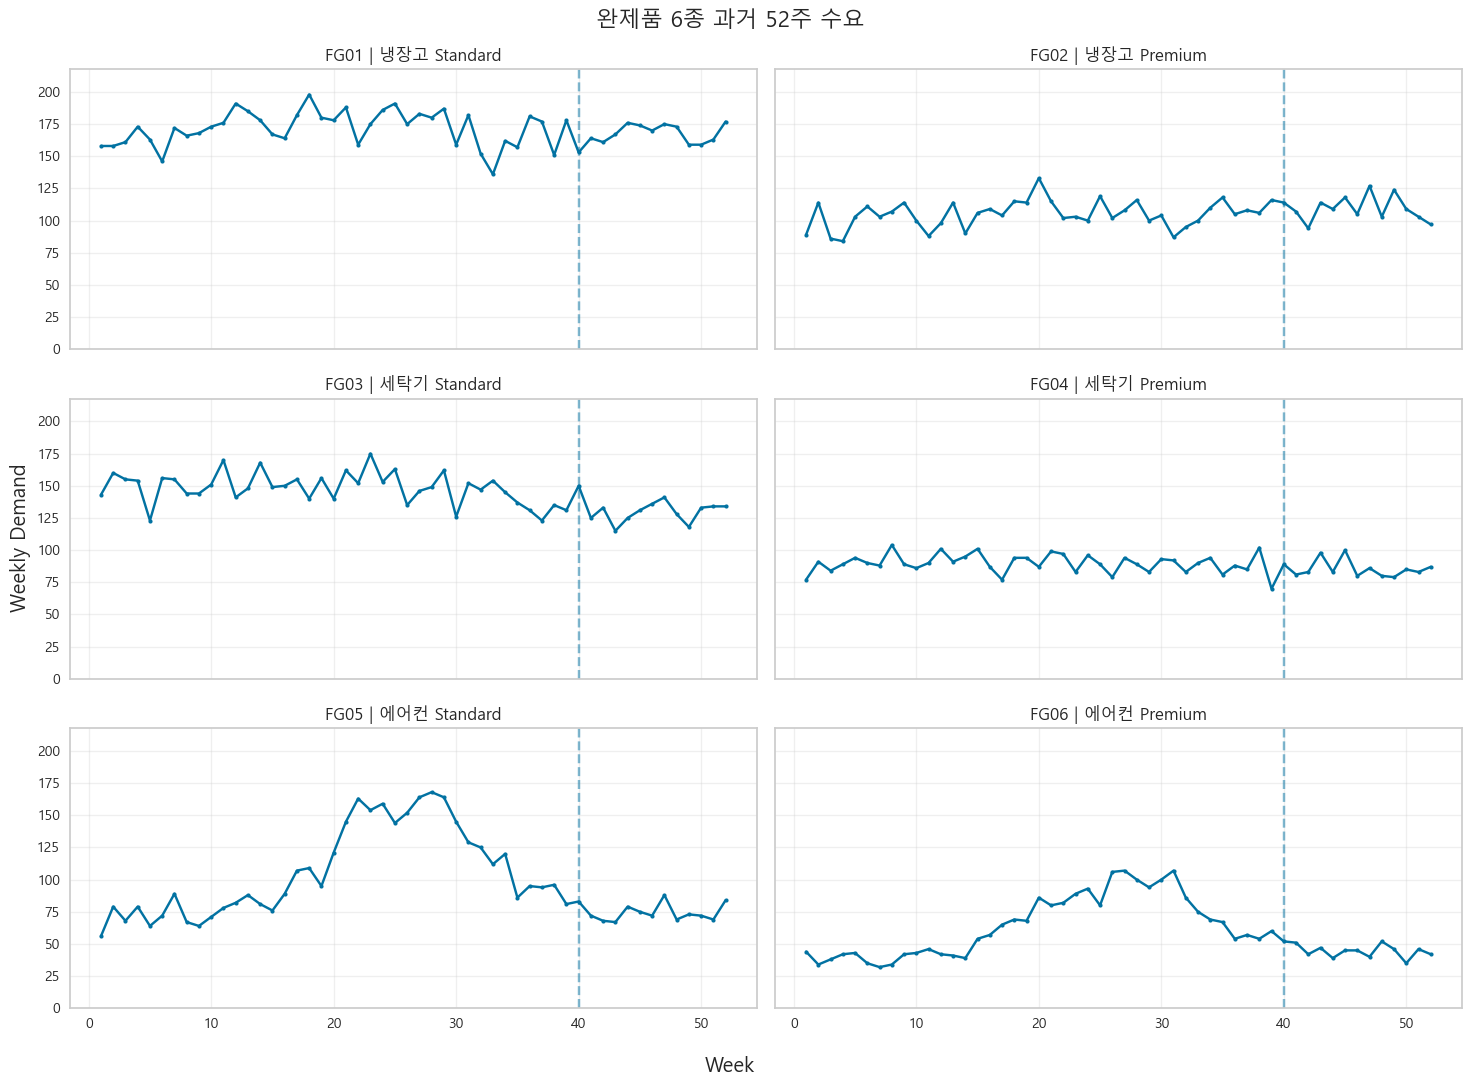


FG01 모델 검증
자동선택=RandomForest | 최종사용=RandomForest | MAPE=4.03% | Corr=-0.186 | 방향일치=36.4%

FG02 모델 검증
자동선택=LinearRegression | 최종사용=LinearRegression | MAPE=6.98% | Corr=-0.048 | 방향일치=54.5%

FG03 모델 검증
자동선택=LinearRegression | 최종사용=LinearRegression | MAPE=5.17% | Corr=0.395 | 방향일치=54.5%

FG04 모델 검증
자동선택=LinearRegression | 최종사용=LinearRegression | MAPE=8.94% | Corr=-0.299 | 방향일치=54.5%

FG05 모델 검증
자동선택=RandomForest | 최종사용=RandomForest | MAPE=8.06% | Corr=-0.238 | 방향일치=72.7%

FG06 모델 검증
자동선택=RandomForest | 최종사용=RandomForest | MAPE=25.77% | Corr=0.119 | 방향일치=27.3%

Linear Regression vs Random Forest


,product_id,product_name,model,MAPE_pct,MAE,RMSE,Correlation,Direction_Accuracy
1,FG01,냉장고 Standard,RandomForest,4.025,6.897,8.208,-0.186,36.364
0,FG01,냉장고 Standard,LinearRegression,8.468,14.451,15.703,0.353,54.545
2,FG02,냉장고 Premium,LinearRegression,6.983,7.913,10.415,-0.048,54.545
3,FG02,냉장고 Premium,RandomForest,7.092,7.813,9.926,-0.305,36.364
4,FG03,세탁기 Standard,LinearRegression,5.173,6.417,8.281,0.395,54.545
5,FG03,세탁기 Standard,RandomForest,10.605,13.378,15.137,0.383,54.545
6,FG04,세탁기 Premium,LinearRegression,8.936,7.658,8.660,-0.299,54.545
7,FG04,세탁기 Premium,RandomForest,9.420,7.971,8.318,-0.160,45.455
9,FG05,에어컨 Standard,RandomForest,8.064,6.024,7.467,-0.238,72.727
8,FG05,에어컨 Standard,LinearRegression,44.480,33.564,38.624,-0.285,63.636



===== 제품별 MAPE =====


model,product_id,product_name,LinearRegression,RandomForest
0,FG01,냉장고 Standard,8.47,4.03
1,FG02,냉장고 Premium,6.98,7.09
2,FG03,세탁기 Standard,5.17,10.60
3,FG04,세탁기 Premium,8.94,9.42
4,FG05,에어컨 Standard,44.48,8.06
5,FG06,에어컨 Premium,48.76,25.77



★ 제품별 최종 선택 모델


,product_id,product_name,selected_model,MAPE_pct,MAE,RMSE,Correlation,Direction_Accuracy,sigma_error
0,FG01,냉장고 Standard,RandomForest,4.025,6.897,8.208,-0.186,36.364,7.281
1,FG02,냉장고 Premium,LinearRegression,6.983,7.913,10.415,-0.048,54.545,10.129
2,FG03,세탁기 Standard,LinearRegression,5.173,6.417,8.281,0.395,54.545,7.023
3,FG04,세탁기 Premium,LinearRegression,8.936,7.658,8.660,-0.299,54.545,8.247
4,FG05,에어컨 Standard,RandomForest,8.064,6.024,7.467,-0.238,72.727,7.655
5,FG06,에어컨 Premium,RandomForest,25.773,10.743,11.706,0.119,27.273,4.855


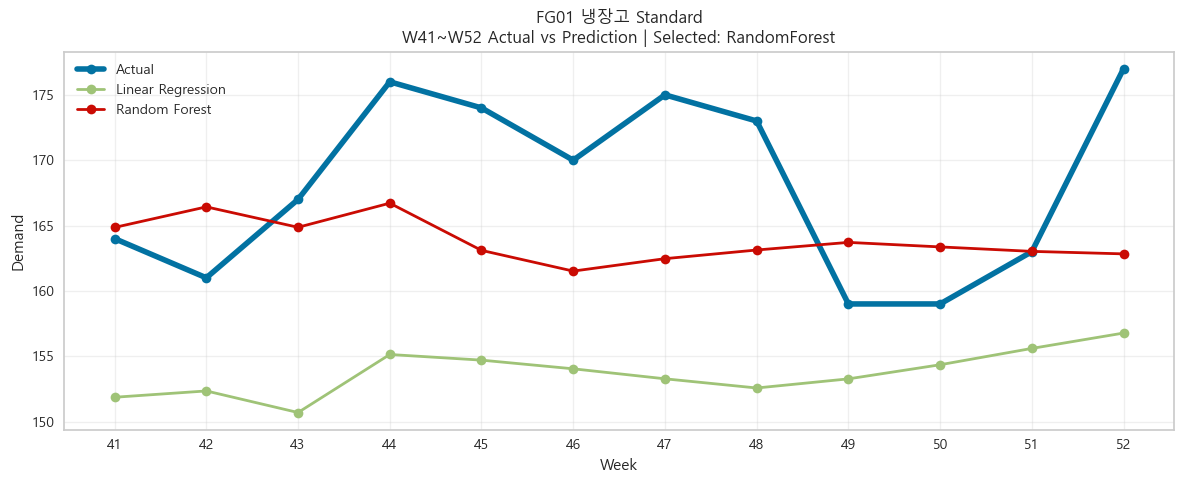

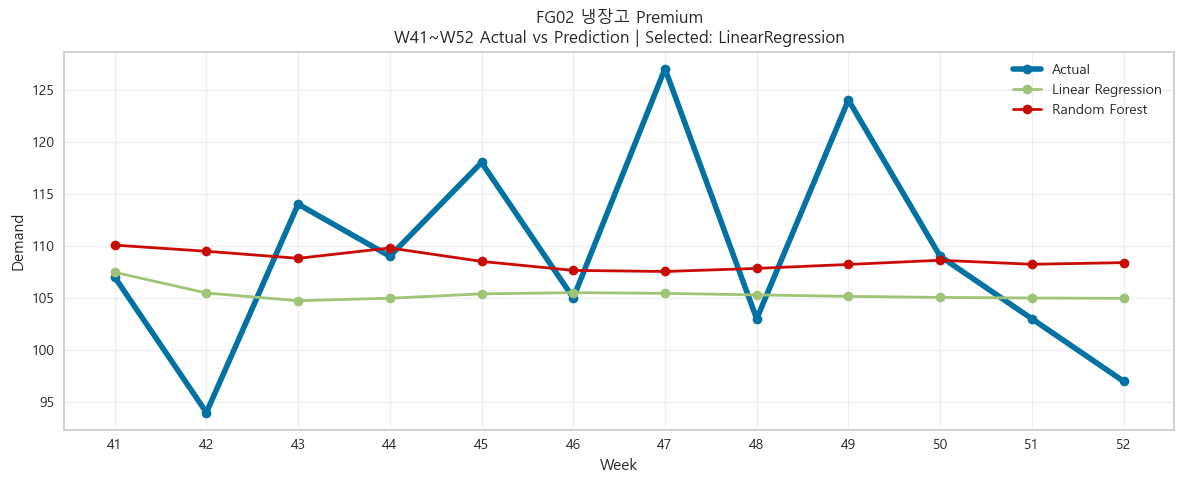

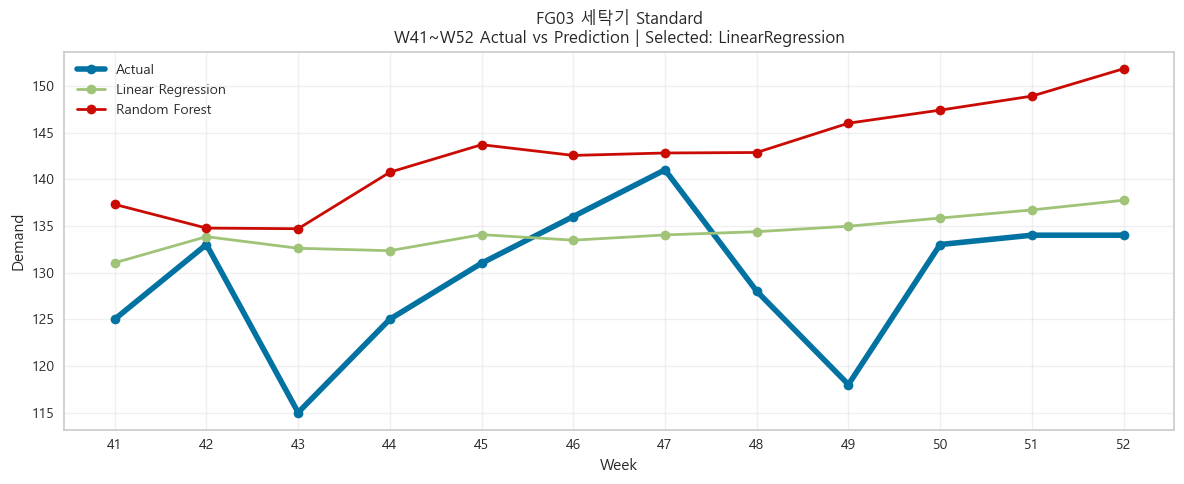

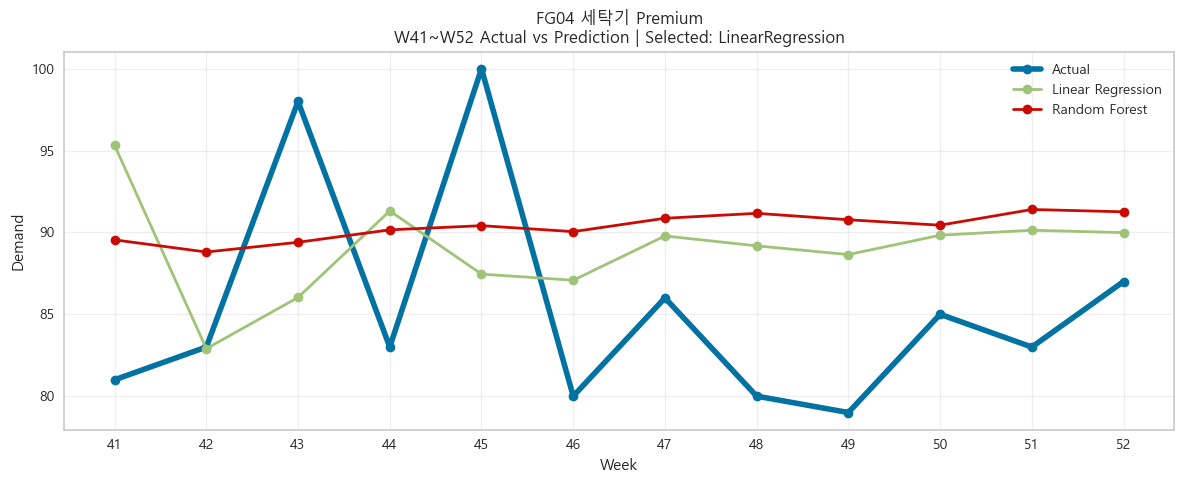

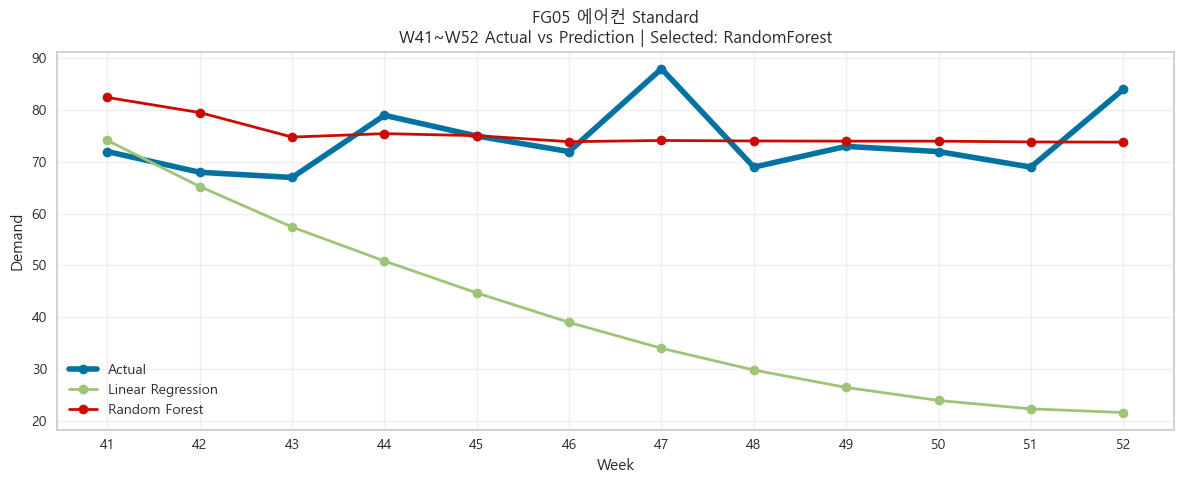

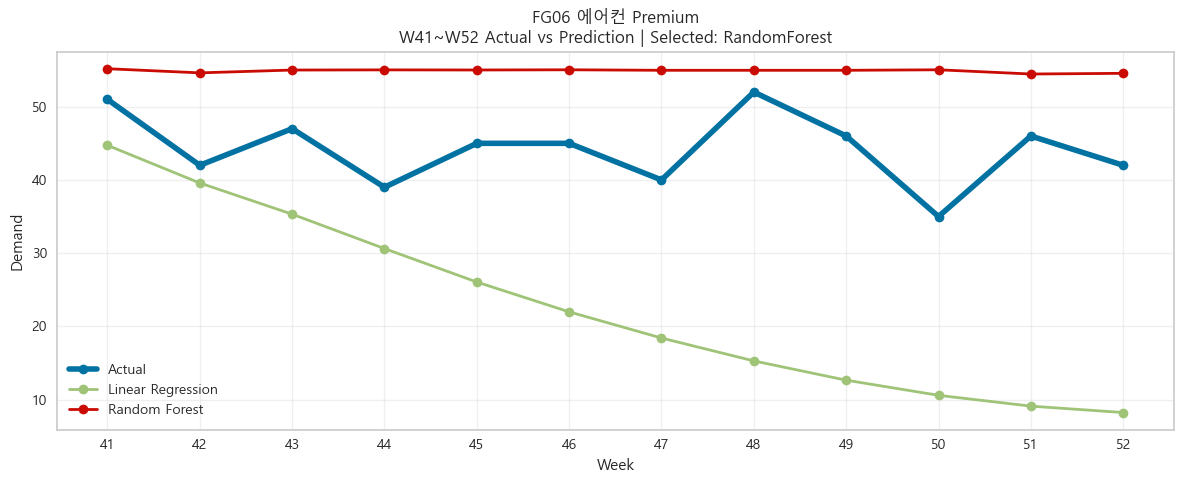


W53 ~ W65 미래 13주 예측


product_id,week,FG01,FG02,FG03,FG04,FG05,FG06
0,53,169.0,105.2,137.8,89.5,71.7,42.4
1,54,162.9,106.4,136.8,88.4,75.5,40.9
2,55,164.0,107.9,138.9,88.9,70.5,41.3
3,56,165.4,107.9,140.3,89.3,72.0,41.8
4,57,165.6,107.4,141.8,89.7,75.5,40.8
5,58,165.6,107.1,143.6,90.1,72.5,39.4
6,59,168.6,106.8,145.1,90.5,76.4,41.4
7,60,170.1,106.7,146.6,90.8,72.1,40.2
8,61,170.3,106.5,148.1,91.1,74.0,43.2
9,62,170.2,106.4,149.5,91.4,73.2,43.1


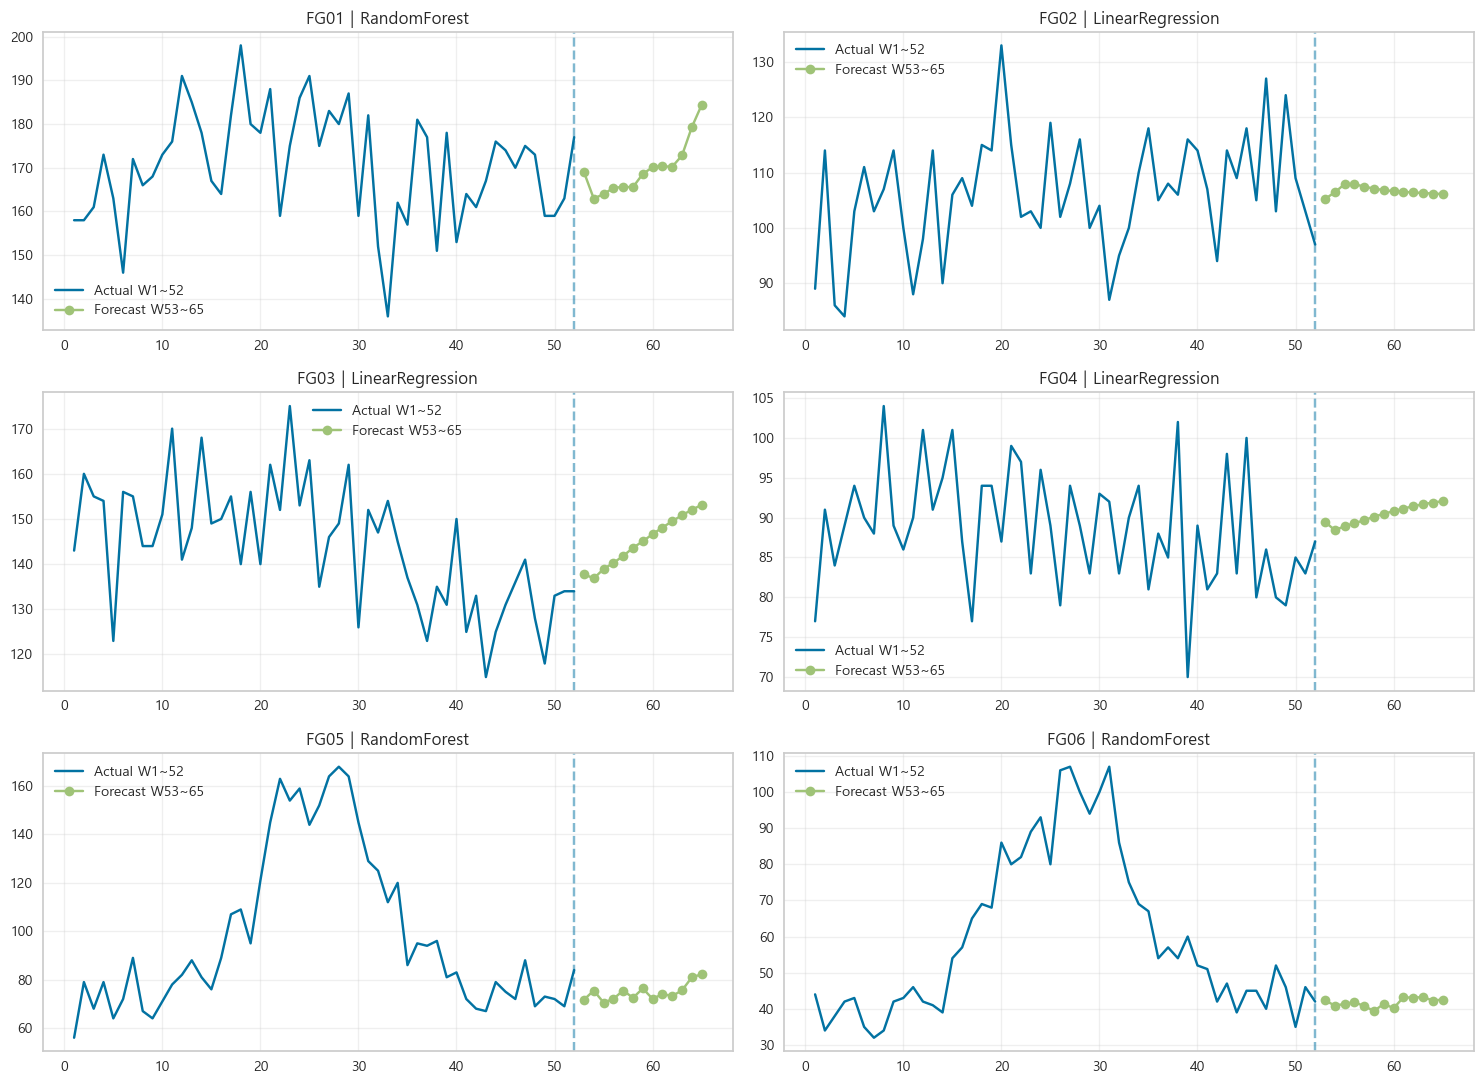


완제품 6종 (s,S)


,ID,name,model,MAPE_pct,Correlation,Direction_Accuracy,mu_13w,sigma_error,safety_stock,s,Q_raw,Q,S
0,FG01,냉장고 Standard,RandomForest,4.03,-0.19,36.36,169.87,7.28,12.01,182,300.99,310,492
1,FG02,냉장고 Premium,LinearRegression,6.98,-0.05,54.55,106.70,10.13,16.71,124,230.98,240,364
2,FG03,세탁기 Standard,LinearRegression,5.17,0.39,54.55,144.96,7.02,11.59,157,269.22,270,427
3,FG04,세탁기 Premium,LinearRegression,8.94,-0.30,54.55,90.42,8.25,13.61,105,207.24,210,315
4,FG05,에어컨 Standard,RandomForest,8.06,-0.24,72.73,74.79,7.66,12.63,88,190.59,200,288
5,FG06,에어컨 Premium,RandomForest,25.77,0.12,27.27,41.73,4.86,8.01,50,142.84,150,200



원자재 9종 (s,S)


,ID,name,mu_13w,sigma_error,safety_stock,s,Q_raw,Q,S,생산Lot_필요량,s_Lot차이,Lot체크
0,RM01,도장 강판 세트,628.47,18.84,31.09,660,804.01,850,1510,1380,-720,CHECK
1,RM02,Main PCB,628.47,18.84,31.09,660,709.07,720,1380,1380,-720,CHECK
2,RM03,BLDC Motor,235.38,10.83,17.87,254,383.55,400,654,480,-226,CHECK
3,RM04,Compressor,393.09,15.42,25.44,419,396.53,400,819,900,-481,CHECK
4,RM05,Heat Exchanger,116.52,9.07,14.96,132,252.55,260,392,350,-218,CHECK
5,RM06,Drum Assembly,235.38,10.83,17.87,254,401.75,420,674,480,-226,CHECK
6,RM07,Display Module,238.85,13.94,22.99,262,535.37,540,802,600,-338,CHECK
7,RM08,Wiring Harness,628.47,18.84,31.09,660,1085.53,1100,1760,1380,-720,CHECK
8,RM09,Fan Motor,158.25,12.37,20.40,179,355.81,360,539,500,-321,CHECK



생산 Lot 기준 확인 필요 원자재


,ID,name,s,생산Lot_필요량,s_Lot차이
0,RM01,도장 강판 세트,660,1380,-720
1,RM02,Main PCB,660,1380,-720
2,RM03,BLDC Motor,254,480,-226
3,RM04,Compressor,419,900,-481
4,RM05,Heat Exchanger,132,350,-218
5,RM06,Drum Assembly,254,480,-226
6,RM07,Display Module,262,600,-338
7,RM08,Wiring Harness,660,1380,-720
8,RM09,Fan Motor,179,500,-321



★ 1차 제출용 최종 15개 (s,S)


,ID,s,S
0,FG01,182,492
1,FG02,124,364
2,FG03,157,427
3,FG04,105,315
4,FG05,88,288
5,FG06,50,200
6,RM01,660,1510
7,RM02,660,1380
8,RM03,254,654
9,RM04,419,819



전체 실습 완료
저장 파일
1. 1차_제출용.xlsx
2. 전체_실습_분석결과.xlsx


In [20]:
# ============================================================
# LG전자 Operation 미니케이스 - 전체 실습
#
# 모델:
#   1. Linear Regression
#   2. Random Forest
#
# 흐름:
# 1. CSV 5개 로드
# 2. 수요 특성 분석
# 3. W1~40 학습
# 4. W41~52 검증
# 5. Linear vs RandomForest 비교
# 6. 실제 vs 예측 그래프
# 7. 제품별 Best Model 선택
# 8. W53~W65 미래 13주 예측
# 9. 완제품 6종 (s,S)
# 10. BOM 전개
# 11. 원자재 9종 (s,S)
# 12. 제출용 15행 Excel 저장
# ============================================================


# ============================================================
# 0. 라이브러리
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import warnings

from pathlib import Path
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 300)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 1. 기본 설정
# ============================================================

RANDOM_STATE = 42

# 서비스 수준 95%
Z = 1.65

# Train / Validation
TRAIN_END_WEEK = 40
VALID_START_WEEK = 41
VALID_END_WEEK = 52

# 미래 예측
FORECAST_START_WEEK = 53
FORECAST_END_WEEK = 65


# ------------------------------------------------------------
# 그래프를 보고 직접 모델을 바꾸고 싶을 때 사용
#
# 예:
# MANUAL_MODEL = {
#     "FG01": "RandomForest",
#     "FG02": "LinearRegression"
# }
#
# 비워두면 MAPE가 낮은 모델 자동 선택
# ------------------------------------------------------------

MANUAL_MODEL = {}


# ============================================================
# 2. CSV 파일 자동 찾기
#
# historical_demand.csv
# historical_demand(3).csv
#
# 둘 다 인식
# ============================================================

def find_csv(stem):

    exact = Path(f"{stem}.csv")

    if exact.exists():
        return exact

    files = sorted(
        Path(".").glob(f"{stem}*.csv")
    )

    if len(files) == 0:
        raise FileNotFoundError(
            f"{stem}.csv 파일을 찾을 수 없습니다."
        )

    return files[-1]


hist_file = find_csv("historical_demand")
production_file = find_csv("production_master")
warehouse_file = find_csv("warehouse_master")
raw_file = find_csv("raw_material_master")
bom_file = find_csv("bom")


print("=" * 90)
print("사용 파일")
print("=" * 90)

print("수요       :", hist_file)
print("생산       :", production_file)
print("창고       :", warehouse_file)
print("원자재     :", raw_file)
print("BOM        :", bom_file)


# ============================================================
# 3. 데이터 로드
# ============================================================

hist = pd.read_csv(hist_file)
production = pd.read_csv(production_file)
warehouse = pd.read_csv(warehouse_file)
raw = pd.read_csv(raw_file)
bom = pd.read_csv(bom_file)


print("\n" + "=" * 90)
print("데이터 크기")
print("=" * 90)

print("historical_demand :", hist.shape)
print("production_master :", production.shape)
print("warehouse_master  :", warehouse.shape)
print("raw_material      :", raw.shape)
print("bom               :", bom.shape)


# ============================================================
# 4. 데이터 검증
# ============================================================

print("\n===== 제품별 주차 수 =====")

display(
    hist.groupby(
        ["product_id", "product_name"]
    )["week"]
    .nunique()
    .reset_index(name="주차수")
)


assert (
    hist.groupby("product_id")["week"]
    .nunique()
    .eq(52)
    .all()
), "52주가 모두 존재하지 않는 제품이 있습니다."


assert (
    hist["weekly_demand_units"] >= 0
).all(), "음수 수요가 존재합니다."


assert (
    set(hist["product_id"])
    ==
    set(production["product_id"])
), "production_master의 product_id 불일치"


assert (
    set(hist["product_id"])
    ==
    set(warehouse["product_id"])
), "warehouse_master의 product_id 불일치"


assert set(
    bom["product_id"]
).issubset(
    set(hist["product_id"])
), "BOM product_id 오류"


assert set(
    bom["material_id"]
).issubset(
    set(raw["material_id"])
), "BOM material_id 오류"


# ============================================================
# 5. 수요 특성 분석
# ============================================================

demand_summary = (

    hist

    .groupby(
        ["product_id", "product_name"],
        as_index=False
    )

    .agg(

        평균수요=(
            "weekly_demand_units",
            "mean"
        ),

        표준편차=(
            "weekly_demand_units",
            "std"
        ),

        최소수요=(
            "weekly_demand_units",
            "min"
        ),

        최대수요=(
            "weekly_demand_units",
            "max"
        )
    )
)


demand_summary["CV"] = (

    demand_summary["표준편차"]

    /

    demand_summary["평균수요"]
)


print("\n" + "=" * 90)
print("완제품 수요 특성")
print("=" * 90)

display(
    demand_summary.round(3)
)


# ============================================================
# 6. 현재 안전재고 진단
#
# 초기 진단:
# 필요 안전재고 = z × 수요 표준편차
# ============================================================

safety_diag = demand_summary.merge(

    warehouse[
        [
            "product_id",
            "current_finished_goods_inventory_units",
            "current_safety_stock_units",
            "weekly_holding_cost_krw_per_unit",
            "shortage_penalty_cost_krw_per_unit"
        ]
    ],

    on="product_id",
    how="left"
)


safety_diag["필요안전재고_95"] = (

    np.ceil(
        Z
        *
        safety_diag["표준편차"]
    )

    .astype(int)
)


safety_diag["안전재고차이"] = (

    safety_diag[
        "current_safety_stock_units"
    ]

    -

    safety_diag[
        "필요안전재고_95"
    ]
)


print("\n" + "=" * 90)
print("현재 안전재고 진단")
print("=" * 90)

display(
    safety_diag.round(2)
)


# ============================================================
# 7. 과거 52주 수요 그래프
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 11),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

ymax = (
    hist["weekly_demand_units"].max()
    * 1.10
)


for ax, (pid, g) in zip(
    axes,
    hist.groupby("product_id")
):

    g = g.sort_values("week")

    ax.plot(
        g["week"],
        g["weekly_demand_units"],
        marker="o",
        markersize=3
    )

    ax.axvline(
        40,
        linestyle="--",
        alpha=0.5
    )

    ax.set_title(
        f"{pid} | {g['product_name'].iloc[0]}"
    )

    ax.set_ylim(
        0,
        ymax
    )

    ax.grid(
        alpha=0.3
    )


fig.supxlabel("Week")
fig.supylabel("Weekly Demand")

fig.suptitle(
    "완제품 6종 과거 52주 수요",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ============================================================
# 8. 모델 입력 Feature
#
# lag1 : 1주 전 수요
# lag2 : 2주 전 수요
# ma4  : 최근 4주 평균
#
# sin52 / cos52:
# 주차 위치 정보
# ============================================================

FEATURES = [

    "lag1",
    "lag2",
    "ma4",

    "sin52",
    "cos52"
]


def make_feature(
    week,
    history
):


    week_of_year = (

        (week - 1) % 52

    ) + 1


    return {

        "lag1":
            history[-1],

        "lag2":
            history[-2],

        "ma4":
            float(
                np.mean(
                    history[-4:]
                )
            ),

        "sin52":
            np.sin(
                2
                *
                np.pi
                *
                week_of_year
                /
                52
            ),

        "cos52":
            np.cos(
                2
                *
                np.pi
                *
                week_of_year
                /
                52
            )
    }


# ============================================================
# 9. 지도학습 데이터 생성
# ============================================================

def make_supervised(
    g,
    end_week
):


    g = g.sort_values(
        "week"
    )


    demand_dict = dict(

        zip(

            g["week"],

            g[
                "weekly_demand_units"
            ]
        )
    )


    rows = []


    # ma4 때문에 W5부터
    for week in range(
        5,
        end_week + 1
    ):


        history = [

            demand_dict[w]

            for w in range(
                1,
                week
            )
        ]


        row = make_feature(
            week,
            history
        )


        row["week"] = week

        row["target"] = (
            demand_dict[
                week
            ]
        )


        rows.append(
            row
        )


    return pd.DataFrame(
        rows
    )


# ============================================================
# 10. Recursive Forecast
#
# 실제 미래 예측처럼
# 전주 예측값을 다음 주 lag에 사용
# ============================================================

def recursive_forecast(
    model,
    history,
    start_week,
    end_week
):


    history = [
        float(x)
        for x in history
    ]


    predictions = []


    for week in range(
        start_week,
        end_week + 1
    ):


        f = make_feature(
            week,
            history
        )


        X = pd.DataFrame(

            [[
                f[c]
                for c in FEATURES
            ]],

            columns=FEATURES
        )


        pred = float(
            model.predict(
                X
            )[0]
        )


        # 수요는 음수가 될 수 없음
        pred = max(
            0.0,
            pred
        )


        predictions.append(
            pred
        )


        history.append(
            pred
        )


    return np.array(
        predictions
    )


# ============================================================
# 11. 평가 함수
# ============================================================

def calculate_metrics(
    actual,
    pred
):


    actual = np.asarray(
        actual,
        dtype=float
    )


    pred = np.asarray(
        pred,
        dtype=float
    )


    # --------------------------------------------------------
    # MAPE
    # --------------------------------------------------------

    mape = (

        np.mean(

            np.abs(

                (
                    actual
                    -
                    pred
                )

                /

                actual
            )
        )

        * 100
    )


    # --------------------------------------------------------
    # MAE
    # --------------------------------------------------------

    mae = np.mean(

        np.abs(
            actual
            -
            pred
        )
    )


    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------

    rmse = np.sqrt(

        np.mean(

            (
                actual
                -
                pred
            ) ** 2
        )
    )


    # --------------------------------------------------------
    # Correlation
    #
    # 그래프의 전체적인 움직임 참고
    # --------------------------------------------------------

    if (
        np.std(actual) > 0
        and
        np.std(pred) > 0
    ):


        corr = np.corrcoef(

            actual,

            pred

        )[0, 1]


    else:

        corr = 0.0


    # --------------------------------------------------------
    # Direction Accuracy
    #
    # 전주 대비 상승/하락 방향 일치율
    # --------------------------------------------------------

    direction = (

        np.mean(

            np.sign(
                np.diff(actual)
            )

            ==

            np.sign(
                np.diff(pred)
            )
        )

        * 100
    )


    return {

        "MAPE_pct":
            mape,

        "MAE":
            mae,

        "RMSE":
            rmse,

        "Correlation":
            corr,

        "Direction_Accuracy":
            direction
    }


# ============================================================
# 12. 비교 모델
# ============================================================

models = {


    "LinearRegression":

        LinearRegression(),


    "RandomForest":

        RandomForestRegressor(

            n_estimators=500,

            min_samples_leaf=2,

            max_features=0.8,

            random_state=
                RANDOM_STATE,

            n_jobs=-1
        )
}


# ============================================================
# 13. 모델 학습 / Validation
# ============================================================

model_rows = []

validation_rows = []

selected_model_info = {}

future_rows = []


for product_id, g in hist.groupby(
    "product_id"
):


    print("\n" + "=" * 90)
    print(f"{product_id} 모델 검증")
    print("=" * 90)


    g = (

        g.sort_values(
            "week"
        )

        .reset_index(
            drop=True
        )
    )


    product_name = (

        g[
            "product_name"
        ]

        .iloc[0]
    )


    # --------------------------------------------------------
    # W1~40 학습
    # --------------------------------------------------------

    train = make_supervised(
        g,
        TRAIN_END_WEEK
    )


    X_train = (
        train[
            FEATURES
        ]
    )


    y_train = (
        train[
            "target"
        ]
    )


    # --------------------------------------------------------
    # W41~52 실제값
    # --------------------------------------------------------

    actual_valid = (

        g.loc[

            g["week"].between(
                VALID_START_WEEK,
                VALID_END_WEEK
            ),

            "weekly_demand_units"
        ]

        .to_numpy(
            dtype=float
        )
    )


    history40 = (

        g.loc[

            g["week"]
            <=
            TRAIN_END_WEEK,

            "weekly_demand_units"
        ]

        .tolist()
    )


    product_predictions = {}


    # ========================================================
    # Linear / RF 실행
    # ========================================================

    for (
        model_name,
        model
    ) in models.items():


        fitted_model = clone(
            model
        )


        fitted_model.fit(
            X_train,
            y_train
        )


        pred = recursive_forecast(

            fitted_model,

            history40,

            VALID_START_WEEK,

            VALID_END_WEEK
        )


        product_predictions[
            model_name
        ] = pred


        metric = calculate_metrics(
            actual_valid,
            pred
        )


        model_rows.append({

            "product_id":
                product_id,

            "product_name":
                product_name,

            "model":
                model_name,

            **metric
        })


        for (
            week,
            actual,
            prediction
        ) in zip(

            range(
                VALID_START_WEEK,
                VALID_END_WEEK + 1
            ),

            actual_valid,

            pred
        ):


            validation_rows.append({

                "product_id":
                    product_id,

                "product_name":
                    product_name,

                "model":
                    model_name,

                "week":
                    week,

                "actual":
                    actual,

                "prediction":
                    prediction,

                "error":
                    actual
                    -
                    prediction
            })


    # ========================================================
    # 제품별 모델 선택
    #
    # 기본:
    # MAPE가 작은 모델 선택
    #
    # MANUAL_MODEL에 입력했다면
    # 사용자 선택 우선
    # ========================================================

    product_compare = pd.DataFrame(

        [
            r

            for r in model_rows

            if r[
                "product_id"
            ]
            ==
            product_id
        ]
    )


    auto_best = (

        product_compare

        .sort_values(
            "MAPE_pct"
        )

        .iloc[0][
            "model"
        ]
    )


    best_name = MANUAL_MODEL.get(

        product_id,

        auto_best
    )


    best_metric = (

        product_compare[

            product_compare[
                "model"
            ]
            ==
            best_name
        ]

        .iloc[0]
    )


    best_pred = (

        product_predictions[
            best_name
        ]
    )


    residual = (

        actual_valid

        -

        best_pred
    )


    sigma_error = float(

        np.std(
            residual,
            ddof=1
        )
    )


    print(

        f"자동선택={auto_best}"

        f" | 최종사용={best_name}"

        f" | MAPE={best_metric['MAPE_pct']:.2f}%"

        f" | Corr={best_metric['Correlation']:.3f}"

        f" | 방향일치={best_metric['Direction_Accuracy']:.1f}%"
    )


    # ========================================================
    # W1~52 전체 재학습
    # ========================================================

    full_train = make_supervised(
        g,
        VALID_END_WEEK
    )


    final_model = clone(

        models[
            best_name
        ]
    )


    final_model.fit(

        full_train[
            FEATURES
        ],

        full_train[
            "target"
        ]
    )


    # ========================================================
    # W53~65 미래 예측
    # ========================================================

    future_pred = recursive_forecast(

        final_model,

        g[
            "weekly_demand_units"
        ].tolist(),

        FORECAST_START_WEEK,

        FORECAST_END_WEEK
    )


    selected_model_info[
        product_id
    ] = {


        "product_name":
            product_name,

        "model":
            best_name,

        "MAPE_pct":
            float(
                best_metric[
                    "MAPE_pct"
                ]
            ),

        "MAE":
            float(
                best_metric[
                    "MAE"
                ]
            ),

        "RMSE":
            float(
                best_metric[
                    "RMSE"
                ]
            ),

        "Correlation":
            float(
                best_metric[
                    "Correlation"
                ]
            ),

        "Direction_Accuracy":
            float(
                best_metric[
                    "Direction_Accuracy"
                ]
            ),

        "sigma_error":
            sigma_error,

        "future":
            future_pred
    }


    for (
        week,
        pred
    ) in zip(

        range(
            FORECAST_START_WEEK,
            FORECAST_END_WEEK + 1
        ),

        future_pred
    ):


        future_rows.append({

            "week":
                week,

            "product_id":
                product_id,

            "product_name":
                product_name,

            "model":
                best_name,

            "forecast":
                pred
        })


# ============================================================
# 14. 결과 DataFrame
# ============================================================

model_df = pd.DataFrame(
    model_rows
)


validation_df = pd.DataFrame(
    validation_rows
)


future_df = pd.DataFrame(
    future_rows
)


# ============================================================
# 15. Linear vs RandomForest 성능표
# ============================================================

print("\n" + "=" * 90)
print("Linear Regression vs Random Forest")
print("=" * 90)


display(

    model_df

    .sort_values(
        [
            "product_id",
            "MAPE_pct"
        ]
    )

    .round(3)
)


# ------------------------------------------------------------
# MAPE만 한눈에 보기
# ------------------------------------------------------------

mape_table = (

    model_df

    .pivot(

        index=[
            "product_id",
            "product_name"
        ],

        columns="model",

        values="MAPE_pct"
    )

    .reset_index()
)


print("\n===== 제품별 MAPE =====")

display(
    mape_table.round(2)
)


# ============================================================
# 16. 제품별 선택모델
# ============================================================

selected_rows = []


for (
    pid,
    info
) in selected_model_info.items():


    selected_rows.append({

        "product_id":
            pid,

        "product_name":
            info[
                "product_name"
            ],

        "selected_model":
            info[
                "model"
            ],

        "MAPE_pct":
            info[
                "MAPE_pct"
            ],

        "MAE":
            info[
                "MAE"
            ],

        "RMSE":
            info[
                "RMSE"
            ],

        "Correlation":
            info[
                "Correlation"
            ],

        "Direction_Accuracy":
            info[
                "Direction_Accuracy"
            ],

        "sigma_error":
            info[
                "sigma_error"
            ]
    })


selected_model_df = (

    pd.DataFrame(
        selected_rows
    )

    .sort_values(
        "product_id"
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("★ 제품별 최종 선택 모델")
print("=" * 90)


display(
    selected_model_df.round(3)
)


# ============================================================
# 17. 핵심 그래프
#
# W41~52
# 실제 vs Linear vs RandomForest
# ============================================================

for product_id in sorted(

    hist[
        "product_id"
    ].unique()
):


    plt.figure(
        figsize=(12, 5)
    )


    actual_temp = (

        validation_df[

            validation_df[
                "product_id"
            ]
            ==
            product_id
        ]

        [
            [
                "week",
                "actual"
            ]
        ]

        .drop_duplicates()

        .sort_values(
            "week"
        )
    )


    # 실제
    plt.plot(

        actual_temp[
            "week"
        ],

        actual_temp[
            "actual"
        ],

        marker="o",

        linewidth=4,

        label="Actual"
    )


    # Linear
    linear_temp = (

        validation_df[

            (
                validation_df[
                    "product_id"
                ]
                ==
                product_id
            )

            &

            (
                validation_df[
                    "model"
                ]
                ==
                "LinearRegression"
            )
        ]

        .sort_values(
            "week"
        )
    )


    plt.plot(

        linear_temp[
            "week"
        ],

        linear_temp[
            "prediction"
        ],

        marker="o",

        linewidth=2,

        label="Linear Regression"
    )


    # RF
    rf_temp = (

        validation_df[

            (
                validation_df[
                    "product_id"
                ]
                ==
                product_id
            )

            &

            (
                validation_df[
                    "model"
                ]
                ==
                "RandomForest"
            )
        ]

        .sort_values(
            "week"
        )
    )


    plt.plot(

        rf_temp[
            "week"
        ],

        rf_temp[
            "prediction"
        ],

        marker="o",

        linewidth=2,

        label="Random Forest"
    )


    product_name = (

        hist[

            hist[
                "product_id"
            ]
            ==
            product_id
        ]

        [
            "product_name"
        ]

        .iloc[0]
    )


    selected = (

        selected_model_info[
            product_id
        ]["model"]
    )


    plt.title(

        f"{product_id} {product_name}\n"
        f"W41~W52 Actual vs Prediction | Selected: {selected}"
    )


    plt.xlabel(
        "Week"
    )


    plt.ylabel(
        "Demand"
    )


    plt.xticks(
        range(
            41,
            53
        )
    )


    plt.grid(
        alpha=0.3
    )


    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# 18. W53~W65 미래예측
# ============================================================

future_wide = (

    future_df

    .pivot(

        index="week",

        columns="product_id",

        values="forecast"
    )

    .reset_index()
)


print("\n" + "=" * 90)
print("W53 ~ W65 미래 13주 예측")
print("=" * 90)


display(
    future_wide.round(1)
)


# ============================================================
# 19. 과거 52주 + 미래 13주 그래프
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 11)
)

axes = axes.flatten()


for ax, product_id in zip(

    axes,

    sorted(
        hist[
            "product_id"
        ].unique()
    )
):


    actual = (

        hist[

            hist[
                "product_id"
            ]
            ==
            product_id
        ]

        .sort_values(
            "week"
        )
    )


    future = (

        future_df[

            future_df[
                "product_id"
            ]
            ==
            product_id
        ]

        .sort_values(
            "week"
        )
    )


    model_name = (

        selected_model_info[
            product_id
        ]["model"]
    )


    ax.plot(

        actual[
            "week"
        ],

        actual[
            "weekly_demand_units"
        ],

        label="Actual W1~52"
    )


    ax.plot(

        future[
            "week"
        ],

        future[
            "forecast"
        ],

        marker="o",

        label="Forecast W53~65"
    )


    ax.axvline(
        52,
        linestyle="--",
        alpha=0.5
    )


    ax.set_title(

        f"{product_id} | "
        f"{model_name}"
    )


    ax.grid(
        alpha=0.3
    )


    ax.legend()


plt.tight_layout()
plt.show()


# ============================================================
# 20. 완제품 6종 (s,S)
#
# s = ceil(mu + z × sigma_error)
#
# Q = sqrt(2Kmu / h)
#
# 생산단위 배수로 올림
#
# S = s + Q
# ============================================================

finished_rows = []


for product_id in sorted(

    selected_model_info.keys()
):


    info = (

        selected_model_info[
            product_id
        ]
    )


    # --------------------------------------------------------
    # 미래 13주 평균수요
    # --------------------------------------------------------

    mu = float(

        np.mean(
            info[
                "future"
            ]
        )
    )


    # Validation 예측오차 sigma
    sigma_error = (

        info[
            "sigma_error"
        ]
    )


    prod_row = (

        production[

            production[
                "product_id"
            ]
            ==
            product_id
        ]

        .iloc[0]
    )


    wh_row = (

        warehouse[

            warehouse[
                "product_id"
            ]
            ==
            product_id
        ]

        .iloc[0]
    )


    # --------------------------------------------------------
    # s
    # --------------------------------------------------------

    safety_stock = (

        Z
        *
        sigma_error
    )


    s = int(

        math.ceil(

            mu

            +

            safety_stock
        )
    )


    # --------------------------------------------------------
    # EOQ
    # --------------------------------------------------------

    K = float(

        prod_row[
            "fixed_setup_cost_krw_per_run"
        ]
    )


    h = float(

        wh_row[
            "weekly_holding_cost_krw_per_unit"
        ]
    )


    Q_raw = math.sqrt(

        2

        *

        K

        *

        mu

        /

        h
    )


    production_multiple = int(

        prod_row[
            "production_multiple_units"
        ]
    )


    Q = int(

        math.ceil(

            Q_raw

            /

            production_multiple
        )

        *

        production_multiple
    )


    S = (
        s
        +
        Q
    )


    finished_rows.append({

        "ID":
            product_id,

        "name":
            info[
                "product_name"
            ],

        "model":
            info[
                "model"
            ],

        "MAPE_pct":
            info[
                "MAPE_pct"
            ],

        "Correlation":
            info[
                "Correlation"
            ],

        "Direction_Accuracy":
            info[
                "Direction_Accuracy"
            ],

        "mu_13w":
            mu,

        "sigma_error":
            sigma_error,

        "safety_stock":
            safety_stock,

        "s":
            s,

        "Q_raw":
            Q_raw,

        "Q":
            Q,

        "S":
            S
    })


finished_policy = (

    pd.DataFrame(
        finished_rows
    )

    .sort_values(
        "ID"
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("완제품 6종 (s,S)")
print("=" * 90)


display(
    finished_policy.round(2)
)


# ============================================================
# 21. BOM 전개 준비
# ============================================================

raw_forecast = pd.DataFrame({

    "week":
        range(
            FORECAST_START_WEEK,
            FORECAST_END_WEEK + 1
        )
})


sigma_map = {

    pid:
        info[
            "sigma_error"
        ]

    for (
        pid,
        info
    )

    in selected_model_info.items()
}


finished_Q_map = dict(

    zip(

        finished_policy[
            "ID"
        ],

        finished_policy[
            "Q"
        ]
    )
)


raw_rows = []


# ============================================================
# 22. 원자재 9종 (s,S)
# ============================================================

for _, rm in (

    raw

    .sort_values(
        "material_id"
    )

    .iterrows()
):


    material_id = (
        rm[
            "material_id"
        ]
    )


    material_name = (
        rm[
            "material_name"
        ]
    )


    material_bom = (

        bom[

            bom[
                "material_id"
            ]
            ==
            material_id
        ]
    )


    # --------------------------------------------------------
    # W53~65 원자재 주별 예상소요
    # --------------------------------------------------------

    weekly_material_demand = (

        np.zeros(
            13
        )
    )


    for _, b in (

        material_bom.iterrows()
    ):


        pid = (
            b[
                "product_id"
            ]
        )


        qty = float(

            b[
                "qty_per_finished_product"
            ]
        )


        product_future = (

            future_df[

                future_df[
                    "product_id"
                ]
                ==
                pid
            ]

            .sort_values(
                "week"
            )

            [
                "forecast"
            ]

            .to_numpy()
        )


        weekly_material_demand += (

            product_future

            *

            qty
        )


    raw_forecast[
        material_id
    ] = (
        weekly_material_demand
    )


    # --------------------------------------------------------
    # 평균 원자재 소요
    # --------------------------------------------------------

    mu_rm = float(

        weekly_material_demand.mean()
    )


    # --------------------------------------------------------
    # 원자재 예측오차 sigma
    #
    # sqrt(
    # Σ(BOM × 제품 sigma)^2
    # )
    # --------------------------------------------------------

    sigma_rm = math.sqrt(

        sum(

            (

                float(

                    b[
                        "qty_per_finished_product"
                    ]
                )

                *

                sigma_map[

                    b[
                        "product_id"
                    ]
                ]

            ) ** 2


            for _, b

            in material_bom.iterrows()
        )
    )


    # --------------------------------------------------------
    # 원자재 s
    # --------------------------------------------------------

    safety_rm = (

        Z
        *
        sigma_rm
    )


    s_rm = int(

        math.ceil(

            mu_rm

            +

            safety_rm
        )
    )


    # --------------------------------------------------------
    # 원자재 EOQ
    # --------------------------------------------------------

    K_rm = float(

        rm[
            "fixed_order_cost_krw_per_order"
        ]
    )


    h_rm = float(

        rm[
            "weekly_holding_cost_krw_per_unit"
        ]
    )


    Q_rm_raw = math.sqrt(

        2

        *

        K_rm

        *

        mu_rm

        /

        h_rm
    )


    order_multiple = int(

        rm[
            "order_multiple_units"
        ]
    )


    Q_rm = int(

        math.ceil(

            Q_rm_raw

            /

            order_multiple
        )

        *

        order_multiple
    )


    S_rm = (

        s_rm

        +

        Q_rm
    )


    # --------------------------------------------------------
    # 생산 Lot 기준 진단
    # --------------------------------------------------------

    lot_need = int(

        math.ceil(

            sum(

                finished_Q_map[

                    b[
                        "product_id"
                    ]
                ]

                *

                float(

                    b[
                        "qty_per_finished_product"
                    ]
                )


                for _, b

                in material_bom.iterrows()
            )
        )
    )


    raw_rows.append({

        "ID":
            material_id,

        "name":
            material_name,

        "mu_13w":
            mu_rm,

        "sigma_error":
            sigma_rm,

        "safety_stock":
            safety_rm,

        "s":
            s_rm,

        "Q_raw":
            Q_rm_raw,

        "Q":
            Q_rm,

        "S":
            S_rm,

        "생산Lot_필요량":
            lot_need,

        "s_Lot차이":
            s_rm
            -
            lot_need,

        "Lot체크":

            "CHECK"

            if s_rm < lot_need

            else "OK"
    })


raw_policy = (

    pd.DataFrame(
        raw_rows
    )

    .sort_values(
        "ID"
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("원자재 9종 (s,S)")
print("=" * 90)


display(
    raw_policy.round(2)
)


# ============================================================
# 23. Lot 경고
# ============================================================

lot_warning = (

    raw_policy[

        raw_policy[
            "Lot체크"
        ]
        ==
        "CHECK"
    ]
)


print("\n" + "=" * 90)
print("생산 Lot 기준 확인 필요 원자재")
print("=" * 90)


if len(
    lot_warning
) == 0:

    print(
        "Lot 기준 경고 없음"
    )


else:

    display(

        lot_warning[
            [
                "ID",
                "name",
                "s",
                "생산Lot_필요량",
                "s_Lot차이"
            ]
        ]
    )


# ============================================================
# 24. 최종 15개 (s,S)
# ============================================================

submission = pd.concat(

    [

        finished_policy[
            [
                "ID",
                "s",
                "S"
            ]
        ],

        raw_policy[
            [
                "ID",
                "s",
                "S"
            ]
        ]
    ],

    ignore_index=True
)


submission = (

    submission

    .sort_values(
        "ID"
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 25. 제출 조건 검증
# ============================================================

assert (
    len(submission)
    ==
    15
), "15행이 아닙니다."


assert (
    submission[
        "ID"
    ]
    .nunique()
    ==
    15
), "ID 중복"


assert (
    submission[
        "s"
    ]
    <
    submission[
        "S"
    ]
).all(), "s < S 조건 위반"


print("\n" + "=" * 90)
print("★ 1차 제출용 최종 15개 (s,S)")
print("=" * 90)


display(
    submission
)


# ============================================================
# 26. Excel 저장
# ============================================================

submission.to_excel(

    "1차_제출용.xlsx",

    index=False
)


with pd.ExcelWriter(

    "전체_실습_분석결과.xlsx",

    engine="openpyxl"

) as writer:


    demand_summary.to_excel(
        writer,
        sheet_name="01_수요특성",
        index=False
    )


    safety_diag.to_excel(
        writer,
        sheet_name="02_안전재고진단",
        index=False
    )


    model_df.to_excel(
        writer,
        sheet_name="03_모델비교",
        index=False
    )


    selected_model_df.to_excel(
        writer,
        sheet_name="04_선택모델",
        index=False
    )


    validation_df.to_excel(
        writer,
        sheet_name="05_검증예측",
        index=False
    )


    future_df.to_excel(
        writer,
        sheet_name="06_13주예측",
        index=False
    )


    future_wide.to_excel(
        writer,
        sheet_name="07_13주Wide",
        index=False
    )


    finished_policy.to_excel(
        writer,
        sheet_name="08_완제품정책",
        index=False
    )


    raw_forecast.to_excel(
        writer,
        sheet_name="09_원자재예상소요",
        index=False
    )


    raw_policy.to_excel(
        writer,
        sheet_name="10_원자재정책",
        index=False
    )


    submission.to_excel(
        writer,
        sheet_name="11_최종제출값",
        index=False
    )


print("\n" + "=" * 90)
print("전체 실습 완료")
print("=" * 90)

print("저장 파일")
print("1. 1차_제출용.xlsx")
print("2. 전체_실습_분석결과.xlsx")

사용 파일
수요       : historical_demand.csv
생산       : production_master.csv
창고       : warehouse_master.csv
원자재     : raw_material_master.csv
BOM        : bom.csv

데이터 크기
historical_demand : (312, 5)
production_master : (6, 5)
warehouse_master  : (6, 6)
raw_material      : (9, 9)
bom               : (33, 5)

===== 제품별 주차 수 =====


,product_id,product_name,주차수
0,FG01,냉장고 Standard,52
1,FG02,냉장고 Premium,52
2,FG03,세탁기 Standard,52
3,FG04,세탁기 Premium,52
4,FG05,에어컨 Standard,52
5,FG06,에어컨 Premium,52



완제품 수요 특성


,product_id,product_name,평균수요,표준편차,최소수요,최대수요,CV
0,FG01,냉장고 Standard,170.519,12.594,136,198,0.074
1,FG02,냉장고 Premium,106.154,10.412,84,133,0.098
2,FG03,세탁기 Standard,143.904,13.801,115,175,0.096
3,FG04,세탁기 Premium,88.654,7.319,70,104,0.083
4,FG05,에어컨 Standard,98.115,32.863,56,168,0.335
5,FG06,에어컨 Premium,59.538,22.351,32,107,0.375



현재 안전재고 진단


,product_id,product_name,평균수요,표준편차,최소수요,최대수요,CV,current_finished_goods_inventory_units,current_safety_stock_units,weekly_holding_cost_krw_per_unit,shortage_penalty_cost_krw_per_unit,필요안전재고_95,안전재고차이
0,FG01,냉장고 Standard,170.52,12.59,136,198,0.07,190,55,3000,700000,21,34
1,FG02,냉장고 Premium,106.15,10.41,84,133,0.10,95,35,4000,850000,18,17
2,FG03,세탁기 Standard,143.90,13.80,115,175,0.10,175,50,3000,650000,23,27
3,FG04,세탁기 Premium,88.65,7.32,70,104,0.08,90,30,4000,800000,13,17
4,FG05,에어컨 Standard,98.12,32.86,56,168,0.33,115,45,3500,1000000,55,-10
5,FG06,에어컨 Premium,59.54,22.35,32,107,0.38,65,25,4500,1250000,37,-12


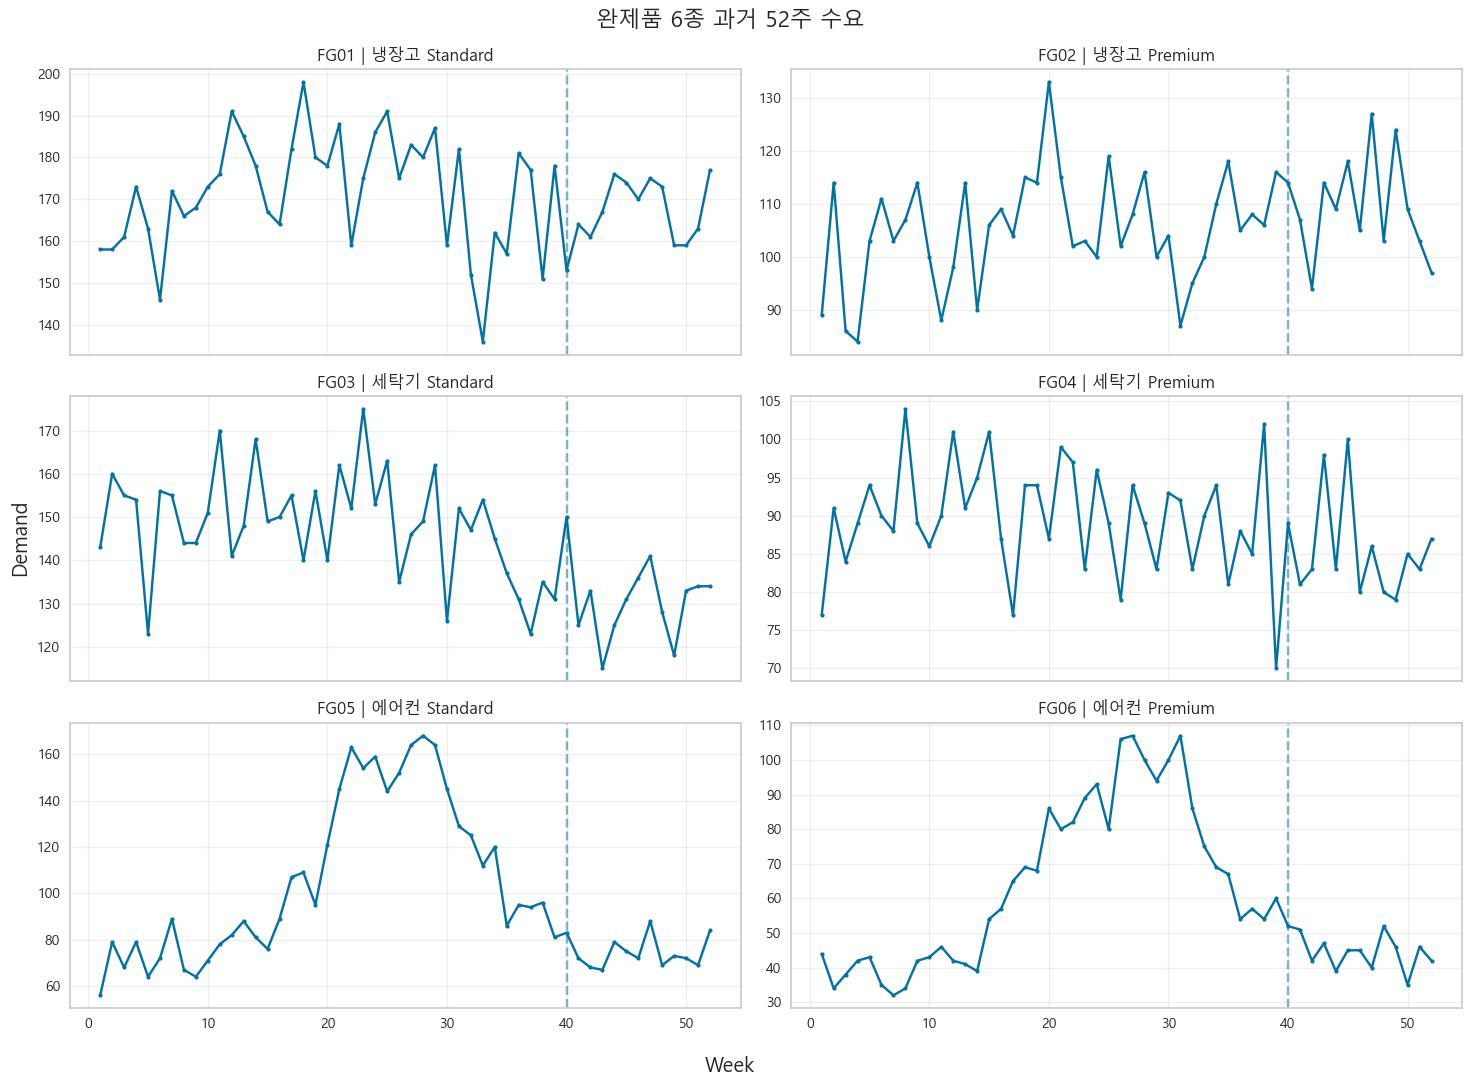


FG01 모델 검증
자동선택=LinearRegression | 최종=LinearRegression | One-step MAPE=4.44% | Recursive MAPE=3.94% | Recursive Corr=0.133

FG02 모델 검증
자동선택=RandomForest | 최종=RandomForest | One-step MAPE=7.16% | Recursive MAPE=7.62% | Recursive Corr=0.372

FG03 모델 검증
자동선택=LinearRegression | 최종=LinearRegression | One-step MAPE=4.93% | Recursive MAPE=4.17% | Recursive Corr=0.353

FG04 모델 검증
자동선택=LinearRegression | 최종=LinearRegression | One-step MAPE=10.86% | Recursive MAPE=9.52% | Recursive Corr=-0.023

FG05 모델 검증
자동선택=LinearRegression | 최종=LinearRegression | One-step MAPE=8.44% | Recursive MAPE=8.71% | Recursive Corr=0.233

FG06 모델 검증
자동선택=LinearRegression | 최종=LinearRegression | One-step MAPE=19.75% | Recursive MAPE=16.92% | Recursive Corr=0.194

Linear Regression vs Random Forest


,product_id,product_name,model,OneStep_MAPE,OneStep_Corr,OneStep_Direction,Recursive_MAPE,Recursive_MAE,Recursive_RMSE,Recursive_Corr,Recursive_Direction
0,FG01,냉장고 Standard,LinearRegression,4.440,0.505,45.455,3.945,6.666,7.607,0.133,36.364
1,FG01,냉장고 Standard,RandomForest,3.723,0.152,54.545,4.237,6.910,9.380,-0.003,45.455
3,FG02,냉장고 Premium,RandomForest,7.156,0.205,45.455,7.624,8.140,9.552,0.372,45.455
2,FG02,냉장고 Premium,LinearRegression,19.957,0.491,54.545,18.202,19.103,20.591,0.672,90.909
4,FG03,세탁기 Standard,LinearRegression,4.927,0.487,54.545,4.174,5.259,7.025,0.353,63.636
5,FG03,세탁기 Standard,RandomForest,12.932,0.245,54.545,14.031,17.744,19.421,0.215,54.545
6,FG04,세탁기 Premium,LinearRegression,10.858,0.076,72.727,9.521,8.154,8.759,-0.023,54.545
7,FG04,세탁기 Premium,RandomForest,10.672,-0.036,72.727,9.678,8.155,8.624,-0.043,54.545
8,FG05,에어컨 Standard,LinearRegression,8.436,0.170,45.455,8.713,6.371,7.949,0.233,45.455
9,FG05,에어컨 Standard,RandomForest,11.961,0.245,27.273,14.111,10.024,11.358,0.098,45.455



★ 제품별 최종 선택 모델


,product_id,product_name,selected_model,OneStep_MAPE,Recursive_MAPE,Recursive_Corr,sigma_error
0,FG01,냉장고 Standard,LinearRegression,4.440,3.945,0.133,7.386
1,FG02,냉장고 Premium,RandomForest,7.156,7.624,0.372,9.422
2,FG03,세탁기 Standard,LinearRegression,4.927,4.174,0.353,7.117
3,FG04,세탁기 Premium,LinearRegression,10.858,9.521,-0.023,8.311
4,FG05,에어컨 Standard,LinearRegression,8.436,8.713,0.233,7.507
5,FG06,에어컨 Premium,LinearRegression,19.753,16.921,0.194,5.004


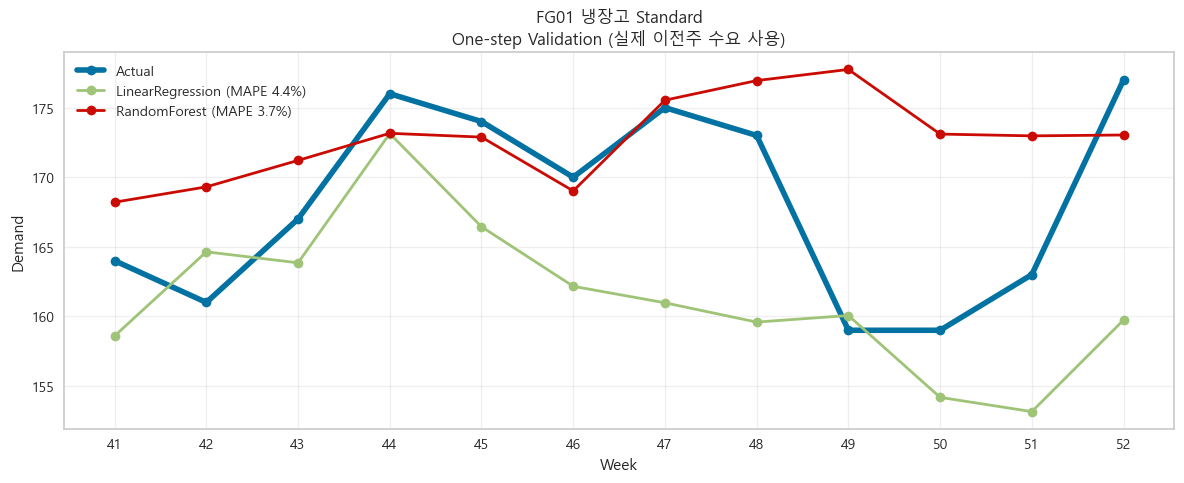

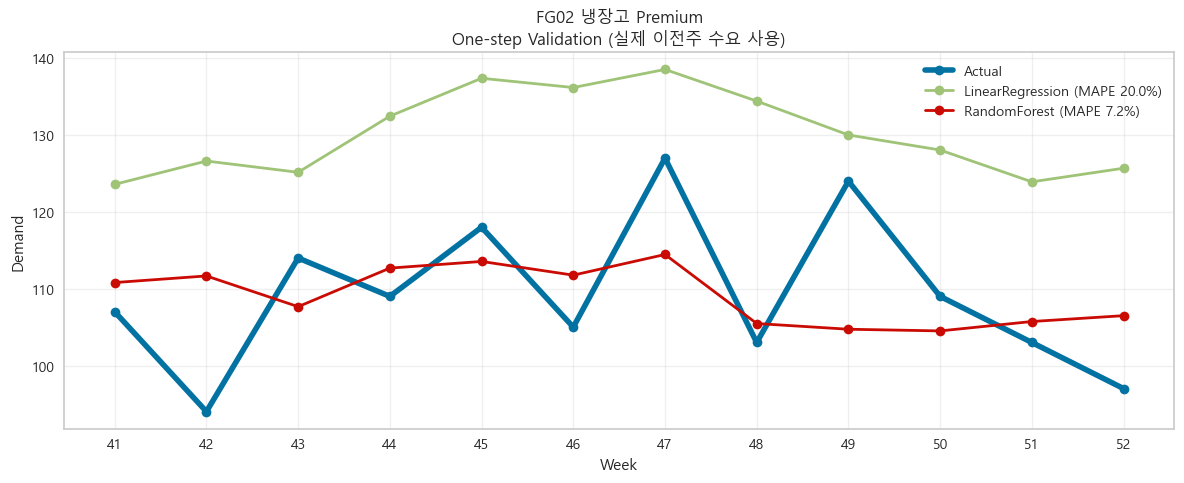

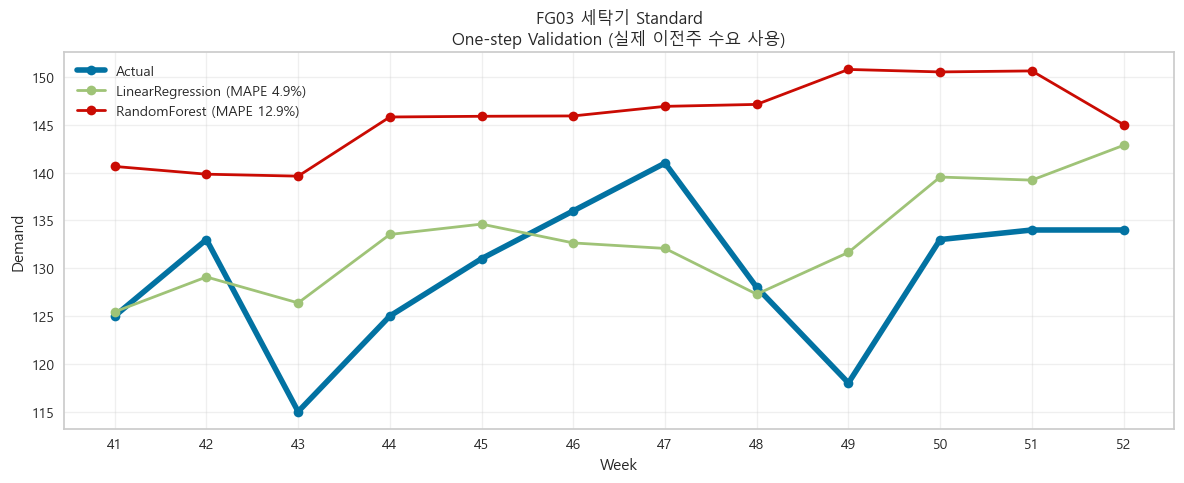

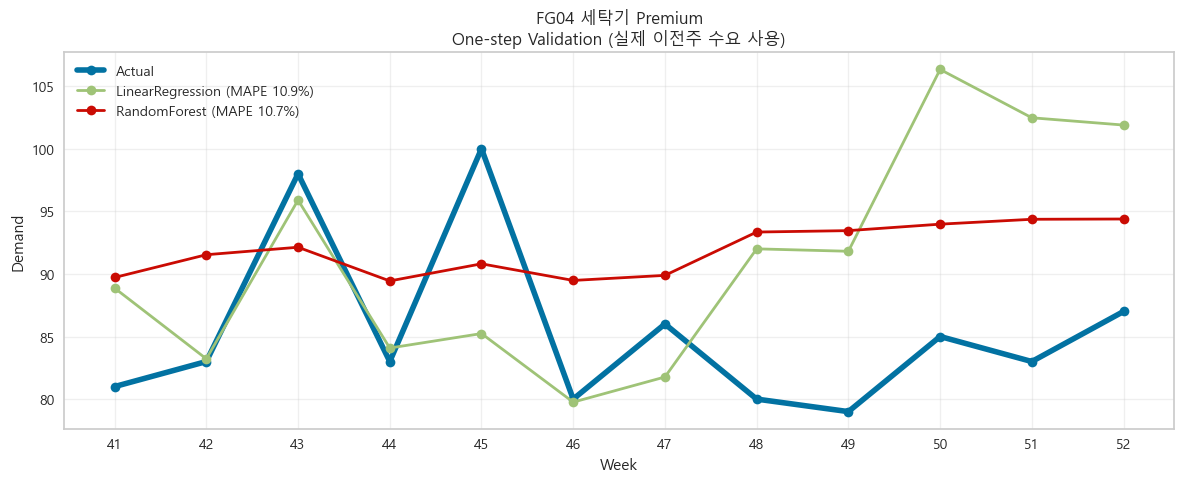

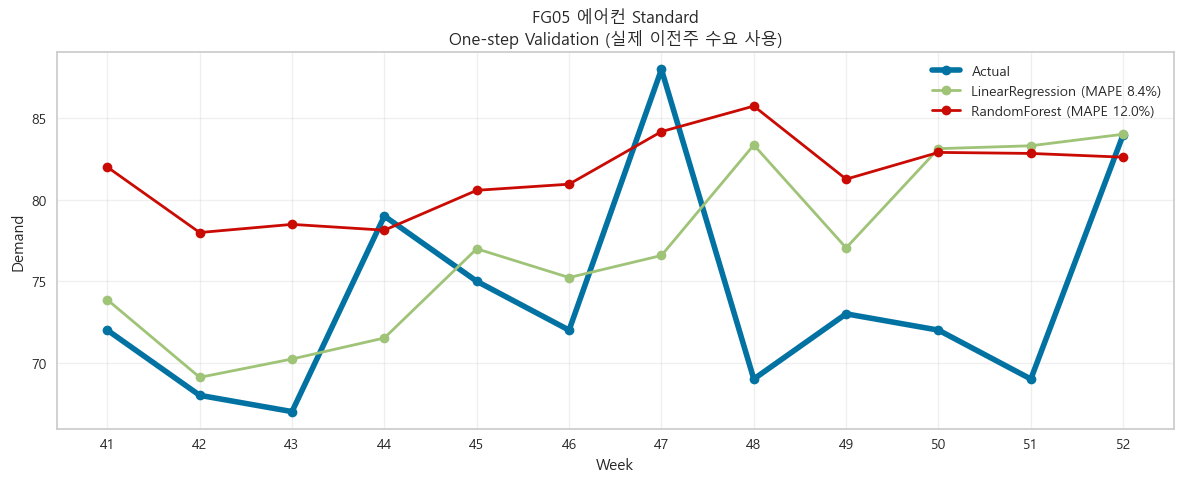

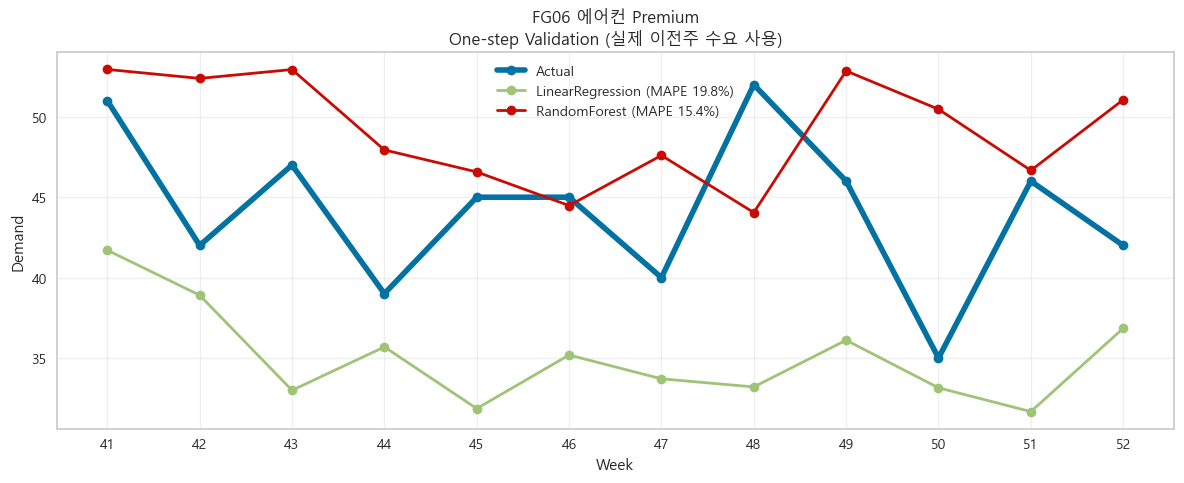

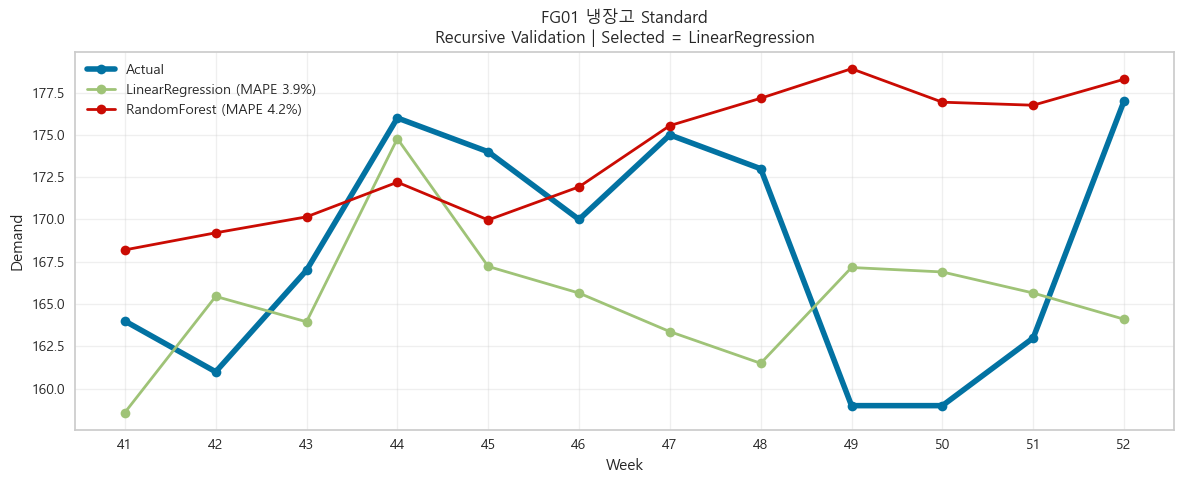

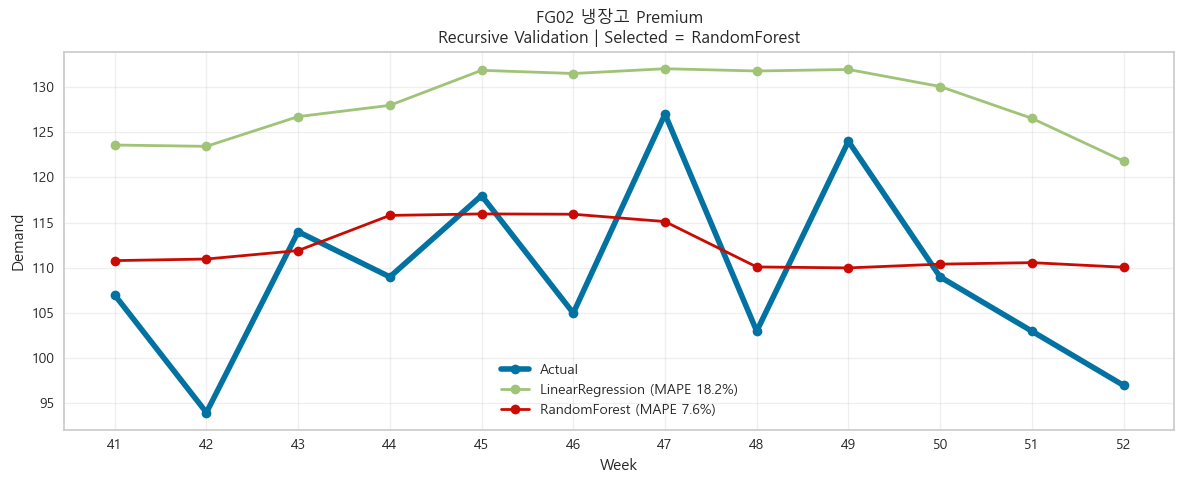

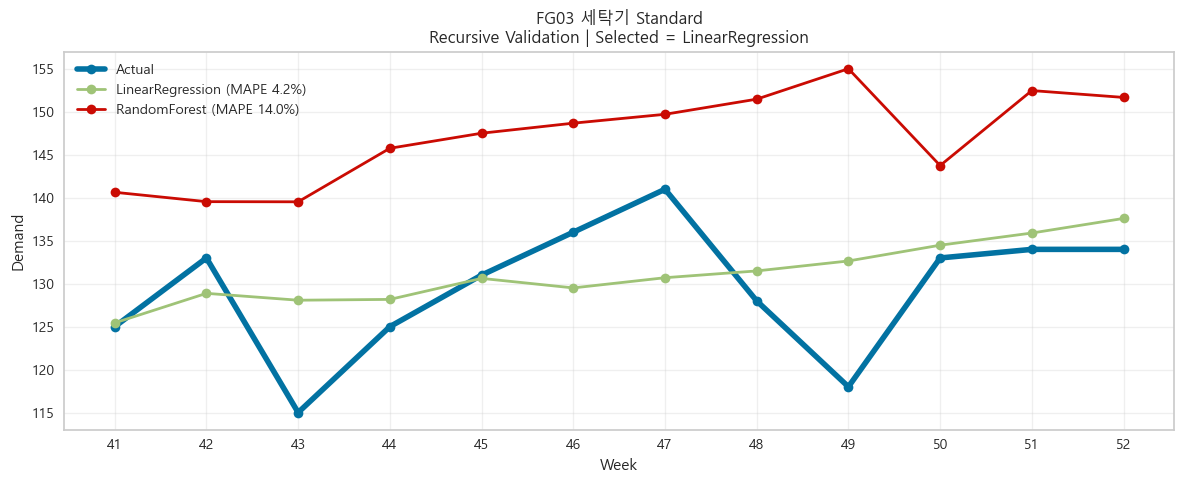

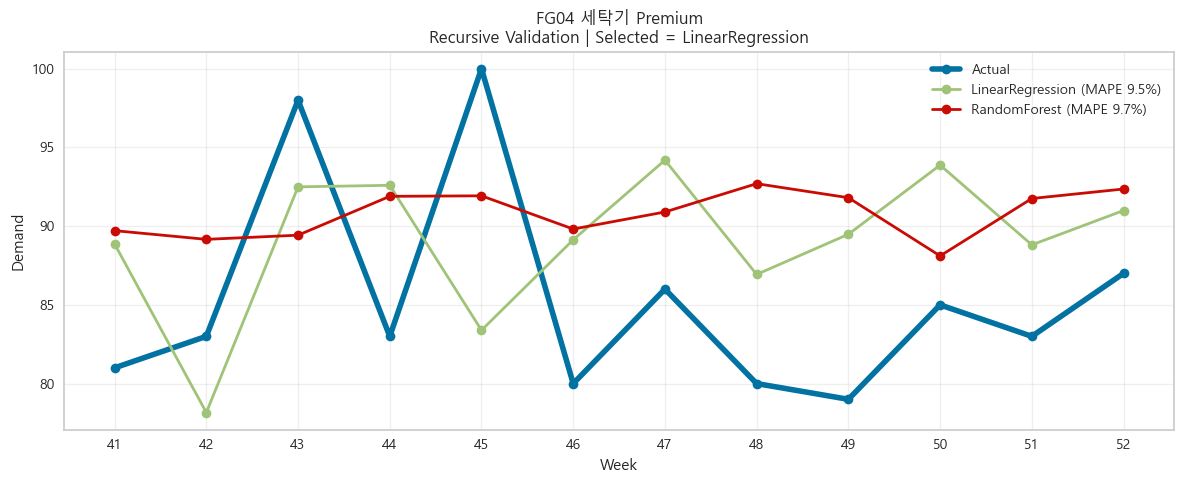

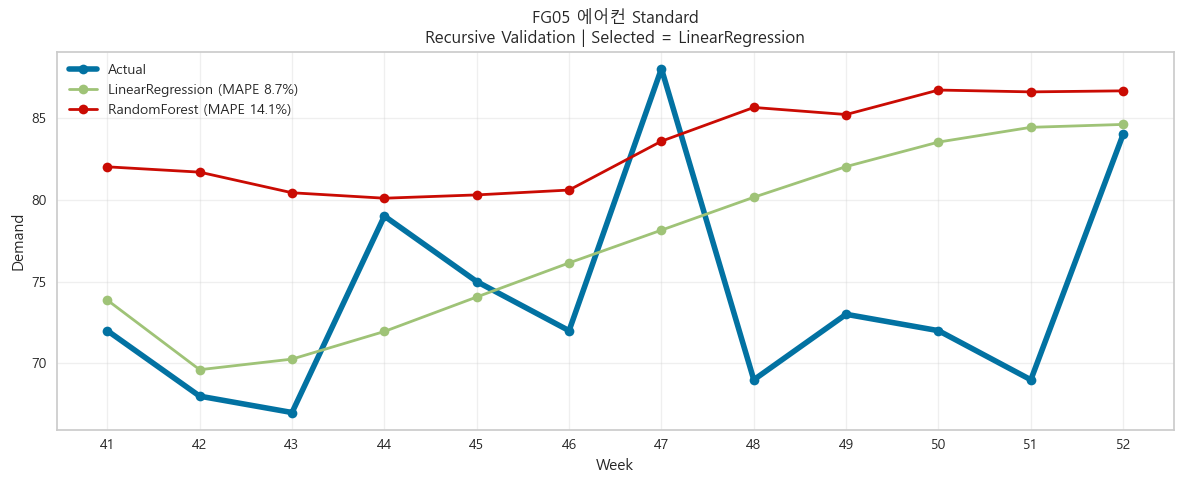

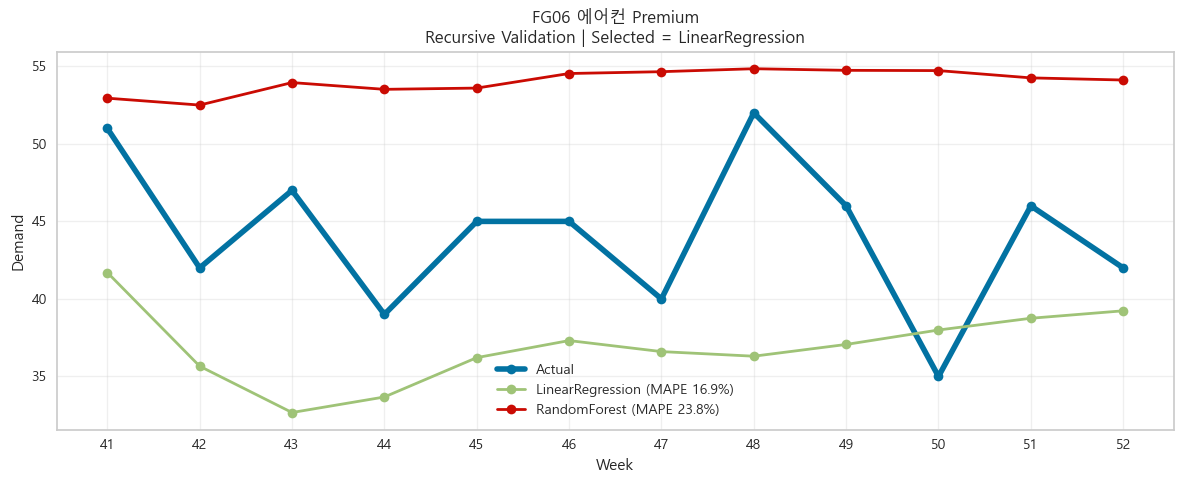


W53 ~ W65 미래 13주 수요예측


product_id,week,FG01,FG02,FG03,FG04,FG05,FG06
0,53,165.2,105.6,142.2,88.7,84.3,43.2
1,54,163.1,108.4,138.3,88.3,81.5,43.4
2,55,161.3,107.8,141.7,88.8,78.3,43.1
3,56,160.8,107.4,142.6,91.1,75.2,42.4
4,57,172.9,105.7,143.8,90.8,73.2,41.3
5,58,168.5,106.1,146.6,91.7,72.0,39.9
6,59,168.6,105.9,147.3,92.9,70.9,38.8
7,60,169.1,106.5,148.8,93.7,70.1,38.3
8,61,173.2,107.7,149.5,94.1,69.6,38.4
9,62,176.6,103.1,150.1,95.1,69.9,39.2


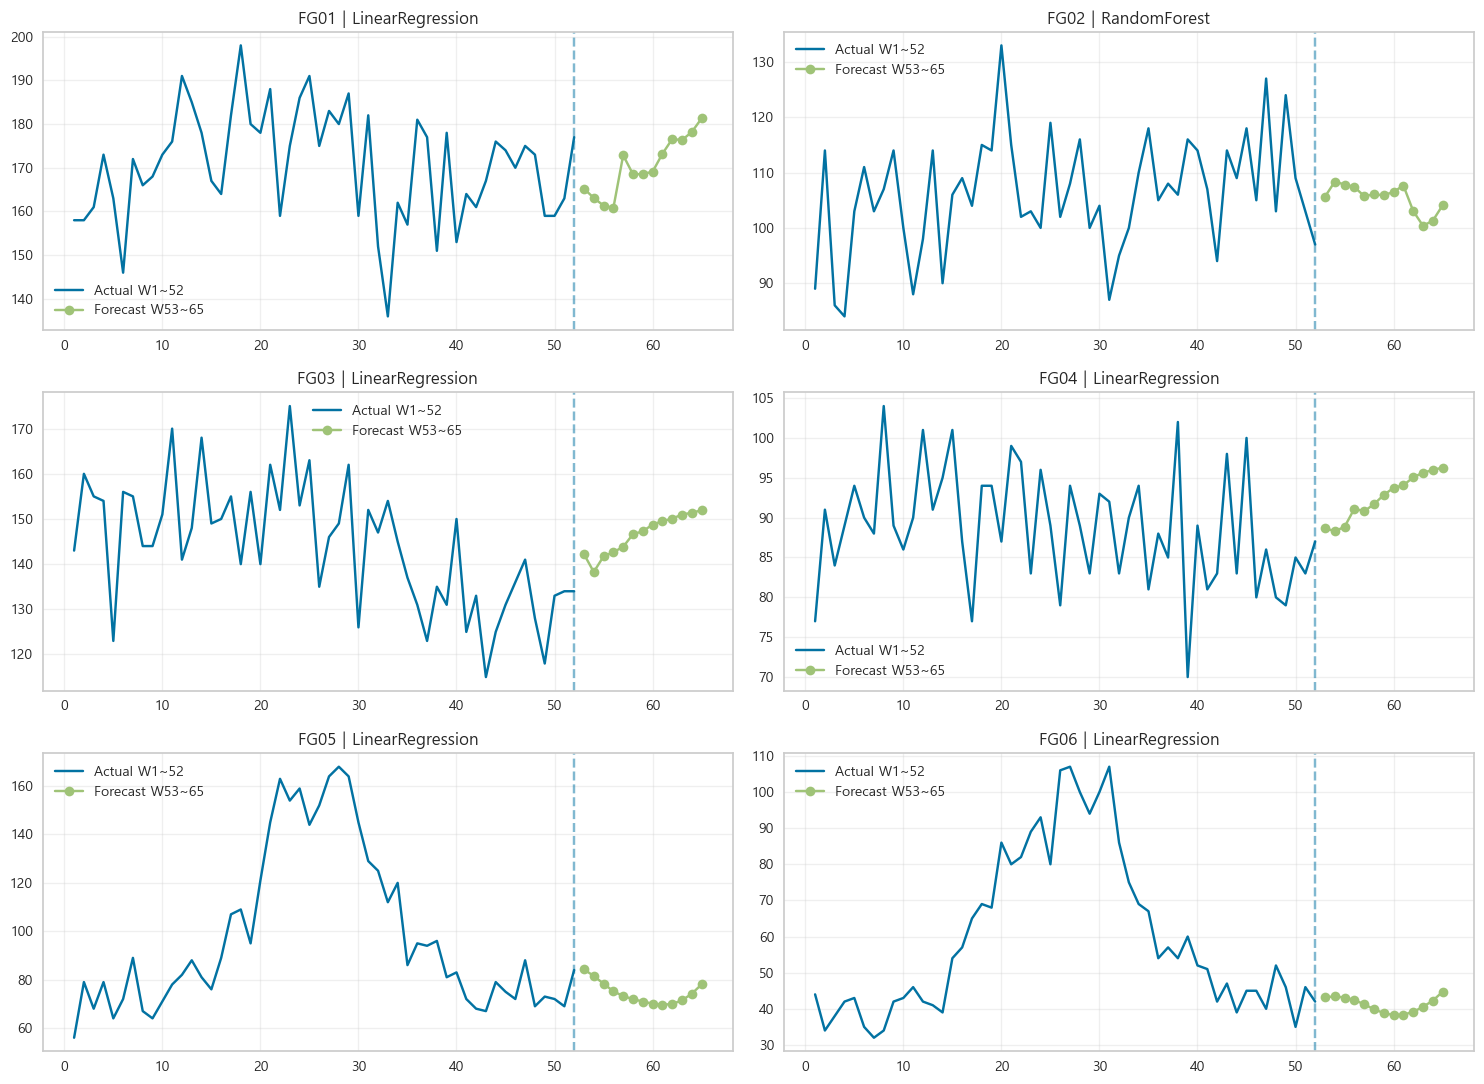


완제품 6종 (s,S)


,ID,name,model,OneStep_MAPE,Recursive_MAPE,mu_13w,sigma_error,safety_stock,s,Q_raw,Q,S
0,FG01,냉장고 Standard,LinearRegression,4.44,3.94,170.40,7.39,12.19,183,301.46,310,493
1,FG02,냉장고 Premium,RandomForest,7.16,7.62,105.38,9.42,15.55,121,229.54,230,351
2,FG03,세탁기 Standard,LinearRegression,4.93,4.17,146.56,7.12,11.74,159,270.70,280,439
3,FG04,세탁기 Premium,LinearRegression,10.86,9.52,92.54,8.31,13.71,107,209.66,210,317
4,FG05,에어컨 Standard,LinearRegression,8.44,8.71,74.52,7.51,12.39,87,190.25,200,287
5,FG06,에어컨 Premium,LinearRegression,19.75,16.92,41.19,5.00,8.26,50,141.91,150,200



원자재 9종 (s,S)


,ID,name,mu_13w,sigma_error,safety_stock,s,Q_raw,Q,S,생산Lot_필요량,s_Lot차이,Lot체크
0,RM01,도장 강판 세트,630.59,18.56,30.62,662,805.36,850,1512,1380,-718,CHECK
1,RM02,Main PCB,630.59,18.56,30.62,662,710.26,720,1382,1380,-718,CHECK
2,RM03,BLDC Motor,239.10,10.94,18.05,258,386.57,400,658,490,-232,CHECK
3,RM04,Compressor,391.49,14.99,24.73,417,395.72,400,817,890,-473,CHECK
4,RM05,Heat Exchanger,115.71,9.02,14.89,131,251.67,260,391,350,-219,CHECK
5,RM06,Drum Assembly,239.10,10.94,18.05,258,404.91,420,678,490,-232,CHECK
6,RM07,Display Module,239.11,13.52,22.31,262,535.67,540,802,590,-328,CHECK
7,RM08,Wiring Harness,630.59,18.56,30.62,662,1087.36,1100,1762,1380,-718,CHECK
8,RM09,Fan Motor,156.90,12.51,20.64,178,354.29,360,538,500,-322,CHECK



생산 Lot 기준 확인 필요 원자재


,ID,name,s,생산Lot_필요량,s_Lot차이
0,RM01,도장 강판 세트,662,1380,-718
1,RM02,Main PCB,662,1380,-718
2,RM03,BLDC Motor,258,490,-232
3,RM04,Compressor,417,890,-473
4,RM05,Heat Exchanger,131,350,-219
5,RM06,Drum Assembly,258,490,-232
6,RM07,Display Module,262,590,-328
7,RM08,Wiring Harness,662,1380,-718
8,RM09,Fan Motor,178,500,-322



★ 1차 제출용 최종 15개 (s,S)


,ID,s,S
0,FG01,183,493
1,FG02,121,351
2,FG03,159,439
3,FG04,107,317
4,FG05,87,287
5,FG06,50,200
6,RM01,662,1512
7,RM02,662,1382
8,RM03,258,658
9,RM04,417,817



전체 실습 완료
저장 완료:
1차_제출용.xlsx
전체_실습_분석결과.xlsx


In [25]:
# ============================================================
# LG전자 Operation 미니케이스 - 전체 실습 최종
#
# 모델
#   1) Linear Regression
#   2) Random Forest
#
# 계절성
#   - lag1 / lag2 / ma4 / std4
#   - 52주 Fourier
#   - 26주 Fourier
#
# 검증
#   A. One-step : 실제 전주 수요 사용
#   B. Recursive: 예측값을 다음 주 입력으로 사용
#
# 최종모델
#   Recursive MAPE 기준
#
# 이후
#   W53~W65 예측
#   → 완제품 (s,S)
#   → BOM
#   → 원자재 (s,S)
#   → 15행 제출파일
# ============================================================


# ============================================================
# 0. 라이브러리
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import warnings

from pathlib import Path
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 300)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 1. 설정
# ============================================================

RANDOM_STATE = 42

# 서비스 수준 95%
Z = 1.65

TRAIN_END = 40

VALID_START = 41
VALID_END = 52

FUTURE_START = 53
FUTURE_END = 65


# ------------------------------------------------------------
# 그래프를 보고 직접 모델을 바꾸고 싶으면 여기 입력
#
# 예)
# MANUAL_MODEL = {
#     "FG01": "RandomForest",
#     "FG03": "LinearRegression"
# }
#
# 비워두면 Recursive MAPE 최소 모델 자동선택
# ------------------------------------------------------------

MANUAL_MODEL = {}


# ============================================================
# 2. CSV 파일 자동 검색
# ============================================================

def find_csv(stem):

    exact = Path(f"{stem}.csv")

    if exact.exists():
        return exact

    candidates = sorted(
        Path(".").glob(f"{stem}*.csv")
    )

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"{stem}.csv 파일을 찾을 수 없습니다."
        )

    return candidates[-1]


hist_file = find_csv("historical_demand")
production_file = find_csv("production_master")
warehouse_file = find_csv("warehouse_master")
raw_file = find_csv("raw_material_master")
bom_file = find_csv("bom")


print("=" * 90)
print("사용 파일")
print("=" * 90)

print("수요       :", hist_file)
print("생산       :", production_file)
print("창고       :", warehouse_file)
print("원자재     :", raw_file)
print("BOM        :", bom_file)


# ============================================================
# 3. 데이터 로드
# ============================================================

hist = pd.read_csv(hist_file)

production = pd.read_csv(
    production_file
)

warehouse = pd.read_csv(
    warehouse_file
)

raw = pd.read_csv(
    raw_file
)

bom = pd.read_csv(
    bom_file
)


print("\n" + "=" * 90)
print("데이터 크기")
print("=" * 90)

print("historical_demand :", hist.shape)
print("production_master :", production.shape)
print("warehouse_master  :", warehouse.shape)
print("raw_material      :", raw.shape)
print("bom               :", bom.shape)


# ============================================================
# 4. 데이터 검증
# ============================================================

print("\n===== 제품별 주차 수 =====")

display(
    hist.groupby(
        ["product_id", "product_name"]
    )["week"]
    .nunique()
    .reset_index(name="주차수")
)


assert (
    hist.groupby("product_id")["week"]
    .nunique()
    .eq(52)
    .all()
), "52주 데이터가 없는 제품이 있습니다."


assert (
    hist["weekly_demand_units"] >= 0
).all(), "음수 수요가 존재합니다."


assert (
    set(hist["product_id"])
    ==
    set(production["product_id"])
), "production product_id 오류"


assert (
    set(hist["product_id"])
    ==
    set(warehouse["product_id"])
), "warehouse product_id 오류"


assert set(
    bom["product_id"]
).issubset(
    set(hist["product_id"])
), "BOM product_id 오류"


assert set(
    bom["material_id"]
).issubset(
    set(raw["material_id"])
), "BOM material_id 오류"


# ============================================================
# 5. 수요 특성 분석
# ============================================================

demand_summary = (

    hist

    .groupby(
        ["product_id", "product_name"],
        as_index=False
    )

    .agg(

        평균수요=(
            "weekly_demand_units",
            "mean"
        ),

        표준편차=(
            "weekly_demand_units",
            "std"
        ),

        최소수요=(
            "weekly_demand_units",
            "min"
        ),

        최대수요=(
            "weekly_demand_units",
            "max"
        )
    )
)


demand_summary["CV"] = (

    demand_summary["표준편차"]

    /

    demand_summary["평균수요"]
)


print("\n" + "=" * 90)
print("완제품 수요 특성")
print("=" * 90)

display(
    demand_summary.round(3)
)


# ============================================================
# 6. 안전재고 현황 진단
# ============================================================

safety_diag = demand_summary.merge(

    warehouse[
        [
            "product_id",
            "current_finished_goods_inventory_units",
            "current_safety_stock_units",
            "weekly_holding_cost_krw_per_unit",
            "shortage_penalty_cost_krw_per_unit"
        ]
    ],

    on="product_id",
    how="left"
)


safety_diag["필요안전재고_95"] = (

    np.ceil(

        Z

        *

        safety_diag[
            "표준편차"
        ]
    )

    .astype(int)
)


safety_diag["안전재고차이"] = (

    safety_diag[
        "current_safety_stock_units"
    ]

    -

    safety_diag[
        "필요안전재고_95"
    ]
)


print("\n" + "=" * 90)
print("현재 안전재고 진단")
print("=" * 90)

display(
    safety_diag.round(2)
)


# ============================================================
# 7. 제품별 52주 원본 그래프
#
# 중요:
# sharey=False
#
# 제품별 수요규모가 다르므로
# 그래프 모양을 볼 때는 Y축 공유하지 않음
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 11),
    sharex=True,
    sharey=False
)

axes = axes.flatten()


for ax, (pid, g) in zip(
    axes,
    hist.groupby("product_id")
):

    g = g.sort_values(
        "week"
    )

    ax.plot(
        g["week"],
        g["weekly_demand_units"],
        marker="o",
        markersize=3
    )

    ax.axvline(
        TRAIN_END,
        linestyle="--",
        alpha=0.5
    )

    ax.set_title(
        f"{pid} | {g['product_name'].iloc[0]}"
    )

    ax.grid(
        alpha=0.3
    )


fig.supxlabel(
    "Week"
)

fig.supylabel(
    "Demand"
)

fig.suptitle(
    "완제품 6종 과거 52주 수요",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ============================================================
# 8. Feature
#
# 최근 수요:
# lag1, lag2, ma4, std4
#
# 계절성:
# sin52/cos52 = 1년 주기
#
# sin26/cos26 = 반년 주기 / 계절곡선 보완
#
# 52주 데이터가 1년치뿐이라
# lag52는 사용할 수 없음
# ============================================================

FEATURES = [

    "lag1",
    "lag2",

    "ma4",
    "std4",

    "sin52",
    "cos52",

    "sin26",
    "cos26"
]


def make_feature(
    week,
    history
):


    week_of_year = (

        (week - 1) % 52

    ) + 1


    last4 = history[-4:]


    return {

        # --------------------------------
        # 최근 수요 수준
        # --------------------------------

        "lag1":
            float(
                history[-1]
            ),

        "lag2":
            float(
                history[-2]
            ),

        "ma4":
            float(
                np.mean(
                    last4
                )
            ),

        "std4":
            float(
                np.std(
                    last4,
                    ddof=0
                )
            ),


        # --------------------------------
        # 52주 계절성
        # --------------------------------

        "sin52":
            np.sin(

                2
                *
                np.pi
                *
                week_of_year
                /
                52
            ),

        "cos52":
            np.cos(

                2
                *
                np.pi
                *
                week_of_year
                /
                52
            ),


        # --------------------------------
        # 2차 Fourier
        #
        # 연간곡선을 한 번 더 휘어줄 수 있음
        # --------------------------------

        "sin26":
            np.sin(

                4
                *
                np.pi
                *
                week_of_year
                /
                52
            ),

        "cos26":
            np.cos(

                4
                *
                np.pi
                *
                week_of_year
                /
                52
            )
    }


# ============================================================
# 9. Supervised Data 생성
# ============================================================

def make_supervised(
    g,
    end_week
):


    g = g.sort_values(
        "week"
    )


    demand_dict = dict(

        zip(

            g["week"],

            g[
                "weekly_demand_units"
            ]
        )
    )


    rows = []


    for week in range(
        5,
        end_week + 1
    ):


        history = [

            demand_dict[w]

            for w in range(
                1,
                week
            )
        ]


        row = make_feature(
            week,
            history
        )


        row[
            "week"
        ] = week


        row[
            "target"
        ] = demand_dict[
            week
        ]


        rows.append(
            row
        )


    return pd.DataFrame(
        rows
    )


# ============================================================
# 10. Recursive Forecast
#
# 실제 미래 예측 환경
#
# W41 예측
# → 예측 W41을 이용해 W42
#
# ...
# ============================================================

def recursive_forecast(
    model,
    history,
    start_week,
    end_week
):


    history = list(
        map(
            float,
            history
        )
    )


    predictions = []


    for week in range(
        start_week,
        end_week + 1
    ):


        f = make_feature(
            week,
            history
        )


        X = pd.DataFrame(

            [[
                f[c]
                for c
                in FEATURES
            ]],

            columns=FEATURES
        )


        pred = float(

            model.predict(
                X
            )[0]
        )


        pred = max(
            pred,
            0
        )


        predictions.append(
            pred
        )


        history.append(
            pred
        )


    return np.array(
        predictions
    )


# ============================================================
# 11. 평가 지표
# ============================================================

def metrics(
    actual,
    pred
):


    actual = np.asarray(
        actual,
        dtype=float
    )

    pred = np.asarray(
        pred,
        dtype=float
    )


    # MAPE
    mape = (

        np.mean(

            np.abs(

                (
                    actual
                    -
                    pred
                )

                /

                actual
            )
        )

        * 100
    )


    # MAE
    mae = np.mean(

        np.abs(
            actual - pred
        )
    )


    # RMSE
    rmse = np.sqrt(

        np.mean(

            (
                actual - pred
            ) ** 2
        )
    )


    # Correlation
    if (
        np.std(actual) > 0
        and
        np.std(pred) > 0
    ):

        corr = np.corrcoef(
            actual,
            pred
        )[0, 1]

    else:

        corr = 0.0


    # 방향 일치율
    direction = (

        np.mean(

            np.sign(
                np.diff(
                    actual
                )
            )

            ==

            np.sign(
                np.diff(
                    pred
                )
            )
        )

        * 100
    )


    return {

        "MAPE":
            mape,

        "MAE":
            mae,

        "RMSE":
            rmse,

        "Correlation":
            corr,

        "Direction":
            direction
    }


# ============================================================
# 12. 모델
# ============================================================

models = {


    "LinearRegression":

        LinearRegression(),


    "RandomForest":

        RandomForestRegressor(

            n_estimators=500,

            min_samples_leaf=2,

            max_features=0.8,

            random_state=
                RANDOM_STATE,

            n_jobs=-1
        )
}


# ============================================================
# 13. 결과 저장
# ============================================================

comparison_rows = []

validation_rows = []

selected_info = {}

future_rows = []


# ============================================================
# 14. 제품별 학습 / 검증
# ============================================================

for product_id, g in hist.groupby(
    "product_id"
):


    print("\n" + "=" * 90)
    print(f"{product_id} 모델 검증")
    print("=" * 90)


    g = (

        g.sort_values(
            "week"
        )

        .reset_index(
            drop=True
        )
    )


    product_name = (

        g[
            "product_name"
        ]

        .iloc[0]
    )


    # ========================================================
    # 전체 W1~52 supervised
    # ========================================================

    supervised = make_supervised(
        g,
        VALID_END
    )


    # ========================================================
    # Train
    # ========================================================

    train = (

        supervised[

            supervised[
                "week"
            ]
            <=
            TRAIN_END
        ]

        .copy()
    )


    X_train = (
        train[
            FEATURES
        ]
    )


    y_train = (
        train[
            "target"
        ]
    )


    # ========================================================
    # Validation W41~52
    #
    # actual lag 사용
    # ========================================================

    valid = (

        supervised[

            supervised[
                "week"
            ]
            .between(
                VALID_START,
                VALID_END
            )
        ]

        .copy()
    )


    X_valid = (
        valid[
            FEATURES
        ]
    )


    y_valid = (

        valid[
            "target"
        ]

        .to_numpy(
            dtype=float
        )
    )


    # ========================================================
    # Recursive 시작용 W1~40
    # ========================================================

    history40 = (

        g.loc[

            g[
                "week"
            ]
            <=
            TRAIN_END,

            "weekly_demand_units"
        ]

        .tolist()
    )


    predictions = {}


    # ========================================================
    # Linear / RF
    # ========================================================

    for (
        model_name,
        model
    ) in models.items():


        fitted = clone(
            model
        )


        fitted.fit(
            X_train,
            y_train
        )


        # ----------------------------------------------------
        # A. One-step
        #
        # 실제 전주수요 사용
        # 매주 새롭게 예측하는 상황
        # ----------------------------------------------------

        pred_one = fitted.predict(
            X_valid
        )


        pred_one = np.maximum(
            pred_one,
            0
        )


        # ----------------------------------------------------
        # B. Recursive
        #
        # W40에서 W41~52를
        # 한 번에 예측하는 상황
        # ----------------------------------------------------

        pred_recursive = recursive_forecast(

            fitted,

            history40,

            VALID_START,

            VALID_END
        )


        one_m = metrics(
            y_valid,
            pred_one
        )


        recursive_m = metrics(
            y_valid,
            pred_recursive
        )


        predictions[
            model_name
        ] = {

            "one_step":
                pred_one,

            "recursive":
                pred_recursive
        }


        comparison_rows.append({

            "product_id":
                product_id,

            "product_name":
                product_name,

            "model":
                model_name,


            # ------------------------------
            # One-step
            # ------------------------------

            "OneStep_MAPE":
                one_m[
                    "MAPE"
                ],

            "OneStep_Corr":
                one_m[
                    "Correlation"
                ],

            "OneStep_Direction":
                one_m[
                    "Direction"
                ],


            # ------------------------------
            # Recursive
            # ------------------------------

            "Recursive_MAPE":
                recursive_m[
                    "MAPE"
                ],

            "Recursive_MAE":
                recursive_m[
                    "MAE"
                ],

            "Recursive_RMSE":
                recursive_m[
                    "RMSE"
                ],

            "Recursive_Corr":
                recursive_m[
                    "Correlation"
                ],

            "Recursive_Direction":
                recursive_m[
                    "Direction"
                ]
        })


        # ----------------------------------------------------
        # 그래프용 저장
        # ----------------------------------------------------

        for (
            week,
            actual,
            po,
            pr
        ) in zip(

            valid[
                "week"
            ],

            y_valid,

            pred_one,

            pred_recursive
        ):


            validation_rows.append({

                "product_id":
                    product_id,

                "product_name":
                    product_name,

                "model":
                    model_name,

                "week":
                    week,

                "actual":
                    actual,

                "one_step_prediction":
                    po,

                "recursive_prediction":
                    pr
            })


    # ========================================================
    # 최종모델 선택
    #
    # 미래 W53~65와 같은 조건인
    # Recursive MAPE 최소 모델
    # ========================================================

    product_compare = pd.DataFrame(

        [
            r

            for r in comparison_rows

            if r[
                "product_id"
            ]
            ==
            product_id
        ]
    )


    auto_best = (

        product_compare

        .sort_values(
            "Recursive_MAPE"
        )

        .iloc[0][
            "model"
        ]
    )


    selected_model = MANUAL_MODEL.get(

        product_id,

        auto_best
    )


    selected_row = (

        product_compare[

            product_compare[
                "model"
            ]
            ==
            selected_model
        ]

        .iloc[0]
    )


    # --------------------------------------------------------
    # 안전재고 계산용 예측오차
    #
    # 미래상황에 가까운 Recursive 오차를 사용
    # --------------------------------------------------------

    selected_recursive_pred = (

        predictions[

            selected_model

        ][
            "recursive"
        ]
    )


    residual = (

        y_valid

        -

        selected_recursive_pred
    )


    sigma_error = float(

        np.std(
            residual,
            ddof=1
        )
    )


    print(

        f"자동선택={auto_best}"

        f" | 최종={selected_model}"

        f" | One-step MAPE="
        f"{selected_row['OneStep_MAPE']:.2f}%"

        f" | Recursive MAPE="
        f"{selected_row['Recursive_MAPE']:.2f}%"

        f" | Recursive Corr="
        f"{selected_row['Recursive_Corr']:.3f}"
    )


    # ========================================================
    # W1~52 전체 재학습
    # ========================================================

    final_model = clone(

        models[
            selected_model
        ]
    )


    final_model.fit(

        supervised[
            FEATURES
        ],

        supervised[
            "target"
        ]
    )


    # ========================================================
    # 실제 미래 W53~65
    #
    # W53 이후 실제값은 모르므로 Recursive
    # ========================================================

    future_pred = recursive_forecast(

        final_model,

        g[
            "weekly_demand_units"
        ].tolist(),

        FUTURE_START,

        FUTURE_END
    )


    selected_info[
        product_id
    ] = {

        "product_name":
            product_name,

        "model":
            selected_model,

        "OneStep_MAPE":
            float(
                selected_row[
                    "OneStep_MAPE"
                ]
            ),

        "Recursive_MAPE":
            float(
                selected_row[
                    "Recursive_MAPE"
                ]
            ),

        "Recursive_Corr":
            float(
                selected_row[
                    "Recursive_Corr"
                ]
            ),

        "sigma_error":
            sigma_error,

        "future":
            future_pred
    }


    for (
        week,
        pred
    ) in zip(

        range(
            FUTURE_START,
            FUTURE_END + 1
        ),

        future_pred
    ):


        future_rows.append({

            "week":
                week,

            "product_id":
                product_id,

            "product_name":
                product_name,

            "model":
                selected_model,

            "forecast":
                pred
        })


# ============================================================
# 15. DataFrame
# ============================================================

comparison_df = pd.DataFrame(
    comparison_rows
)


validation_df = pd.DataFrame(
    validation_rows
)


future_df = pd.DataFrame(
    future_rows
)


# ============================================================
# 16. Linear vs RF 결과표
# ============================================================

print("\n" + "=" * 90)
print("Linear Regression vs Random Forest")
print("=" * 90)


display(

    comparison_df

    .sort_values(
        [
            "product_id",
            "Recursive_MAPE"
        ]
    )

    .round(3)
)


# ============================================================
# 17. 제품별 모델선택
# ============================================================

selected_rows = []


for (
    pid,
    info
) in selected_info.items():


    selected_rows.append({

        "product_id":
            pid,

        "product_name":
            info[
                "product_name"
            ],

        "selected_model":
            info[
                "model"
            ],

        "OneStep_MAPE":
            info[
                "OneStep_MAPE"
            ],

        "Recursive_MAPE":
            info[
                "Recursive_MAPE"
            ],

        "Recursive_Corr":
            info[
                "Recursive_Corr"
            ],

        "sigma_error":
            info[
                "sigma_error"
            ]
    })


selected_model_df = (

    pd.DataFrame(
        selected_rows
    )

    .sort_values(
        "product_id"
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("★ 제품별 최종 선택 모델")
print("=" * 90)


display(
    selected_model_df.round(3)
)


# ============================================================
# 18. 그래프 1
#
# One-step 검증
#
# 실제 이전주 수요를 매번 알고 있다고 가정
# 순수하게 모델이 수요패턴을 잡는지 확인
# ============================================================

for product_id in sorted(
    hist["product_id"].unique()
):


    temp = (

        validation_df[

            validation_df[
                "product_id"
            ]
            ==
            product_id
        ]
    )


    actual = (

        temp[
            [
                "week",
                "actual"
            ]
        ]

        .drop_duplicates()

        .sort_values(
            "week"
        )
    )


    plt.figure(
        figsize=(12, 5)
    )


    plt.plot(

        actual[
            "week"
        ],

        actual[
            "actual"
        ],

        marker="o",

        linewidth=4,

        label="Actual"
    )


    for model_name in [
        "LinearRegression",
        "RandomForest"
    ]:


        m = (

            temp[

                temp[
                    "model"
                ]
                ==
                model_name
            ]

            .sort_values(
                "week"
            )
        )


        row = (

            comparison_df[

                (
                    comparison_df[
                        "product_id"
                    ]
                    ==
                    product_id
                )

                &

                (
                    comparison_df[
                        "model"
                    ]
                    ==
                    model_name
                )
            ]

            .iloc[0]
        )


        plt.plot(

            m[
                "week"
            ],

            m[
                "one_step_prediction"
            ],

            marker="o",

            linewidth=2,

            label=(

                f"{model_name} "
                f"(MAPE {row['OneStep_MAPE']:.1f}%)"
            )
        )


    product_name = (

        hist[

            hist[
                "product_id"
            ]
            ==
            product_id
        ]

        [
            "product_name"
        ]

        .iloc[0]
    )


    plt.title(

        f"{product_id} {product_name}\n"
        "One-step Validation "
        "(실제 이전주 수요 사용)"
    )


    plt.xlabel(
        "Week"
    )

    plt.ylabel(
        "Demand"
    )

    plt.xticks(
        range(
            41,
            53
        )
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# 19. 그래프 2
#
# Recursive 검증
#
# W40 이후 실제값을 전혀 모른다고 가정
#
# 실제 W53~65 예측과 같은 방식
# ============================================================

for product_id in sorted(
    hist["product_id"].unique()
):


    temp = (

        validation_df[

            validation_df[
                "product_id"
            ]
            ==
            product_id
        ]
    )


    actual = (

        temp[
            [
                "week",
                "actual"
            ]
        ]

        .drop_duplicates()

        .sort_values(
            "week"
        )
    )


    plt.figure(
        figsize=(12, 5)
    )


    plt.plot(

        actual[
            "week"
        ],

        actual[
            "actual"
        ],

        marker="o",

        linewidth=4,

        label="Actual"
    )


    for model_name in [
        "LinearRegression",
        "RandomForest"
    ]:


        m = (

            temp[

                temp[
                    "model"
                ]
                ==
                model_name
            ]

            .sort_values(
                "week"
            )
        )


        row = (

            comparison_df[

                (
                    comparison_df[
                        "product_id"
                    ]
                    ==
                    product_id
                )

                &

                (
                    comparison_df[
                        "model"
                    ]
                    ==
                    model_name
                )
            ]

            .iloc[0]
        )


        plt.plot(

            m[
                "week"
            ],

            m[
                "recursive_prediction"
            ],

            marker="o",

            linewidth=2,

            label=(

                f"{model_name} "
                f"(MAPE {row['Recursive_MAPE']:.1f}%)"
            )
        )


    product_name = (

        hist[

            hist[
                "product_id"
            ]
            ==
            product_id
        ]

        [
            "product_name"
        ]

        .iloc[0]
    )


    selected = (

        selected_info[
            product_id
        ][
            "model"
        ]
    )


    plt.title(

        f"{product_id} {product_name}\n"
        f"Recursive Validation | "
        f"Selected = {selected}"
    )


    plt.xlabel(
        "Week"
    )

    plt.ylabel(
        "Demand"
    )

    plt.xticks(
        range(
            41,
            53
        )
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# 20. W53~65 예측표
# ============================================================

future_wide = (

    future_df

    .pivot(

        index="week",

        columns="product_id",

        values="forecast"
    )

    .reset_index()
)


print("\n" + "=" * 90)
print("W53 ~ W65 미래 13주 수요예측")
print("=" * 90)


display(
    future_wide.round(1)
)


# ============================================================
# 21. 과거 + 미래 제품별 그래프
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 11),
    sharex=False,
    sharey=False
)

axes = axes.flatten()


for ax, product_id in zip(

    axes,

    sorted(
        hist[
            "product_id"
        ].unique()
    )
):


    actual = (

        hist[

            hist[
                "product_id"
            ]
            ==
            product_id
        ]

        .sort_values(
            "week"
        )
    )


    future = (

        future_df[

            future_df[
                "product_id"
            ]
            ==
            product_id
        ]

        .sort_values(
            "week"
        )
    )


    selected = (

        selected_info[
            product_id
        ][
            "model"
        ]
    )


    ax.plot(

        actual[
            "week"
        ],

        actual[
            "weekly_demand_units"
        ],

        label="Actual W1~52"
    )


    ax.plot(

        future[
            "week"
        ],

        future[
            "forecast"
        ],

        marker="o",

        label="Forecast W53~65"
    )


    ax.axvline(
        52,
        linestyle="--",
        alpha=0.5
    )


    ax.set_title(

        f"{product_id} | "
        f"{selected}"
    )


    ax.grid(
        alpha=0.3
    )

    ax.legend()


plt.tight_layout()
plt.show()


# ============================================================
# 22. 완제품 (s,S)
#
# s = ceil(mu + z sigma_error)
#
# Q = sqrt(2 K mu / h)
#
# 생산단위 올림
#
# S = s + Q
# ============================================================

finished_rows = []


for product_id in sorted(
    selected_info.keys()
):


    info = (
        selected_info[
            product_id
        ]
    )


    mu = float(

        np.mean(
            info[
                "future"
            ]
        )
    )


    sigma_error = float(

        info[
            "sigma_error"
        ]
    )


    prod_row = (

        production[

            production[
                "product_id"
            ]
            ==
            product_id
        ]

        .iloc[0]
    )


    wh_row = (

        warehouse[

            warehouse[
                "product_id"
            ]
            ==
            product_id
        ]

        .iloc[0]
    )


    # 안전재고
    safety_stock = (

        Z
        *
        sigma_error
    )


    # 재주문점
    s = int(

        math.ceil(

            mu
            +
            safety_stock
        )
    )


    # EOQ
    K = float(

        prod_row[
            "fixed_setup_cost_krw_per_run"
        ]
    )


    h = float(

        wh_row[
            "weekly_holding_cost_krw_per_unit"
        ]
    )


    Q_raw = math.sqrt(

        2
        *
        K
        *
        mu
        /
        h
    )


    production_multiple = int(

        prod_row[
            "production_multiple_units"
        ]
    )


    Q = int(

        math.ceil(

            Q_raw

            /

            production_multiple
        )

        *

        production_multiple
    )


    S = (
        s + Q
    )


    finished_rows.append({

        "ID":
            product_id,

        "name":
            info[
                "product_name"
            ],

        "model":
            info[
                "model"
            ],

        "OneStep_MAPE":
            info[
                "OneStep_MAPE"
            ],

        "Recursive_MAPE":
            info[
                "Recursive_MAPE"
            ],

        "mu_13w":
            mu,

        "sigma_error":
            sigma_error,

        "safety_stock":
            safety_stock,

        "s":
            s,

        "Q_raw":
            Q_raw,

        "Q":
            Q,

        "S":
            S
    })


finished_policy = (

    pd.DataFrame(
        finished_rows
    )

    .sort_values(
        "ID"
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("완제품 6종 (s,S)")
print("=" * 90)


display(
    finished_policy.round(2)
)


# ============================================================
# 23. BOM 전개 준비
# ============================================================

raw_forecast = pd.DataFrame({

    "week":
        range(
            FUTURE_START,
            FUTURE_END + 1
        )
})


sigma_map = {

    pid:
        info[
            "sigma_error"
        ]

    for pid, info
    in selected_info.items()
}


finished_Q_map = dict(

    zip(

        finished_policy[
            "ID"
        ],

        finished_policy[
            "Q"
        ]
    )
)


raw_rows = []


# ============================================================
# 24. 원자재 9종
# ============================================================

for _, rm in (

    raw

    .sort_values(
        "material_id"
    )

    .iterrows()
):


    material_id = (
        rm[
            "material_id"
        ]
    )


    material_name = (
        rm[
            "material_name"
        ]
    )


    material_bom = (

        bom[

            bom[
                "material_id"
            ]
            ==
            material_id
        ]
    )


    # --------------------------------------------------------
    # W53~65 예상소요
    # --------------------------------------------------------

    weekly_material = np.zeros(
        13
    )


    for _, b in (
        material_bom.iterrows()
    ):


        pid = (
            b[
                "product_id"
            ]
        )


        qty = float(

            b[
                "qty_per_finished_product"
            ]
        )


        product_future = (

            future_df[

                future_df[
                    "product_id"
                ]
                ==
                pid
            ]

            .sort_values(
                "week"
            )

            [
                "forecast"
            ]

            .to_numpy()
        )


        weekly_material += (

            product_future

            *
            qty
        )


    raw_forecast[
        material_id
    ] = weekly_material


    mu_rm = float(

        weekly_material.mean()
    )


    # --------------------------------------------------------
    # 원자재 sigma
    # --------------------------------------------------------

    sigma_rm = math.sqrt(

        sum(

            (

                float(

                    b[
                        "qty_per_finished_product"
                    ]
                )

                *

                sigma_map[

                    b[
                        "product_id"
                    ]
                ]

            ) ** 2


            for _, b
            in material_bom.iterrows()
        )
    )


    safety_rm = (

        Z
        *
        sigma_rm
    )


    s_rm = int(

        math.ceil(

            mu_rm
            +
            safety_rm
        )
    )


    # --------------------------------------------------------
    # 원자재 EOQ
    # --------------------------------------------------------

    K_rm = float(

        rm[
            "fixed_order_cost_krw_per_order"
        ]
    )


    h_rm = float(

        rm[
            "weekly_holding_cost_krw_per_unit"
        ]
    )


    Q_raw = math.sqrt(

        2
        *
        K_rm
        *
        mu_rm
        /
        h_rm
    )


    order_multiple = int(

        rm[
            "order_multiple_units"
        ]
    )


    Q_rm = int(

        math.ceil(

            Q_raw

            /

            order_multiple
        )

        *

        order_multiple
    )


    S_rm = (

        s_rm
        +
        Q_rm
    )


    # --------------------------------------------------------
    # 생산 Lot 진단
    # --------------------------------------------------------

    lot_need = int(

        math.ceil(

            sum(

                finished_Q_map[

                    b[
                        "product_id"
                    ]
                ]

                *

                float(

                    b[
                        "qty_per_finished_product"
                    ]
                )

                for _, b
                in material_bom.iterrows()
            )
        )
    )


    raw_rows.append({

        "ID":
            material_id,

        "name":
            material_name,

        "mu_13w":
            mu_rm,

        "sigma_error":
            sigma_rm,

        "safety_stock":
            safety_rm,

        "s":
            s_rm,

        "Q_raw":
            Q_raw,

        "Q":
            Q_rm,

        "S":
            S_rm,

        "생산Lot_필요량":
            lot_need,

        "s_Lot차이":
            s_rm - lot_need,

        "Lot체크":

            "CHECK"

            if s_rm < lot_need

            else "OK"
    })


raw_policy = (

    pd.DataFrame(
        raw_rows
    )

    .sort_values(
        "ID"
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("원자재 9종 (s,S)")
print("=" * 90)


display(
    raw_policy.round(2)
)


# ============================================================
# 25. Lot 경고
# ============================================================

lot_warning = (

    raw_policy[

        raw_policy[
            "Lot체크"
        ]
        ==
        "CHECK"
    ]
)


print("\n" + "=" * 90)
print("생산 Lot 기준 확인 필요 원자재")
print("=" * 90)


if len(
    lot_warning
) == 0:

    print(
        "Lot 기준 경고 없음"
    )

else:

    display(

        lot_warning[
            [
                "ID",
                "name",
                "s",
                "생산Lot_필요량",
                "s_Lot차이"
            ]
        ]
    )


# ============================================================
# 26. 15개 제출값
# ============================================================

submission = pd.concat(

    [

        finished_policy[
            [
                "ID",
                "s",
                "S"
            ]
        ],

        raw_policy[
            [
                "ID",
                "s",
                "S"
            ]
        ]

    ],

    ignore_index=True
)


submission = (

    submission

    .sort_values(
        "ID"
    )

    .reset_index(
        drop=True
    )
)


assert len(
    submission
) == 15


assert (
    submission[
        "ID"
    ]
    .nunique()
    ==
    15
)


assert (
    submission[
        "s"
    ]
    <
    submission[
        "S"
    ]
).all()


print("\n" + "=" * 90)
print("★ 1차 제출용 최종 15개 (s,S)")
print("=" * 90)


display(
    submission
)


# ============================================================
# 27. Excel 저장
# ============================================================

submission.to_excel(

    "1차_제출용.xlsx",

    index=False
)


with pd.ExcelWriter(

    "전체_실습_분석결과.xlsx",

    engine="openpyxl"

) as writer:


    demand_summary.to_excel(
        writer,
        sheet_name="01_수요특성",
        index=False
    )


    safety_diag.to_excel(
        writer,
        sheet_name="02_안전재고",
        index=False
    )


    comparison_df.to_excel(
        writer,
        sheet_name="03_모델비교",
        index=False
    )


    selected_model_df.to_excel(
        writer,
        sheet_name="04_선택모델",
        index=False
    )


    validation_df.to_excel(
        writer,
        sheet_name="05_검증결과",
        index=False
    )


    future_df.to_excel(
        writer,
        sheet_name="06_13주예측",
        index=False
    )


    future_wide.to_excel(
        writer,
        sheet_name="07_13주Wide",
        index=False
    )


    finished_policy.to_excel(
        writer,
        sheet_name="08_완제품정책",
        index=False
    )


    raw_forecast.to_excel(
        writer,
        sheet_name="09_원자재수요",
        index=False
    )


    raw_policy.to_excel(
        writer,
        sheet_name="10_원자재정책",
        index=False
    )


    submission.to_excel(
        writer,
        sheet_name="11_제출값",
        index=False
    )


print("\n" + "=" * 90)
print("전체 실습 완료")
print("=" * 90)

print("저장 완료:")
print("1차_제출용.xlsx")
print("전체_실습_분석결과.xlsx")

## 수정본

In [26]:
# ============================================================
# 2차 최적화 코드
#
# ★ 반드시 기존 "1차 코드"를 먼저 실행한 뒤
#   이 셀을 그대로 실행하세요.
#
# 필요 변수:
# future_df
# selected_info
# production
# warehouse
# raw
# bom
# finished_policy
# raw_policy
#
# 목적:
# 1) 1차 정책을 13주 SCM 시뮬레이션으로 재현
# 2) EOQ 중심의 큰 Lot 대신 소량·다빈도 정책 탐색
# 3) 생산축소 최소화
# 4) 생산횟수 약 78회 수준
# 5) 주문횟수 약 97회 수준
# 6) 총비용 최소화
# 7) 2차 제출용 15개 (s,S) 생성
# ============================================================


import pandas as pd
import numpy as np
import math
from copy import deepcopy


# ============================================================
# 0. 설정
# ============================================================

TARGET_PRODUCTION_COUNT = 78
TARGET_ORDER_COUNT = 97

# forecast 기준 허용치
MAX_FORECAST_STOCKOUT_WEEKS = 1
MAX_FORECAST_UNMET = 15
MAX_MATERIAL_CUTS = 1


# ------------------------------------------------------------
# 생산 / 원자재 순서 고정
# ------------------------------------------------------------

FG_IDS = sorted(
    production["product_id"].unique()
)

RM_IDS = sorted(
    raw["material_id"].unique()
)


# ============================================================
# 1. Master index화
# ============================================================

prod_m = (
    production
    .set_index("product_id")
    .copy()
)

wh_m = (
    warehouse
    .set_index("product_id")
    .copy()
)

raw_m = (
    raw
    .set_index("material_id")
    .copy()
)


# ============================================================
# 2. 미래 13주 수요 행렬
# ============================================================

forecast_matrix = (

    future_df

    .pivot(
        index="week",
        columns="product_id",
        values="forecast"
    )

    .reindex(
        columns=FG_IDS
    )

    .sort_index()
)


print("=" * 90)
print("W53~W65 forecast")
print("=" * 90)

display(
    forecast_matrix.round(1)
)


# ============================================================
# 3. BOM 행렬
# ============================================================

BOM = pd.DataFrame(
    0,
    index=FG_IDS,
    columns=RM_IDS,
    dtype=int
)


for _, row in bom.iterrows():

    BOM.loc[
        row["product_id"],
        row["material_id"]
    ] = int(
        row["qty_per_finished_product"]
    )


print("\n" + "=" * 90)
print("BOM")
print("=" * 90)

display(BOM)


# ============================================================
# 4. 배수 올림
# ============================================================

def ceil_multiple(
    value,
    multiple
):

    if value <= 0:
        return 0

    return int(
        math.ceil(
            value / multiple
        )
        *
        multiple
    )


# ============================================================
# 5. SCM 시뮬레이터
#
# 매주:
#
# ① 월요일
#    지난주 생산완료 / 원자재 입고
#
# ② 한 주 수요
#    판매 / 미충족 발생
#
# ③ 주말 완제품
#    inv <= s → 생산지시
#    생산량 = S-current inventory
#    10대 배수
#    원자재 부족하면 생산량 축소
#
# ④ 원자재
#    생산 BOM 즉시 차감
#    inv <= s → 발주
#
# ⑤ 비용
# ============================================================

def simulate_scm(
    policy,
    demand_df=forecast_matrix,
    detail=False
):


    # --------------------------------------------------------
    # 초기재고
    # --------------------------------------------------------

    fg_inventory = {

        pid:
            float(
                wh_m.loc[
                    pid,
                    "current_finished_goods_inventory_units"
                ]
            )

        for pid
        in FG_IDS
    }


    rm_inventory = {

        rid:
            float(
                raw_m.loc[
                    rid,
                    "current_inventory_units"
                ]
            )

        for rid
        in RM_IDS
    }


    # 다음주 월요일 입고 예정
    fg_pending = {
        pid: 0
        for pid in FG_IDS
    }

    rm_pending = {
        rid: 0
        for rid in RM_IDS
    }


    # --------------------------------------------------------
    # 비용
    # --------------------------------------------------------

    cost = {

        "주문고정비": 0.0,

        "구매비": 0.0,

        "원자재보관비": 0.0,

        "셋업비": 0.0,

        "단위생산비": 0.0,

        "완제품보관비": 0.0,

        "미충족패널티": 0.0
    }


    # --------------------------------------------------------
    # 횟수
    # --------------------------------------------------------

    production_count = 0

    material_cut_count = 0

    order_count = 0

    stockout_product_week = 0

    total_unmet = 0.0


    # --------------------------------------------------------
    # 제품별
    # --------------------------------------------------------

    fg_stats = {

        pid: {

            "생산횟수": 0,

            "생산축소": 0,

            "품절주": 0,

            "미충족": 0.0
        }

        for pid
        in FG_IDS
    }


    # --------------------------------------------------------
    # 원자재별
    # --------------------------------------------------------

    rm_stats = {

        rid: {

            "주문횟수": 0,

            "생산제약": 0
        }

        for rid
        in RM_IDS
    }


    weekly_rows = []


    # ========================================================
    # 13주
    # ========================================================

    for week in demand_df.index:


        # ====================================================
        # ① 월요일 입고
        # ====================================================

        for pid in FG_IDS:

            fg_inventory[
                pid
            ] += fg_pending[
                pid
            ]

            fg_pending[
                pid
            ] = 0


        for rid in RM_IDS:

            rm_inventory[
                rid
            ] += rm_pending[
                rid
            ]

            rm_pending[
                rid
            ] = 0


        week_unmet = 0


        # ====================================================
        # ② 수요 발생
        # ====================================================

        for pid in FG_IDS:


            demand = float(
                demand_df.loc[
                    week,
                    pid
                ]
            )


            available = (
                fg_inventory[
                    pid
                ]
            )


            sold = min(
                available,
                demand
            )


            unmet = (
                demand
                -
                sold
            )


            fg_inventory[
                pid
            ] -= sold


            if unmet > 1e-9:


                stockout_product_week += 1

                total_unmet += unmet

                week_unmet += unmet


                fg_stats[
                    pid
                ][
                    "품절주"
                ] += 1


                fg_stats[
                    pid
                ][
                    "미충족"
                ] += unmet


                cost[
                    "미충족패널티"
                ] += (

                    unmet

                    *

                    float(
                        wh_m.loc[
                            pid,
                            "shortage_penalty_cost_krw_per_unit"
                        ]
                    )
                )


        # ====================================================
        # ③ 완제품 생산지시
        # ====================================================

        for pid in FG_IDS:


            s_fg = int(
                policy[
                    pid
                ][0]
            )

            S_fg = int(
                policy[
                    pid
                ][1]
            )


            # ------------------------------------------------
            # 재고 <= s → 생산
            # ------------------------------------------------

            if (
                fg_inventory[
                    pid
                ]
                <=
                s_fg
            ):


                multiple = int(

                    prod_m.loc[
                        pid,
                        "production_multiple_units"
                    ]
                )


                request_qty = ceil_multiple(

                    S_fg
                    -
                    fg_inventory[
                        pid
                    ],

                    multiple
                )


                if request_qty <= 0:
                    continue


                # --------------------------------------------
                # 원자재로 가능한 최대 생산량
                # --------------------------------------------

                max_possible = (
                    request_qty
                )


                related_rm = (

                    BOM.loc[
                        pid
                    ]

                    [
                        BOM.loc[
                            pid
                        ]
                        >
                        0
                    ]
                )


                for rid, bom_qty in (

                    related_rm.items()

                ):


                    possible_by_rm = int(

                        rm_inventory[
                            rid
                        ]

                        //

                        bom_qty
                    )


                    max_possible = min(

                        max_possible,

                        possible_by_rm
                    )


                actual_qty = (

                    max_possible

                    //

                    multiple

                    *

                    multiple
                )


                # --------------------------------------------
                # 생산축소
                # --------------------------------------------

                if (
                    actual_qty
                    <
                    request_qty
                ):


                    material_cut_count += 1


                    fg_stats[
                        pid
                    ][
                        "생산축소"
                    ] += 1


                    for rid, bom_qty in (

                        related_rm.items()

                    ):


                        if (

                            rm_inventory[
                                rid
                            ]

                            <
                            request_qty
                            *
                            bom_qty
                        ):


                            rm_stats[
                                rid
                            ][
                                "생산제약"
                            ] += 1


                # --------------------------------------------
                # 실제 생산
                # --------------------------------------------

                if actual_qty > 0:


                    production_count += 1


                    fg_stats[
                        pid
                    ][
                        "생산횟수"
                    ] += 1


                    # 셋업비
                    cost[
                        "셋업비"
                    ] += float(

                        prod_m.loc[
                            pid,
                            "fixed_setup_cost_krw_per_run"
                        ]
                    )


                    # 단위 생산비
                    cost[
                        "단위생산비"
                    ] += (

                        actual_qty

                        *

                        float(
                            prod_m.loc[
                                pid,
                                "unit_production_cost_krw"
                            ]
                        )
                    )


                    # BOM 즉시 차감
                    for rid, bom_qty in (

                        related_rm.items()

                    ):


                        rm_inventory[
                            rid
                        ] -= (

                            actual_qty

                            *

                            bom_qty
                        )


                    # 다음주 월요일 완료
                    fg_pending[
                        pid
                    ] += actual_qty


        # ====================================================
        # ④ 원자재 발주
        # ====================================================

        for rid in RM_IDS:


            s_rm = int(
                policy[
                    rid
                ][0]
            )

            S_rm = int(
                policy[
                    rid
                ][1]
            )


            if (
                rm_inventory[
                    rid
                ]
                <=
                s_rm
            ):


                order_multiple = int(

                    raw_m.loc[
                        rid,
                        "order_multiple_units"
                    ]
                )


                order_qty = ceil_multiple(

                    S_rm
                    -
                    rm_inventory[
                        rid
                    ],

                    order_multiple
                )


                if order_qty > 0:


                    order_count += 1


                    rm_stats[
                        rid
                    ][
                        "주문횟수"
                    ] += 1


                    # 주문 고정비
                    cost[
                        "주문고정비"
                    ] += float(

                        raw_m.loc[
                            rid,
                            "fixed_order_cost_krw_per_order"
                        ]
                    )


                    # 구매비
                    cost[
                        "구매비"
                    ] += (

                        order_qty

                        *

                        float(
                            raw_m.loc[
                                rid,
                                "unit_purchase_cost_krw"
                            ]
                        )
                    )


                    # 다음주 입고
                    rm_pending[
                        rid
                    ] += order_qty


        # ====================================================
        # ⑤ 주말 보관비
        # ====================================================

        for pid in FG_IDS:


            cost[
                "완제품보관비"
            ] += (

                fg_inventory[
                    pid
                ]

                *

                float(
                    wh_m.loc[
                        pid,
                        "weekly_holding_cost_krw_per_unit"
                    ]
                )
            )


        for rid in RM_IDS:


            cost[
                "원자재보관비"
            ] += (

                rm_inventory[
                    rid
                ]

                *

                float(
                    raw_m.loc[
                        rid,
                        "weekly_holding_cost_krw_per_unit"
                    ]
                )
            )


        weekly_rows.append({

            "week":
                week,

            "미충족":
                week_unmet,

            "완제품재고합":
                sum(
                    fg_inventory.values()
                ),

            "원자재재고합":
                sum(
                    rm_inventory.values()
                )
        })


    # ========================================================
    # 결과
    # ========================================================

    total_cost = sum(
        cost.values()
    )


    total_demand = float(
        demand_df.sum().sum()
    )


    service_level = (

        (
            total_demand
            -
            total_unmet
        )

        /

        total_demand
    )


    result = {

        "SCM총비용":
            total_cost,

        "수요충족률":
            service_level,

        "미충족":
            total_unmet,

        "품절제품주":
            stockout_product_week,

        "생산횟수":
            production_count,

        "자재부족생산축소":
            material_cut_count,

        "주문횟수":
            order_count,

        **cost
    }


    if detail:

        return (

            result,

            pd.DataFrame(
                weekly_rows
            ),

            pd.DataFrame(
                fg_stats
            ).T,

            pd.DataFrame(
                rm_stats
            ).T
        )


    return result


# ============================================================
# 6. 기존 1차 정책
# ============================================================

baseline_policy = {}


for _, row in (
    finished_policy.iterrows()
):

    baseline_policy[
        row["ID"]
    ] = (

        int(
            row["s"]
        ),

        int(
            row["S"]
        )
    )


for _, row in (
    raw_policy.iterrows()
):

    baseline_policy[
        row["ID"]
    ] = (

        int(
            row["s"]
        ),

        int(
            row["S"]
        )
    )


baseline_result = simulate_scm(
    baseline_policy
)


print("\n" + "=" * 90)
print("① 1차 정책 시뮬레이션 재현")
print("=" * 90)


display(

    pd.DataFrame(
        [baseline_result]
    )

    .assign(
        SCM총비용_억원=lambda x:
            x["SCM총비용"]
            /
            100_000_000
    )

    .round(3)
)


print(
    "※ 실제 1차 피드백과 비슷하게 나오면 "
    "시뮬레이터가 정상적으로 작동하는 것입니다."
)


# ============================================================
# 7. 제품별 평균수요
# ============================================================

fg_mu = (

    forecast_matrix

    .mean()

    .reindex(
        FG_IDS
    )
)


# ============================================================
# 8. 원자재별 주간 예상소요
# ============================================================

rm_weekly_demand = pd.DataFrame(

    0.0,

    index=
        forecast_matrix.index,

    columns=
        RM_IDS
)


for pid in FG_IDS:


    for rid in RM_IDS:


        bom_qty = (

            BOM.loc[
                pid,
                rid
            ]
        )


        if bom_qty > 0:


            rm_weekly_demand[
                rid
            ] += (

                forecast_matrix[
                    pid
                ]

                *

                bom_qty
            )


rm_mu = (
    rm_weekly_demand
    .mean()
)


# ============================================================
# 9. 1등형 전략
#
# 핵심:
#
# 기존 s는 유지
#
# FG:
# S-s = 주간수요의 약 20~40%
#
# RM:
# S-s = 주간소요의 약 8~20%
#
# → 생산 / 발주를 거의 매주 발생
# → 기말 과잉재고 축소
# ============================================================

FG_Q_FRACTIONS = [

    0.20,

    0.25,

    0.30,

    0.35,

    0.40
]


RM_Q_FRACTIONS = [

    0.08,

    0.10,

    0.12,

    0.15,

    0.20
]


candidate_rows = []

candidate_policies = {}


candidate_no = 0


for fg_frac in FG_Q_FRACTIONS:


    for rm_frac in RM_Q_FRACTIONS:


        candidate_no += 1


        policy = {}


        # ====================================================
        # FG
        # ====================================================

        for pid in FG_IDS:


            s = int(
                baseline_policy[
                    pid
                ][0]
            )


            multiple = int(

                prod_m.loc[
                    pid,
                    "production_multiple_units"
                ]
            )


            q = ceil_multiple(

                fg_mu[
                    pid
                ]
                *
                fg_frac,

                multiple
            )


            q = max(
                q,
                multiple
            )


            policy[
                pid
            ] = (

                s,

                s + q
            )


        # ====================================================
        # RM
        # ====================================================

        for rid in RM_IDS:


            s = int(
                baseline_policy[
                    rid
                ][0]
            )


            multiple = int(

                raw_m.loc[
                    rid,
                    "order_multiple_units"
                ]
            )


            q = ceil_multiple(

                rm_mu[
                    rid
                ]
                *
                rm_frac,

                multiple
            )


            q = max(
                q,
                multiple
            )


            policy[
                rid
            ] = (

                s,

                s + q
            )


        result = simulate_scm(
            policy
        )


        # ----------------------------------------------------
        # 허용조건
        # ----------------------------------------------------

        feasible = (

            result[
                "품절제품주"
            ]
            <=
            MAX_FORECAST_STOCKOUT_WEEKS

            and

            result[
                "미충족"
            ]
            <=
            MAX_FORECAST_UNMET

            and

            result[
                "자재부족생산축소"
            ]
            <=
            MAX_MATERIAL_CUTS
        )


        # ----------------------------------------------------
        # 1등 패턴과 비슷할수록 보너스
        #
        # 실제 비용이 압도적으로 중요하고
        # 횟수차이는 소액만 가중
        # ----------------------------------------------------

        score = (

            result[
                "SCM총비용"
            ]

            +

            abs(

                result[
                    "생산횟수"
                ]

                -
                TARGET_PRODUCTION_COUNT

            )
            *
            300_000

            +

            abs(

                result[
                    "주문횟수"
                ]

                -
                TARGET_ORDER_COUNT

            )
            *
            100_000
        )


        if not feasible:

            score += (

                10_000_000_000
            )


        candidate_rows.append({

            "candidate":
                candidate_no,

            "FG_Q_fraction":
                fg_frac,

            "RM_Q_fraction":
                rm_frac,

            "feasible":
                feasible,

            "score":
                score,

            **result
        })


        candidate_policies[
            candidate_no
        ] = policy


# ============================================================
# 10. 1차 탐색 결과
# ============================================================

search_df = (

    pd.DataFrame(
        candidate_rows
    )

    .sort_values(
        [
            "feasible",
            "score"
        ],

        ascending=[
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("② 소량·다빈도 정책 탐색 TOP 10")
print("=" * 90)


display(

    search_df[

        [
            "candidate",

            "FG_Q_fraction",

            "RM_Q_fraction",

            "SCM총비용",

            "수요충족률",

            "미충족",

            "품절제품주",

            "생산횟수",

            "자재부족생산축소",

            "주문횟수",

            "feasible"
        ]
    ]

    .head(10)

    .assign(

        SCM총비용_억원=lambda x:

            x[
                "SCM총비용"
            ]

            /
            100_000_000
    )

    .round(3)
)


# ============================================================
# 11. 가장 좋은 기본 후보
# ============================================================

best_candidate_no = int(

    search_df.iloc[0][
        "candidate"
    ]
)


best_policy = deepcopy(

    candidate_policies[
        best_candidate_no
    ]
)


best_result = simulate_scm(
    best_policy
)


print("\n기본 최적 후보:")

print(
    best_result
)


# ============================================================
# 12. RM별 S 미세조정
#
# 목표:
# 주문 횟수를 약 97회 근처로 맞춤
#
# 작은 S를 너무 극단적으로 사용하면
# 주문 횟수가 106회 수준까지 갈 수 있음.
#
# 고정비 + 보관비를 비교하면서
# RM 하나씩 S를 조금 늘려
# 주문횟수를 줄임.
# ============================================================

def policy_order_gap(
    policy,
    rid
):

    return (

        policy[
            rid
        ][1]

        -

        policy[
            rid
        ][0]
    )


current_policy = deepcopy(
    best_policy
)


for iteration in range(30):


    current_result = simulate_scm(
        current_policy
    )


    current_orders = (

        current_result[
            "주문횟수"
        ]
    )


    # 목표 근처 도달
    if (
        abs(
            current_orders
            -
            TARGET_ORDER_COUNT
        )
        <=
        2
    ):

        break


    # 이미 너무 적으면 종료
    if (
        current_orders
        <
        TARGET_ORDER_COUNT
        -
        2
    ):

        break


    best_move = None


    # ========================================================
    # RM 하나씩 S 증가 시험
    # ========================================================

    for rid in RM_IDS:


        s_rm = (

            current_policy[
                rid
            ][0]
        )


        current_gap = (

            current_policy[
                rid
            ][1]

            -
            s_rm
        )


        multiple = int(

            raw_m.loc[
                rid,
                "order_multiple_units"
            ]
        )


        for n_multiple in [

            1,
            2,
            3,
            4,
            5,
            6,
            8,
            10

        ]:


            new_gap = (

                current_gap

                +

                n_multiple
                *
                multiple
            )


            test_policy = deepcopy(
                current_policy
            )


            test_policy[
                rid
            ] = (

                s_rm,

                s_rm
                +
                new_gap
            )


            test_result = simulate_scm(
                test_policy
            )


            # -----------------------------------------------
            # 품절/생산축소 악화 방지
            # -----------------------------------------------

            if (

                test_result[
                    "품절제품주"
                ]
                >
                MAX_FORECAST_STOCKOUT_WEEKS

            ):

                continue


            if (

                test_result[
                    "미충족"
                ]
                >
                MAX_FORECAST_UNMET

            ):

                continue


            if (

                test_result[
                    "자재부족생산축소"
                ]
                >
                MAX_MATERIAL_CUTS

            ):

                continue


            # 주문횟수 감소가 없으면 의미 없음
            order_reduction = (

                current_orders

                -

                test_result[
                    "주문횟수"
                ]
            )


            if order_reduction <= 0:

                continue


            # -----------------------------------------------
            # 목표 주문횟수까지 거리
            # -----------------------------------------------

            current_distance = abs(

                current_orders

                -
                TARGET_ORDER_COUNT
            )


            new_distance = abs(

                test_result[
                    "주문횟수"
                ]

                -
                TARGET_ORDER_COUNT
            )


            # 목표와 더 멀어지면 제외
            if (

                new_distance

                >
                current_distance

            ):

                continue


            # -----------------------------------------------
            # 주문 1회 감소당 비용 변화
            # -----------------------------------------------

            cost_change_per_order = (

                test_result[
                    "SCM총비용"
                ]

                -
                current_result[
                    "SCM총비용"
                ]

            ) / order_reduction


            move = {

                "rid":
                    rid,

                "policy":
                    test_policy,

                "result":
                    test_result,

                "metric":
                    cost_change_per_order,

                "new_distance":
                    new_distance
            }


            if best_move is None:

                best_move = move


            else:


                if (

                    move[
                        "new_distance"
                    ]

                    <
                    best_move[
                        "new_distance"
                    ]

                ):

                    best_move = move


                elif (

                    move[
                        "new_distance"
                    ]

                    ==
                    best_move[
                        "new_distance"
                    ]

                    and

                    move[
                        "metric"
                    ]

                    <
                    best_move[
                        "metric"
                    ]

                ):

                    best_move = move


    # 이동 가능한 후보 없음
    if best_move is None:

        break


    current_policy = deepcopy(

        best_move[
            "policy"
        ]
    )


    print(

        f"RM 조정: "
        f"{best_move['rid']}"

        f" | 주문횟수="
        f"{best_move['result']['주문횟수']}"

        f" | 비용="
        f"{best_move['result']['SCM총비용']/1e8:.2f}억원"
    )


# ============================================================
# 13. 최종 2차 정책
# ============================================================

final_policy = (
    current_policy
)


final_result, weekly_result, fg_result, rm_result = (

    simulate_scm(

        final_policy,

        detail=True
    )
)


print("\n" + "=" * 90)
print("③ 2차 후보 시뮬레이션 결과")
print("=" * 90)


summary_compare = pd.DataFrame({

    "지표": [

        "SCM 총비용(억원)",

        "수요충족률",

        "미충족",

        "품절 제품·주",

        "생산횟수",

        "자재부족 생산축소",

        "주문횟수"
    ],

    "1차 정책": [

        baseline_result[
            "SCM총비용"
        ]
        /
        100_000_000,

        baseline_result[
            "수요충족률"
        ],

        baseline_result[
            "미충족"
        ],

        baseline_result[
            "품절제품주"
        ],

        baseline_result[
            "생산횟수"
        ],

        baseline_result[
            "자재부족생산축소"
        ],

        baseline_result[
            "주문횟수"
        ]
    ],

    "2차 후보": [

        final_result[
            "SCM총비용"
        ]
        /
        100_000_000,

        final_result[
            "수요충족률"
        ],

        final_result[
            "미충족"
        ],

        final_result[
            "품절제품주"
        ],

        final_result[
            "생산횟수"
        ],

        final_result[
            "자재부족생산축소"
        ],

        final_result[
            "주문횟수"
        ]
    ]
})


display(
    summary_compare.round(4)
)


# ============================================================
# 14. 정책 DataFrame
# ============================================================

policy_rows = []


for pid in FG_IDS:


    old_s, old_S = (
        baseline_policy[
            pid
        ]
    )


    new_s, new_S = (
        final_policy[
            pid
        ]
    )


    policy_rows.append({

        "ID":
            pid,

        "구분":
            "완제품",

        "1차_s":
            old_s,

        "1차_S":
            old_S,

        "2차_s":
            new_s,

        "2차_S":
            new_S,

        "1차_Q":
            old_S
            -
            old_s,

        "2차_Q":
            new_S
            -
            new_s
    })


for rid in RM_IDS:


    old_s, old_S = (
        baseline_policy[
            rid
        ]
    )


    new_s, new_S = (
        final_policy[
            rid
        ]
    )


    policy_rows.append({

        "ID":
            rid,

        "구분":
            "원자재",

        "1차_s":
            old_s,

        "1차_S":
            old_S,

        "2차_s":
            new_s,

        "2차_S":
            new_S,

        "1차_Q":
            old_S
            -
            old_s,

        "2차_Q":
            new_S
            -
            new_s
    })


policy_compare = pd.DataFrame(
    policy_rows
)


print("\n" + "=" * 90)
print("④ 1차 vs 2차 정책")
print("=" * 90)


display(
    policy_compare
)


# ============================================================
# 15. 제품별 결과
# ============================================================

print("\n" + "=" * 90)
print("⑤ 제품별 2차 예상 결과")
print("=" * 90)


display(
    fg_result
)


print("\n" + "=" * 90)
print("⑥ 원자재별 2차 예상 결과")
print("=" * 90)


display(
    rm_result
)


# ============================================================
# 16. 최종 제출용
# ============================================================

submission_2nd = (

    policy_compare[

        [
            "ID",
            "2차_s",
            "2차_S"
        ]
    ]

    .rename(

        columns={

            "2차_s":
                "s",

            "2차_S":
                "S"
        }
    )
)


submission_2nd[
    "s"
] = (

    submission_2nd[
        "s"
    ]

    .astype(int)
)


submission_2nd[
    "S"
] = (

    submission_2nd[
        "S"
    ]

    .astype(int)
)


assert len(
    submission_2nd
) == 15


assert (

    submission_2nd[
        "ID"
    ].nunique()
    ==
    15
)


assert (

    submission_2nd[
        "s"
    ]

    <
    submission_2nd[
        "S"
    ]

).all()


print("\n" + "=" * 90)
print("★ 2차 제출 후보 15개")
print("=" * 90)


display(
    submission_2nd
)


# ============================================================
# 17. Excel 저장
# ============================================================

submission_2nd.to_excel(

    "2차_제출용.xlsx",

    index=False
)


with pd.ExcelWriter(

    "2차_최적화_분석.xlsx",

    engine="openpyxl"

) as writer:


    summary_compare.to_excel(

        writer,

        sheet_name=
            "01_1차vs2차",

        index=False
    )


    policy_compare.to_excel(

        writer,

        sheet_name=
            "02_정책비교",

        index=False
    )


    search_df.to_excel(

        writer,

        sheet_name=
            "03_탐색결과",

        index=False
    )


    fg_result.to_excel(

        writer,

        sheet_name=
            "04_완제품결과"
    )


    rm_result.to_excel(

        writer,

        sheet_name=
            "05_원자재결과"
    )


    weekly_result.to_excel(

        writer,

        sheet_name=
            "06_주별결과",

        index=False
    )


    submission_2nd.to_excel(

        writer,

        sheet_name=
            "07_2차제출",

        index=False
    )


print("\n저장 완료")
print("1. 2차_제출용.xlsx")
print("2. 2차_최적화_분석.xlsx")

W53~W65 forecast


product_id,FG01,FG02,FG03,FG04,FG05,FG06
week,,,,,,
53,165.2,105.6,142.2,88.7,84.3,43.2
54,163.1,108.4,138.3,88.3,81.5,43.4
55,161.3,107.8,141.7,88.8,78.3,43.1
56,160.8,107.4,142.6,91.1,75.2,42.4
57,172.9,105.7,143.8,90.8,73.2,41.3
58,168.5,106.1,146.6,91.7,72.0,39.9
59,168.6,105.9,147.3,92.9,70.9,38.8
60,169.1,106.5,148.8,93.7,70.1,38.3
61,173.2,107.7,149.5,94.1,69.6,38.4



BOM


,RM01,RM02,RM03,RM04,RM05,RM06,RM07,RM08,RM09
FG01,1,1,0,1,0,0,0,1,0
FG02,1,1,0,1,0,0,1,1,0
FG03,1,1,1,0,0,1,0,1,0
FG04,1,1,1,0,0,1,1,1,0
FG05,1,1,0,1,1,0,0,1,1
FG06,1,1,0,1,1,0,1,1,2



① 1차 정책 시뮬레이션 재현


...


⑥ 원자재별 2차 예상 결과


,주문횟수,생산제약
RM01,12,0
RM02,12,0
RM03,12,0
RM04,11,0
RM05,11,0
RM06,12,0
RM07,12,0
RM08,12,0
RM09,4,0



★ 2차 제출 후보 15개


,ID,s,S
0,FG01,183,223
1,FG02,121,151
2,FG03,159,189
3,FG04,107,127
4,FG05,87,107
5,FG06,50,60
6,RM01,662,762
7,RM02,662,722
8,RM03,258,278
9,RM04,417,457



저장 완료
1. 2차_제출용.xlsx
2. 2차_최적화_분석.xlsx


In [28]:
# ============================================================
# 2차 ROBUST (s,S) 최적화
#
# ★ 1차 코드 실행 후 이 셀 실행
#
# 필요 변수
# future_df
# validation_df
# selected_info
# production
# warehouse
# raw
# bom
#
# 필요 파일
# 5조_1차_피드백.xlsx
#
# 핵심
# - 1등 팀 생산횟수 / 주문횟수 목표값 사용 X
# - Validation residual bootstrap 사용
# - 여러 미래수요 시나리오에서 SCM 비용 비교
# - 1차 피드백의 품절/자재병목을 제약조건에 반영
# ============================================================

import pandas as pd
import numpy as np
import math

from pathlib import Path
from copy import deepcopy


# ============================================================
# 0. 기본 설정
# ============================================================

RANDOM_STATE = 42

# ------------------------------------------------------------
# 탐색용 시나리오
#
# 너무 오래 걸리면 25 -> 15
# ------------------------------------------------------------

N_SEARCH_SCENARIOS = 25


# ------------------------------------------------------------
# 최종 검증용 시나리오
# ------------------------------------------------------------

N_FINAL_SCENARIOS = 300


# ------------------------------------------------------------
# Robust 최적화 기준
#
# 공식 서비스 수준 조건이 아니라
# 과도한 저재고 정책 방지를 위한 안전장치
# ------------------------------------------------------------

MIN_MEAN_SERVICE = 0.995

MIN_P10_SERVICE = 0.985


# ------------------------------------------------------------
# 평균비용뿐 아니라
# 비용 상위 10% 위험도 일부 반영
# ------------------------------------------------------------

RISK_WEIGHT = 0.20


# ============================================================
# 1. 1차 피드백 Excel 찾기
# ============================================================

def find_feedback_file():

    search_dirs = [
        Path("."),
        Path("/content"),
        Path("/mnt/data")
    ]

    candidates = []

    for folder in search_dirs:

        if folder.exists():

            candidates += list(
                folder.glob(
                    "*1차*피드백*.xlsx"
                )
            )

    if len(candidates) == 0:

        raise FileNotFoundError(
            "1차 피드백 Excel을 찾을 수 없습니다."
        )

    return candidates[0]


feedback_file = find_feedback_file()

print(
    "사용 피드백:",
    feedback_file
)


# ============================================================
# 2. 실제 1차 피드백 읽기
# ============================================================

fb_summary = pd.read_excel(
    feedback_file,
    sheet_name="요약"
)

fb_fg = pd.read_excel(
    feedback_file,
    sheet_name="완제품_비용"
)

fb_rm = pd.read_excel(
    feedback_file,
    sheet_name="원자재_비용"
)

fb_policy = pd.read_excel(
    feedback_file,
    sheet_name="제출정책"
)


print("\n" + "=" * 90)
print("1차 실제 결과")
print("=" * 90)

display(
    fb_summary
)


print("\n완제품 피드백")

display(
    fb_fg
)


print("\n원자재 피드백")

display(
    fb_rm
)


# ============================================================
# 3. ID
# ============================================================

FG_IDS = sorted(
    production[
        "product_id"
    ].unique()
)

RM_IDS = sorted(
    raw[
        "material_id"
    ].unique()
)


FG_INDEX = {
    pid: i
    for i, pid
    in enumerate(FG_IDS)
}

RM_INDEX = {
    rid: i
    for i, rid
    in enumerate(RM_IDS)
}


# ============================================================
# 4. Master
# ============================================================

prod_m = (
    production
    .set_index("product_id")
)

wh_m = (
    warehouse
    .set_index("product_id")
)

raw_m = (
    raw
    .set_index("material_id")
)


# ============================================================
# 5. BOM Matrix
# ============================================================

BOM = np.zeros(

    (
        len(FG_IDS),
        len(RM_IDS)
    ),

    dtype=int
)


for _, row in bom.iterrows():

    BOM[

        FG_INDEX[
            row["product_id"]
        ],

        RM_INDEX[
            row["material_id"]
        ]

    ] = int(

        row[
            "qty_per_finished_product"
        ]
    )


# ============================================================
# 6. W53~65 Forecast Matrix
# ============================================================

forecast_matrix = (

    future_df

    .pivot(

        index="week",

        columns="product_id",

        values="forecast"
    )

    .reindex(
        columns=FG_IDS
    )

    .sort_index()
)


forecast_array = (

    forecast_matrix

    .to_numpy(
        dtype=float
    )
)


print("\n" + "=" * 90)
print("W53~W65 기준 Forecast")
print("=" * 90)

display(
    forecast_matrix.round(1)
)


# ============================================================
# 7. 선택모델 Validation residual
#
# residual
# = 실제 - 예측
#
# W41~52에서 모델이 틀렸던 패턴을
# 미래 불확실성으로 사용
# ============================================================

residual_matrix = np.zeros(

    (
        12,
        len(FG_IDS)
    ),

    dtype=float
)


for j, pid in enumerate(
    FG_IDS
):


    selected_model = (

        selected_info[
            pid
        ][
            "model"
        ]
    )


    temp = (

        validation_df[

            (
                validation_df[
                    "product_id"
                ]
                ==
                pid
            )

            &

            (
                validation_df[
                    "model"
                ]
                ==
                selected_model
            )
        ]

        .sort_values(
            "week"
        )
    )


    residual_matrix[
        :,
        j
    ] = (

        temp[
            "actual"
        ].to_numpy(
            dtype=float
        )

        -

        temp[
            "recursive_prediction"
        ].to_numpy(
            dtype=float
        )
    )


residual_summary = pd.DataFrame({

    "ID":
        FG_IDS,

    "residual_mean":
        residual_matrix.mean(
            axis=0
        ),

    "residual_sigma":
        residual_matrix.std(
            axis=0,
            ddof=1
        )
})


print("\n" + "=" * 90)
print("Validation 예측오차")
print("=" * 90)

display(
    residual_summary.round(3)
)


# ============================================================
# 8. 미래수요 시나리오 생성
#
# 한 validation 주의 6개 제품 residual을
# 한꺼번에 뽑음
#
# → 제품 간 동시 수요 Shock 관계도 어느 정도 보존
# ============================================================

def make_scenarios(
    n,
    seed
):


    rng = np.random.default_rng(
        seed
    )


    scenarios = []


    # --------------------------------------------------------
    # Scenario 0:
    # 예측값 그대로
    # --------------------------------------------------------

    scenarios.append(

        forecast_array.copy()
    )


    # --------------------------------------------------------
    # Bootstrap
    # --------------------------------------------------------

    for _ in range(
        n - 1
    ):


        sampled_weeks = rng.integers(

            0,

            residual_matrix.shape[0],

            size=13
        )


        errors = residual_matrix[

            sampled_weeks,
            :
        ]


        scenario = (

            forecast_array

            +

            errors
        )


        scenario = np.maximum(

            scenario,

            0
        )


        scenarios.append(
            scenario
        )


    return scenarios


search_scenarios = make_scenarios(

    N_SEARCH_SCENARIOS,

    RANDOM_STATE
)


final_scenarios = make_scenarios(

    N_FINAL_SCENARIOS,

    RANDOM_STATE + 1000
)


# ============================================================
# 9. Simulation용 Master Array
# ============================================================

FG_INITIAL = np.array([

    wh_m.loc[
        pid,
        "current_finished_goods_inventory_units"
    ]

    for pid in FG_IDS

], dtype=float)


RM_INITIAL = np.array([

    raw_m.loc[
        rid,
        "current_inventory_units"
    ]

    for rid in RM_IDS

], dtype=float)


FG_MULTIPLE = np.array([

    prod_m.loc[
        pid,
        "production_multiple_units"
    ]

    for pid in FG_IDS

], dtype=int)


RM_MULTIPLE = np.array([

    raw_m.loc[
        rid,
        "order_multiple_units"
    ]

    for rid in RM_IDS

], dtype=int)


SETUP_COST = np.array([

    prod_m.loc[
        pid,
        "fixed_setup_cost_krw_per_run"
    ]

    for pid in FG_IDS

], dtype=float)


UNIT_PRODUCTION_COST = np.array([

    prod_m.loc[
        pid,
        "unit_production_cost_krw"
    ]

    for pid in FG_IDS

], dtype=float)


FG_HOLDING_COST = np.array([

    wh_m.loc[
        pid,
        "weekly_holding_cost_krw_per_unit"
    ]

    for pid in FG_IDS

], dtype=float)


SHORTAGE_PENALTY = np.array([

    wh_m.loc[
        pid,
        "shortage_penalty_cost_krw_per_unit"
    ]

    for pid in FG_IDS

], dtype=float)


ORDER_FIXED_COST = np.array([

    raw_m.loc[
        rid,
        "fixed_order_cost_krw_per_order"
    ]

    for rid in RM_IDS

], dtype=float)


PURCHASE_COST = np.array([

    raw_m.loc[
        rid,
        "unit_purchase_cost_krw"
    ]

    for rid in RM_IDS

], dtype=float)


RM_HOLDING_COST = np.array([

    raw_m.loc[
        rid,
        "weekly_holding_cost_krw_per_unit"
    ]

    for rid in RM_IDS

], dtype=float)


# ============================================================
# 10. 배수 올림
# ============================================================

def ceil_multiple(
    value,
    multiple
):


    if value <= 0:

        return 0


    return int(

        math.ceil(

            value
            /
            multiple
        )

        *
        multiple
    )


# ============================================================
# 11. Policy → Array
# ============================================================

def policy_to_array(
    policy
):


    s_fg = np.array([

        policy[
            pid
        ][0]

        for pid in FG_IDS

    ], dtype=float)


    S_fg = np.array([

        policy[
            pid
        ][1]

        for pid in FG_IDS

    ], dtype=float)


    s_rm = np.array([

        policy[
            rid
        ][0]

        for rid in RM_IDS

    ], dtype=float)


    S_rm = np.array([

        policy[
            rid
        ][1]

        for rid in RM_IDS

    ], dtype=float)


    return (
        s_fg,
        S_fg,
        s_rm,
        S_rm
    )


# ============================================================
# 12. 빠른 SCM Simulator
# ============================================================

def simulate(

    policy,

    demand_array

):


    (
        s_fg,
        S_fg,
        s_rm,
        S_rm

    ) = policy_to_array(
        policy
    )


    fg_inventory = (
        FG_INITIAL.copy()
    )


    rm_inventory = (
        RM_INITIAL.copy()
    )


    fg_pending = np.zeros(
        len(FG_IDS)
    )


    rm_pending = np.zeros(
        len(RM_IDS)
    )


    # --------------------------------------------------------
    # 비용
    # --------------------------------------------------------

    total_cost = 0.0


    total_unmet = 0.0

    production_count = 0

    order_count = 0

    material_cut_count = 0


    # ========================================================
    # 13주
    # ========================================================

    for t in range(
        13
    ):


        # ====================================================
        # ① 월요일 입고 / 생산완료
        # ====================================================

        fg_inventory += (
            fg_pending
        )


        fg_pending[:] = 0


        rm_inventory += (
            rm_pending
        )


        rm_pending[:] = 0


        # ====================================================
        # ② 이번 주 수요
        # ====================================================

        demand = (

            demand_array[
                t
            ]
        )


        sold = np.minimum(

            fg_inventory,

            demand
        )


        unmet = (

            demand

            -

            sold
        )


        fg_inventory -= (
            sold
        )


        total_unmet += float(

            unmet.sum()
        )


        total_cost += float(

            unmet

            @

            SHORTAGE_PENALTY
        )


        # ====================================================
        # ③ 주말 FG 생산지시
        # ====================================================

        for j in range(
            len(FG_IDS)
        ):


            if (

                fg_inventory[
                    j
                ]

                <=

                s_fg[
                    j
                ]

            ):


                requested = ceil_multiple(

                    S_fg[
                        j
                    ]

                    -

                    fg_inventory[
                        j
                    ],

                    int(
                        FG_MULTIPLE[
                            j
                        ]
                    )
                )


                if requested <= 0:

                    continue


                # --------------------------------------------
                # 원자재 기준 생산 가능량
                # --------------------------------------------

                possible = requested


                for k in range(
                    len(RM_IDS)
                ):


                    bom_qty = (

                        BOM[
                            j,
                            k
                        ]
                    )


                    if bom_qty > 0:


                        possible = min(

                            possible,

                            int(

                                rm_inventory[
                                    k
                                ]

                                //

                                bom_qty
                            )
                        )


                actual = (

                    possible

                    //

                    FG_MULTIPLE[
                        j
                    ]

                    *

                    FG_MULTIPLE[
                        j
                    ]
                )


                if (

                    actual

                    <
                    requested

                ):

                    material_cut_count += 1


                if actual > 0:


                    production_count += 1


                    # 셋업
                    total_cost += (

                        SETUP_COST[
                            j
                        ]
                    )


                    # 생산비
                    total_cost += (

                        actual

                        *

                        UNIT_PRODUCTION_COST[
                            j
                        ]
                    )


                    # BOM 차감
                    rm_inventory -= (

                        actual

                        *

                        BOM[
                            j
                        ]
                    )


                    # 다음주 월요일 완성
                    fg_pending[
                        j
                    ] += actual


        # ====================================================
        # ④ 원자재 발주
        # ====================================================

        for k in range(
            len(RM_IDS)
        ):


            if (

                rm_inventory[
                    k
                ]

                <=

                s_rm[
                    k
                ]

            ):


                order_qty = ceil_multiple(

                    S_rm[
                        k
                    ]

                    -

                    rm_inventory[
                        k
                    ],

                    int(
                        RM_MULTIPLE[
                            k
                        ]
                    )
                )


                if order_qty > 0:


                    order_count += 1


                    total_cost += (

                        ORDER_FIXED_COST[
                            k
                        ]

                    )


                    total_cost += (

                        order_qty

                        *

                        PURCHASE_COST[
                            k
                        ]
                    )


                    rm_pending[
                        k
                    ] += order_qty


        # ====================================================
        # ⑤ 주말 재고 보관비
        # ====================================================

        total_cost += float(

            fg_inventory

            @

            FG_HOLDING_COST
        )


        total_cost += float(

            rm_inventory

            @

            RM_HOLDING_COST
        )


    # ========================================================
    # 결과
    # ========================================================

    total_demand = float(

        demand_array.sum()
    )


    service_level = (

        (
            total_demand

            -
            total_unmet
        )

        /

        total_demand
    )


    return {

        "cost":
            total_cost,

        "service":
            service_level,

        "unmet":
            total_unmet,

        "production_count":
            production_count,

        "order_count":
            order_count,

        "material_cuts":
            material_cut_count
    }


# ============================================================
# 13. 여러 시나리오 평가
# ============================================================

def evaluate_policy(

    policy,

    scenarios

):


    results = [

        simulate(
            policy,
            scenario
        )

        for scenario
        in scenarios
    ]


    costs = np.array([

        r[
            "cost"
        ]

        for r in results
    ])


    services = np.array([

        r[
            "service"
        ]

        for r in results
    ])


    unmet = np.array([

        r[
            "unmet"
        ]

        for r in results
    ])


    cuts = np.array([

        r[
            "material_cuts"
        ]

        for r in results
    ])


    production_counts = np.array([

        r[
            "production_count"
        ]

        for r in results
    ])


    order_counts = np.array([

        r[
            "order_count"
        ]

        for r in results
    ])


    mean_cost = float(
        costs.mean()
    )


    p90_cost = float(

        np.quantile(
            costs,
            0.90
        )
    )


    mean_service = float(
        services.mean()
    )


    p10_service = float(

        np.quantile(
            services,
            0.10
        )
    )


    # --------------------------------------------------------
    # 위험조정 비용
    # --------------------------------------------------------

    risk_cost = (

        mean_cost

        +

        RISK_WEIGHT

        *

        (
            p90_cost

            -
            mean_cost
        )
    )


    # --------------------------------------------------------
    # 서비스 수준 안전장치
    # --------------------------------------------------------

    mean_shortfall = max(

        0,

        MIN_MEAN_SERVICE

        -
        mean_service
    )


    p10_shortfall = max(

        0,

        MIN_P10_SERVICE

        -
        p10_service
    )


    # 서비스 기준 미달 정책은
    # 비용이 조금 싸도 선택되지 않도록 큰 패널티
    score = (

        risk_cost

        +

        mean_shortfall
        *
        10_000_000_000_000

        +

        p10_shortfall
        *
        5_000_000_000_000
    )


    return {

        "score":
            score,

        "mean_cost":
            mean_cost,

        "p90_cost":
            p90_cost,

        "mean_service":
            mean_service,

        "p10_service":
            p10_service,

        "mean_unmet":
            float(
                unmet.mean()
            ),

        "mean_material_cuts":
            float(
                cuts.mean()
            ),

        "mean_production_count":
            float(
                production_counts.mean()
            ),

        "mean_order_count":
            float(
                order_counts.mean()
            )
    }


# ============================================================
# 14. 1차 정책
#
# ★ 코드 계산값이 아니라 실제 제출정책 사용
# ============================================================

baseline_policy = {}


for _, row in (
    fb_policy.iterrows()
):


    baseline_policy[

        str(
            row[
                "ID"
            ]
        )

    ] = (

        int(
            row[
                "s"
            ]
        ),

        int(
            row[
                "S"
            ]
        )
    )


# ============================================================
# 15. 1차 피드백 정보
# ============================================================

FG_STOCKOUT = {

    str(
        row[
            "ID"
        ]
    ):

    int(
        row[
            "품절 주"
        ]
    )

    for _, row
    in fb_fg.iterrows()
}


RM_CONSTRAINT = {

    str(
        row[
            "ID"
        ]
    ):

    int(
        row[
            "생산 제약 주"
        ]
    )

    for _, row
    in fb_rm.iterrows()
}


RM_LOT_NEED = {

    str(
        row[
            "ID"
        ]
    ):

    int(
        row[
            "동시생산 시 1회 투입량(내 정책 기준)"
        ]
    )

    for _, row
    in fb_rm.iterrows()
}


# ============================================================
# 16. 평균수요
# ============================================================

FG_MU = (

    forecast_matrix

    .mean()

    .reindex(
        FG_IDS
    )
)


# ------------------------------------------------------------
# 원자재 주간 예상소요
# ------------------------------------------------------------

RM_WEEKLY = (

    forecast_array

    @

    BOM
)


RM_MU = (

    RM_WEEKLY

    .mean(
        axis=0
    )
)


# ============================================================
# 17. sigma
# ============================================================

FG_SIGMA = {

    pid:

        float(

            selected_info[
                pid
            ][
                "sigma_error"
            ]
        )

    for pid
    in FG_IDS
}


# ============================================================
# 18. 시작 정책 3개
#
# baseline 하나에서 시작하면
# Local optimum에 걸릴 수 있으므로
# 서로 다른 정책에서 시작
# ============================================================

def make_seed(

    fg_q_fraction,

    rm_q_fraction,

    rm_lot_fraction,

    stockout_sigma_add

):


    policy = deepcopy(
        baseline_policy
    )


    # ========================================================
    # FG
    # ========================================================

    for j, pid in enumerate(
        FG_IDS
    ):


        base_s = (

            baseline_policy[
                pid
            ][0]
        )


        s = base_s


        # 실제 품절 제품은 s를 높여 시작
        if (

            FG_STOCKOUT[
                pid
            ]

            >
            0

        ):


            s = (

                base_s

                +

                math.ceil(

                    stockout_sigma_add

                    *

                    FG_SIGMA[
                        pid
                    ]
                )
            )


        q = ceil_multiple(

            FG_MU[
                pid
            ]

            *

            fg_q_fraction,

            int(
                FG_MULTIPLE[
                    j
                ]
            )
        )


        q = max(

            q,

            int(
                FG_MULTIPLE[
                    j
                ]
            )
        )


        policy[
            pid
        ] = (

            int(s),

            int(
                s + q
            )
        )


    # ========================================================
    # RM
    # ========================================================

    for k, rid in enumerate(
        RM_IDS
    ):


        base_s = (

            baseline_policy[
                rid
            ][0]
        )


        s = base_s


        # 실제 생산제약이 있었던 RM
        if (

            RM_CONSTRAINT[
                rid
            ]

            >
            0

        ):


            s = max(

                base_s,

                math.ceil(

                    RM_LOT_NEED[
                        rid
                    ]

                    *

                    rm_lot_fraction
                )
            )


        q = ceil_multiple(

            RM_MU[
                k
            ]

            *

            rm_q_fraction,

            int(
                RM_MULTIPLE[
                    k
                ]
            )
        )


        q = max(

            q,

            int(
                RM_MULTIPLE[
                    k
                ]
            )
        )


        S = (

            s

            +
            q
        )


        # 실제 2주 이상 생산제약 RM은
        # 주문 후 최소한 1회 Lot를 커버할 수 있게 함
        if (

            RM_CONSTRAINT[
                rid
            ]

            >=
            2

        ):


            S = max(

                S,

                RM_LOT_NEED[
                    rid
                ]
            )


        policy[
            rid
        ] = (

            int(s),

            int(S)
        )


    return policy


seed_policies = {

    "baseline":

        deepcopy(
            baseline_policy
        ),


    "balanced":

        make_seed(

            fg_q_fraction=
                0.60,

            rm_q_fraction=
                0.30,

            rm_lot_fraction=
                0.70,

            stockout_sigma_add=
                1.0
        ),


    "lean":

        make_seed(

            fg_q_fraction=
                0.35,

            rm_q_fraction=
                0.15,

            rm_lot_fraction=
                0.80,

            stockout_sigma_add=
                1.5
        )
}


seed_results = []


for name, policy in (
    seed_policies.items()
):


    result = evaluate_policy(

        policy,

        search_scenarios
    )


    seed_results.append({

        "seed":
            name,

        **result
    })


seed_df = pd.DataFrame(
    seed_results
)


print("\n" + "=" * 90)
print("시작정책 비교")
print("=" * 90)


display(

    seed_df

    .assign(

        mean_cost_억원=

            seed_df[
                "mean_cost"
            ]

            /
            100_000_000,

        p90_cost_억원=

            seed_df[
                "p90_cost"
            ]

            /
            100_000_000
    )

    .round(4)
)


best_seed_name = (

    seed_df

    .sort_values(
        "score"
    )

    .iloc[0][
        "seed"
    ]
)


current_policy = deepcopy(

    seed_policies[
        best_seed_name
    ]
)


print(
    "선택 시작정책:",
    best_seed_name
)


# ============================================================
# 19. Candidate 범위
#
# FG:
#   s = validation sigma 기준
#   Q = 평균 주간수요의 일부
#
# RM:
#   s = 생산 Lot 기준
#   Q = 주간 예상소요 일부
# ============================================================

FG_Q_FRACTIONS = [

    0.20,

    0.30,

    0.50,

    0.75,

    1.00
]


RM_Q_FRACTIONS = [

    0.10,

    0.20,

    0.30,

    0.50,

    0.75
]


# ============================================================
# 20. Coordinate Descent
#
# 모든 30개 변수를 한 번에 탐색하지 않고
# 품목 하나씩 바꿔가며 비용 개선
# ============================================================

for pass_no in range(
    2
):


    print(

        "\n" + "=" * 90
    )

    print(

        f"최적화 Pass {pass_no + 1}"
    )

    print(
        "=" * 90
    )


    # ========================================================
    # FG 6종
    # ========================================================

    for j, pid in enumerate(
        FG_IDS
    ):


        base_s = (

            baseline_policy[
                pid
            ][0]
        )


        sigma = (

            FG_SIGMA[
                pid
            ]
        )


        # ----------------------------------------------------
        # 실제 품절 발생 FG
        #
        # s 감소 금지
        # ----------------------------------------------------

        if (

            FG_STOCKOUT[
                pid
            ]

            >
            0

        ):


            s_candidates = [

                base_s,

                base_s
                +
                math.ceil(
                    0.5
                    *
                    sigma
                ),

                base_s
                +
                math.ceil(
                    1.0
                    *
                    sigma
                ),

                base_s
                +
                math.ceil(
                    1.5
                    *
                    sigma
                ),

                base_s
                +
                math.ceil(
                    2.0
                    *
                    sigma
                )
            ]


        else:


            s_candidates = [

                max(

                    0,

                    base_s

                    -
                    math.ceil(
                        0.5
                        *
                        sigma
                    )
                ),

                base_s,

                base_s
                +
                math.ceil(
                    0.5
                    *
                    sigma
                )
            ]


        # ----------------------------------------------------
        # Q 후보
        # ----------------------------------------------------

        current_q = (

            baseline_policy[
                pid
            ][1]

            -

            baseline_policy[
                pid
            ][0]
        )


        q_candidates = [

            current_q
        ]


        for fraction in (
            FG_Q_FRACTIONS
        ):


            q_candidates.append(

                ceil_multiple(

                    FG_MU[
                        pid
                    ]

                    *
                    fraction,

                    int(
                        FG_MULTIPLE[
                            j
                        ]
                    )
                )
            )


        q_candidates = sorted(

            set(

                max(
                    int(
                        FG_MULTIPLE[
                            j
                        ]
                    ),
                    int(q)
                )

                for q
                in q_candidates
            )
        )


        best_policy = deepcopy(
            current_policy
        )


        best_result = evaluate_policy(

            current_policy,

            search_scenarios
        )


        # ----------------------------------------------------
        # 후보 평가
        # ----------------------------------------------------

        for s in sorted(
            set(
                s_candidates
            )
        ):


            # 품절 발생 품목 s 하락 금지
            if (

                FG_STOCKOUT[
                    pid
                ]
                >
                0

                and

                s
                <
                base_s

            ):

                continue


            for q in (
                q_candidates
            ):


                test_policy = deepcopy(
                    current_policy
                )


                test_policy[
                    pid
                ] = (

                    int(s),

                    int(
                        s + q
                    )
                )


                result = evaluate_policy(

                    test_policy,

                    search_scenarios
                )


                if (

                    result[
                        "score"
                    ]

                    <
                    best_result[
                        "score"
                    ]

                ):


                    best_policy = (
                        test_policy
                    )


                    best_result = (
                        result
                    )


        current_policy = (
            best_policy
        )


        print(

            pid,

            current_policy[
                pid
            ],

            "비용",

            round(

                best_result[
                    "mean_cost"
                ]

                /
                100_000_000,

                2
            ),

            "억",

            "| 평균 충족률",

            f"{best_result['mean_service']:.3%}"
        )


    # ========================================================
    # RM 9종
    # ========================================================

    for k, rid in enumerate(
        RM_IDS
    ):


        base_s = (

            baseline_policy[
                rid
            ][0]
        )


        lot_need = (

            RM_LOT_NEED[
                rid
            ]
        )


        constraint_weeks = (

            RM_CONSTRAINT[
                rid
            ]
        )


        # ----------------------------------------------------
        # 생산제약 발생 자재
        #
        # s는 낮추지 않음
        # ----------------------------------------------------

        if constraint_weeks > 0:


            s_candidates = [

                base_s,

                math.ceil(
                    lot_need
                    *
                    0.50
                ),

                math.ceil(
                    lot_need
                    *
                    0.65
                ),

                math.ceil(
                    lot_need
                    *
                    0.80
                ),

                math.ceil(
                    lot_need
                    *
                    0.95
                ),

                lot_need
            ]


            s_candidates = [

                max(
                    base_s,
                    x
                )

                for x
                in s_candidates
            ]


        else:


            s_candidates = [

                math.ceil(
                    base_s
                    *
                    0.80
                ),

                base_s,

                math.ceil(
                    base_s
                    *
                    1.10
                )
            ]


        # ----------------------------------------------------
        # RM Q 후보
        # ----------------------------------------------------

        current_q = (

            baseline_policy[
                rid
            ][1]

            -

            baseline_policy[
                rid
            ][0]
        )


        q_candidates = [

            current_q
        ]


        for fraction in (
            RM_Q_FRACTIONS
        ):


            q_candidates.append(

                ceil_multiple(

                    RM_MU[
                        k
                    ]

                    *
                    fraction,

                    int(
                        RM_MULTIPLE[
                            k
                        ]
                    )
                )
            )


        q_candidates = sorted(

            set(

                max(
                    int(
                        RM_MULTIPLE[
                            k
                        ]
                    ),
                    int(q)
                )

                for q
                in q_candidates
            )
        )


        best_policy = deepcopy(
            current_policy
        )


        best_result = evaluate_policy(

            current_policy,

            search_scenarios
        )


        for s in sorted(
            set(
                s_candidates
            )
        ):


            for q in (
                q_candidates
            ):


                S = (

                    s

                    +
                    q
                )


                # --------------------------------------------
                # 실제 생산제약 2주 이상이면
                # S가 Lot보다 작은 정책 제외
                # --------------------------------------------

                if (

                    constraint_weeks
                    >=
                    2

                ):


                    S = max(

                        S,

                        lot_need
                    )


                test_policy = deepcopy(
                    current_policy
                )


                test_policy[
                    rid
                ] = (

                    int(s),

                    int(S)
                )


                result = evaluate_policy(

                    test_policy,

                    search_scenarios
                )


                if (

                    result[
                        "score"
                    ]

                    <
                    best_result[
                        "score"
                    ]

                ):


                    best_policy = (
                        test_policy
                    )


                    best_result = (
                        result
                    )


        current_policy = (
            best_policy
        )


        print(

            rid,

            current_policy[
                rid
            ],

            "비용",

            round(

                best_result[
                    "mean_cost"
                ]

                /
                100_000_000,

                2
            ),

            "억",

            "| 평균 충족률",

            f"{best_result['mean_service']:.3%}",

            "| 평균 생산축소",

            round(
                best_result[
                    "mean_material_cuts"
                ],
                2
            )
        )


# ============================================================
# 21. 최종 300개 시나리오 검증
# ============================================================

baseline_robust = evaluate_policy(

    baseline_policy,

    final_scenarios
)


optimized_robust = evaluate_policy(

    current_policy,

    final_scenarios
)


# ============================================================
# 22. Forecast 하나만 넣었을 때도 비교
# ============================================================

baseline_base = simulate(

    baseline_policy,

    forecast_array
)


optimized_base = simulate(

    current_policy,

    forecast_array
)


# ============================================================
# 23. Robust 결과 비교
# ============================================================

robust_compare = pd.DataFrame({

    "지표": [

        "평균 SCM 비용(억원)",

        "90% 위험비용(억원)",

        "평균 수요충족률",

        "하위10% 수요충족률",

        "평균 미충족",

        "평균 생산축소",

        "평균 생산횟수",

        "평균 주문횟수"
    ],


    "1차 정책": [

        baseline_robust[
            "mean_cost"
        ]
        /
        100_000_000,

        baseline_robust[
            "p90_cost"
        ]
        /
        100_000_000,

        baseline_robust[
            "mean_service"
        ],

        baseline_robust[
            "p10_service"
        ],

        baseline_robust[
            "mean_unmet"
        ],

        baseline_robust[
            "mean_material_cuts"
        ],

        baseline_robust[
            "mean_production_count"
        ],

        baseline_robust[
            "mean_order_count"
        ]
    ],


    "2차 후보": [

        optimized_robust[
            "mean_cost"
        ]
        /
        100_000_000,

        optimized_robust[
            "p90_cost"
        ]
        /
        100_000_000,

        optimized_robust[
            "mean_service"
        ],

        optimized_robust[
            "p10_service"
        ],

        optimized_robust[
            "mean_unmet"
        ],

        optimized_robust[
            "mean_material_cuts"
        ],

        optimized_robust[
            "mean_production_count"
        ],

        optimized_robust[
            "mean_order_count"
        ]
    ]
})


print("\n" + "=" * 90)
print("★ Robust 300개 시나리오 검증")
print("=" * 90)

display(
    robust_compare.round(4)
)


# ============================================================
# 24. Forecast 경로 단일 비교
# ============================================================

base_path_compare = pd.DataFrame({

    "지표": [

        "SCM 비용(억원)",

        "수요충족률",

        "미충족",

        "생산축소",

        "생산횟수",

        "주문횟수"
    ],


    "1차 정책": [

        baseline_base[
            "cost"
        ]
        /
        100_000_000,

        baseline_base[
            "service"
        ],

        baseline_base[
            "unmet"
        ],

        baseline_base[
            "material_cuts"
        ],

        baseline_base[
            "production_count"
        ],

        baseline_base[
            "order_count"
        ]
    ],


    "2차 후보": [

        optimized_base[
            "cost"
        ]
        /
        100_000_000,

        optimized_base[
            "service"
        ],

        optimized_base[
            "unmet"
        ],

        optimized_base[
            "material_cuts"
        ],

        optimized_base[
            "production_count"
        ],

        optimized_base[
            "order_count"
        ]
    ]
})


print("\n" + "=" * 90)
print("Forecast 경로 기준")
print("=" * 90)

display(
    base_path_compare.round(4)
)


# ============================================================
# 25. 정책 비교
# ============================================================

policy_rows = []


for item_id in (
    FG_IDS
    +
    RM_IDS
):


    old_s, old_S = (

        baseline_policy[
            item_id
        ]
    )


    new_s, new_S = (

        current_policy[
            item_id
        ]
    )


    policy_rows.append({

        "ID":
            item_id,

        "구분":

            "완제품"

            if
            item_id.startswith(
                "FG"
            )

            else

            "원자재",

        "1차_s":
            old_s,

        "1차_S":
            old_S,

        "1차_Q":
            old_S
            -
            old_s,

        "2차_s":
            new_s,

        "2차_S":
            new_S,

        "2차_Q":
            new_S
            -
            new_s,

        "s변화":
            new_s
            -
            old_s,

        "S변화":
            new_S
            -
            old_S
    })


policy_compare = pd.DataFrame(
    policy_rows
)


print("\n" + "=" * 90)
print("★ 1차 → 2차 정책 변화")
print("=" * 90)

display(
    policy_compare
)


# ============================================================
# 26. 실제 1차 피드백 방향과 일치하는지 체크
# ============================================================

direction_rows = []


for pid in FG_IDS:


    old_s = baseline_policy[
        pid
    ][0]


    new_s = current_policy[
        pid
    ][0]


    if (

        FG_STOCKOUT[
            pid
        ]

        >
        0

    ):


        result = (

            "OK"

            if
            new_s
            >=
            old_s

            else

            "CHECK"
        )


    else:

        result = "참고"


    direction_rows.append({

        "ID":
            pid,

        "1차 문제":

            f"품절 {FG_STOCKOUT[pid]}주",

        "방향체크":
            result
    })


for rid in RM_IDS:


    old_s = baseline_policy[
        rid
    ][0]


    new_s = current_policy[
        rid
    ][0]


    if (

        RM_CONSTRAINT[
            rid
        ]

        >
        0

    ):


        result = (

            "OK"

            if
            new_s
            >=
            old_s

            else

            "CHECK"
        )


    else:

        result = "참고"


    direction_rows.append({

        "ID":
            rid,

        "1차 문제":

            f"생산제약 {RM_CONSTRAINT[rid]}주",

        "방향체크":
            result
    })


direction_check = pd.DataFrame(
    direction_rows
)


print("\n" + "=" * 90)
print("1차 피드백 방향 체크")
print("=" * 90)

display(
    direction_check
)


# ============================================================
# 27. 2차 제출용
# ============================================================

submission_2nd = (

    policy_compare[

        [
            "ID",
            "2차_s",
            "2차_S"
        ]
    ]

    .rename(

        columns={

            "2차_s":
                "s",

            "2차_S":
                "S"
        }
    )
)


submission_2nd[
    "s"
] = (

    submission_2nd[
        "s"
    ]

    .astype(int)
)


submission_2nd[
    "S"
] = (

    submission_2nd[
        "S"
    ]

    .astype(int)
)


assert len(
    submission_2nd
) == 15


assert (

    submission_2nd[
        "ID"
    ]
    .nunique()
    ==
    15
)


assert (

    submission_2nd[
        "s"
    ]

    <

    submission_2nd[
        "S"
    ]

).all()


print("\n" + "=" * 90)
print("★ 2차 제출 후보")
print("=" * 90)

display(
    submission_2nd
)


# ============================================================
# 28. 저장
# ============================================================

submission_2nd.to_excel(

    "5조_2차_후보.xlsx",

    index=False
)


with pd.ExcelWriter(

    "5조_2차_최적화분석.xlsx",

    engine="openpyxl"

) as writer:


    robust_compare.to_excel(

        writer,

        sheet_name="01_Robust비교",

        index=False
    )


    base_path_compare.to_excel(

        writer,

        sheet_name="02_Forecast비교",

        index=False
    )


    policy_compare.to_excel(

        writer,

        sheet_name="03_정책변화",

        index=False
    )


    direction_check.to_excel(

        writer,

        sheet_name="04_피드백방향",

        index=False
    )


    submission_2nd.to_excel(

        writer,

        sheet_name="05_2차제출",

        index=False
    )


print("\n저장 완료")
print("5조_2차_후보.xlsx")
print("5조_2차_최적화분석.xlsx")

사용 피드백: 5조_1차_피드백.xlsx

1차 실제 결과


,항목,값
0,회차,1차
1,조,5조
2,순위,3 / 5
3,평가 기간,13주
4,순위 기준,SCM 총비용
5,NaN,NaN
6,SCM 총비용,4785821400
7,구매부서 소계,3387011400
8,주문고정비,10590000
9,구매비,3346250000



완제품 피드백


,ID,제품명,s,S,생산횟수,자재부족 생산축소(회),품절 주,셋업비,단위생산비,완제품보관비,미충족패널티,소계
0,FG01,냉장고 Standard,183,493,7,0,0,5600000,342900000,8577000,0,357077000
1,FG02,냉장고 Premium,121,351,5,0,0,5000000,274750000,7224000,0,286974000
2,FG03,세탁기 Standard,159,439,6,1,1,4500000,223100000,6753000,18850000,253203000
3,FG04,세탁기 Premium,107,317,5,3,1,4750000,190500000,5976000,36000000,237226000
4,FG05,에어컨 Standard,87,287,5,2,0,4250000,132500000,6009500,0,142759500
5,FG06,에어컨 Premium,50,200,4,7,2,4400000,74250000,2920500,40000000,121570500



원자재 피드백


...


1차 피드백 방향 체크


,ID,1차 문제,방향체크
0,FG01,품절 0주,참고
1,FG02,품절 0주,참고
2,FG03,품절 1주,OK
3,FG04,품절 1주,OK
4,FG05,품절 0주,참고
5,FG06,품절 2주,OK
6,RM01,생산제약 1주,OK
7,RM02,생산제약 3주,OK
8,RM03,생산제약 2주,OK
9,RM04,생산제약 4주,OK



★ 2차 제출 후보


,ID,s,S
0,FG01,179,239
1,FG02,116,146
2,FG03,159,189
3,FG04,107,127
4,FG05,87,117
5,FG06,56,66
6,RM01,662,762
7,RM02,690,1380
8,RM03,258,658
9,RM04,445,890



저장 완료
5조_2차_후보.xlsx
5조_2차_최적화분석.xlsx


In [29]:
# ============================================================
# 2차 정책 신뢰도 검증
#
# ★ 앞의 "2차 ROBUST (s,S) 최적화" 코드 실행 후 실행
#
# 검증 내용
# 1. Random Seed 5개로 최적화 반복
# 2. 각 정책을 공통 2,500개 미래수요 시나리오에서 비교
# 3. 품목별 s,S 안정성 확인
# 4. 서비스수준 제약 민감도 확인
# 5. Stress Test
# 6. 가장 안정적인 최종 15개 후보 출력
#
# 주의:
# - 500개 시나리오는 "검증"용
# - 탐색에는 60개를 사용해 실행시간을 줄임
# - SEARCH_N을 100으로 올리면 더 정밀하지만 느려짐
# ============================================================

import pandas as pd
import numpy as np
import math

from copy import deepcopy
from collections import Counter


# ============================================================
# 0. 앞 코드 실행 여부 확인
# ============================================================

REQUIRED_VARS = [
    "baseline_policy",
    "FG_IDS",
    "RM_IDS",
    "FG_STOCKOUT",
    "RM_CONSTRAINT",
    "RM_LOT_NEED",
    "FG_SIGMA",
    "FG_MU",
    "RM_MU",
    "FG_MULTIPLE",
    "RM_MULTIPLE",
    "forecast_array",
    "residual_matrix",
    "make_scenarios",
    "simulate",
    "ceil_multiple"
]

missing_vars = [
    x for x in REQUIRED_VARS
    if x not in globals()
]

if missing_vars:

    raise RuntimeError(
        "앞의 ROBUST 최적화 코드를 먼저 실행하세요.\n"
        f"없는 변수: {missing_vars}"
    )


# ============================================================
# 1. 검증 설정
# ============================================================

# ------------------------------------------------------------
# Seed 안정성 검증
# ------------------------------------------------------------

SEEDS = [
    101,
    202,
    303,
    404,
    505
]


# ------------------------------------------------------------
# 최적화 중 사용할 시나리오 수
#
# 속도가 너무 느리면 60 -> 40
# 더 정밀하게 하고 싶으면 60 -> 100
# ------------------------------------------------------------

SEARCH_N = 60


# ------------------------------------------------------------
# 각 Seed 최종 평가용
# ------------------------------------------------------------

FINAL_N = 500


# ------------------------------------------------------------
# 기본 서비스 제약
# ------------------------------------------------------------

BASE_MEAN_SERVICE = 0.995
BASE_P10_SERVICE = 0.985
BASE_RISK_WEIGHT = 0.20


# ------------------------------------------------------------
# 서비스 수준 민감도
#
# 강의안 공식 기준이 아니라
# Robust 정책 안정성 확인용
# ------------------------------------------------------------

SERVICE_SETTINGS = {

    "완화":
        {
            "mean": 0.990,
            "p10": 0.980
        },

    "기본":
        {
            "mean": 0.995,
            "p10": 0.985
        },

    "엄격":
        {
            "mean": 0.998,
            "p10": 0.990
        }
}


# ------------------------------------------------------------
# 후보 Q 범위
# 기존 ROBUST 코드와 동일
# ------------------------------------------------------------

FG_Q_FRACTIONS_TEST = [
    0.20,
    0.30,
    0.50,
    0.75,
    1.00
]

RM_Q_FRACTIONS_TEST = [
    0.10,
    0.20,
    0.30,
    0.50,
    0.75
]


# ============================================================
# 2. Policy Key
#
# 같은 정책을 반복 평가하지 않기 위한 cache용
# ============================================================

ALL_IDS = (
    list(FG_IDS)
    +
    list(RM_IDS)
)


def policy_key(policy):

    return tuple(

        (
            item_id,
            int(policy[item_id][0]),
            int(policy[item_id][1])
        )

        for item_id
        in ALL_IDS
    )


# ============================================================
# 3. 서비스 제약을 인자로 받는 평가 함수
# ============================================================

def evaluate_policy_cfg(
    policy,
    scenarios,
    min_mean_service=0.995,
    min_p10_service=0.985,
    risk_weight=0.20
):


    results = [

        simulate(
            policy,
            scenario
        )

        for scenario
        in scenarios
    ]


    costs = np.array([
        r["cost"]
        for r in results
    ])


    services = np.array([
        r["service"]
        for r in results
    ])


    unmet = np.array([
        r["unmet"]
        for r in results
    ])


    cuts = np.array([
        r["material_cuts"]
        for r in results
    ])


    production_counts = np.array([
        r["production_count"]
        for r in results
    ])


    order_counts = np.array([
        r["order_count"]
        for r in results
    ])


    mean_cost = float(
        costs.mean()
    )


    p90_cost = float(
        np.quantile(
            costs,
            0.90
        )
    )


    mean_service = float(
        services.mean()
    )


    p10_service = float(
        np.quantile(
            services,
            0.10
        )
    )


    # --------------------------------------------------------
    # 위험조정 비용
    # --------------------------------------------------------

    risk_cost = (

        mean_cost

        +

        risk_weight

        *

        (
            p90_cost
            -
            mean_cost
        )
    )


    # --------------------------------------------------------
    # 서비스 미달
    # --------------------------------------------------------

    mean_shortfall = max(

        0,

        min_mean_service
        -
        mean_service
    )


    p10_shortfall = max(

        0,

        min_p10_service
        -
        p10_service
    )


    # --------------------------------------------------------
    # 최종 Score
    #
    # 서비스 기준 미달이면 큰 패널티
    # --------------------------------------------------------

    score = (

        risk_cost

        +

        mean_shortfall
        *
        10_000_000_000_000

        +

        p10_shortfall
        *
        5_000_000_000_000
    )


    return {

        "score":
            score,

        "mean_cost":
            mean_cost,

        "p90_cost":
            p90_cost,

        "mean_service":
            mean_service,

        "p10_service":
            p10_service,

        "mean_unmet":
            float(
                unmet.mean()
            ),

        "p90_unmet":
            float(
                np.quantile(
                    unmet,
                    0.90
                )
            ),

        "mean_material_cuts":
            float(
                cuts.mean()
            ),

        "p90_material_cuts":
            float(
                np.quantile(
                    cuts,
                    0.90
                )
            ),

        "mean_production_count":
            float(
                production_counts.mean()
            ),

        "mean_order_count":
            float(
                order_counts.mean()
            )
    }


# ============================================================
# 4. 시작 정책 생성
# ============================================================

def make_seed_policy(
    fg_q_fraction,
    rm_q_fraction,
    rm_lot_fraction,
    stockout_sigma_add
):


    policy = deepcopy(
        baseline_policy
    )


    # ========================================================
    # FG
    # ========================================================

    for j, pid in enumerate(
        FG_IDS
    ):


        base_s = int(
            baseline_policy[
                pid
            ][0]
        )


        s = base_s


        # ----------------------------------------------------
        # 실제 1차에서 품절난 FG
        # ----------------------------------------------------

        if (
            FG_STOCKOUT[
                pid
            ]
            >
            0
        ):


            s = (

                base_s

                +

                math.ceil(

                    stockout_sigma_add

                    *

                    FG_SIGMA[
                        pid
                    ]
                )
            )


        q = ceil_multiple(

            FG_MU[
                pid
            ]

            *
            fg_q_fraction,

            int(
                FG_MULTIPLE[
                    j
                ]
            )
        )


        q = max(

            q,

            int(
                FG_MULTIPLE[
                    j
                ]
            )
        )


        policy[
            pid
        ] = (

            int(s),

            int(
                s + q
            )
        )


    # ========================================================
    # RM
    # ========================================================

    for k, rid in enumerate(
        RM_IDS
    ):


        base_s = int(
            baseline_policy[
                rid
            ][0]
        )


        s = base_s


        # ----------------------------------------------------
        # 실제 생산제약 발생 RM
        # ----------------------------------------------------

        if (
            RM_CONSTRAINT[
                rid
            ]
            >
            0
        ):


            s = max(

                base_s,

                math.ceil(

                    RM_LOT_NEED[
                        rid
                    ]

                    *
                    rm_lot_fraction
                )
            )


        q = ceil_multiple(

            RM_MU[
                k
            ]

            *
            rm_q_fraction,

            int(
                RM_MULTIPLE[
                    k
                ]
            )
        )


        q = max(

            q,

            int(
                RM_MULTIPLE[
                    k
                ]
            )
        )


        policy[
            rid
        ] = (

            int(s),

            int(
                s + q
            )
        )


    return policy


# ============================================================
# 5. 1회 최적화 함수
# ============================================================

def optimize_once(
    search_seed,
    min_mean_service,
    min_p10_service,
    search_n=SEARCH_N,
    risk_weight=BASE_RISK_WEIGHT,
    passes=2
):


    scenarios = make_scenarios(

        search_n,

        search_seed
    )


    # --------------------------------------------------------
    # 평가 Cache
    # --------------------------------------------------------

    cache = {}


    def ev(policy):


        key = policy_key(
            policy
        )


        if key not in cache:


            cache[
                key
            ] = evaluate_policy_cfg(

                policy,

                scenarios,

                min_mean_service=
                    min_mean_service,

                min_p10_service=
                    min_p10_service,

                risk_weight=
                    risk_weight
            )


        return cache[
            key
        ]


    # ========================================================
    # 시작점 3개
    # ========================================================

    starting_policies = {


        "baseline":

            deepcopy(
                baseline_policy
            ),


        "balanced":

            make_seed_policy(

                fg_q_fraction=
                    0.60,

                rm_q_fraction=
                    0.30,

                rm_lot_fraction=
                    0.70,

                stockout_sigma_add=
                    1.0
            ),


        "lean":

            make_seed_policy(

                fg_q_fraction=
                    0.35,

                rm_q_fraction=
                    0.15,

                rm_lot_fraction=
                    0.80,

                stockout_sigma_add=
                    1.5
            )
    }


    # --------------------------------------------------------
    # 가장 좋은 시작점
    # --------------------------------------------------------

    start_results = {

        name:
            ev(policy)

        for name, policy
        in starting_policies.items()
    }


    best_start = min(

        start_results,

        key=lambda x:
            start_results[
                x
            ][
                "score"
            ]
    )


    current_policy = deepcopy(

        starting_policies[
            best_start
        ]
    )


    # ========================================================
    # Coordinate Descent
    # ========================================================

    for _ in range(
        passes
    ):


        # ====================================================
        # FG
        # ====================================================

        for j, pid in enumerate(
            FG_IDS
        ):


            base_s = int(
                baseline_policy[
                    pid
                ][0]
            )


            sigma = float(
                FG_SIGMA[
                    pid
                ]
            )


            # -----------------------------------------------
            # s 후보
            # -----------------------------------------------

            if (
                FG_STOCKOUT[
                    pid
                ]
                >
                0
            ):


                s_candidates = [

                    base_s,

                    base_s
                    +
                    math.ceil(
                        0.5
                        *
                        sigma
                    ),

                    base_s
                    +
                    math.ceil(
                        1.0
                        *
                        sigma
                    ),

                    base_s
                    +
                    math.ceil(
                        1.5
                        *
                        sigma
                    ),

                    base_s
                    +
                    math.ceil(
                        2.0
                        *
                        sigma
                    )
                ]


            else:


                s_candidates = [

                    max(

                        0,

                        base_s
                        -
                        math.ceil(
                            0.5
                            *
                            sigma
                        )
                    ),

                    base_s,

                    base_s
                    +
                    math.ceil(
                        0.5
                        *
                        sigma
                    )
                ]


            # -----------------------------------------------
            # Q 후보
            # -----------------------------------------------

            baseline_q = (

                baseline_policy[
                    pid
                ][1]

                -

                baseline_policy[
                    pid
                ][0]
            )


            q_candidates = [
                baseline_q
            ]


            for fraction in (
                FG_Q_FRACTIONS_TEST
            ):


                q_candidates.append(

                    ceil_multiple(

                        FG_MU[
                            pid
                        ]

                        *
                        fraction,

                        int(
                            FG_MULTIPLE[
                                j
                            ]
                        )
                    )
                )


            q_candidates = sorted(

                set(

                    max(

                        int(
                            FG_MULTIPLE[
                                j
                            ]
                        ),

                        int(q)
                    )

                    for q
                    in q_candidates
                )
            )


            best_policy = deepcopy(
                current_policy
            )


            best_result = ev(
                best_policy
            )


            # -----------------------------------------------
            # 후보 탐색
            # -----------------------------------------------

            for s in sorted(
                set(
                    s_candidates
                )
            ):


                # 실제 품절품은 s 감소 금지
                if (

                    FG_STOCKOUT[
                        pid
                    ]
                    >
                    0

                    and

                    s
                    <
                    base_s

                ):

                    continue


                for q in (
                    q_candidates
                ):


                    test_policy = deepcopy(
                        current_policy
                    )


                    test_policy[
                        pid
                    ] = (

                        int(s),

                        int(
                            s + q
                        )
                    )


                    result = ev(
                        test_policy
                    )


                    if (

                        result[
                            "score"
                        ]

                        <
                        best_result[
                            "score"
                        ]

                    ):


                        best_policy = (
                            test_policy
                        )


                        best_result = (
                            result
                        )


            current_policy = (
                best_policy
            )


        # ====================================================
        # RM
        # ====================================================

        for k, rid in enumerate(
            RM_IDS
        ):


            base_s = int(
                baseline_policy[
                    rid
                ][0]
            )


            lot_need = int(
                RM_LOT_NEED[
                    rid
                ]
            )


            constraint_weeks = int(
                RM_CONSTRAINT[
                    rid
                ]
            )


            # -----------------------------------------------
            # s 후보
            # -----------------------------------------------

            if (
                constraint_weeks
                >
                0
            ):


                s_candidates = [

                    base_s,

                    math.ceil(
                        lot_need
                        *
                        0.50
                    ),

                    math.ceil(
                        lot_need
                        *
                        0.65
                    ),

                    math.ceil(
                        lot_need
                        *
                        0.80
                    ),

                    math.ceil(
                        lot_need
                        *
                        0.95
                    ),

                    lot_need
                ]


                s_candidates = [

                    max(
                        base_s,
                        x
                    )

                    for x
                    in s_candidates
                ]


            else:


                s_candidates = [

                    math.ceil(
                        base_s
                        *
                        0.80
                    ),

                    base_s,

                    math.ceil(
                        base_s
                        *
                        1.10
                    )
                ]


            # -----------------------------------------------
            # Q 후보
            # -----------------------------------------------

            baseline_q = (

                baseline_policy[
                    rid
                ][1]

                -

                baseline_policy[
                    rid
                ][0]
            )


            q_candidates = [
                baseline_q
            ]


            for fraction in (
                RM_Q_FRACTIONS_TEST
            ):


                q_candidates.append(

                    ceil_multiple(

                        RM_MU[
                            k
                        ]

                        *
                        fraction,

                        int(
                            RM_MULTIPLE[
                                k
                            ]
                        )
                    )
                )


            q_candidates = sorted(

                set(

                    max(

                        int(
                            RM_MULTIPLE[
                                k
                            ]
                        ),

                        int(q)
                    )

                    for q
                    in q_candidates
                )
            )


            best_policy = deepcopy(
                current_policy
            )


            best_result = ev(
                best_policy
            )


            # -----------------------------------------------
            # 후보 탐색
            # -----------------------------------------------

            for s in sorted(
                set(
                    s_candidates
                )
            ):


                for q in (
                    q_candidates
                ):


                    S = int(
                        s + q
                    )


                    test_policy = deepcopy(
                        current_policy
                    )


                    test_policy[
                        rid
                    ] = (

                        int(s),

                        int(S)
                    )


                    result = ev(
                        test_policy
                    )


                    if (

                        result[
                            "score"
                        ]

                        <
                        best_result[
                            "score"
                        ]

                    ):


                        best_policy = (
                            test_policy
                        )


                        best_result = (
                            result
                        )


            current_policy = (
                best_policy
            )


    return (
        current_policy,
        ev(
            current_policy
        )
    )


# ============================================================
# 6. Random Seed 5회 재최적화
# ============================================================

seed_policies = {}

seed_search_results = []


print(
    "\n" + "=" * 90
)

print(
    "① Random Seed 안정성 테스트"
)

print(
    "=" * 90
)


for seed in SEEDS:


    print(
        f"Seed {seed} 최적화 중..."
    )


    policy, result = optimize_once(

        search_seed=
            seed,

        min_mean_service=
            BASE_MEAN_SERVICE,

        min_p10_service=
            BASE_P10_SERVICE
    )


    seed_policies[
        seed
    ] = policy


    seed_search_results.append({

        "seed":
            seed,

        "탐색평균비용_억원":

            result[
                "mean_cost"
            ]
            /
            100_000_000,

        "탐색평균충족률":

            result[
                "mean_service"
            ],

        "탐색P10충족률":

            result[
                "p10_service"
            ]
    })


display(

    pd.DataFrame(
        seed_search_results
    )

    .round(4)
)


# ============================================================
# 7. 5개 Seed 공통 검증용 2,500개 시나리오
#
# Seed별 500개 × 5
#
# 모든 정책을 동일한 미래수요에 평가
# ============================================================

common_scenarios = []


for seed in SEEDS:


    common_scenarios.extend(

        make_scenarios(

            FINAL_N,

            seed + 10_000
        )
    )


print(

    "\n공통 최종 검증 시나리오 수:",

    len(
        common_scenarios
    )
)


# ============================================================
# 8. Consensus 정책
#
# 5개 Seed 결과의 중앙값
# ============================================================

consensus_policy = {}


for item_id in ALL_IDS:


    s_values = [

        seed_policies[
            seed
        ][
            item_id
        ][0]

        for seed
        in SEEDS
    ]


    S_values = [

        seed_policies[
            seed
        ][
            item_id
        ][1]

        for seed
        in SEEDS
    ]


    s_med = int(
        round(
            np.median(
                s_values
            )
        )
    )


    S_med = int(
        round(
            np.median(
                S_values
            )
        )
    )


    if S_med <= s_med:

        S_med = (
            s_med + 1
        )


    consensus_policy[
        item_id
    ] = (

        s_med,

        S_med
    )


# ============================================================
# 9. 동일 2,500개 Scenario에서 정책 비교
# ============================================================

policy_pool = {

    "1차_baseline":
        deepcopy(
            baseline_policy
        ),

    "Consensus":
        deepcopy(
            consensus_policy
        )
}


for seed in SEEDS:


    policy_pool[
        f"Seed_{seed}"
    ] = deepcopy(

        seed_policies[
            seed
        ]
    )


common_eval_rows = []


for name, policy in (
    policy_pool.items()
):


    result = evaluate_policy_cfg(

        policy,

        common_scenarios,

        min_mean_service=
            BASE_MEAN_SERVICE,

        min_p10_service=
            BASE_P10_SERVICE,

        risk_weight=
            BASE_RISK_WEIGHT
    )


    common_eval_rows.append({

        "정책":
            name,

        "평균비용_억원":

            result[
                "mean_cost"
            ]
            /
            100_000_000,

        "P90비용_억원":

            result[
                "p90_cost"
            ]
            /
            100_000_000,

        "평균충족률":
            result[
                "mean_service"
            ],

        "P10충족률":
            result[
                "p10_service"
            ],

        "평균미충족":
            result[
                "mean_unmet"
            ],

        "P90미충족":
            result[
                "p90_unmet"
            ],

        "평균생산축소":
            result[
                "mean_material_cuts"
            ],

        "평균생산횟수":
            result[
                "mean_production_count"
            ],

        "평균주문횟수":
            result[
                "mean_order_count"
            ],

        "score":
            result[
                "score"
            ]
    })


common_eval_df = (

    pd.DataFrame(
        common_eval_rows
    )

    .sort_values(
        "score"
    )

    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 90
)

print(
    "② 동일 2,500개 미래수요에서 정책 비교"
)

print(
    "=" * 90
)


display(

    common_eval_df[
        [
            "정책",
            "평균비용_억원",
            "P90비용_억원",
            "평균충족률",
            "P10충족률",
            "평균미충족",
            "평균생산축소",
            "평균생산횟수",
            "평균주문횟수"
        ]
    ]

    .round(4)
)


# ============================================================
# 10. 품목별 s,S 안정성
# ============================================================

stability_rows = []


for item_id in ALL_IDS:


    s_values = np.array([

        seed_policies[
            seed
        ][
            item_id
        ][0]

        for seed
        in SEEDS

    ], dtype=float)


    S_values = np.array([

        seed_policies[
            seed
        ][
            item_id
        ][1]

        for seed
        in SEEDS

    ], dtype=float)


    pairs = [

        seed_policies[
            seed
        ][
            item_id
        ]

        for seed
        in SEEDS
    ]


    pair_count = Counter(
        pairs
    )


    most_common_pair, mode_count = (

        pair_count.most_common(
            1
        )[0]
    )


    s_mean = (
        s_values.mean()
    )


    S_mean = (
        S_values.mean()
    )


    s_range_pct = (

        (
            s_values.max()
            -
            s_values.min()
        )

        /
        max(
            s_mean,
            1
        )

        *
        100
    )


    S_range_pct = (

        (
            S_values.max()
            -
            S_values.min()
        )

        /
        max(
            S_mean,
            1
        )

        *
        100
    )


    max_range_pct = max(

        s_range_pct,

        S_range_pct
    )


    # --------------------------------------------------------
    # 단순 안정성 진단
    # 공식 기준 아님
    # --------------------------------------------------------

    if max_range_pct <= 5:

        stability = "높음"

    elif max_range_pct <= 15:

        stability = "보통"

    else:

        stability = "낮음"


    stability_rows.append({

        "ID":
            item_id,

        "s_mean":
            s_mean,

        "s_std":
            s_values.std(
                ddof=1
            ),

        "s_min":
            int(
                s_values.min()
            ),

        "s_max":
            int(
                s_values.max()
            ),

        "S_mean":
            S_mean,

        "S_std":
            S_values.std(
                ddof=1
            ),

        "S_min":
            int(
                S_values.min()
            ),

        "S_max":
            int(
                S_values.max()
            ),

        "s_range_pct":
            s_range_pct,

        "S_range_pct":
            S_range_pct,

        "최빈정책":
            str(
                most_common_pair
            ),

        "최빈정책빈도":

            mode_count
            /
            len(
                SEEDS
            ),

        "안정성":
            stability
    })


stability_df = pd.DataFrame(
    stability_rows
)


print(
    "\n" + "=" * 90
)

print(
    "③ Seed 변경에 따른 (s,S) 안정성"
)

print(
    "=" * 90
)


display(

    stability_df.round(
        3
    )
)


# ============================================================
# 11. 가장 안정적인 Base 정책 선택
#
# 동일 2,500개 시나리오에서 score 최소
# ============================================================

best_policy_name = (

    common_eval_df

    .iloc[0][
        "정책"
    ]
)


if (
    best_policy_name
    ==
    "Consensus"
):

    stable_policy = deepcopy(
        consensus_policy
    )


elif (
    best_policy_name
    ==
    "1차_baseline"
):

    stable_policy = deepcopy(
        baseline_policy
    )


else:

    best_seed = int(

        best_policy_name
        .replace(
            "Seed_",
            ""
        )
    )


    stable_policy = deepcopy(

        seed_policies[
            best_seed
        ]
    )


print(
    "\n공통 검증 기준 최우수 정책:",
    best_policy_name
)


# ============================================================
# 12. 서비스 수준 민감도
#
# Seed 303 고정
#
# 기본은 이미 계산한 Seed_303 사용
# 완화/엄격만 재최적화
# ============================================================

service_policies = {

    "기본":

        deepcopy(
            seed_policies[
                303
            ]
        )
}


print(
    "\n" + "=" * 90
)

print(
    "④ 서비스수준 제약 민감도"
)

print(
    "=" * 90
)


for setting_name in [
    "완화",
    "엄격"
]:


    cfg = (

        SERVICE_SETTINGS[
            setting_name
        ]
    )


    print(
        setting_name,
        "정책 최적화 중..."
    )


    policy, _ = optimize_once(

        search_seed=
            303,

        min_mean_service=
            cfg[
                "mean"
            ],

        min_p10_service=
            cfg[
                "p10"
            ]
    )


    service_policies[
        setting_name
    ] = policy


# ============================================================
# 13. 서비스 민감도 공통 시나리오 평가
# ============================================================

service_rows = []


for setting_name in [
    "완화",
    "기본",
    "엄격"
]:


    cfg = SERVICE_SETTINGS[
        setting_name
    ]


    result = evaluate_policy_cfg(

        service_policies[
            setting_name
        ],

        common_scenarios,

        min_mean_service=
            cfg[
                "mean"
            ],

        min_p10_service=
            cfg[
                "p10"
            ],

        risk_weight=
            BASE_RISK_WEIGHT
    )


    service_rows.append({

        "설정":
            setting_name,

        "평균서비스제약":
            cfg[
                "mean"
            ],

        "P10서비스제약":
            cfg[
                "p10"
            ],

        "평균비용_억원":

            result[
                "mean_cost"
            ]
            /
            100_000_000,

        "P90비용_억원":

            result[
                "p90_cost"
            ]
            /
            100_000_000,

        "평균충족률":
            result[
                "mean_service"
            ],

        "P10충족률":
            result[
                "p10_service"
            ],

        "평균미충족":
            result[
                "mean_unmet"
            ],

        "평균생산축소":
            result[
                "mean_material_cuts"
            ]
    })


service_summary_df = pd.DataFrame(
    service_rows
)


display(

    service_summary_df.round(
        4
    )
)


# ============================================================
# 14. 서비스 수준별 s,S 변화
# ============================================================

service_policy_rows = []


for item_id in ALL_IDS:


    row = {

        "ID":
            item_id
    }


    for setting_name in [
        "완화",
        "기본",
        "엄격"
    ]:


        s, S = (

            service_policies[
                setting_name
            ][
                item_id
            ]
        )


        row[
            f"{setting_name}_s"
        ] = s


        row[
            f"{setting_name}_S"
        ] = S


    row[
        "s범위"
    ] = (

        max(

            row[
                "완화_s"
            ],

            row[
                "기본_s"
            ],

            row[
                "엄격_s"
            ]
        )

        -

        min(

            row[
                "완화_s"
            ],

            row[
                "기본_s"
            ],

            row[
                "엄격_s"
            ]
        )
    )


    row[
        "S범위"
    ] = (

        max(

            row[
                "완화_S"
            ],

            row[
                "기본_S"
            ],

            row[
                "엄격_S"
            ]
        )

        -

        min(

            row[
                "완화_S"
            ],

            row[
                "기본_S"
            ],

            row[
                "엄격_S"
            ]
        )
    )


    service_policy_rows.append(
        row
    )


service_policy_df = pd.DataFrame(
    service_policy_rows
)


print(
    "\n서비스 제약별 정책 변화"
)


display(
    service_policy_df
)


# ============================================================
# 15. Stress Test
#
# Bootstrap 밖의 조금 더 강한 상황도 확인
# ============================================================

sigma_vector = np.array([

    FG_SIGMA[
        pid
    ]

    for pid
    in FG_IDS

], dtype=float)


# ------------------------------------------------------------
# Scenario 1
# Forecast 그대로
# ------------------------------------------------------------

stress_scenarios = {

    "Forecast":

        forecast_array.copy(),


    # --------------------------------------------------------
    # 모든 FG가 예측보다 +1 sigma
    # --------------------------------------------------------

    "전체 +1sigma":

        np.maximum(

            forecast_array
            +
            sigma_vector,

            0
        ),


    # --------------------------------------------------------
    # 전체 수요 +10%
    # --------------------------------------------------------

    "전체 +10%":

        forecast_array
        *
        1.10
}


# ------------------------------------------------------------
# 에어컨만 +20%
# ------------------------------------------------------------

aircon_stress = (
    forecast_array.copy()
)


for pid in [
    "FG05",
    "FG06"
]:

    if pid in FG_IDS:

        idx = FG_IDS.index(
            pid
        )

        aircon_stress[
            :,
            idx
        ] *= 1.20


stress_scenarios[
    "에어컨 +20%"
] = aircon_stress


# ============================================================
# 16. Stress 결과
# ============================================================

stress_rows = []


for scenario_name, scenario in (
    stress_scenarios.items()
):


    for policy_name, policy in [

        (
            "1차",
            baseline_policy
        ),

        (
            "최종후보",
            stable_policy
        )
    ]:


        result = simulate(

            policy,

            scenario
        )


        stress_rows.append({

            "시나리오":
                scenario_name,

            "정책":
                policy_name,

            "비용_억원":

                result[
                    "cost"
                ]
                /
                100_000_000,

            "수요충족률":
                result[
                    "service"
                ],

            "미충족":
                result[
                    "unmet"
                ],

            "생산축소":
                result[
                    "material_cuts"
                ],

            "생산횟수":
                result[
                    "production_count"
                ],

            "주문횟수":
                result[
                    "order_count"
                ]
        })


stress_df = pd.DataFrame(
    stress_rows
)


print(
    "\n" + "=" * 90
)

print(
    "⑤ Stress Test"
)

print(
    "=" * 90
)


display(

    stress_df.round(
        4
    )
)


# ============================================================
# 17. 최종 후보 15개
# ============================================================

final_rows = []


for item_id in ALL_IDS:


    s, S = (

        stable_policy[
            item_id
        ]
    )


    final_rows.append({

        "ID":
            item_id,

        "s":
            int(s),

        "S":
            int(S)
    })


final_submission = pd.DataFrame(
    final_rows
)


assert (
    len(
        final_submission
    )
    ==
    15
)


assert (
    final_submission[
        "ID"
    ]
    .nunique()
    ==
    15
)


assert (
    final_submission[
        "s"
    ]
    <
    final_submission[
        "S"
    ]
).all()


print(
    "\n" + "=" * 90
)

print(
    "★ 안정성 검증 후 최종 후보"
)

print(
    "=" * 90
)


display(
    final_submission
)


# ============================================================
# 18. 자동 신뢰도 진단
# ============================================================

low_stability_count = int(

    (
        stability_df[
            "안정성"
        ]
        ==
        "낮음"
    )
    .sum()
)


medium_stability_count = int(

    (
        stability_df[
            "안정성"
        ]
        ==
        "보통"
    )
    .sum()
)


high_stability_count = int(

    (
        stability_df[
            "안정성"
        ]
        ==
        "높음"
    )
    .sum()
)


best_result_row = (

    common_eval_df[

        common_eval_df[
            "정책"
        ]
        ==
        best_policy_name
    ]

    .iloc[0]
)


baseline_result_row = (

    common_eval_df[

        common_eval_df[
            "정책"
        ]
        ==
        "1차_baseline"
    ]

    .iloc[0]
)


cost_improvement = (

    (
        baseline_result_row[
            "평균비용_억원"
        ]

        -

        best_result_row[
            "평균비용_억원"
        ]
    )

    /

    baseline_result_row[
        "평균비용_억원"
    ]

    *
    100
)


service_ok = (

    best_result_row[
        "평균충족률"
    ]
    >=
    BASE_MEAN_SERVICE

    and

    best_result_row[
        "P10충족률"
    ]
    >=
    BASE_P10_SERVICE
)


if (

    low_stability_count == 0

    and

    service_ok

    and

    cost_improvement > 0
):


    trust_result = (
        "상대적으로 안정적"
    )


elif (

    low_stability_count <= 3

    and

    service_ok
):


    trust_result = (
        "보통 - 불안정 품목 확인 필요"
    )


else:


    trust_result = (
        "추가 검토 필요"
    )


trust_summary = pd.DataFrame({

    "항목": [

        "최종 선택 정책",

        "1차 대비 평균비용 개선율",

        "평균 서비스 기준 통과",

        "안정성 높음 품목",

        "안정성 보통 품목",

        "안정성 낮음 품목",

        "최종 판단"
    ],

    "결과": [

        best_policy_name,

        f"{cost_improvement:.2f}%",

        str(
            service_ok
        ),

        high_stability_count,

        medium_stability_count,

        low_stability_count,

        trust_result
    ]
})


print(
    "\n" + "=" * 90
)

print(
    "★ 최종 신뢰도 진단"
)

print(
    "=" * 90
)


display(
    trust_summary
)


# ============================================================
# 19. Excel 저장
# ============================================================

final_submission.to_excel(

    "5조_2차_안정성검증_최종후보.xlsx",

    index=False
)


with pd.ExcelWriter(

    "5조_2차_신뢰도검증.xlsx",

    engine="openpyxl"

) as writer:


    common_eval_df.to_excel(

        writer,

        sheet_name="01_Seed공통검증",

        index=False
    )


    stability_df.to_excel(

        writer,

        sheet_name="02_sS안정성",

        index=False
    )


    service_summary_df.to_excel(

        writer,

        sheet_name="03_서비스민감도",

        index=False
    )


    service_policy_df.to_excel(

        writer,

        sheet_name="04_서비스별정책",

        index=False
    )


    stress_df.to_excel(

        writer,

        sheet_name="05_StressTest",

        index=False
    )


    final_submission.to_excel(

        writer,

        sheet_name="06_최종후보",

        index=False
    )


    trust_summary.to_excel(

        writer,

        sheet_name="07_신뢰도판정",

        index=False
    )


print(
    "\n저장 완료"
)

print(
    "1. 5조_2차_안정성검증_최종후보.xlsx"
)

print(
    "2. 5조_2차_신뢰도검증.xlsx"
)


① Random Seed 안정성 테스트
Seed 101 최적화 중...
Seed 202 최적화 중...
Seed 303 최적화 중...
Seed 404 최적화 중...
Seed 505 최적화 중...


,seed,탐색평균비용_억원,탐색평균충족률,탐색P10충족률
0,101,41.7995,0.9975,0.9948
1,202,41.7760,0.9971,0.9941
2,303,41.8206,0.9968,0.9937
3,404,41.8521,0.9968,0.9942
4,505,41.7517,0.9973,0.9948



공통 최종 검증 시나리오 수: 2500

② 동일 2,500개 미래수요에서 정책 비교


,정책,평균비용_억원,P90비용_억원,평균충족률,P10충족률,평균미충족,평균생산축소,평균생산횟수,평균주문횟수
0,Consensus,41.8031,42.4187,0.9970,0.9935,24.5749,2.1640,77.8244,103.3972
1,Seed_101,41.8031,42.4187,0.9970,0.9935,24.5749,2.1640,77.8244,103.3972
2,Seed_202,41.8031,42.4187,0.9970,0.9935,24.5749,2.1640,77.8244,103.3972
3,Seed_303,41.8031,42.4187,0.9970,0.9935,24.5749,2.1640,77.8244,103.3972
4,Seed_404,41.8031,42.4187,0.9970,0.9935,24.5749,2.1640,77.8244,103.3972
5,Seed_505,41.8031,42.4187,0.9970,0.9935,24.5749,2.1640,77.8244,103.3972
6,1차_baseline,48.0793,49.5148,0.9887,0.9776,92.5090,12.8776,32.5056,49.1240



③ Seed 변경에 따른 (s,S) 안정성


...


★ 안정성 검증 후 최종 후보


,ID,s,S
0,FG01,179,219
1,FG02,116,146
2,FG03,159,189
3,FG04,107,127
4,FG05,83,103
5,FG06,50,60
6,RM01,662,762
7,RM02,662,742
8,RM03,258,298
9,RM04,417,457



★ 최종 신뢰도 진단


,항목,결과
0,최종 선택 정책,Consensus
1,1차 대비 평균비용 개선율,13.05%
2,평균 서비스 기준 통과,True
3,안정성 높음 품목,15
4,안정성 보통 품목,0
5,안정성 낮음 품목,0
6,최종 판단,상대적으로 안정적



저장 완료
1. 5조_2차_안정성검증_최종후보.xlsx
2. 5조_2차_신뢰도검증.xlsx


In [32]:
# ============================================================
# ★ 최종 미세최적화
#
# 목적
# - 현재 최종안 주변을 촘촘하게 탐색
# - 생산 셋업비 + 단위생산비 + 구매비 + 보관비 + 품절비
#   모두 포함한 SCM 총비용 최소화
#
# 조건
# - 평균 수요충족률 >= 99.5%
# - P10 수요충족률 >= 98.5%
#
# 기존 코드의
# simulate()
# evaluate_policy_cfg()
# common_scenarios
# FG_IDS / RM_IDS
# FG_MULTIPLE / RM_MULTIPLE
# production
# 가 이미 실행되어 있어야 함
# ============================================================

import numpy as np
import pandas as pd
from copy import deepcopy


# ============================================================
# 0. 생산비 MASTER 검증
# ============================================================

EXPECTED_PRODUCTION = {

    "FG01": {
        "setup": 800_000,
        "unit": 135_000,
        "multiple": 10
    },

    "FG02": {
        "setup": 1_000_000,
        "unit": 175_000,
        "multiple": 10
    },

    "FG03": {
        "setup": 750_000,
        "unit": 115_000,
        "multiple": 10
    },

    "FG04": {
        "setup": 950_000,
        "unit": 150_000,
        "multiple": 10
    },

    "FG05": {
        "setup": 850_000,
        "unit": 125_000,
        "multiple": 10
    },

    "FG06": {
        "setup": 1_100_000,
        "unit": 165_000,
        "multiple": 10
    }
}


prod_check = (
    production
    .set_index("product_id")
)


for pid, expected in EXPECTED_PRODUCTION.items():

    actual_setup = int(
        prod_check.loc[
            pid,
            "fixed_setup_cost_krw_per_run"
        ]
    )

    actual_unit = int(
        prod_check.loc[
            pid,
            "unit_production_cost_krw"
        ]
    )

    actual_multiple = int(
        prod_check.loc[
            pid,
            "production_multiple_units"
        ]
    )

    assert actual_setup == expected["setup"], (
        f"{pid} setup cost 오류: "
        f"{actual_setup} != {expected['setup']}"
    )

    assert actual_unit == expected["unit"], (
        f"{pid} unit cost 오류: "
        f"{actual_unit} != {expected['unit']}"
    )

    assert actual_multiple == expected["multiple"], (
        f"{pid} 생산단위 오류"
    )


print(" 생산비 / 셋업비 / 생산단위 확인 완료")


# ============================================================
# 1. 현재 최종안
#
# RM08 S=680 안전형을 출발점으로 사용
# ============================================================

start_policy = {

    "FG01": (179, 219),
    "FG02": (116, 146),
    "FG03": (159, 189),
    "FG04": (107, 127),
    "FG05": (83, 103),
    "FG06": (50, 60),

    "RM01": (662, 762),
    "RM02": (662, 742),
    "RM03": (258, 298),
    "RM04": (417, 457),
    "RM05": (131, 151),
    "RM06": (258, 298),
    "RM07": (262, 302),
    "RM08": (530, 680),
    "RM09": (178, 198)
}


# ============================================================
# 2. 미세최적화 설정
# ============================================================

MIN_MEAN_SERVICE_FINE = 0.995
MIN_P10_SERVICE_FINE = 0.985


# ------------------------------------------------------------
# 탐색할 때는 전체 2500개를 매번 돌리면 너무 느리므로
# 500개 정도만 사용
#
# 마지막에 전체 시나리오로 재검증
# ------------------------------------------------------------

if len(common_scenarios) >= 500:

    fine_search_scenarios = (
        common_scenarios[:500]
    )

else:

    fine_search_scenarios = (
        common_scenarios
    )


print(
    "미세탐색 시나리오:",
    len(fine_search_scenarios)
)

print(
    "최종검증 시나리오:",
    len(common_scenarios)
)


# ============================================================
# 3. 정책 평가
# ============================================================

def fine_evaluate(
    policy,
    scenarios
):

    return evaluate_policy_cfg(

        policy,
        scenarios,

        min_mean_service=
            MIN_MEAN_SERVICE_FINE,

        min_p10_service=
            MIN_P10_SERVICE_FINE,

        risk_weight=0.0
    )


# ============================================================
# 4. Feasible 여부
#
# 여기서는 Score의 큰 패널티 대신
# 서비스 조건을 직접 확인
# ============================================================

def is_feasible(result):

    return (

        result["mean_service"]
        >=
        MIN_MEAN_SERVICE_FINE

        and

        result["p10_service"]
        >=
        MIN_P10_SERVICE_FINE
    )


# ============================================================
# 5. 현재 정책
# ============================================================

current_policy = deepcopy(
    start_policy
)


current_result = fine_evaluate(

    current_policy,

    fine_search_scenarios
)


print("\n" + "=" * 90)
print("미세최적화 시작")
print("=" * 90)

print(
    "시작 평균비용:",
    round(
        current_result["mean_cost"]
        /
        100_000_000,
        4
    ),
    "억원"
)

print(
    "평균 충족률:",
    f"{current_result['mean_service']:.4%}"
)

print(
    "P10 충족률:",
    f"{current_result['p10_service']:.4%}"
)


# ============================================================
# 6. 캐시
# ============================================================

CACHE = {}


def policy_key(policy):

    return tuple(

        (
            item_id,
            int(policy[item_id][0]),
            int(policy[item_id][1])
        )

        for item_id
        in (
            list(FG_IDS)
            +
            list(RM_IDS)
        )
    )


def cached_eval(policy):

    key = policy_key(
        policy
    )

    if key not in CACHE:

        CACHE[key] = fine_evaluate(

            policy,

            fine_search_scenarios
        )

    return CACHE[key]


# ============================================================
# 7. Local Search
#
# FG
#   s : ±10대 범위
#   S : ±30대 범위
#
# RM
#   자재별 주문단위 기준 ±1~2단위
#
# 개선이 없으면 자동 종료
# ============================================================

MAX_PASSES = 5


history = []


for pass_no in range(
    1,
    MAX_PASSES + 1
):


    print(
        "\n",
        "=" * 90
    )

    print(
        f"Fine Optimization PASS {pass_no}"
    )

    print(
        "=" * 90
    )


    pass_start_key = policy_key(
        current_policy
    )


    # ========================================================
    # 7-1. FG 미세탐색
    # ========================================================

    for j, pid in enumerate(
        FG_IDS
    ):


        cur_s, cur_S = (
            current_policy[
                pid
            ]
        )


        # -----------------------------------------------
        # s는 정수이므로 5대 단위로 미세 탐색
        # -----------------------------------------------

        s_candidates = sorted(
            set([
                max(0, cur_s - 10),
                max(0, cur_s - 5),
                cur_s,
                cur_s + 5,
                cur_s + 10
            ])
        )


        # -----------------------------------------------
        # S는 생산단위 10대와 맞춰 탐색
        # -----------------------------------------------

        S_candidates = sorted(
            set([
                cur_S - 30,
                cur_S - 20,
                cur_S - 10,
                cur_S,
                cur_S + 10,
                cur_S + 20,
                cur_S + 30
            ])
        )


        best_policy = deepcopy(
            current_policy
        )

        best_result = cached_eval(
            best_policy
        )


        for s in s_candidates:

            for S in S_candidates:


                if S <= s:

                    continue


                test_policy = deepcopy(
                    current_policy
                )


                test_policy[
                    pid
                ] = (
                    int(s),
                    int(S)
                )


                result = cached_eval(
                    test_policy
                )


                # ---------------------------------------
                # 서비스 수준 통과 정책만
                # ---------------------------------------

                if not is_feasible(
                    result
                ):

                    continue


                # ---------------------------------------
                # 평균 SCM 비용 최소
                # ---------------------------------------

                if (

                    result["mean_cost"]

                    <
                    best_result["mean_cost"]
                ):


                    best_policy = (
                        test_policy
                    )

                    best_result = (
                        result
                    )


        old = current_policy[
            pid
        ]


        current_policy = (
            best_policy
        )


        new = current_policy[
            pid
        ]


        if old != new:

            print(

                pid,

                old,

                "→",

                new,

                "|",

                round(
                    best_result["mean_cost"]
                    /
                    100_000_000,
                    4
                ),

                "억원"
            )


    # ========================================================
    # 7-2. RM 미세탐색
    # ========================================================

    for k, rid in enumerate(
        RM_IDS
    ):


        cur_s, cur_S = (
            current_policy[
                rid
            ]
        )


        multiple = int(
            RM_MULTIPLE[
                k
            ]
        )


        # -----------------------------------------------
        # s
        # -----------------------------------------------

        s_candidates = sorted(
            set([
                max(
                    0,
                    cur_s - 2 * multiple
                ),

                max(
                    0,
                    cur_s - multiple
                ),

                cur_s,

                cur_s + multiple,

                cur_s + 2 * multiple
            ])
        )


        # -----------------------------------------------
        # S
        # -----------------------------------------------

        S_candidates = sorted(
            set([
                cur_S - 3 * multiple,
                cur_S - 2 * multiple,
                cur_S - multiple,
                cur_S,
                cur_S + multiple,
                cur_S + 2 * multiple,
                cur_S + 3 * multiple
            ])
        )


        best_policy = deepcopy(
            current_policy
        )


        best_result = cached_eval(
            best_policy
        )


        for s in s_candidates:

            for S in S_candidates:


                if S <= s:

                    continue


                test_policy = deepcopy(
                    current_policy
                )


                test_policy[
                    rid
                ] = (
                    int(s),
                    int(S)
                )


                result = cached_eval(
                    test_policy
                )


                if not is_feasible(
                    result
                ):

                    continue


                if (

                    result["mean_cost"]

                    <
                    best_result["mean_cost"]
                ):


                    best_policy = (
                        test_policy
                    )

                    best_result = (
                        result
                    )


        old = current_policy[
            rid
        ]


        current_policy = (
            best_policy
        )


        new = current_policy[
            rid
        ]


        if old != new:

            print(

                rid,

                old,

                "→",

                new,

                "|",

                round(
                    best_result["mean_cost"]
                    /
                    100_000_000,
                    4
                ),

                "억원"
            )


    # ========================================================
    # PASS 결과
    # ========================================================

    pass_result = cached_eval(
        current_policy
    )


    history.append({

        "pass":
            pass_no,

        "mean_cost_억원":

            pass_result["mean_cost"]
            /
            100_000_000,

        "mean_service":

            pass_result[
                "mean_service"
            ],

        "p10_service":

            pass_result[
                "p10_service"
            ],

        "mean_unmet":

            pass_result[
                "mean_unmet"
            ],

        "mean_cuts":

            pass_result[
                "mean_material_cuts"
            ]
    })


    print(

        "\nPASS",

        pass_no,

        "결과:",

        round(
            pass_result["mean_cost"]
            /
            100_000_000,
            4
        ),

        "억원",

        "| 평균 충족률",

        f"{pass_result['mean_service']:.4%}",

        "| P10",

        f"{pass_result['p10_service']:.4%}"
    )


    # ========================================================
    # Early Stopping
    #
    # 한 바퀴 돌아도 정책 변화 없으면 종료
    # ========================================================

    pass_end_key = policy_key(
        current_policy
    )


    if (
        pass_start_key
        ==
        pass_end_key
    ):

        print(
            "\n 더 이상 개선 없음 → 조기 종료"
        )

        break


# ============================================================
# 8. 미세최적화 과정
# ============================================================

history_df = pd.DataFrame(
    history
)


print(
    "\n" + "=" * 90
)

print(
    "★ 미세최적화 과정"
)

print(
    "=" * 90
)


display(
    history_df.round(4)
)


# ============================================================
# 9. 전체 2,500개 시나리오 최종검증
# ============================================================

start_full = fine_evaluate(

    start_policy,

    common_scenarios
)


fine_full = fine_evaluate(

    current_policy,

    common_scenarios
)


compare_final = pd.DataFrame({

    "지표": [

        "평균 SCM 비용(억원)",
        "P90 SCM 비용(억원)",
        "평균 수요충족률",
        "P10 수요충족률",
        "평균 미충족",
        "평균 생산축소",
        "평균 생산횟수",
        "평균 주문횟수"
    ],


    "현재안": [

        start_full["mean_cost"]
        /
        100_000_000,

        start_full["p90_cost"]
        /
        100_000_000,

        start_full["mean_service"],

        start_full["p10_service"],

        start_full["mean_unmet"],

        start_full["mean_material_cuts"],

        start_full["mean_production_count"],

        start_full["mean_order_count"]
    ],


    "미세최적화": [

        fine_full["mean_cost"]
        /
        100_000_000,

        fine_full["p90_cost"]
        /
        100_000_000,

        fine_full["mean_service"],

        fine_full["p10_service"],

        fine_full["mean_unmet"],

        fine_full["mean_material_cuts"],

        fine_full["mean_production_count"],

        fine_full["mean_order_count"]
    ]
})


print(
    "\n" + "=" * 90
)

print(
    "★ 전체 시나리오 최종 비교"
)

print(
    "=" * 90
)


display(
    compare_final.round(4)
)


# ============================================================
# 10. 최종 정책
# ============================================================

fine_rows = []


for item_id in (
    list(FG_IDS)
    +
    list(RM_IDS)
):


    old_s, old_S = (
        start_policy[
            item_id
        ]
    )


    new_s, new_S = (
        current_policy[
            item_id
        ]
    )


    fine_rows.append({

        "ID":
            item_id,

        "기존_s":
            old_s,

        "기존_S":
            old_S,

        "기존_Q":
            old_S - old_s,

        "최적_s":
            new_s,

        "최적_S":
            new_S,

        "최적_Q":
            new_S - new_s,

        "s변화":
            new_s - old_s,

        "S변화":
            new_S - old_S
    })


fine_policy_df = pd.DataFrame(
    fine_rows
)


print(
    "\n" + "=" * 90
)

print(
    "★ 최종 미세최적화 정책"
)

print(
    "=" * 90
)


display(
    fine_policy_df
)


# ============================================================
# 11. 제출용 15행
# ============================================================

fine_submission = (

    fine_policy_df[

        [
            "ID",
            "최적_s",
            "최적_S"
        ]
    ]

    .rename(

        columns={

            "최적_s":
                "s",

            "최적_S":
                "S"
        }
    )
)


fine_submission[
    "s"
] = (
    fine_submission["s"]
    .astype(int)
)


fine_submission[
    "S"
] = (
    fine_submission["S"]
    .astype(int)
)


print(
    "\n" + "=" * 90
)

print(
    "★ 2차 제출용 최종 후보"
)

print(
    "=" * 90
)


display(
    fine_submission
)


# ============================================================
# 12. 제출 가능 여부
# ============================================================

cost_improve = (

    start_full["mean_cost"]

    -

    fine_full["mean_cost"]
)


cost_improve_pct = (

    cost_improve

    /
    start_full["mean_cost"]

    *
    100
)


final_ok = (

    fine_full["mean_service"]
    >=
    MIN_MEAN_SERVICE_FINE

    and

    fine_full["p10_service"]
    >=
    MIN_P10_SERVICE_FINE

    and

    fine_full["mean_cost"]
    <=
    start_full["mean_cost"]
)


print(
    "\n평균비용 절감:",
    f"{cost_improve/100_000_000:.4f}억원"
)

print(
    "절감률:",
    f"{cost_improve_pct:.3f}%"
)

print(
    "서비스 기준:",
    final_ok
)


if final_ok:

    print(
        "\n 미세최적화안이 현재안보다 유리"
    )

else:

    print(
        "\n⚠ 미세최적화안 사용하지 말고 현재안을 유지"
    )


# ============================================================
# 13. 저장
# ============================================================

fine_submission.to_excel(

    "5조_2차_최종_미세최적화.xlsx",

    index=False
)


print(
    "\n저장 완료:"
)

print(
    "5조_2차_최종_미세최적화.xlsx"
)

✅ 생산비 / 셋업비 / 생산단위 확인 완료
미세탐색 시나리오: 500
최종검증 시나리오: 2500

미세최적화 시작
시작 평균비용: 41.8206 억원
평균 충족률: 99.8712%
P10 충족률: 99.6706%

Fine Optimization PASS 1
FG01 (179, 219) → (169, 189) | 41.659 억원
FG02 (116, 146) → (106, 116) | 41.4765 억원
FG03 (159, 189) → (149, 159) | 41.3292 억원
FG04 (107, 127) → (97, 107) | 41.2096 억원
FG05 (83, 103) → (73, 83) | 41.0706 억원
FG06 (50, 60) → (40, 50) | 40.9857 억원
RM01 (662, 762) → (562, 662) | 40.9313 억원
RM02 (662, 742) → (622, 682) | 40.8825 억원
RM03 (258, 298) → (218, 238) | 40.7618 억원
RM04 (417, 457) → (397, 427) | 40.6877 억원
RM05 (131, 151) → (111, 121) | 40.6423 억원
RM06 (258, 298) → (218, 238) | 40.579 억원
RM07 (262, 302) → (222, 242) | 40.5539 억원
RM09 (178, 198) → (158, 178) | 40.5406 억원

PASS 1 결과: 40.5406 억원 | 평균 충족률 99.6398% | P10 99.3533%

Fine Optimization PASS 2
FG01 (169, 189) → (159, 179) | 40.5095 억원
RM02 (622, 682) → (582, 662) | 40.4934 억원
RM03 (218, 238) → (178, 238) | 40.4932 억원
RM06 (218, 238) → (178, 238) | 40.4932 억원

PASS 2 결과: 40.4932 억원 | 

,pass,mean_cost_억원,mean_service,p10_service,mean_unmet,mean_cuts
0,1,40.5406,0.9964,0.9935,29.4777,4.130
1,2,40.4932,0.9951,0.9921,40.3698,4.098
2,3,40.4932,0.9951,0.9921,40.3698,4.098



★ 전체 시나리오 최종 비교


,지표,현재안,미세최적화
0,평균 SCM 비용(억원),41.8672,40.5378
1,P90 SCM 비용(억원),42.4325,41.1129
2,평균 수요충족률,0.9987,0.9950
3,P10 수요충족률,0.9969,0.9920
4,평균 미충족,10.6221,40.7152
5,평균 생산축소,0.1500,4.1340
6,평균 생산횟수,77.9932,78.0000
7,평균 주문횟수,103.3972,97.1200



★ 최종 미세최적화 정책


,ID,기존_s,기존_S,기존_Q,최적_s,최적_S,최적_Q,s변화,S변화
0,FG01,179,219,40,159,179,20,-20,-40
1,FG02,116,146,30,106,116,10,-10,-30
2,FG03,159,189,30,149,159,10,-10,-30
3,FG04,107,127,20,97,107,10,-10,-20
4,FG05,83,103,20,73,83,10,-10,-20
5,FG06,50,60,10,40,50,10,-10,-10
6,RM01,662,762,100,562,662,100,-100,-100
7,RM02,662,742,80,582,662,80,-80,-80
8,RM03,258,298,40,178,238,60,-80,-60
9,RM04,417,457,40,397,427,30,-20,-30



★ 2차 제출용 최종 후보


,ID,s,S
0,FG01,159,179
1,FG02,106,116
2,FG03,149,159
3,FG04,97,107
4,FG05,73,83
5,FG06,40,50
6,RM01,562,662
7,RM02,582,662
8,RM03,178,238
9,RM04,397,427



평균비용 절감: 1.3293억원
절감률: 3.175%
서비스 기준: True

✅ 미세최적화안이 현재안보다 유리

저장 완료:
5조_2차_최종_미세최적화.xlsx


In [3]:
# ============================================================
# ★ SCM HYBRID 최적화 - 완전 독립 실행 버전
#
# 1. CSV 5개 자동 로드
# 2. Linear Regression / Random Forest 수요예측
# 3. Recursive MAPE 기준 제품별 모델 선택
# 4. W53~W65 미래 13주 예측
# 5. Validation residual bootstrap
# 6. 공통 미래수요 2,500개 생성
# 7. 13주 SCM Simulator
# 8. Simulated Annealing으로 넓게 탐색
# 9. Local Search로 미세조정
# 10. 전체 2,500개 시나리오 최종 검증
# 11. 최종 15개 (s,S) Excel 저장
#
# 같은 폴더 필요 파일
# - historical_demand.csv
# - production_master.csv
# - warehouse_master.csv
# - raw_material_master.csv
# - bom.csv
# ============================================================


# ============================================================
# 0. 라이브러리
# ============================================================

import pandas as pd
import numpy as np
import math
import warnings

from pathlib import Path
from copy import deepcopy

from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 300)


# ============================================================
# 1. 기본 설정
# ============================================================

RANDOM_STATE = 42

TRAIN_END = 40

VALID_START = 41
VALID_END = 52

FUTURE_START = 53
FUTURE_END = 65


# ------------------------------------------------------------
# 모델을 강제로 바꾸고 싶으면 입력
#
# 예:
# MANUAL_MODEL = {
#     "FG01": "RandomForest"
# }
#
# 비워두면 Recursive MAPE 최소 모델 자동선택
# ------------------------------------------------------------

MANUAL_MODEL = {}


# ============================================================
# 2. 최적화 기준
# ============================================================

# 평균 서비스 수준
MIN_MEAN_SERVICE = 0.995

# 미래수요 하위 10% 상황 서비스 수준
MIN_P10_SERVICE = 0.985


# ============================================================
# 3. 실행 강도
#
# 처음에는 FAST 추천
#
# 정상적으로 돌아간 뒤
# RUN_MODE = "STRONG"
# 으로 변경 가능
# ============================================================

RUN_MODE = "FAST"


if RUN_MODE == "FAST":

    # 탐색에 사용할 수요 시나리오
    SEARCH_N = 150

    # Local Search 재검증
    POLISH_N = 400

    # Simulated Annealing 재시작 횟수
    N_RESTARTS = 3

    # 각 Restart 반복
    N_ITER = 200

    # 상위 후보 재검증
    TOP_K = 8


else:

    SEARCH_N = 300

    POLISH_N = 800

    N_RESTARTS = 5

    N_ITER = 500

    TOP_K = 12


# 최종 검증:
# 5개 Seed × 500 = 2,500개

FINAL_SEEDS = [
    101,
    202,
    303,
    404,
    505
]

FINAL_N_PER_SEED = 500


# Simulated Annealing

SA_INITIAL_TEMP = 1.5
SA_COOLING = 0.992


# 서비스 미달 패널티

SERVICE_PENALTY = 5000


# ============================================================
# 4. 현재 기준 정책
#
# 2차 미세최적화 후 제출했던 정책을 시작점으로 사용
#
# s = 생산/발주 시작 기준
# S = 보충 후 목표재고
# Q = S - s
# ============================================================

BASE_POLICY = {

    "FG01": (169, 189),
    "FG02": (106, 116),
    "FG03": (149, 159),
    "FG04": (97, 107),
    "FG05": (73, 83),
    "FG06": (40, 50),

    "RM01": (562, 662),
    "RM02": (622, 682),
    "RM03": (218, 238),
    "RM04": (397, 427),
    "RM05": (111, 121),
    "RM06": (218, 238),
    "RM07": (222, 242),
    "RM08": (530, 680),
    "RM09": (158, 178)
}


# ============================================================
# 5. CSV 파일 찾기
# ============================================================

def find_csv(stem):

    search_dirs = [

        Path("."),
        Path("/content"),
        Path("/mnt/data")
    ]

    candidates = []


    for folder in search_dirs:

        if not folder.exists():
            continue


        exact = (
            folder
            /
            f"{stem}.csv"
        )


        if exact.exists():

            return exact


        candidates.extend(

            sorted(
                folder.glob(
                    f"{stem}*.csv"
                )
            )
        )


    if len(candidates) == 0:

        raise FileNotFoundError(

            f"{stem}.csv 파일을 찾을 수 없습니다."
        )


    return candidates[-1]


# ============================================================
# 6. 파일 로드
# ============================================================

hist_file = find_csv(
    "historical_demand"
)

production_file = find_csv(
    "production_master"
)

warehouse_file = find_csv(
    "warehouse_master"
)

raw_file = find_csv(
    "raw_material_master"
)

bom_file = find_csv(
    "bom"
)


print("=" * 90)

print("사용 파일")

print("=" * 90)

print("수요       :", hist_file)
print("생산       :", production_file)
print("창고       :", warehouse_file)
print("원자재     :", raw_file)
print("BOM        :", bom_file)


hist = pd.read_csv(
    hist_file
)

production = pd.read_csv(
    production_file
)

warehouse = pd.read_csv(
    warehouse_file
)

raw = pd.read_csv(
    raw_file
)

bom = pd.read_csv(
    bom_file
)


# ============================================================
# 7. 기본 데이터 검증
# ============================================================

assert (
    hist
    .groupby("product_id")["week"]
    .nunique()
    .eq(52)
    .all()
), "제품별 52주 데이터가 없습니다."


assert (
    hist["weekly_demand_units"]
    >=
    0
).all(), "음수 수요가 있습니다."


assert (

    set(
        hist["product_id"]
    )

    ==

    set(
        production["product_id"]
    )

), "production product_id 불일치"


assert (

    set(
        hist["product_id"]
    )

    ==

    set(
        warehouse["product_id"]
    )

), "warehouse product_id 불일치"


assert set(

    bom["material_id"]

).issubset(

    set(
        raw["material_id"]
    )

), "BOM material_id 불일치"


print(
    "\n 데이터 검증 완료"
)


# ============================================================
# 8. 수요예측 Feature
#
# lag1 = 1주 전 수요
# lag2 = 2주 전 수요
# ma4  = 최근 4주 평균
# std4 = 최근 4주 표준편차
#
# sin/cos = 계절성
# ============================================================

FEATURES = [

    "lag1",
    "lag2",

    "ma4",
    "std4",

    "sin52",
    "cos52",

    "sin26",
    "cos26"
]


def make_feature(
    week,
    history
):


    week_of_year = (

        (week - 1)
        %
        52

    ) + 1


    last4 = (
        history[-4:]
    )


    return {

        "lag1":
            float(
                history[-1]
            ),

        "lag2":
            float(
                history[-2]
            ),

        "ma4":
            float(
                np.mean(
                    last4
                )
            ),

        "std4":
            float(
                np.std(
                    last4,
                    ddof=0
                )
            ),

        "sin52":
            np.sin(

                2
                *
                np.pi
                *
                week_of_year
                /
                52
            ),

        "cos52":
            np.cos(

                2
                *
                np.pi
                *
                week_of_year
                /
                52
            ),

        "sin26":
            np.sin(

                4
                *
                np.pi
                *
                week_of_year
                /
                52
            ),

        "cos26":
            np.cos(

                4
                *
                np.pi
                *
                week_of_year
                /
                52
            )
    }


# ============================================================
# 9. Supervised Dataset
# ============================================================

def make_supervised(
    g,
    end_week
):


    g = (
        g
        .sort_values(
            "week"
        )
    )


    demand_dict = dict(

        zip(

            g["week"],

            g[
                "weekly_demand_units"
            ]
        )
    )


    rows = []


    for week in range(
        5,
        end_week + 1
    ):


        history = [

            demand_dict[w]

            for w in range(
                1,
                week
            )
        ]


        row = make_feature(
            week,
            history
        )


        row["week"] = week

        row["target"] = (
            demand_dict[
                week
            ]
        )


        rows.append(
            row
        )


    return pd.DataFrame(
        rows
    )


# ============================================================
# 10. Recursive Forecast
#
# 이전 주 실제값 대신
# 이전 주 예측값을 다음 예측에 사용
# ============================================================

def recursive_forecast(
    model,
    history,
    start_week,
    end_week
):


    history = list(

        map(
            float,
            history
        )
    )


    predictions = []


    for week in range(

        start_week,

        end_week + 1
    ):


        f = make_feature(
            week,
            history
        )


        X = pd.DataFrame(

            [[
                f[c]
                for c
                in FEATURES
            ]],

            columns=
                FEATURES
        )


        pred = float(

            model
            .predict(
                X
            )[0]
        )


        pred = max(
            pred,
            0
        )


        predictions.append(
            pred
        )


        history.append(
            pred
        )


    return np.asarray(

        predictions,

        dtype=float
    )


# ============================================================
# 11. MAPE
# ============================================================

def calc_mape(
    actual,
    pred
):


    actual = np.asarray(
        actual,
        dtype=float
    )

    pred = np.asarray(
        pred,
        dtype=float
    )


    mask = (
        actual != 0
    )


    if mask.sum() == 0:

        return np.inf


    return float(

        np.mean(

            np.abs(

                (
                    actual[mask]
                    -
                    pred[mask]
                )

                /

                actual[mask]
            )
        )

        *
        100
    )


# ============================================================
# 12. 예측 모델
# ============================================================

models = {


    "LinearRegression":

        LinearRegression(),


    "RandomForest":

        RandomForestRegressor(

            n_estimators=500,

            min_samples_leaf=2,

            max_features=0.8,

            random_state=
                RANDOM_STATE,

            n_jobs=-1
        )
}


# ============================================================
# 13. 수요예측 / 검증
# ============================================================

comparison_rows = []

validation_rows = []

selected_info = {}

future_rows = []


print(
    "\n"
    +
    "=" * 90
)

print(
    "수요예측 모델 학습"
)

print(
    "=" * 90
)


for (
    product_id,
    g
) in hist.groupby(
    "product_id"
):


    g = (

        g
        .sort_values(
            "week"
        )
        .reset_index(
            drop=True
        )
    )


    product_name = (

        g[
            "product_name"
        ]

        .iloc[0]
    )


    supervised = make_supervised(

        g,

        VALID_END
    )


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    train = supervised[

        supervised["week"]
        <=
        TRAIN_END

    ].copy()


    X_train = (
        train[
            FEATURES
        ]
    )


    y_train = (
        train[
            "target"
        ]
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    valid = supervised[

        supervised[
            "week"
        ]
        .between(

            VALID_START,

            VALID_END
        )

    ].copy()


    X_valid = (
        valid[
            FEATURES
        ]
    )


    y_valid = (

        valid[
            "target"
        ]

        .to_numpy(
            dtype=float
        )
    )


    history40 = (

        g.loc[

            g["week"]
            <=
            TRAIN_END,

            "weekly_demand_units"
        ]

        .tolist()
    )


    model_results = {}


    for (
        model_name,
        model
    ) in models.items():


        fitted = clone(
            model
        )


        fitted.fit(

            X_train,

            y_train
        )


        # One-step

        pred_one = np.maximum(

            fitted.predict(
                X_valid
            ),

            0
        )


        # Recursive

        pred_recursive = recursive_forecast(

            fitted,

            history40,

            VALID_START,

            VALID_END
        )


        one_mape = calc_mape(

            y_valid,

            pred_one
        )


        recursive_mape = calc_mape(

            y_valid,

            pred_recursive
        )


        model_results[
            model_name
        ] = {

            "recursive":
                pred_recursive,

            "one_mape":
                one_mape,

            "recursive_mape":
                recursive_mape
        }


        comparison_rows.append({

            "product_id":
                product_id,

            "product_name":
                product_name,

            "model":
                model_name,

            "OneStep_MAPE":
                one_mape,

            "Recursive_MAPE":
                recursive_mape
        })


        for (
            week,
            actual,
            one_pred,
            recursive_pred
        ) in zip(

            valid["week"],

            y_valid,

            pred_one,

            pred_recursive
        ):


            validation_rows.append({

                "product_id":
                    product_id,

                "product_name":
                    product_name,

                "model":
                    model_name,

                "week":
                    int(
                        week
                    ),

                "actual":
                    float(
                        actual
                    ),

                "one_step_prediction":
                    float(
                        one_pred
                    ),

                "recursive_prediction":
                    float(
                        recursive_pred
                    )
            })


    # --------------------------------------------------------
    # Recursive MAPE 최저 모델
    # --------------------------------------------------------

    auto_best = min(

        model_results,

        key=lambda x:

            model_results[
                x
            ][
                "recursive_mape"
            ]
    )


    selected_model = (

        MANUAL_MODEL.get(

            product_id,

            auto_best
        )
    )


    selected_recursive = (

        model_results[

            selected_model

        ][
            "recursive"
        ]
    )


    residual = (

        y_valid

        -

        selected_recursive
    )


    sigma_error = float(

        np.std(

            residual,

            ddof=1
        )
    )


    # --------------------------------------------------------
    # W1~52 재학습
    # --------------------------------------------------------

    final_model = clone(

        models[
            selected_model
        ]
    )


    final_model.fit(

        supervised[
            FEATURES
        ],

        supervised[
            "target"
        ]
    )


    # --------------------------------------------------------
    # W53~65 예측
    # --------------------------------------------------------

    future_pred = recursive_forecast(

        final_model,

        g[
            "weekly_demand_units"
        ].tolist(),

        FUTURE_START,

        FUTURE_END
    )


    selected_info[
        product_id
    ] = {

        "product_name":
            product_name,

        "model":
            selected_model,

        "Recursive_MAPE":

            model_results[

                selected_model

            ][
                "recursive_mape"
            ],

        "sigma_error":
            sigma_error,

        "future":
            future_pred
    }


    for (
        week,
        pred
    ) in zip(

        range(

            FUTURE_START,

            FUTURE_END + 1
        ),

        future_pred
    ):


        future_rows.append({

            "week":
                week,

            "product_id":
                product_id,

            "product_name":
                product_name,

            "model":
                selected_model,

            "forecast":
                float(
                    pred
                )
        })


    print(

        product_id,

        "|",

        selected_model,

        "| Recursive MAPE:",

        round(

            model_results[
                selected_model
            ][
                "recursive_mape"
            ],

            3
        ),

        "%"
    )


comparison_df = pd.DataFrame(
    comparison_rows
)

validation_df = pd.DataFrame(
    validation_rows
)

future_df = pd.DataFrame(
    future_rows
)


# ============================================================
# 14. SCM ID
# ============================================================

FG_IDS = sorted(

    production[
        "product_id"
    ]
    .unique()
)


RM_IDS = sorted(

    raw[
        "material_id"
    ]
    .unique()
)


FG_INDEX = {

    pid: i

    for (
        i,
        pid
    ) in enumerate(
        FG_IDS
    )
}


RM_INDEX = {

    rid: i

    for (
        i,
        rid
    ) in enumerate(
        RM_IDS
    )
}


ALL_IDS = (

    list(
        FG_IDS
    )

    +

    list(
        RM_IDS
    )
)


# BASE_POLICY 확인

missing_policy = (

    set(
        ALL_IDS
    )

    -

    set(
        BASE_POLICY
    )
)


if missing_policy:

    raise ValueError(

        "BASE_POLICY에 없는 ID: "

        +

        str(
            missing_policy
        )
    )


# ============================================================
# 15. Master
# ============================================================

prod_m = (

    production
    .set_index(
        "product_id"
    )
)


wh_m = (

    warehouse
    .set_index(
        "product_id"
    )
)


raw_m = (

    raw
    .set_index(
        "material_id"
    )
)


# ============================================================
# 16. BOM Matrix
# ============================================================

BOM = np.zeros(

    (
        len(
            FG_IDS
        ),

        len(
            RM_IDS
        )
    ),

    dtype=int
)


for _, row in bom.iterrows():


    BOM[

        FG_INDEX[
            row[
                "product_id"
            ]
        ],

        RM_INDEX[
            row[
                "material_id"
            ]
        ]

    ] = int(

        row[
            "qty_per_finished_product"
        ]
    )


# ============================================================
# 17. Forecast Matrix
# ============================================================

forecast_matrix = (

    future_df

    .pivot(

        index="week",

        columns="product_id",

        values="forecast"
    )

    .reindex(
        columns=FG_IDS
    )

    .sort_index()
)


forecast_array = (

    forecast_matrix

    .to_numpy(
        dtype=float
    )
)


print(
    "\n"
    +
    "=" * 90
)

print(
    "W53~W65 Forecast"
)

print(
    "=" * 90
)

display(
    forecast_matrix.round(2)
)


# ============================================================
# 18. Validation residual
#
# actual - recursive prediction
# ============================================================

residual_matrix = np.zeros(

    (
        VALID_END
        -
        VALID_START
        +
        1,

        len(
            FG_IDS
        )
    ),

    dtype=float
)


for (
    j,
    pid
) in enumerate(
    FG_IDS
):


    selected_model = (

        selected_info[
            pid
        ][
            "model"
        ]
    )


    temp = validation_df[

        (
            validation_df[
                "product_id"
            ]
            ==
            pid
        )

        &

        (
            validation_df[
                "model"
            ]
            ==
            selected_model
        )

    ].sort_values(
        "week"
    )


    residual_matrix[
        :,
        j
    ] = (

        temp[
            "actual"
        ]
        .to_numpy(
            dtype=float
        )

        -

        temp[
            "recursive_prediction"
        ]
        .to_numpy(
            dtype=float
        )
    )


# ============================================================
# 19. 미래수요 Scenario
# ============================================================

def make_scenarios(
    n,
    seed
):


    rng_local = (

        np.random
        .default_rng(
            seed
        )
    )


    scenarios = [

        forecast_array.copy()
    ]


    for _ in range(
        n - 1
    ):


        sampled_weeks = (

            rng_local
            .integers(

                0,

                residual_matrix.shape[0],

                size=13
            )
        )


        errors = (

            residual_matrix[

                sampled_weeks,

                :
            ]
        )


        scenario = (

            forecast_array

            +

            errors
        )


        scenario = np.maximum(

            scenario,

            0
        )


        scenarios.append(
            scenario
        )


    return scenarios


# ============================================================
# 20. 공통 2,500개 Scenario
# ============================================================

common_scenarios = []


for seed in FINAL_SEEDS:


    common_scenarios.extend(

        make_scenarios(

            FINAL_N_PER_SEED,

            seed
            +
            10_000
        )
    )


print(

    "\n common_scenarios 생성:",

    len(
        common_scenarios
    )
)


# ============================================================
# 21. SCM Simulator용 Array
# ============================================================

FG_INITIAL = np.array([

    wh_m.loc[

        pid,

        "current_finished_goods_inventory_units"
    ]

    for pid
    in FG_IDS

], dtype=float)


RM_INITIAL = np.array([

    raw_m.loc[

        rid,

        "current_inventory_units"
    ]

    for rid
    in RM_IDS

], dtype=float)


FG_MULTIPLE = np.array([

    prod_m.loc[

        pid,

        "production_multiple_units"
    ]

    for pid
    in FG_IDS

], dtype=int)


RM_MULTIPLE = np.array([

    raw_m.loc[

        rid,

        "order_multiple_units"
    ]

    for rid
    in RM_IDS

], dtype=int)


SETUP_COST = np.array([

    prod_m.loc[

        pid,

        "fixed_setup_cost_krw_per_run"
    ]

    for pid
    in FG_IDS

], dtype=float)


UNIT_PRODUCTION_COST = np.array([

    prod_m.loc[

        pid,

        "unit_production_cost_krw"
    ]

    for pid
    in FG_IDS

], dtype=float)


FG_HOLDING_COST = np.array([

    wh_m.loc[

        pid,

        "weekly_holding_cost_krw_per_unit"
    ]

    for pid
    in FG_IDS

], dtype=float)


SHORTAGE_PENALTY = np.array([

    wh_m.loc[

        pid,

        "shortage_penalty_cost_krw_per_unit"
    ]

    for pid
    in FG_IDS

], dtype=float)


ORDER_FIXED_COST = np.array([

    raw_m.loc[

        rid,

        "fixed_order_cost_krw_per_order"
    ]

    for rid
    in RM_IDS

], dtype=float)


PURCHASE_COST = np.array([

    raw_m.loc[

        rid,

        "unit_purchase_cost_krw"
    ]

    for rid
    in RM_IDS

], dtype=float)


RM_HOLDING_COST = np.array([

    raw_m.loc[

        rid,

        "weekly_holding_cost_krw_per_unit"
    ]

    for rid
    in RM_IDS

], dtype=float)


# ============================================================
# 22. 배수 올림
# ============================================================

def ceil_multiple(
    value,
    multiple
):


    if value <= 0:

        return 0


    return int(

        math.ceil(

            value
            /
            multiple
        )

        *
        multiple
    )


# ============================================================
# 23. Policy -> Array
# ============================================================

def policy_to_array(
    policy
):


    s_fg = np.array([

        policy[
            pid
        ][0]

        for pid
        in FG_IDS

    ], dtype=float)


    S_fg = np.array([

        policy[
            pid
        ][1]

        for pid
        in FG_IDS

    ], dtype=float)


    s_rm = np.array([

        policy[
            rid
        ][0]

        for rid
        in RM_IDS

    ], dtype=float)


    S_rm = np.array([

        policy[
            rid
        ][1]

        for rid
        in RM_IDS

    ], dtype=float)


    return (
        s_fg,
        S_fg,
        s_rm,
        S_rm
    )


# ============================================================
# 24. SCM Simulator
#
# 매주
#
# ① 월요일
#    완제품 생산완료
#    원자재 입고
#
# ② 수요
#    판매 / 미충족
#
# ③ 완제품
#    재고 <= s → S까지 생산
#
# ④ BOM
#    원자재 차감
#
# ⑤ 원자재
#    재고 <= s → S까지 발주
#
# ⑥ 비용
# ============================================================

def simulate(
    policy,
    demand_array
):


    (
        s_fg,
        S_fg,
        s_rm,
        S_rm
    ) = policy_to_array(
        policy
    )


    fg_inventory = (
        FG_INITIAL.copy()
    )


    rm_inventory = (
        RM_INITIAL.copy()
    )


    fg_pending = np.zeros(
        len(
            FG_IDS
        )
    )


    rm_pending = np.zeros(
        len(
            RM_IDS
        )
    )


    total_cost = 0.0

    total_unmet = 0.0

    production_count = 0

    order_count = 0

    material_cut_count = 0


    # ========================================================
    # 13주 Simulation
    # ========================================================

    for t in range(
        13
    ):


        # ----------------------------------------------------
        # ① 월요일 입고
        # ----------------------------------------------------

        fg_inventory += (
            fg_pending
        )

        fg_pending[:] = 0


        rm_inventory += (
            rm_pending
        )

        rm_pending[:] = 0


        # ----------------------------------------------------
        # ② 수요
        # ----------------------------------------------------

        demand = (
            demand_array[
                t
            ]
        )


        sold = np.minimum(

            fg_inventory,

            demand
        )


        unmet = (

            demand

            -

            sold
        )


        fg_inventory -= (
            sold
        )


        total_unmet += float(

            unmet.sum()
        )


        total_cost += float(

            unmet

            @

            SHORTAGE_PENALTY
        )


        # ----------------------------------------------------
        # ③ FG 생산
        # ----------------------------------------------------

        for j in range(
            len(
                FG_IDS
            )
        ):


            if (

                fg_inventory[
                    j
                ]

                <=

                s_fg[
                    j
                ]
            ):


                requested = ceil_multiple(

                    S_fg[
                        j
                    ]

                    -

                    fg_inventory[
                        j
                    ],

                    int(
                        FG_MULTIPLE[
                            j
                        ]
                    )
                )


                if requested <= 0:

                    continue


                # --------------------------------------------
                # 보유 원자재 기준 최대 생산량
                # --------------------------------------------

                possible = (
                    requested
                )


                for k in range(
                    len(
                        RM_IDS
                    )
                ):


                    bom_qty = (

                        BOM[
                            j,
                            k
                        ]
                    )


                    if bom_qty > 0:


                        possible = min(

                            possible,

                            int(

                                rm_inventory[
                                    k
                                ]

                                //

                                bom_qty
                            )
                        )


                # 생산단위 배수 처리

                actual = int(

                    possible

                    //

                    FG_MULTIPLE[
                        j
                    ]

                    *

                    FG_MULTIPLE[
                        j
                    ]
                )


                # 원자재 부족으로 요청량보다 적게 생산

                if actual < requested:

                    material_cut_count += 1


                if actual > 0:


                    production_count += 1


                    # 셋업비

                    total_cost += (

                        SETUP_COST[
                            j
                        ]
                    )


                    # 단위 생산비

                    total_cost += (

                        actual

                        *

                        UNIT_PRODUCTION_COST[
                            j
                        ]
                    )


                    # BOM 원자재 차감

                    rm_inventory -= (

                        actual

                        *

                        BOM[
                            j
                        ]
                    )


                    # 다음주 생산 완료

                    fg_pending[
                        j
                    ] += actual


        # ----------------------------------------------------
        # ④ RM 발주
        # ----------------------------------------------------

        for k in range(
            len(
                RM_IDS
            )
        ):


            if (

                rm_inventory[
                    k
                ]

                <=

                s_rm[
                    k
                ]
            ):


                order_qty = ceil_multiple(

                    S_rm[
                        k
                    ]

                    -

                    rm_inventory[
                        k
                    ],

                    int(
                        RM_MULTIPLE[
                            k
                        ]
                    )
                )


                if order_qty > 0:


                    order_count += 1


                    # 주문고정비

                    total_cost += (

                        ORDER_FIXED_COST[
                            k
                        ]
                    )


                    # 구매비

                    total_cost += (

                        order_qty

                        *

                        PURCHASE_COST[
                            k
                        ]
                    )


                    # 다음주 입고

                    rm_pending[
                        k
                    ] += order_qty


        # ----------------------------------------------------
        # ⑤ Holding Cost
        # ----------------------------------------------------

        total_cost += float(

            fg_inventory

            @

            FG_HOLDING_COST
        )


        total_cost += float(

            rm_inventory

            @

            RM_HOLDING_COST
        )


    # ========================================================
    # 결과
    # ========================================================

    total_demand = float(

        demand_array.sum()
    )


    if total_demand > 0:


        service = (

            total_demand

            -

            total_unmet
        )

        service /= (
            total_demand
        )


    else:

        service = 1.0


    return {

        "cost":
            float(
                total_cost
            ),

        "service":
            float(
                service
            ),

        "unmet":
            float(
                total_unmet
            ),

        "production_count":
            int(
                production_count
            ),

        "order_count":
            int(
                order_count
            ),

        "material_cuts":
            int(
                material_cut_count
            )
    }


# ============================================================
# 25. 여러 Scenario 평가
# ============================================================

def evaluate_policy(
    policy,
    scenarios
):


    results = [

        simulate(
            policy,
            scenario
        )

        for scenario
        in scenarios
    ]


    costs = np.array([

        r[
            "cost"
        ]

        for r
        in results

    ], dtype=float)


    services = np.array([

        r[
            "service"
        ]

        for r
        in results

    ], dtype=float)


    unmet = np.array([

        r[
            "unmet"
        ]

        for r
        in results

    ], dtype=float)


    cuts = np.array([

        r[
            "material_cuts"
        ]

        for r
        in results

    ], dtype=float)


    production_counts = np.array([

        r[
            "production_count"
        ]

        for r
        in results

    ], dtype=float)


    order_counts = np.array([

        r[
            "order_count"
        ]

        for r
        in results

    ], dtype=float)


    return {

        "mean_cost":
            float(
                costs.mean()
            ),

        "p90_cost":
            float(

                np.quantile(
                    costs,
                    0.90
                )
            ),

        "mean_service":
            float(
                services.mean()
            ),

        "p10_service":
            float(

                np.quantile(
                    services,
                    0.10
                )
            ),

        "mean_unmet":
            float(
                unmet.mean()
            ),

        "mean_material_cuts":
            float(
                cuts.mean()
            ),

        "mean_production_count":
            float(
                production_counts.mean()
            ),

        "mean_order_count":
            float(
                order_counts.mean()
            )
    }


# ============================================================
# 26. Hybrid Search 준비
# ============================================================

rng = np.random.default_rng(
    20261007
)


def sample_scenarios(
    pool,
    n
):


    if len(pool) <= n:

        return list(
            pool
        )


    idx = rng.choice(

        len(
            pool
        ),

        size=n,

        replace=False
    )


    return [

        pool[
            int(i)
        ]

        for i
        in idx
    ]


search_scenarios = sample_scenarios(

    common_scenarios,

    SEARCH_N
)


polish_scenarios = sample_scenarios(

    common_scenarios,

    POLISH_N
)


print(
    "\n탐색 Scenario:",
    len(
        search_scenarios
    )
)

print(
    "미세조정 Scenario:",
    len(
        polish_scenarios
    )
)

print(
    "최종검증 Scenario:",
    len(
        common_scenarios
    )
)


# ============================================================
# 27. Cache
# ============================================================

def policy_key(
    policy
):


    return tuple(

        (
            item,

            int(
                policy[
                    item
                ][0]
            ),

            int(
                policy[
                    item
                ][1]
            )
        )

        for item
        in ALL_IDS
    )


CACHE_SEARCH = {}

CACHE_POLISH = {}

CACHE_FULL = {}


def cached_evaluate(
    policy,
    scenarios,
    cache
):


    key = policy_key(
        policy
    )


    if key not in cache:


        cache[
            key
        ] = evaluate_policy(

            policy,

            scenarios
        )


    return cache[
        key
    ]


# ============================================================
# 28. 서비스 가능 정책 여부
# ============================================================

def is_feasible(
    result
):


    return (

        result[
            "mean_service"
        ]

        >=

        MIN_MEAN_SERVICE


        and


        result[
            "p10_service"
        ]

        >=

        MIN_P10_SERVICE
    )


# ============================================================
# 29. SA 목적함수
#
# 비용 단위 = 억원
#
# 서비스 수준을 못 지키면
# 큰 penalty
# ============================================================

def objective(
    result
):


    cost_억원 = (

        result[
            "mean_cost"
        ]

        /

        100_000_000
    )


    mean_gap = max(

        0.0,

        MIN_MEAN_SERVICE

        -

        result[
            "mean_service"
        ]
    )


    p10_gap = max(

        0.0,

        MIN_P10_SERVICE

        -

        result[
            "p10_service"
        ]
    )


    penalty = (

        SERVICE_PENALTY

        *

        (
            mean_gap
            +
            p10_gap
        )
    )


    return (

        cost_억원

        +

        penalty
    )


# ============================================================
# 30. 품목별 탐색 범위
# ============================================================

def item_info(
    item
):


    (
        base_s,
        base_S
    ) = BASE_POLICY[
        item
    ]


    base_q = (

        base_S

        -

        base_s
    )


    # --------------------------------------------------------
    # Finished Goods
    # --------------------------------------------------------

    if item in FG_INDEX:


        idx = (
            FG_INDEX[
                item
            ]
        )


        multiple = int(

            FG_MULTIPLE[
                idx
            ]
        )


        return {

            # s는 생산단위 절반 정도
            "s_step":
                max(
                    1,
                    multiple // 2
                ),

            # Q는 생산단위
            "q_step":
                multiple,

            # 기존보다 넓게 탐색
            "s_low":
                max(

                    0,

                    base_s

                    -

                    8
                    *
                    multiple
                ),

            "s_high":

                base_s

                +

                8
                *
                multiple,

            "q_low":
                multiple,

            "q_high":
                max(

                    12
                    *
                    multiple,

                    base_q
                    *
                    4
                )
        }


    # --------------------------------------------------------
    # Raw Material
    # --------------------------------------------------------

    else:


        idx = (
            RM_INDEX[
                item
            ]
        )


        multiple = int(

            RM_MULTIPLE[
                idx
            ]
        )


        return {

            "s_step":
                multiple,

            "q_step":
                multiple,

            "s_low":
                max(

                    0,

                    base_s

                    -

                    10
                    *
                    multiple
                ),

            "s_high":

                base_s

                +

                10
                *
                multiple,

            "q_low":
                multiple,

            "q_high":
                max(

                    15
                    *
                    multiple,

                    base_q
                    *
                    4
                )
        }


# ============================================================
# 31. 정책 Mutation
#
# 기존 Local Search:
# 한 품목씩 변경
#
# Hybrid:
# 한 번에 1~3개 품목 변경 가능
# ============================================================

def mutate_policy(
    policy,
    strong=False
):


    new_policy = deepcopy(
        policy
    )


    if strong:


        n_change = int(

            rng.integers(
                3,
                7
            )
        )


        radius = 4


    else:


        n_change = int(

            rng.choice(

                [
                    1,
                    1,
                    1,
                    2,
                    2,
                    3
                ]
            )
        )


        radius = 3


    selected = rng.choice(

        ALL_IDS,

        size=min(

            n_change,

            len(
                ALL_IDS
            )
        ),

        replace=False
    )


    for item in selected:


        (
            s,
            S
        ) = new_policy[
            item
        ]


        q = (
            S - s
        )


        info = item_info(
            item
        )


        ds = int(

            rng.integers(

                -radius,

                radius + 1
            )
        )


        dq = int(

            rng.integers(

                -radius,

                radius + 1
            )
        )


        if (

            ds == 0

            and

            dq == 0
        ):

            dq = 1


        new_s = int(

            np.clip(

                s

                +

                ds
                *
                info[
                    "s_step"
                ],

                info[
                    "s_low"
                ],

                info[
                    "s_high"
                ]
            )
        )


        new_q = int(

            np.clip(

                q

                +

                dq
                *
                info[
                    "q_step"
                ],

                info[
                    "q_low"
                ],

                info[
                    "q_high"
                ]
            )
        )


        new_policy[
            item
        ] = (

            new_s,

            new_s
            +
            new_q
        )


    return new_policy


# ============================================================
# 32. 기존 정책 평가
# ============================================================

base_search_result = cached_evaluate(

    BASE_POLICY,

    search_scenarios,

    CACHE_SEARCH
)


print(
    "\n"
    +
    "=" * 90
)

print(
    "HYBRID GLOBAL SEARCH 시작"
)

print(
    "=" * 90
)


print(

    "시작비용:",

    round(

        base_search_result[
            "mean_cost"
        ]

        /

        100_000_000,

        4
    ),

    "억원"
)


print(

    "평균 서비스:",

    f"{base_search_result['mean_service']:.4%}"
)


print(

    "P10 서비스:",

    f"{base_search_result['p10_service']:.4%}"
)


# ============================================================
# 33. Simulated Annealing
# ============================================================

candidate_bank = {}


# 기존 정책이 서비스 기준을 통과하면 후보에 포함

if is_feasible(
    base_search_result
):


    candidate_bank[

        policy_key(
            BASE_POLICY
        )

    ] = (

        deepcopy(
            BASE_POLICY
        ),

        base_search_result
    )


global_best_policy = None

global_best_result = None


if is_feasible(
    base_search_result
):


    global_best_policy = deepcopy(
        BASE_POLICY
    )


    global_best_result = (
        base_search_result
    )


for restart in range(

    1,

    N_RESTARTS + 1
):


    current = deepcopy(
        BASE_POLICY
    )


    # --------------------------------------------------------
    # Restart 2부터는 시작점을 일부 흔듦
    # --------------------------------------------------------

    if restart > 1:


        for _ in range(

            int(

                rng.integers(
                    3,
                    8
                )
            )
        ):


            current = mutate_policy(

                current,

                strong=True
            )


    current_result = cached_evaluate(

        current,

        search_scenarios,

        CACHE_SEARCH
    )


    current_score = objective(
        current_result
    )


    temperature = (
        SA_INITIAL_TEMP
    )


    for iteration in range(

        1,

        N_ITER + 1
    ):


        proposal = mutate_policy(

            current,

            strong=False
        )


        result = cached_evaluate(

            proposal,

            search_scenarios,

            CACHE_SEARCH
        )


        score = objective(
            result
        )


        delta = (

            score

            -

            current_score
        )


        # ----------------------------------------------------
        # 좋아지면 무조건 이동
        #
        # 조금 나빠져도 확률적으로 이동
        # → Local Minimum 탈출
        # ----------------------------------------------------

        accept = False


        if delta < 0:

            accept = True


        else:


            prob = math.exp(

                -delta

                /

                max(
                    temperature,
                    1e-12
                )
            )


            if rng.random() < prob:

                accept = True


        if accept:


            current = (
                proposal
            )


            current_result = (
                result
            )


            current_score = (
                score
            )


        # ----------------------------------------------------
        # 서비스 조건을 통과한 후보만 저장
        # ----------------------------------------------------

        if is_feasible(
            result
        ):


            key = policy_key(
                proposal
            )


            candidate_bank[
                key
            ] = (

                deepcopy(
                    proposal
                ),

                result
            )


            if (

                global_best_result
                is None

                or

                result[
                    "mean_cost"
                ]

                <

                global_best_result[
                    "mean_cost"
                ]
            ):


                global_best_policy = deepcopy(
                    proposal
                )


                global_best_result = (
                    result
                )


        temperature *= (
            SA_COOLING
        )


    if global_best_result is not None:


        print(

            f"Restart {restart}/{N_RESTARTS}",

            "| 현재 Best",

            round(

                global_best_result[
                    "mean_cost"
                ]

                /

                100_000_000,

                4
            ),

            "억원",

            "| 서비스",

            f"{global_best_result['mean_service']:.4%}"
        )


    else:


        print(

            f"Restart {restart}/{N_RESTARTS}",

            "| 서비스 조건 통과 후보 아직 없음"
        )


# ============================================================
# 34. 후보 존재 확인
# ============================================================

if len(
    candidate_bank
) == 0:


    print(

        "\n⚠ 서비스 조건을 만족한 새로운 후보를 찾지 못했습니다."
    )


    print(

        "기존 정책을 기준으로 Local Search를 진행합니다."
    )


    candidate_bank[

        policy_key(
            BASE_POLICY
        )

    ] = (

        deepcopy(
            BASE_POLICY
        ),

        base_search_result
    )


# ============================================================
# 35. TOP K 후보
# ============================================================

candidate_list = sorted(

    candidate_bank.values(),

    key=lambda x:

        x[1][
            "mean_cost"
        ]
)


candidate_list = (

    candidate_list[
        :TOP_K
    ]
)


print(
    "\n"
    +
    "=" * 90
)

print(
    "TOP 후보 재검증"
)

print(
    "=" * 90
)


# ============================================================
# 36. 더 많은 Scenario에서 후보 재검증
# ============================================================

polish_candidates = []


for (
    rank,
    (
        policy,
        _
    )
) in enumerate(

    candidate_list,

    start=1
):


    result = cached_evaluate(

        policy,

        polish_scenarios,

        CACHE_POLISH
    )


    print(

        f"{rank}위 후보",

        "| 비용",

        round(

            result[
                "mean_cost"
            ]

            /

            100_000_000,

            4
        ),

        "억원",

        "| 평균",

        f"{result['mean_service']:.4%}",

        "| P10",

        f"{result['p10_service']:.4%}"
    )


    if is_feasible(
        result
    ):


        polish_candidates.append(

            (
                deepcopy(
                    policy
                ),

                result
            )
        )


# ============================================================
# 37. Local Search 시작 정책 선택
# ============================================================

if len(
    polish_candidates
) > 0:


    polish_candidates.sort(

        key=lambda x:

            x[1][
                "mean_cost"
            ]
    )


    current_policy = deepcopy(

        polish_candidates[
            0
        ][
            0
        ]
    )


    current_result = (

        polish_candidates[
            0
        ][
            1
        ]
    )


else:


    print(

        "\n⚠ TOP 후보가 더 큰 검증집합에서는 서비스 조건 미통과"
    )


    print(

        "기존 정책에서 Local Search 시작"
    )


    current_policy = deepcopy(
        BASE_POLICY
    )


    current_result = cached_evaluate(

        current_policy,

        polish_scenarios,

        CACHE_POLISH
    )


# ============================================================
# 38. Local Fine Search
#
# Global Search가 찾은 좋은 영역에서
# 다시 품목별 세부 탐색
# ============================================================

MAX_POLISH_PASS = 3


for pass_no in range(

    1,

    MAX_POLISH_PASS + 1
):


    changed = False


    print(
        "\n"
        +
        "=" * 90
    )

    print(
        f"LOCAL POLISH PASS {pass_no}"
    )

    print(
        "=" * 90
    )


    for item in ALL_IDS:


        (
            s,
            S
        ) = current_policy[
            item
        ]


        q = (
            S - s
        )


        info = item_info(
            item
        )


        best_policy = deepcopy(
            current_policy
        )


        best_result = (
            current_result
        )


        # ----------------------------------------------------
        # 주변 ±2 step 전수 탐색
        # ----------------------------------------------------

        for ds in [

            -2,
            -1,
            0,
            1,
            2
        ]:


            for dq in [

                -2,
                -1,
                0,
                1,
                2
            ]:


                test_s = int(

                    np.clip(

                        s

                        +

                        ds
                        *
                        info[
                            "s_step"
                        ],

                        info[
                            "s_low"
                        ],

                        info[
                            "s_high"
                        ]
                    )
                )


                test_q = int(

                    np.clip(

                        q

                        +

                        dq
                        *
                        info[
                            "q_step"
                        ],

                        info[
                            "q_low"
                        ],

                        info[
                            "q_high"
                        ]
                    )
                )


                test_policy = deepcopy(
                    current_policy
                )


                test_policy[
                    item
                ] = (

                    test_s,

                    test_s
                    +
                    test_q
                )


                result = cached_evaluate(

                    test_policy,

                    polish_scenarios,

                    CACHE_POLISH
                )


                # 서비스 조건 만족만 비교

                if not is_feasible(
                    result
                ):

                    continue


                # 비용 더 낮으면 채택

                if (

                    result[
                        "mean_cost"
                    ]

                    <

                    best_result[
                        "mean_cost"
                    ]
                ):


                    best_policy = (
                        test_policy
                    )


                    best_result = (
                        result
                    )


        # ----------------------------------------------------
        # 실제 개선 발생
        # ----------------------------------------------------

        if (

            policy_key(
                best_policy
            )

            !=

            policy_key(
                current_policy
            )
        ):


            old = (
                current_policy[
                    item
                ]
            )


            current_policy = (
                best_policy
            )


            current_result = (
                best_result
            )


            changed = True


            print(

                item,

                old,

                "→",

                current_policy[
                    item
                ],

                "| 비용",

                round(

                    current_result[
                        "mean_cost"
                    ]

                    /

                    100_000_000,

                    4
                ),

                "억원"
            )


    # --------------------------------------------------------
    # 한 PASS 동안 변화 없음
    # --------------------------------------------------------

    if not changed:


        print(

            " 더 이상 Local 개선 없음"
        )


        break


# ============================================================
# 39. Hybrid 최종 후보
# ============================================================

FINAL_POLICY = deepcopy(
    current_policy
)


# ============================================================
# 40. 전체 2,500 Scenario 최종검증
# ============================================================

print(
    "\n"
    +
    "=" * 90
)

print(
    "전체 2,500개 Scenario 최종 검증"
)

print(
    "=" * 90
)


base_full = cached_evaluate(

    BASE_POLICY,

    common_scenarios,

    CACHE_FULL
)


final_full = cached_evaluate(

    FINAL_POLICY,

    common_scenarios,

    CACHE_FULL
)


# ============================================================
# 41. 결과 비교
# ============================================================

compare = pd.DataFrame({


    "지표": [

        "평균 SCM 비용(억원)",

        "P90 SCM 비용(억원)",

        "평균 수요충족률",

        "P10 수요충족률",

        "평균 미충족",

        "평균 생산축소",

        "평균 생산횟수",

        "평균 주문횟수"
    ],


    "기존 정책": [

        base_full[
            "mean_cost"
        ]
        /
        100_000_000,

        base_full[
            "p90_cost"
        ]
        /
        100_000_000,

        base_full[
            "mean_service"
        ],

        base_full[
            "p10_service"
        ],

        base_full[
            "mean_unmet"
        ],

        base_full[
            "mean_material_cuts"
        ],

        base_full[
            "mean_production_count"
        ],

        base_full[
            "mean_order_count"
        ]
    ],


    "Hybrid 최적화": [

        final_full[
            "mean_cost"
        ]
        /
        100_000_000,

        final_full[
            "p90_cost"
        ]
        /
        100_000_000,

        final_full[
            "mean_service"
        ],

        final_full[
            "p10_service"
        ],

        final_full[
            "mean_unmet"
        ],

        final_full[
            "mean_material_cuts"
        ],

        final_full[
            "mean_production_count"
        ],

        final_full[
            "mean_order_count"
        ]
    ]
})


print(
    "\n★ 최종 비교"
)


display(
    compare.round(4)
)


# ============================================================
# 42. 최종 정책표
# ============================================================

policy_rows = []


for item in ALL_IDS:


    (
        old_s,
        old_S
    ) = BASE_POLICY[
        item
    ]


    (
        new_s,
        new_S
    ) = FINAL_POLICY[
        item
    ]


    policy_rows.append({


        "ID":
            item,


        "기존_s":
            old_s,

        "기존_S":
            old_S,

        "기존_Q":
            old_S
            -
            old_s,


        "최적_s":
            new_s,

        "최적_S":
            new_S,

        "최적_Q":
            new_S
            -
            new_s,


        "s변화":
            new_s
            -
            old_s,


        "S변화":
            new_S
            -
            old_S
    })


final_policy_df = pd.DataFrame(
    policy_rows
)


print(
    "\n★ 최종 Hybrid 정책"
)


display(
    final_policy_df
)


# ============================================================
# 43. 제출용 15개 정책
# ============================================================

submission = (

    final_policy_df[

        [
            "ID",
            "최적_s",
            "최적_S"
        ]
    ]

    .rename(

        columns={

            "최적_s":
                "s",

            "최적_S":
                "S"
        }
    )
)


submission["s"] = (

    submission[
        "s"
    ]

    .astype(
        int
    )
)


submission["S"] = (

    submission[
        "S"
    ]

    .astype(
        int
    )
)


print(
    "\n★ 제출용"
)


display(
    submission
)


# ============================================================
# 44. 비용 개선
# ============================================================

saving = (

    base_full[
        "mean_cost"
    ]

    -

    final_full[
        "mean_cost"
    ]
)


saving_pct = (

    saving

    /

    base_full[
        "mean_cost"
    ]

    *

    100
)


print(
    "\n"
    +
    "=" * 90
)

print(
    "최종 결과"
)

print(
    "=" * 90
)


print(

    "기존 평균비용:",

    round(

        base_full[
            "mean_cost"
        ]

        /

        100_000_000,

        4
    ),

    "억원"
)


print(

    "Hybrid 평균비용:",

    round(

        final_full[
            "mean_cost"
        ]

        /

        100_000_000,

        4
    ),

    "억원"
)


print(

    "절감액:",

    round(

        saving

        /

        100_000_000,

        4
    ),

    "억원"
)


print(

    "절감률:",

    round(
        saving_pct,
        3
    ),

    "%"
)


print(

    "평균 서비스:",

    f"{final_full['mean_service']:.4%}"
)


print(

    "P10 서비스:",

    f"{final_full['p10_service']:.4%}"
)


FINAL_OK = (

    final_full[
        "mean_service"
    ]

    >=

    MIN_MEAN_SERVICE


    and


    final_full[
        "p10_service"
    ]

    >=

    MIN_P10_SERVICE


    and


    final_full[
        "mean_cost"
    ]

    <

    base_full[
        "mean_cost"
    ]
)


print(
    "최종 사용 가능:",
    FINAL_OK
)


# ============================================================
# 45. 저장
# ============================================================

output_file = (

    "5조_Hybrid_최적화_최종.xlsx"
)


submission.to_excel(

    output_file,

    index=False
)


print(
    "\n 저장 완료:",
    output_file
)

사용 파일
수요       : historical_demand.csv
생산       : production_master.csv
창고       : warehouse_master.csv
원자재     : raw_material_master.csv
BOM        : bom.csv

✅ 데이터 검증 완료

수요예측 모델 학습
FG01 | LinearRegression | Recursive MAPE: 3.945 %
FG02 | RandomForest | Recursive MAPE: 7.624 %
FG03 | LinearRegression | Recursive MAPE: 4.174 %
FG04 | LinearRegression | Recursive MAPE: 9.521 %
FG05 | LinearRegression | Recursive MAPE: 8.713 %
FG06 | LinearRegression | Recursive MAPE: 16.921 %

W53~W65 Forecast


product_id,FG01,FG02,FG03,FG04,FG05,FG06
week,,,,,,
53,165.24,105.62,142.21,88.68,84.26,43.19
54,163.10,108.36,138.27,88.29,81.49,43.43
55,161.35,107.84,141.72,88.85,78.34,43.13
56,160.82,107.41,142.64,91.13,75.19,42.44
57,172.86,105.74,143.84,90.80,73.21,41.25
58,168.51,106.07,146.64,91.69,71.97,39.89
59,168.57,105.90,147.27,92.85,70.94,38.82
60,169.10,106.52,148.77,93.74,70.09,38.26
61,173.19,107.66,149.50,94.06,69.62,38.37



✅ common_scenarios 생성: 2500

탐색 Scenario: 150
미세조정 Scenario: 400
최종검증 Scenario: 2500

HYBRID GLOBAL SEARCH 시작
시작비용: 40.5641 억원
평균 서비스: 99.6324%
P10 서비스: 99.3518%
Restart 1/3 | 현재 Best 40.5641 억원 | 서비스 99.6324%
Restart 2/3 | 현재 Best 40.5641 억원 | 서비스 99.6324%
Restart 3/3 | 현재 Best 40.5641 억원 | 서비스 99.6324%

TOP 후보 재검증
1위 후보 | 비용 40.5733 억원 | 평균 99.6437% | P10 99.3559%
2위 후보 | 비용 40.6157 억원 | 평균 99.7620% | P10 99.5177%
3위 후보 | 비용 40.64 억원 | 평균 99.7751% | P10 99.5396%
4위 후보 | 비용 40.737 억원 | 평균 99.7491% | P10 99.4890%
5위 후보 | 비용 40.7434 억원 | 평균 99.7752% | P10 99.5396%
6위 후보 | 비용 40.7517 억원 | 평균 99.7491% | P10 99.4890%
7위 후보 | 비용 40.7917 억원 | 평균 99.7752% | P10 99.5396%
8위 후보 | 비용 40.8005 억원 | 평균 99.7695% | P10 99.5296%

LOCAL POLISH PASS 1
FG01 (169, 189) → (159, 179) | 비용 40.5378 억원
RM02 (622, 682) → (582, 662) | 비용 40.5215 억원
RM03 (218, 238) → (178, 238) | 비용 40.5215 억원
RM06 (218, 238) → (178, 238) | 비용 40.5214 억원

LOCAL POLISH PASS 2
✅ 더 이상 Local 개선 없음

전체 2,500개 Scenario 최종 검증

★ 최종 비교


,지표,기존 정책,Hybrid 최적화
0,평균 SCM 비용(억원),40.5878,40.5378
1,P90 SCM 비용(억원),41.1555,41.1129
2,평균 수요충족률,0.9963,0.9950
3,P10 수요충족률,0.9935,0.9920
4,평균 미충족,29.9360,40.7152
5,평균 생산축소,4.1760,4.1340
6,평균 생산횟수,78.0000,78.0000
7,평균 주문횟수,97.1808,97.1200



★ 최종 Hybrid 정책


,ID,기존_s,기존_S,기존_Q,최적_s,최적_S,최적_Q,s변화,S변화
0,FG01,169,189,20,159,179,20,-10,-10
1,FG02,106,116,10,106,116,10,0,0
2,FG03,149,159,10,149,159,10,0,0
3,FG04,97,107,10,97,107,10,0,0
4,FG05,73,83,10,73,83,10,0,0
5,FG06,40,50,10,40,50,10,0,0
6,RM01,562,662,100,562,662,100,0,0
7,RM02,622,682,60,582,662,80,-40,-20
8,RM03,218,238,20,178,238,60,-40,0
9,RM04,397,427,30,397,427,30,0,0



★ 제출용


,ID,s,S
0,FG01,159,179
1,FG02,106,116
2,FG03,149,159
3,FG04,97,107
4,FG05,73,83
5,FG06,40,50
6,RM01,562,662
7,RM02,582,662
8,RM03,178,238
9,RM04,397,427



최종 결과
기존 평균비용: 40.5878 억원
Hybrid 평균비용: 40.5378 억원
절감액: 0.05 억원
절감률: 0.123 %
평균 서비스: 99.5028%
P10 서비스: 99.1972%
최종 사용 가능: True

✅ 저장 완료: 5조_Hybrid_최적화_최종.xlsx
